# Many brains, one geometry — figure reproduction

This notebook reproduces the results of the paper.

**How it works.** The model (`checkpoints/checkpoint.ckpt`) was run once on all held-out trials to produce the intermediate results in `results/` (brain embeddings, network-ablation and saliency outputs, cortical beta maps). The figure cells below read those files, so the notebook runs on a CPU in minutes. The code that regenerates the intermediate results from the checkpoint and the raw MOSAIC data is in the appendix at the end.

**Folder layout**

| Path | Contents |
|---|---|
| `checkpoints/checkpoint.ckpt` | Model used for all results|
| `checkpoints/last_checkpoint.ckpt` | Final checkpoint of the same training run |
| `training/train_mosaic_brain_clip.py` | Training script; its defaults reproduce `checkpoint.ckpt` |
| `results/` | Intermediate results read by this notebook |
| `resources/atlases/` | HCP-MMP1.0 atlas used for the cortical maps |
| `figures/` | Every panel, collected at the end of this notebook |

**Data needed beyond this folder.** Panels that show stimuli (Fig. 2d, 3a collages, S1a) and the appendix need the MOSAIC data folder; set `MOSAIC_ROOT` in the setup cell (or the `MOSAIC_ROOT` environment variable).

**Run order.** Run the setup cell, then the sections in order (later sections reuse objects from earlier ones).

In [395]:
# ============================================================
# Setup: paths, device and shared configuration
#
# Edit the three roots below if you moved this folder or the data.
#   RELEASE_DIR : this folder (checkpoints/, results/, resources/)
#   MOSAIC_ROOT : the MOSAIC data folder. Only needed for panels
#                 that show stimulus images/videos (Fig. 2d, 3a,
#                 S1a) and for regenerating intermediate results.
# ============================================================

import os
import sys
import json
import pickle
import random
import pathlib
import importlib
import shutil
import warnings
from pathlib import Path
from typing import Dict, List, Optional, Sequence

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# The figure code asks for Arial/Helvetica. If neither is installed,
# matplotlib falls back to DejaVu Sans and logs "findfont: Font family
# ... not found" for every text element; silence those messages.
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

def find_release_dir():
    # The kernel's working directory is not always the notebook's folder
    # (e.g. VS Code's "jupyter.notebookFileRoot" setting), so check, in order:
    # $RELEASE_DIR, the folder of this notebook (set by VS Code), the working
    # directory and its parents.
    candidates = []
    if os.environ.get("RELEASE_DIR"):
        candidates.append(Path(os.environ["RELEASE_DIR"]))
    if globals().get("__vsc_ipynb_file__"):
        candidates.append(Path(globals()["__vsc_ipynb_file__"]).parent)
    candidates += [Path.cwd(), *Path.cwd().parents]

    for candidate in candidates:
        if (candidate / "checkpoints" / "checkpoint.ckpt").exists() and (candidate / "results").is_dir():
            return candidate.resolve()

    raise FileNotFoundError(
        "Could not find the release folder (the one containing checkpoints/ and results/). "
        "Set RELEASE_DIR at the top of this cell, or the RELEASE_DIR environment variable."
    )


RELEASE_DIR = find_release_dir()
RESULTS_ROOT = RELEASE_DIR / "results"
ATLAS_ROOT = RELEASE_DIR / "resources" / "atlases"
FIGURES_DIR = RELEASE_DIR / "figures"
MOSAIC_ROOT = Path(os.environ.get("MOSAIC_ROOT", "/mount/share/moein/MOSAIC"))

CHECKPOINT_PATH = RELEASE_DIR / "checkpoints" / "checkpoint.ckpt"
LAST_CHECKPOINT_PATH = RELEASE_DIR / "checkpoints" / "last_checkpoint.ckpt"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

for path in [RESULTS_ROOT, ATLAS_ROOT, CHECKPOINT_PATH]:
    assert path.exists(), f"Missing: {path}"

print("Release folder:", RELEASE_DIR)
print("Results:       ", RESULTS_ROOT)
print("MOSAIC data:   ", MOSAIC_ROOT, "(found)" if MOSAIC_ROOT.exists() else "(NOT FOUND: stimulus panels will show placeholders)")
print("Device:        ", DEVICE)


# Shared configuration used by the analysis cells below
# (same values as the original analysis notebook)
CONFIG = {
    "checkpoint_path": str(CHECKPOINT_PATH),
    "data_folder": str(MOSAIC_ROOT) + "/",
    "schema_path": str(MOSAIC_ROOT / "mosaic_roi_mae_runs" / "roi_schema.json"),
    "canonical_metadata_path": str(MOSAIC_ROOT / "meta_data_compiled" / "canonical_meta_remapped.pkl"),
    "train_path": str(MOSAIC_ROOT / "splits" / "train_mask.npy"),
    "valid_path": str(MOSAIC_ROOT / "splits" / "valid_mask.npy"),
    "index_cache_path": str(MOSAIC_ROOT / "mosaic_roi_mae_runs" / "mosaic_index_cache.pkl"),
    "output_dir": str(RESULTS_ROOT / "analysis_1_dataset_subject"),
    "batch_size": 256,
    "num_workers": 0,
    "retrieval_chunk_size": 512,
    "topk": (1, 5, 10),
    "device": DEVICE,
    "seed": 42,
    "make_plots": True,
}

output_dir = Path(CONFIG["output_dir"])

# The held-out retrieval embeddings produced by checkpoint.ckpt
# (regenerate with the appendix at the end of this notebook)
EMBEDDING_FILE = output_dir / "retrieval_embeddings.pt"

# Stimulus metadata (file paths of images/videos). Optional.
canonical_meta = None
if Path(CONFIG["canonical_metadata_path"]).exists():
    with open(CONFIG["canonical_metadata_path"], "rb") as f:
        canonical_meta = pickle.load(f)
    print("Canonical stimulus metadata:", canonical_meta.shape)

Release folder: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release
Results:        /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results
MOSAIC data:    /mount/share/moein/MOSAIC (found)
Device:         cuda
Canonical stimulus metadata: (163741, 10)


---
## Figure 2 — Cross-dataset and within-dataset stimulus retrieval

### Shared: load held-out embeddings and compute retrieval tables
All retrieval numbers use the unique-stimulus protocol: each query is ranked against the unique held-out stimuli in the candidate pool (global pool = 12,819 stimuli across the seven evaluation datasets).

In [396]:
# [helpers]
# ============================================================
# General helper functions
# ============================================================

def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def normalize_optional_filter(value):
    if value is None:
        return None
    if str(value).lower() in {"none", "all", "null"}:
        return None
    return str(value)


def infer_dataset_name_from_raw_name(raw_name: str) -> str:
    parts = raw_name.split("_")
    if len(parts) < 2:
        raise ValueError(f"Cannot infer dataset name from raw_name={raw_name}")
    return parts[1]


def infer_subject_name_from_raw_name(raw_name: str) -> str:
    parts = raw_name.split("_")
    if len(parts) < 1:
        raise ValueError(f"Cannot infer subject name from raw_name={raw_name}")
    return parts[0]


def make_subject_key(raw_name: str) -> str:
    dataset_name = infer_dataset_name_from_raw_name(raw_name)
    subject_name = infer_subject_name_from_raw_name(raw_name)
    return f"{dataset_name}::{subject_name}"


def extract_betas_name(raw_name: str) -> str:
    return (
        raw_name
        .split("stimulus-")[1]
        .split("_phase")[0]
        .replace(" ", "_")
        .split(".")[0]
    )


def get_hparam(model, name: str, default=None):
    if hasattr(model, "hparams") and name in model.hparams:
        return model.hparams[name]
    return default


def load_index_cache(index_cache_path: Optional[str]) -> Optional[pd.DataFrame]:
    if index_cache_path is None:
        return None

    path = Path(index_cache_path)
    if not path.exists():
        print(f"Index cache not found: {path}")
        return None

    print(f"Loading index cache: {path}")
    index_df = pd.read_pickle(path)

    required = {"real_idx", "dataset_name", "subject_name"}
    missing = required - set(index_df.columns)
    if missing:
        raise ValueError(f"Index cache is missing required columns: {missing}")

    return index_df


def select_validation_indices_from_cache(
    index_df: pd.DataFrame,
    dataset_tag_filter: Optional[str],
    subject_filter: Optional[str],
    max_val_samples: Optional[int],
    seed: int,
) -> np.ndarray:

    df = index_df.copy()

    if "is_val" in df.columns:
        val_df = df[df["is_val"]].copy()
    elif {"train_mask", "valid_mask"}.issubset(set(df.columns)):
        val_df = df[(df["train_mask"] == 0) & (df["valid_mask"] == 1)].copy()
    else:
        raise ValueError("Index cache needs either 'is_val' or both train_mask and valid_mask.")

    print("Candidate validation samples:", len(val_df), flush=True)

    if dataset_tag_filter is not None:
        val_df = val_df[val_df["dataset_name"] == dataset_tag_filter].copy()
        print(f"After dataset filter {dataset_tag_filter}: {len(val_df)}", flush=True)

    if subject_filter is not None:
        val_df = val_df[val_df["subject_name"] == subject_filter].copy()
        print(f"After subject filter {subject_filter}: {len(val_df)}", flush=True)

    val_idx = np.array(val_df["real_idx"].values, dtype=np.int64, copy=True)

    rng = np.random.default_rng(seed)
    rng.shuffle(val_idx)

    if max_val_samples is not None:
        val_idx = val_idx[: int(max_val_samples)]

    return val_idx


def select_validation_indices_slow(
    valid_path: str,
    train_path: str,
    mosaic_dataset,
    dataset_tag_filter: Optional[str],
    subject_filter: Optional[str],
    max_val_samples: Optional[int],
    seed: int,
) -> np.ndarray:

    valid_mask = np.load(valid_path)
    train_mask = np.load(train_path)

    valid_bool = valid_mask == 1
    train_bool = train_mask == 1

    val_idx = np.where((~train_bool) & valid_bool)[0]
    print("Candidate validation samples:", len(val_idx), flush=True)

    kept = []
    for i in tqdm(val_idx, desc="Filtering validation indices", dynamic_ncols=True):
        raw_name = mosaic_dataset[int(i)]["name"]
        dset = infer_dataset_name_from_raw_name(raw_name)
        subj = infer_subject_name_from_raw_name(raw_name)

        if dataset_tag_filter is not None and dset != dataset_tag_filter:
            continue
        if subject_filter is not None and subj != subject_filter:
            continue

        kept.append(int(i))

    val_idx = np.array(kept, dtype=np.int64, copy=True)
    print("Filtered validation samples:", len(val_idx), flush=True)

    rng = np.random.default_rng(seed)
    rng.shuffle(val_idx)

    if max_val_samples is not None:
        val_idx = val_idx[: int(max_val_samples)]

    return val_idx

In [397]:
# [overall retrieval metrics]
# ============================================================
# Overall retrieval metrics
# ============================================================

@torch.no_grad()
def compute_full_retrieval_metrics(
    brain: torch.Tensor,
    clip: torch.Tensor,
    stimulus_ids: torch.Tensor,
    topk: Sequence[int] = (1, 5, 10),
    chunk_size: int = 512,
    device: str = "cuda",
):
    assert brain.ndim == 2 and clip.ndim == 2
    assert len(brain) == len(clip) == len(stimulus_ids)

    n = len(brain)
    if n == 0:
        raise ValueError("No candidates were selected for retrieval.")

    topk = tuple(sorted(topk))
    max_k = max(topk)

    if max_k > n:
        raise ValueError(f"max top-k ({max_k}) is larger than number of row candidates ({n}).")

    brain = F.normalize(brain.float(), dim=-1)
    clip = F.normalize(clip.float(), dim=-1)
    stimulus_ids = stimulus_ids.long()

    clip_dev = clip.to(device)
    stimulus_ids_dev = stimulus_ids.to(device)

    # Unique-stimulus candidate set
    seen = set()
    unique_first_indices = []

    for i, sid in enumerate(stimulus_ids.tolist()):
        sid = int(sid)
        if sid not in seen:
            seen.add(sid)
            unique_first_indices.append(i)

    unique_first_indices = torch.tensor(unique_first_indices, dtype=torch.long)
    unique_clip = clip[unique_first_indices]
    unique_stimulus_ids = stimulus_ids[unique_first_indices]

    n_unique = len(unique_stimulus_ids)

    if max_k > n_unique:
        raise ValueError(f"max top-k ({max_k}) is larger than number of unique stimuli ({n_unique}).")

    unique_clip_dev = F.normalize(unique_clip, dim=-1).to(device)
    unique_stimulus_ids_dev = unique_stimulus_ids.to(device)

    unique_pos_by_stimulus = {
        int(sid): pos for pos, sid in enumerate(unique_stimulus_ids.tolist())
    }

    query_unique_pos = torch.tensor(
        [unique_pos_by_stimulus[int(sid)] for sid in stimulus_ids.tolist()],
        dtype=torch.long,
    )

    exact_correct = {k: 0 for k in topk}
    stimulus_correct = {k: 0 for k in topk}
    unique_stimulus_correct = {k: 0 for k in topk}

    ranks_exact = []
    ranks_stimulus = []
    ranks_unique_stimulus = []

    for start in tqdm(range(0, n, chunk_size), desc="Full row-candidate retrieval", dynamic_ncols=True):
        end = min(start + chunk_size, n)
        bs = end - start

        b = brain[start:end].to(device)
        sims = b @ clip_dev.T

        _, top_idx = torch.topk(sims, k=max_k, dim=1, largest=True, sorted=True)

        query_indices = torch.arange(start, end, device=device)
        query_stimulus = stimulus_ids_dev[start:end]
        top_stimulus = stimulus_ids_dev[top_idx]

        for k in topk:
            exact_hit = top_idx[:, :k].eq(query_indices[:, None]).any(dim=1)
            stim_hit = top_stimulus[:, :k].eq(query_stimulus[:, None]).any(dim=1)

            exact_correct[k] += int(exact_hit.sum().item())
            stimulus_correct[k] += int(stim_hit.sum().item())

        exact_scores = sims[torch.arange(bs, device=device), query_indices]
        exact_rank = (sims > exact_scores[:, None]).sum(dim=1) + 1
        ranks_exact.append(exact_rank.cpu())

        same_stim_mask = stimulus_ids_dev[None, :].eq(query_stimulus[:, None])
        pos_scores = sims.masked_fill(~same_stim_mask, -1e9).max(dim=1).values
        stim_rank = (sims > pos_scores[:, None]).sum(dim=1) + 1
        ranks_stimulus.append(stim_rank.cpu())

    for start in tqdm(range(0, n, chunk_size), desc="Unique-stimulus retrieval", dynamic_ncols=True):
        end = min(start + chunk_size, n)
        bs = end - start

        b = brain[start:end].to(device)
        sims = b @ unique_clip_dev.T

        _, top_unique_idx = torch.topk(sims, k=max_k, dim=1, largest=True, sorted=True)

        query_stimulus = stimulus_ids_dev[start:end]
        top_unique_stimulus = unique_stimulus_ids_dev[top_unique_idx]

        for k in topk:
            unique_hit = top_unique_stimulus[:, :k].eq(query_stimulus[:, None]).any(dim=1)
            unique_stimulus_correct[k] += int(unique_hit.sum().item())

        q_unique_pos = query_unique_pos[start:end].to(device)
        pos_scores = sims[torch.arange(bs, device=device), q_unique_pos]
        unique_rank = (sims > pos_scores[:, None]).sum(dim=1) + 1
        ranks_unique_stimulus.append(unique_rank.cpu())

    ranks_exact = torch.cat(ranks_exact).numpy()
    ranks_stimulus = torch.cat(ranks_stimulus).numpy()
    ranks_unique_stimulus = torch.cat(ranks_unique_stimulus).numpy()

    results = {
        "n_row_candidates": int(n),
        "n_unique_stimulus_candidates": int(n_unique),
        "topk": list(topk),

        "exact": {},
        "stimulus": {},
        "unique_stimulus": {},

        "rank_exact_mean": float(np.mean(ranks_exact)),
        "rank_exact_median": float(np.median(ranks_exact)),
        "rank_stimulus_mean": float(np.mean(ranks_stimulus)),
        "rank_stimulus_median": float(np.median(ranks_stimulus)),
        "rank_unique_stimulus_mean": float(np.mean(ranks_unique_stimulus)),
        "rank_unique_stimulus_median": float(np.median(ranks_unique_stimulus)),
    }

    for k in topk:
        results["exact"][f"top{k}"] = exact_correct[k] / n
        results["exact"][f"chance_top{k}"] = min(k / n, 1.0)

        results["stimulus"][f"top{k}"] = stimulus_correct[k] / n
        results["stimulus"][f"approx_chance_top{k}"] = min(k / n, 1.0)

        results["unique_stimulus"][f"top{k}"] = unique_stimulus_correct[k] / n
        results["unique_stimulus"][f"chance_top{k}"] = min(k / n_unique, 1.0)

    return results

In [398]:
# [per-sample global retrieval table]
# ============================================================
# Per-sample global retrieval table
# ============================================================

@torch.no_grad()
def compute_per_sample_global_retrieval_table(
    brain: torch.Tensor,
    clip: torch.Tensor,
    stimulus_ids: torch.Tensor,
    metadata_df: pd.DataFrame,
    topk: Sequence[int] = (1, 5, 10),
    chunk_size: int = 512,
    device: str = "cuda",
) -> pd.DataFrame:

    assert len(brain) == len(clip) == len(stimulus_ids) == len(metadata_df)

    n = len(brain)
    topk = tuple(sorted(topk))
    max_k = max(topk)

    brain = F.normalize(brain.float(), dim=-1).cpu()
    clip = F.normalize(clip.float(), dim=-1).cpu()
    stimulus_ids = stimulus_ids.long().cpu()

    clip_dev = clip.to(device)
    stimulus_ids_dev = stimulus_ids.to(device)

    seen = set()
    unique_first_indices = []

    for i, sid in enumerate(stimulus_ids.tolist()):
        sid = int(sid)
        if sid not in seen:
            seen.add(sid)
            unique_first_indices.append(i)

    unique_first_indices = torch.tensor(unique_first_indices, dtype=torch.long)
    unique_clip = clip[unique_first_indices]
    unique_stimulus_ids = stimulus_ids[unique_first_indices]

    n_unique = len(unique_stimulus_ids)

    unique_clip_dev = F.normalize(unique_clip, dim=-1).to(device)
    unique_stimulus_ids_dev = unique_stimulus_ids.to(device)

    unique_pos_by_stimulus = {
        int(sid): pos for pos, sid in enumerate(unique_stimulus_ids.tolist())
    }

    query_unique_pos = torch.tensor(
        [unique_pos_by_stimulus[int(sid)] for sid in stimulus_ids.tolist()],
        dtype=torch.long,
    )

    rows = []

    for start in tqdm(range(0, n, chunk_size), desc="Computing per-sample retrieval", dynamic_ncols=True):
        end = min(start + chunk_size, n)
        bs = end - start

        b = brain[start:end].to(device)

        # Row-candidate retrieval
        sims = b @ clip_dev.T

        row_top_values, row_top_idx = torch.topk(
            sims,
            k=max_k,
            dim=1,
            largest=True,
            sorted=True,
        )

        query_row_idx = torch.arange(start, end, device=device)
        query_stimulus = stimulus_ids_dev[start:end]

        exact_scores = sims[torch.arange(bs, device=device), query_row_idx]
        exact_rank = (sims > exact_scores[:, None]).sum(dim=1) + 1

        same_stim_mask = stimulus_ids_dev[None, :].eq(query_stimulus[:, None])
        best_same_stim_score = sims.masked_fill(~same_stim_mask, -1e9).max(dim=1).values
        stimulus_rank = (sims > best_same_stim_score[:, None]).sum(dim=1) + 1

        # Unique-stimulus retrieval
        unique_sims = b @ unique_clip_dev.T

        unique_top_values, unique_top_idx = torch.topk(
            unique_sims,
            k=max_k,
            dim=1,
            largest=True,
            sorted=True,
        )

        q_unique_pos = query_unique_pos[start:end].to(device)
        unique_true_scores = unique_sims[torch.arange(bs, device=device), q_unique_pos]
        unique_rank = (unique_sims > unique_true_scores[:, None]).sum(dim=1) + 1

        row_top_idx = row_top_idx.cpu().numpy()
        row_top_values = row_top_values.cpu().numpy()
        unique_top_idx = unique_top_idx.cpu().numpy()
        unique_top_values = unique_top_values.cpu().numpy()

        exact_rank = exact_rank.cpu().numpy()
        stimulus_rank = stimulus_rank.cpu().numpy()
        unique_rank = unique_rank.cpu().numpy()

        exact_scores = exact_scores.cpu().numpy()
        best_same_stim_score = best_same_stim_score.cpu().numpy()
        unique_true_scores = unique_true_scores.cpu().numpy()

        for local_i in range(bs):
            global_i = start + local_i

            query_meta = metadata_df.iloc[global_i].to_dict()

            top1_row_position = int(row_top_idx[local_i, 0])
            top1_row_meta = metadata_df.iloc[top1_row_position].to_dict()

            top1_unique_position = int(unique_top_idx[local_i, 0])
            top1_unique_row_position = int(unique_first_indices[top1_unique_position].item())
            top1_unique_meta = metadata_df.iloc[top1_unique_row_position].to_dict()

            out = {
                "query_position": int(global_i),

                "real_idx": int(query_meta["real_idx"]),
                "stimulus_id": int(query_meta["stimulus_id"]),
                "stimulus_clean": query_meta["stimulus_clean"],
                "dataset_name": query_meta["dataset_name"],
                "subject_name": query_meta["subject_name"],
                "subject_key": query_meta["subject_key"],

                "rank_exact": int(exact_rank[local_i]),
                "rank_stimulus": int(stimulus_rank[local_i]),
                "rank_unique_stimulus": int(unique_rank[local_i]),

                "true_exact_similarity": float(exact_scores[local_i]),
                "best_same_stimulus_similarity": float(best_same_stim_score[local_i]),
                "true_unique_stimulus_similarity": float(unique_true_scores[local_i]),

                "top1_row_position": top1_row_position,
                "top1_row_real_idx": int(top1_row_meta["real_idx"]),
                "top1_row_stimulus_id": int(top1_row_meta["stimulus_id"]),
                "top1_row_stimulus_clean": top1_row_meta["stimulus_clean"],
                "top1_row_dataset_name": top1_row_meta["dataset_name"],
                "top1_row_subject_name": top1_row_meta["subject_name"],
                "top1_row_similarity": float(row_top_values[local_i, 0]),

                "top1_unique_row_position": top1_unique_row_position,
                "top1_unique_stimulus_id": int(top1_unique_meta["stimulus_id"]),
                "top1_unique_stimulus_clean": top1_unique_meta["stimulus_clean"],
                "top1_unique_dataset_name": top1_unique_meta["dataset_name"],
                "top1_unique_subject_name": top1_unique_meta["subject_name"],
                "top1_unique_similarity": float(unique_top_values[local_i, 0]),
            }

            for k in topk:
                out[f"exact_top{k}"] = int(out["rank_exact"] <= k)
                out[f"stimulus_top{k}"] = int(out["rank_stimulus"] <= k)
                out[f"unique_stimulus_top{k}"] = int(out["rank_unique_stimulus"] <= k)

            rows.append(out)

    result_df = pd.DataFrame(rows)

    for k in topk:
        result_df[f"exact_chance_top{k}"] = min(k / n, 1.0)
        result_df[f"unique_stimulus_chance_top{k}"] = min(k / n_unique, 1.0)

    return result_df

In [399]:
# [group summaries]
# ============================================================
# Group summaries
# ============================================================

def summarize_global_retrieval_by_group(
    per_sample_df: pd.DataFrame,
    group_cols: List[str],
    topk: Sequence[int] = (1, 5, 10),
) -> pd.DataFrame:

    rows = []

    for group_key, g in per_sample_df.groupby(group_cols, dropna=False):
        if not isinstance(group_key, tuple):
            group_key = (group_key,)

        row = {col: val for col, val in zip(group_cols, group_key)}

        row["n_queries"] = int(len(g))
        row["n_unique_stimuli"] = int(g["stimulus_id"].nunique())

        row["rank_exact_mean"] = float(g["rank_exact"].mean())
        row["rank_exact_median"] = float(g["rank_exact"].median())

        row["rank_stimulus_mean"] = float(g["rank_stimulus"].mean())
        row["rank_stimulus_median"] = float(g["rank_stimulus"].median())

        row["rank_unique_stimulus_mean"] = float(g["rank_unique_stimulus"].mean())
        row["rank_unique_stimulus_median"] = float(g["rank_unique_stimulus"].median())

        row["true_unique_stimulus_similarity_mean"] = float(g["true_unique_stimulus_similarity"].mean())
        row["top1_unique_similarity_mean"] = float(g["top1_unique_similarity"].mean())

        for k in topk:
            row[f"exact_top{k}"] = float(g[f"exact_top{k}"].mean())
            row[f"stimulus_top{k}"] = float(g[f"stimulus_top{k}"].mean())
            row[f"unique_stimulus_top{k}"] = float(g[f"unique_stimulus_top{k}"].mean())

            row[f"exact_chance_top{k}"] = float(g[f"exact_chance_top{k}"].iloc[0])
            row[f"unique_stimulus_chance_top{k}"] = float(g[f"unique_stimulus_chance_top{k}"].iloc[0])

        rows.append(row)

    summary_df = pd.DataFrame(rows)

    if "unique_stimulus_top1" in summary_df.columns:
        summary_df = summary_df.sort_values("unique_stimulus_top1", ascending=False).reset_index(drop=True)

    return summary_df

In [400]:
# [load held-out embeddings]
from pathlib import Path
import json
import torch
import pandas as pd

# ------------------------------------------------------------
# Recreate the same output_dir used when you saved the files
# ------------------------------------------------------------

output_dir = Path(output_dir)  # or manually define it again, e.g. Path("mosaic_roi_mae_runs/...")
print("Loading from:", output_dir)

# ------------------------------------------------------------
# Load embeddings and metadata
# ------------------------------------------------------------

emb_path = output_dir / "retrieval_embeddings.pt"
metadata_path = output_dir / "retrieval_metadata.csv"

saved = torch.load(emb_path, map_location="cpu")

brain_embeddings = saved["brain_embeddings"]
clip_embeddings = saved["clip_embeddings"]
stimulus_ids = saved["stimulus_ids"]
real_indices = saved["real_indices"]

metadata_df = pd.read_csv(metadata_path)

print("Brain embeddings:", tuple(brain_embeddings.shape))
print("CLIP embeddings:", tuple(clip_embeddings.shape))
print("Stimulus IDs:", tuple(stimulus_ids.shape))
print("Real indices:", tuple(real_indices.shape))
print("Metadata:", metadata_df.shape)
print("Unique stimuli:", int(torch.unique(stimulus_ids).numel()))

Loading from: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject
Brain embeddings: (65395, 512)
CLIP embeddings: (65395, 512)
Stimulus IDs: (65395,)
Real indices: (65395,)
Metadata: (65395, 7)
Unique stimuli: 12819


In [401]:
# [within-participant retrieval]
import numpy as np
import pandas as pd
import torch
from pathlib import Path


def compute_subjectwise_within_subject_retrieval_table(
    brain_embeddings,
    clip_embeddings,
    stimulus_ids,
    metadata_df,
    topk=(1, 5, 10),
    chunk_size=512,
    device="cuda",
    save_path=None,
):
    """
    Computes within-subject retrieval for every dataset/subject.

    For each subject:
        queries = brain embeddings from that subject
        candidates = CLIP embeddings from that same subject only

    The main metric is unique-stimulus retrieval:
        unique_stimulus_top{k}

    Chance level:
        chance_unique_stimulus_top{k} = min(k / n_unique_stimuli, 1.0)
    """

    if len(metadata_df) != len(brain_embeddings):
        raise ValueError(
            f"metadata_df has {len(metadata_df)} rows, but brain_embeddings has {len(brain_embeddings)} rows."
        )

    meta = metadata_df.copy().reset_index(drop=True)
    meta["_embedding_row"] = np.arange(len(meta))

    required_cols = {"dataset_name", "subject_name", "subject_key"}
    missing = required_cols - set(meta.columns)
    if missing:
        raise ValueError(f"metadata_df is missing required columns: {missing}")

    rows = []

    group_cols = ["dataset_name", "subject_name", "subject_key"]

    for (dataset_name, subject_name, subject_key), g in meta.groupby(group_cols, dropna=False):
        idx = g["_embedding_row"].values.astype(int)

        n_queries = len(idx)

        if n_queries == 0:
            continue

        brain_sub = brain_embeddings[idx]
        clip_sub = clip_embeddings[idx]
        stim_sub = stimulus_ids[idx]

        if torch.is_tensor(stim_sub):
            n_unique_stimuli = int(torch.unique(stim_sub).numel())
        else:
            n_unique_stimuli = int(len(np.unique(stim_sub)))

        if n_unique_stimuli == 0:
            continue

        # compute_full_retrieval_metrics cannot use k > n_unique candidates.
        # For example, if a subject has only 4 unique stimuli, Top-10 is effectively Top-4.
        effective_topk = tuple(
            sorted(set(min(int(k), n_unique_stimuli) for k in topk))
        )

        results = compute_full_retrieval_metrics(
            brain=brain_sub,
            clip=clip_sub,
            stimulus_ids=stim_sub,
            topk=effective_topk,
            chunk_size=chunk_size,
            device=device,
        )

        row = {
            "dataset_name": dataset_name,
            "subject_name": subject_name,
            "subject_key": subject_key,
            "n_queries": int(n_queries),
            "n_row_candidates": int(results["n_row_candidates"]),
            "n_unique_stimuli": int(results["n_unique_stimulus_candidates"]),
            "rank_unique_stimulus_mean": float(results["rank_unique_stimulus_mean"]),
            "rank_unique_stimulus_median": float(results["rank_unique_stimulus_median"]),
            "rank_exact_mean": float(results["rank_exact_mean"]),
            "rank_exact_median": float(results["rank_exact_median"]),
            "rank_stimulus_mean": float(results["rank_stimulus_mean"]),
            "rank_stimulus_median": float(results["rank_stimulus_median"]),
        }

        for k in topk:
            k = int(k)
            k_eff = min(k, n_unique_stimuli)

            row[f"k_effective_top{k}"] = int(k_eff)

            # Main subject-wise unique-stimulus retrieval accuracy
            row[f"unique_stimulus_top{k}"] = float(
                results["unique_stimulus"][f"top{k_eff}"]
            )

            # Chance level for that subject
            row[f"chance_unique_stimulus_top{k}"] = float(
                min(k / n_unique_stimuli, 1.0)
            )

            # Useful extra metrics, if you want them
            row[f"exact_top{k}"] = float(
                results["exact"][f"top{k_eff}"]
            )
            row[f"chance_exact_top{k}_approx"] = float(
                min(k / n_queries, 1.0)
            )

            row[f"stimulus_top{k}"] = float(
                results["stimulus"][f"top{k_eff}"]
            )

        rows.append(row)

        print(
            f"{dataset_name} / {subject_name}: "
            f"n_queries={n_queries}, "
            f"n_unique={n_unique_stimuli}, "
            f"top10={row.get('unique_stimulus_top10', np.nan):.4f}, "
            f"chance_top10={row.get('chance_unique_stimulus_top10', np.nan):.4f}"
        )

    subject_within_summary = pd.DataFrame(rows)

    subject_within_summary = subject_within_summary.sort_values(
        ["dataset_name", "unique_stimulus_top10"],
        ascending=[True, False],
    ).reset_index(drop=True)

    if save_path is not None:
        save_path = Path(save_path)
        subject_within_summary.to_csv(save_path, index=False)
        print("Saved:", save_path)

    return subject_within_summary

In [402]:
# ------------------------------------------------------------
# Compute per-sample retrieval table
# ------------------------------------------------------------

print("\n==============================")
print("Computing per-sample retrieval table")
print("==============================")

per_sample_global_df = compute_per_sample_global_retrieval_table(
    brain=brain_embeddings,
    clip=clip_embeddings,
    stimulus_ids=stimulus_ids,
    metadata_df=metadata_df,
    topk=CONFIG["topk"],
    chunk_size=CONFIG["retrieval_chunk_size"],
    device=CONFIG["device"],
)

per_sample_path = output_dir / "analysis1_per_sample_global_retrieval.csv"
per_sample_global_df.to_csv(per_sample_path, index=False)

print("Saved:", per_sample_path)
display(per_sample_global_df.head())


Computing per-sample retrieval table


Computing per-sample retrieval:   0%|                                                                         …

Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject/analysis1_per_sample_global_retrieval.csv


,query_position,real_idx,stimulus_id,stimulus_clean,dataset_name,subject_name,subject_key,rank_exact,rank_stimulus,rank_unique_stimulus,true_exact_similarity,best_same_stimulus_similarity,true_unique_stimulus_similarity,top1_row_position,top1_row_real_idx,top1_row_stimulus_id,top1_row_stimulus_clean,top1_row_dataset_name,top1_row_subject_name,top1_row_similarity,top1_unique_row_position,top1_unique_stimulus_id,top1_unique_stimulus_clean,top1_unique_dataset_name,top1_unique_subject_name,top1_unique_similarity,exact_top1,stimulus_top1,unique_stimulus_top1,exact_top5,stimulus_top5,unique_stimulus_top5,exact_top10,stimulus_top10,unique_stimulus_top10,exact_chance_top1,unique_stimulus_chance_top1,exact_chance_top5,unique_stimulus_chance_top5,exact_chance_top10,unique_stimulus_chance_top10
0,0,238625,73393,banana_13s,THINGS,sub-03,THINGS::sub-03,1363,1363,181,0.236277,0.236277,0.236277,12230,238898,73564,marshmallow_13s,THINGS,sub-03,0.338924,2349,73564,marshmallow_13s,THINGS,sub-03,0.338924,0,0,0,0,0,0,0,0,0,0.000015,0.000078,0.000076,0.00039,0.000153,0.00078
1,1,323845,71628,flickr-5-6-5-9-6-6-9-8-4056596698_27,BMD,sub-09,BMD::sub-09,1301,1301,14,0.288716,0.288716,0.288716,5453,315739,71621,flickr-4-6-2-0-0-8-2-0-7346200820_3,BMD,sub-07,0.378403,453,71621,flickr-4-6-2-0-0-8-2-0-7346200820_3,BMD,sub-07,0.378403,0,0,0,0,0,0,0,0,0,0.000015,0.000078,0.000076,0.00039,0.000153,0.00078
2,2,338711,71758,n02916179_24850,GOD,sub-03,GOD::sub-03,3,3,3,0.313122,0.313122,0.313122,50111,404938,113101,n02977058_19959,NOD,sub-08,0.319207,50111,113101,n02977058_19959,NOD,sub-08,0.319207,0,0,0,1,1,1,1,1,1,0.000015,0.000078,0.000076,0.00039,0.000153,0.00078
3,3,319518,71597,flickr-1-8-2-7-3-9-4-1-3418273941_1,BMD,sub-08,BMD::sub-08,301,301,4,0.341481,0.341481,0.341481,2409,311805,71630,flickr-5-9-5-4-5-3-9-6-23759545396_1,BMD,sub-06,0.361188,238,71630,flickr-5-9-5-4-5-3-9-6-23759545396_1,BMD,sub-07,0.361188,0,0,0,0,0,1,0,0,1,0.000015,0.000078,0.000076,0.00039,0.000153,0.00078
4,4,239111,73744,dough_19s,THINGS,sub-03,THINGS::sub-03,1474,1474,231,0.244093,0.244093,0.244093,16075,238647,73411,ribbon_13s,THINGS,sub-03,0.336888,14,73411,ribbon_13s,THINGS,sub-01,0.336888,0,0,0,0,0,0,0,0,0,0.000015,0.000078,0.000076,0.00039,0.000153,0.00078


In [403]:
# ------------------------------------------------------------
# Dataset-wise global-candidate summary
# ------------------------------------------------------------

print("\n==============================")
print("Dataset-wise retrieval summary")
print("==============================")

dataset_global_summary = summarize_global_retrieval_by_group(
    per_sample_df=per_sample_global_df,
    group_cols=["dataset_name"],
    topk=CONFIG["topk"],
)

dataset_summary_path = output_dir / "analysis1_dataset_wise_global_candidate_summary.csv"
dataset_global_summary.to_csv(dataset_summary_path, index=False)

print("Saved:", dataset_summary_path)
display(dataset_global_summary)


Dataset-wise retrieval summary
Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject/analysis1_dataset_wise_global_candidate_summary.csv


,dataset_name,n_queries,n_unique_stimuli,rank_exact_mean,rank_exact_median,rank_stimulus_mean,rank_stimulus_median,rank_unique_stimulus_mean,rank_unique_stimulus_median,true_unique_stimulus_similarity_mean,top1_unique_similarity_mean,exact_top1,stimulus_top1,unique_stimulus_top1,exact_chance_top1,unique_stimulus_chance_top1,exact_top5,stimulus_top5,unique_stimulus_top5,exact_chance_top5,unique_stimulus_chance_top5,exact_top10,stimulus_top10,unique_stimulus_top10,exact_chance_top10,unique_stimulus_chance_top10
0,BMD,10200,102,2259.781275,1501.0,2259.781275,1501.0,25.109706,16.0,0.307793,0.393757,0.067647,0.067647,0.067647,0.000015,0.000078,0.067647,0.067647,0.233725,0.000076,0.00039,0.067647,0.067647,0.381471,0.000153,0.00078
1,NSD,21118,1000,2710.586135,803.0,2710.586135,803.0,356.706175,52.0,0.244674,0.347748,0.041813,0.041813,0.041813,0.000015,0.000078,0.047921,0.047921,0.138271,0.000076,0.00039,0.048774,0.048774,0.217208,0.000153,0.00078
2,GOD,8750,50,6361.997943,3448.5,6361.997943,3448.5,1484.773943,696.0,0.219159,0.336094,0.021714,0.021714,0.021714,0.000015,0.000078,0.041029,0.041029,0.059771,0.000076,0.00039,0.046857,0.046857,0.086400,0.000153,0.00078
3,THINGS,3600,100,6107.204444,2537.5,6107.204444,2537.5,1336.576389,475.5,0.206322,0.339147,0.018056,0.018056,0.018056,0.000015,0.000078,0.023611,0.023611,0.060000,0.000076,0.00039,0.023889,0.023889,0.087222,0.000153,0.00078
4,deeprecon,6360,100,9272.801730,8800.5,9272.801730,8800.5,2115.556447,1911.0,0.193530,0.328861,0.013365,0.013365,0.013365,0.000015,0.000078,0.027044,0.027044,0.041509,0.000076,0.00039,0.030031,0.030031,0.056447,0.000153,0.00078
5,BOLD5000,1615,113,7958.178947,3203.0,7958.178947,3203.0,1547.390712,457.0,0.183235,0.332212,0.009907,0.009907,0.009907,0.000015,0.000078,0.016718,0.016718,0.039628,0.000076,0.00039,0.019195,0.019195,0.066254,0.000153,0.00078
6,NOD,13752,11424,12806.410704,7829.5,12806.410704,7829.5,5256.462696,4577.0,0.155044,0.336747,0.000145,0.000145,0.000145,0.000015,0.000078,0.001163,0.001163,0.001163,0.000076,0.00039,0.002691,0.002691,0.002691,0.000153,0.00078


In [404]:
# ------------------------------------------------------------
# Subject-wise global-candidate summary
# ------------------------------------------------------------

print("\n==============================")
print("Subject-wise retrieval summary")
print("==============================")

subject_global_summary = summarize_global_retrieval_by_group(
    per_sample_df=per_sample_global_df,
    group_cols=["dataset_name", "subject_name", "subject_key"],
    topk=CONFIG["topk"],
)

subject_summary_path = output_dir / "analysis1_subject_wise_global_candidate_summary.csv"
subject_global_summary.to_csv(subject_summary_path, index=False)

print("Saved:", subject_summary_path)
display(subject_global_summary)


Subject-wise retrieval summary
Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject/analysis1_subject_wise_global_candidate_summary.csv


,dataset_name,subject_name,subject_key,n_queries,n_unique_stimuli,rank_exact_mean,rank_exact_median,rank_stimulus_mean,rank_stimulus_median,rank_unique_stimulus_mean,rank_unique_stimulus_median,true_unique_stimulus_similarity_mean,top1_unique_similarity_mean,exact_top1,stimulus_top1,unique_stimulus_top1,exact_chance_top1,unique_stimulus_chance_top1,exact_top5,stimulus_top5,unique_stimulus_top5,exact_chance_top5,unique_stimulus_chance_top5,exact_top10,stimulus_top10,unique_stimulus_top10,exact_chance_top10,unique_stimulus_chance_top10
0,BMD,sub-01,BMD::sub-01,1020,102,1824.829412,1201.0,1824.829412,1201.0,21.440196,13.0,0.316758,0.397773,0.088235,0.088235,0.088235,0.000015,0.000078,0.088235,0.088235,0.278431,0.000076,0.00039,0.088235,0.088235,0.449020,0.000153,0.00078
1,BMD,sub-04,BMD::sub-04,1020,102,1989.481373,1301.0,1989.481373,1301.0,21.921569,14.0,0.312781,0.396249,0.079412,0.079412,0.079412,0.000015,0.000078,0.079412,0.079412,0.254902,0.000076,0.00039,0.079412,0.079412,0.405882,0.000153,0.00078
2,BMD,sub-06,BMD::sub-06,1020,102,2007.399020,1301.0,2007.399020,1301.0,21.942157,14.0,0.315964,0.397261,0.075490,0.075490,0.075490,0.000015,0.000078,0.075490,0.075490,0.278431,0.000076,0.00039,0.075490,0.075490,0.428431,0.000153,0.00078
3,BMD,sub-10,BMD::sub-10,1020,102,2201.047059,1314.0,2201.047059,1314.0,28.173529,15.0,0.305871,0.391961,0.074510,0.074510,0.074510,0.000015,0.000078,0.074510,0.074510,0.245098,0.000076,0.00039,0.074510,0.074510,0.409804,0.000153,0.00078
4,BMD,sub-09,BMD::sub-09,1020,102,1973.486275,1301.0,1973.486275,1301.0,22.125490,14.0,0.316069,0.400155,0.072549,0.072549,0.072549,0.000015,0.000078,0.072549,0.072549,0.255882,0.000076,0.00039,0.072549,0.072549,0.412745,0.000153,0.00078
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,NOD,sub-17,NOD::sub-17,200,200,9915.775000,7545.0,9915.775000,7545.0,4798.005000,4396.0,0.172295,0.351656,0.000000,0.000000,0.000000,0.000015,0.000078,0.000000,0.000000,0.000000,0.000076,0.00039,0.000000,0.000000,0.000000,0.000153,0.00078
59,NOD,sub-14,NOD::sub-14,200,200,8081.160000,5404.0,8081.160000,5404.0,3980.505000,3350.0,0.185896,0.351845,0.000000,0.000000,0.000000,0.000015,0.000078,0.000000,0.000000,0.000000,0.000076,0.00039,0.010000,0.010000,0.010000,0.000153,0.00078
60,NOD,sub-15,NOD::sub-15,200,200,9429.100000,7275.5,9429.100000,7275.5,4637.130000,4343.0,0.173630,0.346404,0.000000,0.000000,0.000000,0.000015,0.000078,0.000000,0.000000,0.000000,0.000076,0.00039,0.000000,0.000000,0.000000,0.000153,0.00078
61,NOD,sub-30,NOD::sub-30,200,200,9837.220000,7363.0,9837.220000,7363.0,4922.340000,4674.5,0.171786,0.337689,0.000000,0.000000,0.000000,0.000015,0.000078,0.000000,0.000000,0.000000,0.000076,0.00039,0.000000,0.000000,0.000000,0.000153,0.00078


In [405]:
subject_within_retrieval_summary = compute_subjectwise_within_subject_retrieval_table(
    brain_embeddings=brain_embeddings,
    clip_embeddings=clip_embeddings,
    stimulus_ids=stimulus_ids,
    metadata_df=metadata_df,
    topk=CONFIG["topk"],
    chunk_size=CONFIG["retrieval_chunk_size"],
    device=CONFIG["device"],
    save_path=output_dir / "analysis_subjectwise_within_subject_retrieval_summary.csv",
)

display(subject_within_retrieval_summary)

Full row-candidate retrieval:   0%|                                                                           …

Unique-stimulus retrieval:   0%|                                                                              …

BMD / sub-01: n_queries=1020, n_unique=102, top10=0.4490, chance_top10=0.0980


Full row-candidate retrieval:   0%|                                                                           …

Unique-stimulus retrieval:   0%|                                                                              …

...

deeprecon / sub-02: n_queries=2120, n_unique=100, top10=0.2892, chance_top10=0.1000


Full row-candidate retrieval:   0%|                                                                           …

Unique-stimulus retrieval:   0%|                                                                              …

deeprecon / sub-03: n_queries=2120, n_unique=100, top10=0.3156, chance_top10=0.1000
Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject/analysis_subjectwise_within_subject_retrieval_summary.csv


,dataset_name,subject_name,subject_key,n_queries,n_row_candidates,n_unique_stimuli,rank_unique_stimulus_mean,rank_unique_stimulus_median,rank_exact_mean,rank_exact_median,rank_stimulus_mean,rank_stimulus_median,k_effective_top1,unique_stimulus_top1,chance_unique_stimulus_top1,exact_top1,chance_exact_top1_approx,stimulus_top1,k_effective_top5,unique_stimulus_top5,chance_unique_stimulus_top5,exact_top5,chance_exact_top5_approx,stimulus_top5,k_effective_top10,unique_stimulus_top10,chance_unique_stimulus_top10,exact_top10,chance_exact_top10_approx,stimulus_top10
0,BMD,sub-01,BMD::sub-01,1020,1020,102,19.145098,13.0,182.450980,121.0,182.450980,121.0,1,0.088235,0.009804,0.006863,0.000980,0.088235,5,0.278431,0.04902,0.046078,0.004902,0.088235,10,0.449020,0.098039,0.088235,0.009804,0.088235
1,BMD,sub-06,BMD::sub-06,1020,1020,102,21.028431,14.0,201.284314,131.0,201.284314,131.0,1,0.075490,0.009804,0.009804,0.000980,0.075490,5,0.278431,0.04902,0.041176,0.004902,0.075490,10,0.428431,0.098039,0.075490,0.009804,0.075490
2,BMD,sub-09,BMD::sub-09,1020,1020,102,20.671569,14.0,197.715686,131.0,197.715686,131.0,1,0.072549,0.009804,0.008824,0.000980,0.072549,5,0.255882,0.04902,0.038235,0.004902,0.072549,10,0.412745,0.098039,0.072549,0.009804,0.072549
3,BMD,sub-10,BMD::sub-10,1020,1020,102,22.797059,14.0,218.970588,131.0,218.970588,131.0,1,0.074510,0.009804,0.009804,0.000980,0.074510,5,0.245098,0.04902,0.040196,0.004902,0.074510,10,0.409804,0.098039,0.074510,0.009804,0.074510
4,BMD,sub-04,BMD::sub-04,1020,1020,102,20.828431,14.0,199.284314,131.0,199.284314,131.0,1,0.079412,0.009804,0.008824,0.000980,0.079412,5,0.254902,0.04902,0.038235,0.004902,0.079412,10,0.406863,0.098039,0.079412,0.009804,0.079412
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,THINGS,sub-03,THINGS::sub-03,1200,1200,100,40.912500,37.0,479.950000,433.0,479.950000,433.0,1,0.021667,0.010000,0.001667,0.000833,0.021667,5,0.104167,0.05000,0.010833,0.004167,0.021667,10,0.186667,0.100000,0.018333,0.008333,0.021667
59,THINGS,sub-02,THINGS::sub-02,1200,1200,100,41.094167,36.0,482.130000,421.0,482.130000,421.0,1,0.024167,0.010000,0.000833,0.000833,0.024167,5,0.105833,0.05000,0.008333,0.004167,0.024167,10,0.175000,0.100000,0.019167,0.008333,0.024167
60,deeprecon,sub-03,deeprecon::sub-03,2120,2120,100,35.622642,29.0,742.237736,643.0,742.237736,643.0,1,0.050472,0.010000,0.000943,0.000472,0.050472,5,0.203774,0.05000,0.010377,0.002358,0.050472,10,0.315566,0.100000,0.024057,0.004717,0.050472
61,deeprecon,sub-02,deeprecon::sub-02,2120,2120,100,36.603302,30.0,767.381132,661.0,767.381132,661.0,1,0.048113,0.010000,0.002358,0.000472,0.048113,5,0.183019,0.05000,0.008491,0.002358,0.048113,10,0.289151,0.100000,0.017925,0.004717,0.048113


In [406]:
import matplotlib as mpl

mpl.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

In [407]:
import torch
import numpy as np

def compute_global_chance_level(stimulus_ids, topk=10):
    stimulus_ids_cpu = stimulus_ids.detach().cpu() if torch.is_tensor(stimulus_ids) else np.asarray(stimulus_ids)
    n_unique_stimuli = len(np.unique(stimulus_ids_cpu))
    chance = min(1.0, topk / n_unique_stimuli)

    return chance, n_unique_stimuli


topk_for_plot = 10

global_chance_top10, n_unique_global_stimuli = compute_global_chance_level(
    stimulus_ids=stimulus_ids,
    topk=topk_for_plot,
)

print("Number of unique candidate stimuli:", n_unique_global_stimuli)
print("Global chance Top-10:", global_chance_top10)

Number of unique candidate stimuli: 12819
Global chance Top-10: 0.0007800920508620017


In [408]:
dataset_global_summary = dataset_global_summary.copy()
subject_global_summary = subject_global_summary.copy()

dataset_global_summary["chance_unique_stimulus_top10"] = global_chance_top10
subject_global_summary["chance_unique_stimulus_top10"] = global_chance_top10

### Fig. 2a — Dataset-level Top-10 retrieval (global candidate pool)

In [409]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path

# ------------------------------------------------------------
# Publication style
# ------------------------------------------------------------

def set_publication_style():
    mpl.rcParams.update({
        "font.family": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 9,
        "axes.titlesize": 10,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "figure.titlesize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 0.8,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })


DATASET_COLORS = {
    "BMD": "#0072B2",
    "NSD": "#D55E00",
    "THINGS": "#009E73",
    "GOD": "#CC79A7",
    "BOLD5000": "#E69F00",
    "deeprecon": "#56B4E9",
    "NOD": "#4D4D4D",
}


def plot_dataset_bar_with_chance(
    summary_df,
    metric_col="unique_stimulus_top10",
    chance_col="chance_unique_stimulus_top10",
    save_path=None,
    title="Dataset-wise retrieval performance",
    ylabel="Unique-stimulus Top-10 accuracy",
    figsize=(5.2, 3.0),
):
    set_publication_style()

    df = summary_df.copy()
    df = df.sort_values(metric_col, ascending=False).reset_index(drop=True)

    x = np.arange(len(df))
    colors = [DATASET_COLORS.get(str(d), "#666666") for d in df["dataset_name"]]

    fig, ax = plt.subplots(figsize=figsize)

    bars = ax.bar(
        x,
        df[metric_col],
        color=colors,
        edgecolor="black",
        linewidth=0.5,
        width=0.72,
        label="Observed",
    )

    # Chance level
    if chance_col is not None and chance_col in df.columns:
        chance_values = df[chance_col].values

        if np.allclose(chance_values, chance_values[0]):
            ax.axhline(
                chance_values[0],
                color="black",
                linestyle=(0, (3, 2)),
                linewidth=1.0,
                label=f"Chance = {chance_values[0]:.4f}",
                zorder=3,
            )
        else:
            # If each bar has a different chance level
            for xi, ch in zip(x, chance_values):
                ax.hlines(
                    ch,
                    xi - 0.32,
                    xi + 0.32,
                    color="black",
                    linewidth=1.2,
                    linestyle=(0, (3, 2)),
                    zorder=4,
                )

            ax.plot(
                [],
                [],
                color="black",
                linewidth=1.2,
                linestyle=(0, (3, 2)),
                label="Chance",
            )

    # Value labels
    max_val = df[metric_col].max()
    for bar, val in zip(bars, df[metric_col]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            val + max_val * 0.025,
            f"{val:.3f}",
            ha="center",
            va="bottom",
            fontsize=7,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(df["dataset_name"].astype(str), rotation=35, ha="right")

    ax.set_ylabel(ylabel)
    ax.set_xlabel("")
    ax.set_title(title, pad=8)

    upper = max(df[metric_col].max(), df[chance_col].max() if chance_col in df.columns else 0)
    ax.set_ylim(0, max(0.01, upper * 1.22))

    ax.grid(axis="y", linestyle="-", linewidth=0.4, alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(frameon=False)

    fig.tight_layout()

    if save_path is not None:
        save_publication_figure(fig, save_path)

    plt.show();

In [410]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import matplotlib as mpl

def set_publication_style():

    mpl.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": [
            "Arial",
            "Helvetica",
            "DejaVu Sans",
        ],

        "font.size": 8,
        "axes.labelsize": 8,
        "axes.titlesize": 9,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "legend.fontsize": 7,

        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })
# ============================================================
# Wilson confidence interval for a binomial proportion
# ============================================================

def wilson_ci(p, n, z=1.96):
    """
    Wilson 95% confidence interval for a proportion.

    Parameters
    ----------
    p : float
        Observed proportion, e.g. 0.381.
    n : int
        Number of observations/queries.
    z : float
        1.96 for 95% CI.
    """

    if n <= 0 or not np.isfinite(p):
        return np.nan, np.nan

    denom = 1 + z**2 / n

    center = (
        p + z**2 / (2 * n)
    ) / denom

    half_width = (
        z
        * np.sqrt(
            p * (1 - p) / n
            + z**2 / (4 * n**2)
        )
        / denom
    )

    return center - half_width, center + half_width


# ============================================================
# Nature-style dataset dot-whisker plot
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path


def plot_dataset_dotwhisker_with_chance(
    summary_df,
    metric_col="unique_stimulus_top10",
    chance_col="chance_unique_stimulus_top10",
    rank_col="rank_unique_stimulus_median",
    stimuli_col="n_unique_stimuli",
    queries_col="n_queries",
    dataset_col="dataset_name",
    save_path=None,
    figsize=(8.0, 3.5),
    title=None,
):
    set_publication_style()

    df = (
        summary_df.copy()
        .sort_values(metric_col, ascending=False)
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # Wilson 95% CI
    # --------------------------------------------------------
    z = 1.96
    p = df[metric_col].astype(float).values
    n = df[queries_col].astype(float).values

    den = 1 + z**2 / n
    ctr = (p + z**2 / (2*n)) / den
    half = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / den

    df["ci_low"] = ctr - half
    df["ci_high"] = ctr + half
    df["x_chance"] = df[metric_col] / df[chance_col]

    y = np.arange(len(df))

    # --------------------------------------------------------
    # Figure: forest plot + micro-table
    # --------------------------------------------------------
    fig, (ax, tab) = plt.subplots(
        1, 2,
        figsize=figsize,
        gridspec_kw={
            "width_ratios": [1.85, 1.15],
            "wspace": 0.03,
        },
    )

    # ========================================================
    # LEFT: forest plot
    # ========================================================
    for yi, (_, row) in zip(y, df.iterrows()):

        color = DATASET_COLORS.get(
            str(row[dataset_col]),
            "#666666"
        )

        obs = row[metric_col]
        chance = row[chance_col]

        # chance → observed connector
        ax.plot(
            [chance, obs],
            [yi, yi],
            color=color,
            lw=1.4,
            alpha=0.25,
            zorder=1,
        )

        # 95% CI
        ax.errorbar(
            obs,
            yi,
            xerr=[[
                obs - row["ci_low"]
            ], [
                row["ci_high"] - obs
            ]],
            fmt="none",
            ecolor=color,
            elinewidth=1.7,
            capsize=3,
            capthick=1.1,
            zorder=3,
        )

        # observed
        ax.scatter(
            obs,
            yi,
            s=68,
            facecolor=color,
            edgecolor="black",
            linewidth=0.65,
            zorder=5,
        )

        # chance
        ax.scatter(
            chance,
            yi,
            s=30,
            marker="D",
            facecolor="white",
            edgecolor="0.25",
            linewidth=0.75,
            zorder=5,
        )

    # subtle row separators
    for yi in y[:-1]:
        ax.axhline(
            yi + 0.5,
            color="0.90",
            lw=0.45,
            zorder=0,
        )

    ax.set_yticks(y)
    ax.set_yticklabels(df[dataset_col].astype(str))
    ax.set_ylim(len(df) - 0.5, -0.5)

    ax.set_xlabel("Unique-stimulus Top-10 retrieval accuracy")
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))

    xmax = max(
        df["ci_high"].max(),
        df[metric_col].max()
    )
    ax.set_xlim(0, xmax * 1.10)

    ax.grid(
        axis="x",
        linewidth=0.4,
        alpha=0.18,
    )
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    ax.tick_params(
        axis="y",
        length=0,
        pad=6,
    )

    # Minimal legend
    observed_h = ax.errorbar(
        [], [],
        xerr=[[0.01], [0.01]],
        fmt="o",
        markersize=5.5,
        markerfacecolor="0.65",
        markeredgecolor="black",
        ecolor="0.35",
        capsize=2.5,
        label="Observed ± 95% CI",
    )

    chance_h = ax.scatter(
        [], [],
        s=26,
        marker="D",
        facecolor="white",
        edgecolor="0.25",
        label="Chance",
    )

    ax.legend(
        handles=[observed_h, chance_h],
        frameon=False,
        fontsize=6.5,
        loc="lower right",
    )

    # ========================================================
    # RIGHT: aligned micro-table
    # ========================================================
    tab.set_xlim(-0.3, 4.75)
    tab.set_ylim(len(df) - 0.5, -0.5)
    tab.axis("off")

    col_x = [0.0, 1.05, 2.15, 3.35, 4.45]
    headers = [
        "Top-10",
        "× chance",
        "Med. rank",
        "Stimuli",
        "Queries",
    ]

    # headers
    for x, header in zip(col_x, headers):
        tab.text(
            x,
            1.035,
            header,
            transform=tab.get_xaxis_transform(),
            ha="center",
            va="bottom",
            fontsize=6.6,
            fontweight="bold",
        )

    # rows
    for yi, (_, row) in zip(y, df.iterrows()):

        values = [
            f"{100 * row[metric_col]:.1f}%",
            f"{row['x_chance']:.1f}×",
            f"{row[rank_col]:,.0f}",
            f"{int(row[stimuli_col]):,}",
            f"{int(row[queries_col]):,}",
        ]

        for x, value in zip(col_x, values):
            tab.text(
                x,
                yi,
                value,
                ha="center",
                va="center",
                fontsize=6.7,
            )

    # matching row separators
    for yi in y[:-1]:
        tab.axhline(
            yi + 0.5,
            color="0.90",
            lw=0.45,
        )

    # subtle vertical separator between plot and table
    tab.axvline(
        -0.33,
        color="0.82",
        lw=0.6,
    )

    # --------------------------------------------------------
    # Title / layout
    # --------------------------------------------------------
    if title is not None:
        fig.suptitle(
            title,
            y=0.99,
            fontsize=9,
        )

    fig.subplots_adjust(
        left=0.12,
        right=0.99,
        bottom=0.18,
        top=0.88,
    )

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------
    if save_path is not None:
        save_path = Path(save_path)

        if save_path.suffix.lower() != ".pdf":
            save_path = save_path.with_suffix(".pdf")

        fig.savefig(
            save_path,
            bbox_inches="tight",
            transparent=False,
        )

        print(f"Saved PDF: {save_path}")

    plt.show()

    return df

In [411]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter
from pathlib import Path


def plot_dataset_retrieval_dashboard(
    summary_df,
    metric_col="unique_stimulus_top10",
    chance_col="chance_unique_stimulus_top10",
    rank_col="rank_unique_stimulus_median",
    stimuli_col="n_unique_stimuli",
    queries_col="n_queries",
    dataset_col="dataset_name",
    save_path=None,
    figsize=(8.2, 3.5),
):
    set_publication_style()

    # ========================================================
    # Prepare
    # ========================================================
    df = (
        summary_df.copy()
        .sort_values(metric_col, ascending=False)
        .reset_index(drop=True)
    )

    df["x_chance"] = np.where(
        df[chance_col] > 0,
        df[metric_col] / df[chance_col],
        np.nan,
    )

    # Wilson 95% CI
    z = 1.96
    p = df[metric_col].astype(float).values
    n = df[queries_col].astype(float).values

    den = 1 + z**2 / n
    ctr = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(
        p * (1 - p) / n + z**2 / (4 * n**2)
    ) / den

    df["ci_low"] = ctr - half
    df["ci_high"] = ctr + half

    y = np.arange(len(df))

    # ========================================================
    # Figure
    # ========================================================
    fig, axes = plt.subplots(
        1, 4,
        figsize=figsize,
        gridspec_kw={
            "width_ratios": [2.8, 0.85, 1.0, 1.15],
            "wspace": 0.16,
        },
    )

    ax, ax_gain, ax_rank, ax_meta = axes

    # ========================================================
    # 1. Main Top-10 forest plot
    # ========================================================
    for yi, (_, row) in zip(y, df.iterrows()):

        color = DATASET_COLORS.get(
            str(row[dataset_col]), "#666666"
        )

        obs = row[metric_col]
        chance = row[chance_col]

        # chance → observed
        ax.plot(
            [chance, obs], [yi, yi],
            color=color,
            lw=1.4,
            alpha=0.25,
            zorder=1,
        )

        # 95% CI
        ax.errorbar(
            obs,
            yi,
            xerr=[[
                obs - row["ci_low"]
            ], [
                row["ci_high"] - obs
            ]],
            fmt="none",
            ecolor=color,
            elinewidth=1.7,
            capsize=3,
            capthick=1.1,
            zorder=3,
        )

        # observed
        ax.scatter(
            obs,
            yi,
            s=70,
            facecolor=color,
            edgecolor="black",
            linewidth=0.65,
            zorder=5,
        )

        # chance
        ax.scatter(
            chance,
            yi,
            s=30,
            marker="D",
            facecolor="white",
            edgecolor="0.25",
            linewidth=0.75,
            zorder=5,
        )

    ax.set_yticks(y)
    ax.set_yticklabels(df[dataset_col].astype(str))
    ax.set_ylim(len(df) - 0.5, -0.5)

    ax.set_xlabel(
    "Unique-stimulus Top-10 retrieval accuracy",
    fontsize=9,
    labelpad=7,
    )
    ax.xaxis.set_major_formatter(
        PercentFormatter(1.0, decimals=0)
    )

    ax.set_xlim(
        0,
        df["ci_high"].max() * 1.10
    )

    # ========================================================
    # Helper: mini lollipop
    # ========================================================
    def lollipop(axis, column, title):

        vals = df[column].astype(float)
        xmax = vals.max()

        for yi, (_, row) in zip(y, df.iterrows()):

            color = DATASET_COLORS.get(
                str(row[dataset_col]), "#666666"
            )

            val = row[column]

            axis.plot(
                [0, val],
                [yi, yi],
                color=color,
                lw=1.35,
                alpha=0.35,
                zorder=1,
            )

            axis.scatter(
                val,
                yi,
                s=34,
                facecolor=color,
                edgecolor="black",
                linewidth=0.45,
                zorder=3,
            )

        axis.set_xlim(
            0,
            xmax * 1.12
        )

        axis.set_ylim(
            len(df) - 0.5,
            -0.5
        )

        axis.set_title(
            title,
            fontsize=9.2,
            pad=8,
        )

        axis.set_yticks(y)
        axis.set_yticklabels([])
        axis.tick_params(axis="y", length=0)
        axis.tick_params(axis="x", labelsize=9.4)

    # ========================================================
    # 2. Performance relative to chance
    # ========================================================
    lollipop(
        ax_gain,
        "x_chance",
        "× chance",
    )

    ax_gain.xaxis.set_major_formatter(
        FuncFormatter(
            lambda x, pos: f"{x:.0f}×"
        )
    )

    # ========================================================
    # 3. Median retrieval rank
    # ========================================================
    lollipop(
        ax_rank,
        rank_col,
        "Median rank",
    )

    ax_rank.xaxis.set_major_formatter(
        FuncFormatter(
            lambda x, pos: f"{x:.0f}"
        )
    )

    # ========================================================
    # 4. Evaluation-set metadata
    # ========================================================
    ax_meta.set_xlim(0, 2)
    ax_meta.set_ylim(len(df) - 0.5, -0.5)
    ax_meta.axis("off")

    # Group heading
    ax_meta.text(
        0.6,
        1.065,
        "Evaluation set",
        transform=ax_meta.transAxes,
        ha="center",
        va="bottom",
        fontsize=9.2,
        fontweight="bold",
    )

    # Subheadings
    ax_meta.text(
        0.38,
        0.98,
        "Stimuli",
        transform=ax_meta.transAxes,
        ha="center",
        va="bottom",
        fontsize=9.4,
    )

    ax_meta.text(
        0.92,
        0.98,
        "Queries",
        transform=ax_meta.transAxes,
        ha="center",
        va="bottom",
        fontsize=9.2,
    )

    # Numbers
    for yi, (_, row) in zip(y, df.iterrows()):

        ax_meta.text(
            0.38,
            yi +  0.1 ,
            f"{int(row[stimuli_col]):,}",
            transform=ax_meta.get_yaxis_transform(),
            ha="center",
            va="center",
            fontsize=9,
        )

        ax_meta.text(
            0.92,
            yi +  0.1 ,
            f"{int(row[queries_col]):,}",
            transform=ax_meta.get_yaxis_transform(),
            ha="center",
            va="center",
            fontsize=9,
        )

    # Separator before metadata
    ax_meta.axvline(
        0.08,
        color="0.82",
        lw=0.7,
    )

    # ========================================================
    # Shared styling
    # ========================================================
    for a in [ax, ax_gain, ax_rank]:

        for yi in y[:-1]:
            a.axhline(
                yi + 0.5,
                color="0.90",
                lw=0.45,
                zorder=0,
            )

        a.grid(
            axis="x",
            linewidth=0.35,
            alpha=0.16,
        )

        a.set_axisbelow(True)

        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines["left"].set_visible(False)

    # Matching separators in metadata
    for yi in y[:-1]:
        ax_meta.axhline(
            yi + 0.5,
            color="0.90",
            lw=0.45,
            xmin=0.08,
            xmax=1.0,
        )

    # X-axis tick labels
    ax.tick_params(
        axis="x",
        labelsize=9,
    )

    # Y-axis dataset labels
    ax.tick_params(
        axis="y",
        labelsize=9.5,
        length=0,
        pad=6,
    )

    # Divider between main plot and secondary metrics
    ax_gain.spines["left"].set_visible(True)
    ax_gain.spines["left"].set_color("0.82")
    ax_gain.spines["left"].set_linewidth(0.7)

    # ========================================================
    # Legend
    # ========================================================
    observed_h = ax.errorbar(
        [], [],
        xerr=[[0.01], [0.01]],
        fmt="o",
        markersize=5.5,
        markerfacecolor="0.65",
        markeredgecolor="black",
        ecolor="0.35",
        capsize=2.5,
        label="Observed ± 95% CI",
    )

    chance_h = ax.scatter(
        [], [],
        s=26,
        marker="D",
        facecolor="white",
        edgecolor="0.25",
        label="Chance = 0.0008",
    )

    ax.legend(
        handles=[observed_h, chance_h],
        frameon=False,
        fontsize=8.4,
        loc="lower right",
    )

    # ========================================================
    # Layout / save
    # ========================================================
    fig.subplots_adjust(
        left=0.11,
        right=0.995,
        bottom=0.18,
        top=0.86,
    )

    if save_path is not None:

        save_path = Path(save_path)

        if save_path.suffix.lower() != ".pdf":
            save_path = save_path.with_suffix(".pdf")

        fig.savefig(
            save_path,
            bbox_inches="tight",
            transparent=False,
        )

        print(f"Saved PDF: {save_path}")

    plt.show()

    return df

Saved PDF: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject/dataset_top10_retrieval_dashboard.pdf


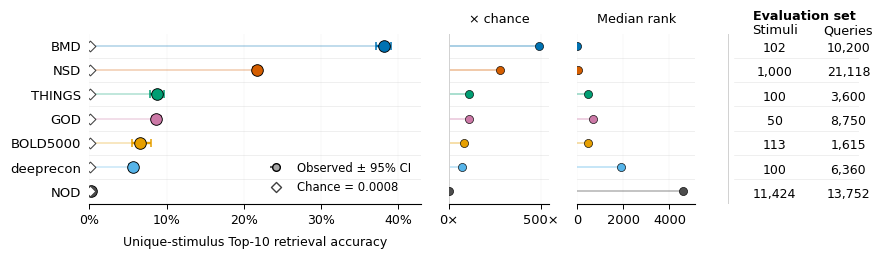

In [412]:
plot_df = plot_dataset_retrieval_dashboard(
    summary_df = dataset_global_summary,
    save_path=output_dir / "dataset_top10_retrieval_dashboard.pdf",
    figsize=(8.7, 2.5),
)

### Fig. 2b — Participant-level Top-10 retrieval (global candidate pool)
NOD is omitted from the published panel for visual clarity.

In [413]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
from matplotlib.colors import to_rgb, LinearSegmentedColormap


# ------------------------------------------------------------
# Publication style
# ------------------------------------------------------------

def set_publication_style():
    mpl.rcParams.update({
        "font.family": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 8,
        "axes.titlesize": 9,
        "axes.labelsize": 8,
        "xtick.labelsize": 6,
        "ytick.labelsize": 7,
        "legend.fontsize": 7,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 0.7,
        "xtick.major.width": 0.7,
        "ytick.major.width": 0.7,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })


DATASET_COLORS = {
    "BMD": "#0072B2",
    "NSD": "#D55E00",
    "THINGS": "#009E73",
    "GOD": "#CC79A7",
    "BOLD5000": "#E69F00",
    "deeprecon": "#56B4E9",
    "NOD": "#4D4D4D",
    "HAD": "#999933",
}


def lighten_color(color, amount=0.72):
    c = np.array(to_rgb(color))
    white = np.array([1, 1, 1])
    return tuple(c + (white - c) * amount)


def dataset_rank_colors(dataset_name, values):
    """
    Highest accuracy = darkest.
    Lowest accuracy = lightest.
    """
    base = DATASET_COLORS.get(str(dataset_name), "#666666")
    light = lighten_color(base, 0.72)

    cmap = LinearSegmentedColormap.from_list(
        f"{dataset_name}_rank_gradient",
        [light, base]
    )

    values = np.asarray(values, dtype=float)

    if len(values) == 1 or np.allclose(values.max(), values.min()):
        norm_values = np.ones_like(values)
    else:
        norm_values = (values - values.min()) / (values.max() - values.min())

    return [cmap(v) for v in norm_values]

In [414]:
from matplotlib.colors import to_rgb, LinearSegmentedColormap
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# Helpers
# ============================================================

def lighten_color(color, amount=0.70):
    c = np.array(to_rgb(color))
    return tuple(c + (1 - c) * amount)


def dataset_rank_colors(dataset_name, values):
    """
    Highest-performing subject = darkest bar.
    Lowest-performing subject = lightest bar.
    """
    base = DATASET_COLORS.get(str(dataset_name), "#666666")
    light = lighten_color(base, 0.78)

    cmap = LinearSegmentedColormap.from_list(
        f"{dataset_name}_rank_gradient",
        [light, base]
    )

    values = np.asarray(values, dtype=float)

    if len(values) == 1 or np.allclose(values.max(), values.min()):
        norm_values = np.ones_like(values)
    else:
        norm_values = (
            (values - values.min()) /
            (values.max() - values.min())
        )

    return [cmap(v) for v in norm_values]


def wilson_ci(p, n, z=1.96):
    """
    Wilson 95% confidence interval for a binomial proportion.

    Parameters
    ----------
    p : array-like
        Observed proportion, e.g. Top-10 accuracy.
    n : array-like
        Number of retrieval queries.
    z : float
        1.96 corresponds to a 95% CI.
    """
    p = np.asarray(p, dtype=float)
    n = np.asarray(n, dtype=float)

    den = 1 + z**2 / n

    center = (
        p + z**2 / (2 * n)
    ) / den

    half = (
        z
        * np.sqrt(
            p * (1 - p) / n
            + z**2 / (4 * n**2)
        )
        / den
    )

    return center - half, center + half


# ============================================================
# Subject panels:
# gradient bars + observed dots + Wilson CI + mean + chance
# ============================================================

def plot_subject_panels_fixed_bar_width(
    subject_summary_df,
    metric_col="unique_stimulus_top10",
    chance_col="chance_unique_stimulus_top10",
    n_col="n_queries",
    save_path=None,
    ylabel="Unique-stimulus Top-10 accuracy",
    max_subjects_per_dataset=None,

    # --------------------------------------------------------
    # Appearance
    # --------------------------------------------------------
    bar_width=0.84,
    bar_alpha=0.68,
    marker_size=30,

    show_value_labels=False,
    show_dataset_mean=True,
    show_chance=True,
    show_ci=True,

    # CI appearance
    ci_color="black",
    ci_linewidth=0.8,
    ci_capsize=2.0,
    ci_capthick=0.8,

    # --------------------------------------------------------
    # Physical layout
    # --------------------------------------------------------
    slot_width_in=0.30,
    panel_height_in=1.05,
    panel_gap_in=0.45,

    left_margin_in=0.85,
    right_margin_in=0.30,
    top_margin_in=0.20,
    bottom_margin_in=0.65,

    # --------------------------------------------------------
    # Fonts
    # --------------------------------------------------------
    xtick_labelsize=11,          # increased from 9 -> 13
    ytick_labelsize=10,          # increased from 10 -> 14
    dataset_label_fontsize=13,   # increased from 10 -> 13
    value_label_fontsize=9.5,

    axis_align="center",
):

    set_publication_style()

    df_all = subject_summary_df.copy()

    # ========================================================
    # Basic checks
    # ========================================================

    if metric_col not in df_all.columns:
        raise ValueError(
            f"Missing metric column: {metric_col}"
        )

    if show_ci and n_col not in df_all.columns:
        raise ValueError(
            f"Missing query-count column: {n_col}"
        )

    # ========================================================
    # Dataset ordering
    # ========================================================

    datasets = (
        df_all.groupby("dataset_name")[metric_col]
        .mean()
        .sort_values(ascending=False)
        .index
        .tolist()
    )

    # ========================================================
    # Prepare each dataset
    # ========================================================

    dataset_dfs = {}

    for dset in datasets:

        df = (
            df_all[
                df_all["dataset_name"] == dset
            ]
            .copy()
            .sort_values(
                metric_col,
                ascending=False
            )
            .reset_index(drop=True)
        )

        if max_subjects_per_dataset is not None:
            df = df.head(
                max_subjects_per_dataset
            )

        dataset_dfs[dset] = df

    # ========================================================
    # Figure geometry
    # ========================================================

    max_n_subjects = max(
        len(df)
        for df in dataset_dfs.values()
    )

    n_datasets = len(datasets)

    max_axis_width_in = (
        max_n_subjects * slot_width_in
    )

    fig_width = (
        left_margin_in
        + max_axis_width_in
        + right_margin_in
    )

    fig_height = (
        top_margin_in
        + bottom_margin_in
        + n_datasets * panel_height_in
        + (n_datasets - 1) * panel_gap_in
    )

    fig = plt.figure(
        figsize=(fig_width, fig_height)
    )

    # ========================================================
    # Shared y range
    # ========================================================

    global_max = df_all[metric_col].max()

    # Include CI upper limits when determining ylim
    if show_ci:
        all_ci_low, all_ci_high = wilson_ci(
            df_all[metric_col].to_numpy(float),
            df_all[n_col].to_numpy(float),
        )

        global_max = max(
            global_max,
            np.nanmax(all_ci_high),
        )

    ylim_max = max(
        0.01,
        global_max * 1.20
    )

    axes = []

    # ========================================================
    # Dataset panels
    # ========================================================

    for i, dset in enumerate(datasets):

        df = dataset_dfs[dset]
        n = len(df)

        axis_width_in = (
            n * slot_width_in
        )

        if axis_align == "left":

            axis_left_in = (
                left_margin_in
            )

        else:

            axis_left_in = (
                left_margin_in
                + (
                    max_axis_width_in
                    - axis_width_in
                ) / 2
            )

        axis_bottom_in = (
            fig_height
            - top_margin_in
            - (i + 1) * panel_height_in
            - i * panel_gap_in
        )

        ax = fig.add_axes([
            axis_left_in / fig_width,
            axis_bottom_in / fig_height,
            axis_width_in / fig_width,
            panel_height_in / fig_height,
        ])

        axes.append(ax)

        # ----------------------------------------------------
        # Data
        # ----------------------------------------------------

        x = np.arange(n)

        values = (
            df[metric_col]
            .to_numpy(float)
        )

        base_color = DATASET_COLORS.get(
            str(dset),
            "#666666"
        )

        bar_colors = dataset_rank_colors(
            dset,
            values
        )

        # ====================================================
        # Light gradient bars
        # ====================================================

        bars = ax.bar(
            x,
            values,
            width=bar_width,
            color=bar_colors,
            alpha=bar_alpha,
            edgecolor="black",
            linewidth=0.30,
            zorder=2,
        )

        # ====================================================
        # Wilson 95% confidence intervals
        # ====================================================

        if show_ci:

            n_queries = (
                df[n_col]
                .to_numpy(float)
            )

            ci_low, ci_high = wilson_ci(
                values,
                n_queries,
            )

            ax.errorbar(
                x,
                values,
                yerr=[
                    values - ci_low,
                    ci_high - values,
                ],
                fmt="none",
                ecolor=ci_color,
                elinewidth=ci_linewidth,
                capsize=ci_capsize,
                capthick=ci_capthick,
                zorder=4,
            )

        # ====================================================
        # Top markers
        # ====================================================

        ax.scatter(
            x,
            values,
            s=marker_size,
            facecolor=base_color,
            edgecolor="black",
            linewidth=0.55,
            zorder=5,
        )

        # Tiny white highlight inside marker
        ax.scatter(
            x,
            values,
            s=marker_size * 0.20,
            facecolor="white",
            edgecolor="none",
            alpha=0.65,
            zorder=6,
        )

        # ====================================================
        # Dataset mean
        # ====================================================

        if show_dataset_mean:

            mean_val = np.mean(values)

            ax.axhline(
                mean_val,
                color=base_color,
                linestyle=(0, (4, 2)),
                linewidth=1.0,
                alpha=0.85,
                zorder=4,
            )

        # ====================================================
        # Subject-specific chance
        # ====================================================

        if (
            show_chance
            and chance_col is not None
            and chance_col in df.columns
        ):

            chance_values = (
                df[chance_col]
                .to_numpy(float)
            )

            for xi, chance in zip(
                x,
                chance_values
            ):

                ax.hlines(
                    chance,
                    xi - bar_width * 0.36,
                    xi + bar_width * 0.36,
                    color="black",
                    linestyle=(0, (2, 1.5)),
                    linewidth=0.75,
                    alpha=0.65,
                    zorder=7,
                )

        # ====================================================
        # Optional value labels
        # ====================================================

        if show_value_labels:

            for xi, val in zip(
                x,
                values
            ):

                ax.text(
                    xi,
                    val + ylim_max * 0.035,
                    f"{val:.3f}",
                    ha="center",
                    va="bottom",
                    fontsize=value_label_fontsize,
                    color="black",
                    zorder=8,
                )

        # ====================================================
        # Dataset label
        # ====================================================

        ax.text(
            0.995,
            0.84,
            str(dset),
            transform=ax.transAxes,
            ha="right",
            va="center",
            fontsize=dataset_label_fontsize,
            color=base_color,
            fontweight="bold",
        )

        # ====================================================
        # Axis formatting
        # ====================================================

        ax.set_xlim(
            -0.5,
            n - 0.5
        )

        ax.set_ylim(
            0,
            ylim_max
        )

        ax.set_xticks(x)

        ax.set_xticklabels(
            df["subject_name"].astype(str),
            rotation=45,
            ha="right",
        )

        # X tick labels: 9 -> 13
        ax.tick_params(
            axis="x",
            labelsize=xtick_labelsize,
            pad=1,
            length=2,
        )

        # Y tick labels: 10 -> 14
        ax.tick_params(
            axis="y",
            labelsize=ytick_labelsize,
        )

        ax.grid(
            axis="y",
            linewidth=0.35,
            alpha=0.20,
            zorder=0,
        )

        ax.set_axisbelow(True)

        # Cleaner publication styling
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.set_ylabel("")

    # ========================================================
    # Shared labels
    # ========================================================

    fig.text(
        0.035,
        0.5,
        ylabel,
        va="center",
        ha="center",
        rotation="vertical",
        fontsize=12,
    )

    fig.text(
        0.5,
        0.035,
        "Subject",
        va="center",
        ha="center",
        fontsize=11,
    )

    # ========================================================
    # Save
    # ========================================================

    if save_path is not None:

        save_path = Path(save_path)

        if save_path.suffix.lower() != ".pdf":
            save_path = save_path.with_suffix(
                ".pdf"
            )

        fig.savefig(
            save_path,
            bbox_inches="tight",
            transparent=False,
        )

        print(
            f"Saved PDF: {save_path}"
        )

    plt.show()

    return axes

Saved PDF: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject/publication_subject_panels_bar_dot.pdf


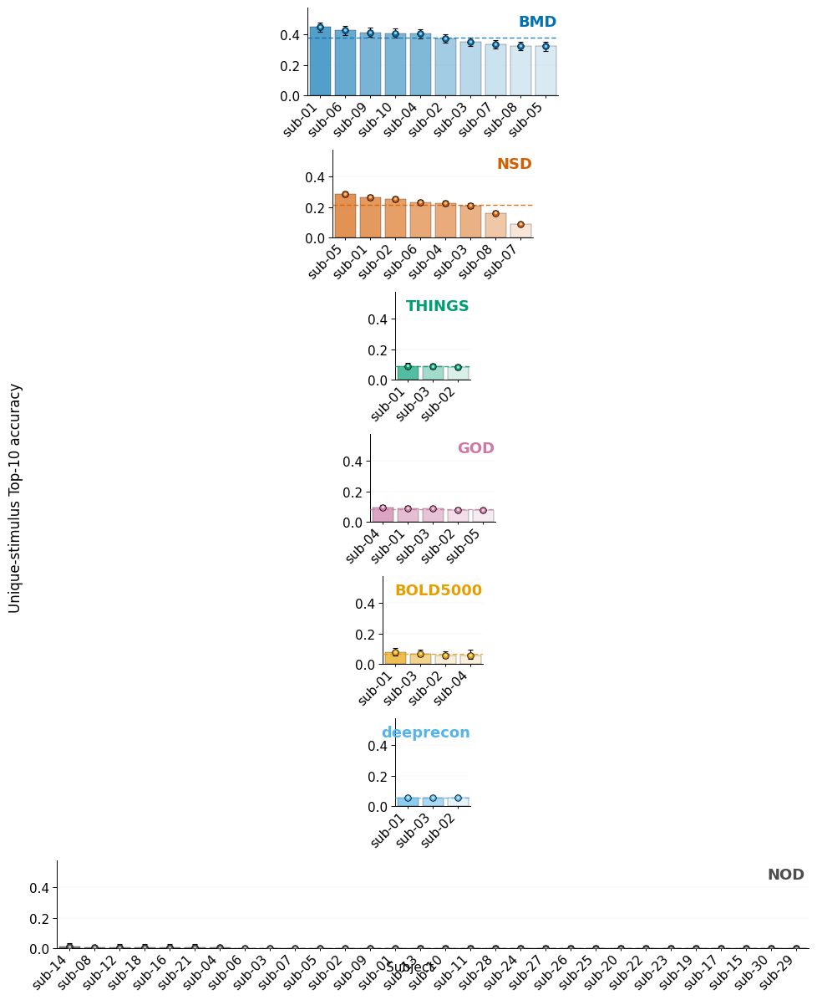

[<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >]

In [415]:
plot_subject_panels_fixed_bar_width(
    subject_summary_df=subject_global_summary,

    metric_col="unique_stimulus_top10",
    chance_col="chance_unique_stimulus_top10",
    n_col="n_queries",

    save_path=(
        output_dir /
        "publication_subject_panels_bar_dot.pdf"
    ),

    bar_width=0.84,
    bar_alpha=0.68,
    marker_size=30,

    show_value_labels=False,
    show_dataset_mean=True,
    show_chance=True,
    show_ci=True,

    slot_width_in=0.30,
    panel_height_in=1.05,
    panel_gap_in=0.65,

    # increased fonts
    xtick_labelsize=11,
    ytick_labelsize=11,
    dataset_label_fontsize=13,
    value_label_fontsize=9.5,

    axis_align="center",
)

### Fig. 2c — Participant-level retrieval within each participant's held-out set
Each query is ranked against the unique held-out stimuli of the query participant; open circles show the corresponding chance level (10 / number of candidates).

In [416]:
subject_within_retrieval_summary = subject_within_retrieval_summary.copy()

subject_within_retrieval_summary["chance_unique_stimulus_top10"] = (
    10 / subject_within_retrieval_summary["n_unique_stimuli"]
).clip(upper=1.0)

In [417]:
from matplotlib.colors import to_rgb, LinearSegmentedColormap
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# Helpers
# ============================================================

def lighten_color(color, amount=0.70):
    """
    amount=0 -> original colour
    amount=1 -> white
    """
    c = np.array(to_rgb(color))
    return tuple(c + (1 - c) * amount)


def dataset_rank_colors(dataset_name, values):
    """
    Highest-performing subject = darkest bar.
    Lowest-performing subject = lightest bar.
    """
    base = DATASET_COLORS.get(str(dataset_name), "#666666")
    light = lighten_color(base, 0.78)

    cmap = LinearSegmentedColormap.from_list(
        f"{dataset_name}_rank_gradient",
        [light, base]
    )

    values = np.asarray(values, dtype=float)

    if len(values) == 1 or np.allclose(values.max(), values.min()):
        norm_values = np.ones_like(values)
    else:
        norm_values = (
            (values - values.min()) /
            (values.max() - values.min())
        )

    return [cmap(v) for v in norm_values]


def wilson_ci(p, n, z=1.96):
    """
    Wilson 95% confidence interval for a binomial proportion.
    """
    p = np.asarray(p, dtype=float)
    n = np.asarray(n, dtype=float)

    den = 1 + z**2 / n

    center = (
        p + z**2 / (2 * n)
    ) / den

    half = (
        z
        * np.sqrt(
            p * (1 - p) / n
            + z**2 / (4 * n**2)
        )
        / den
    )

    return center - half, center + half


# ============================================================
# Within-subject retrieval
# ============================================================

def plot_within_subject_retrieval_with_chance_lollipops(
    subject_summary_df,
    metric_col="unique_stimulus_top10",
    chance_col="chance_unique_stimulus_top10",
    n_col="n_queries",
    save_path=None,
    ylabel="Within-subject Top-10 retrieval accuracy",
    max_subjects_per_dataset=None,

    # --------------------------------------------------------
    # Visual options
    # --------------------------------------------------------
    show_value_labels=False,
    show_chance_labels=False,
    show_dataset_mean=True,
    show_ci=True,

    bar_width=0.84,
    bar_alpha=0.65,

    observed_marker_size=32,
    chance_marker_size=25,
    chance_linewidth=0.8,
    chance_color="black",

    # --------------------------------------------------------
    # Physical layout
    # --------------------------------------------------------
    slot_width_in=0.30,
    panel_height_in=1.05,
    panel_gap_in=0.48,

    left_margin_in=0.90,
    right_margin_in=0.30,
    top_margin_in=0.35,
    bottom_margin_in=0.70,

    # --------------------------------------------------------
    # Fonts
    # --------------------------------------------------------
    xtick_labelsize=8,          # increased from 6
    ytick_labelsize=9,          # increased from 7
    dataset_label_fontsize=11,  # increased from 9
    value_label_fontsize=6.2,

    axis_align="center",
):
    """
    Within-subject retrieval by participant.

    Bar:
        observed Top-10 retrieval accuracy

    Filled coloured dot:
        observed Top-10 estimate

    Error bar:
        Wilson 95% CI based on n_queries

    Open circle:
        participant-specific chance level

    Vertical connector:
        distance between chance and observed performance

    Dashed horizontal line:
        dataset-average observed accuracy
    """

    set_publication_style()

    df_all = subject_summary_df.copy()

    # ========================================================
    # Checks / chance calculation
    # ========================================================

    if metric_col not in df_all.columns:
        raise ValueError(
            f"Missing metric column: {metric_col}"
        )

    if show_ci and n_col not in df_all.columns:
        raise ValueError(
            f"Missing query-count column: {n_col}"
        )

    if chance_col not in df_all.columns:

        if "n_unique_stimuli" not in df_all.columns:
            raise ValueError(
                f"Missing '{chance_col}', and "
                "'n_unique_stimuli' is unavailable "
                "to calculate chance."
            )

        df_all[chance_col] = (
            10 / df_all["n_unique_stimuli"]
        ).clip(upper=1.0)

    # ========================================================
    # Dataset order
    # ========================================================

    datasets = (
        df_all
        .groupby("dataset_name")[metric_col]
        .mean()
        .sort_values(ascending=False)
        .index
        .tolist()
    )

    dataset_dfs = {}

    for dset in datasets:

        df = (
            df_all[
                df_all["dataset_name"] == dset
            ]
            .copy()
            .sort_values(
                metric_col,
                ascending=False
            )
            .reset_index(drop=True)
        )

        if max_subjects_per_dataset is not None:
            df = df.head(
                max_subjects_per_dataset
            )

        dataset_dfs[dset] = df

    # ========================================================
    # Figure geometry
    # ========================================================

    max_n_subjects = max(
        len(df)
        for df in dataset_dfs.values()
    )

    n_datasets = len(datasets)

    max_axis_width_in = (
        max_n_subjects * slot_width_in
    )

    fig_width = (
        left_margin_in
        + max_axis_width_in
        + right_margin_in
    )

    fig_height = (
        top_margin_in
        + bottom_margin_in
        + n_datasets * panel_height_in
        + (n_datasets - 1) * panel_gap_in
    )

    fig = plt.figure(
        figsize=(fig_width, fig_height)
    )

    global_max = max(
        df_all[metric_col].max(),
        df_all[chance_col].max(),
    )

    ylim_max = max(
        0.01,
        global_max * 1.20
    )

    first_ax = None
    axes = []

    # ========================================================
    # Dataset panels
    # ========================================================

    for i, dset in enumerate(datasets):

        df = dataset_dfs[dset]

        n_subjects = len(df)

        axis_width_in = (
            n_subjects * slot_width_in
        )

        if axis_align == "left":

            axis_left_in = left_margin_in

        else:

            axis_left_in = (
                left_margin_in
                + (
                    max_axis_width_in
                    - axis_width_in
                ) / 2
            )

        axis_bottom_in = (
            fig_height
            - top_margin_in
            - (i + 1) * panel_height_in
            - i * panel_gap_in
        )

        ax = fig.add_axes([
            axis_left_in / fig_width,
            axis_bottom_in / fig_height,
            axis_width_in / fig_width,
            panel_height_in / fig_height,
        ])

        axes.append(ax)

        if first_ax is None:
            first_ax = ax

        # ----------------------------------------------------
        # Data
        # ----------------------------------------------------

        x = np.arange(n_subjects)

        values = (
            df[metric_col]
            .to_numpy(float)
        )

        chances = (
            df[chance_col]
            .to_numpy(float)
        )

        base_color = DATASET_COLORS.get(
            str(dset),
            "#666666",
        )

        bar_colors = dataset_rank_colors(
            dset,
            values,
        )

        # ====================================================
        # Gradient bars
        # ====================================================

        bars = ax.bar(
            x,
            values,
            color=bar_colors,
            alpha=bar_alpha,
            edgecolor="black",
            linewidth=0.30,
            width=bar_width,
            zorder=2,
        )

        # ====================================================
        # Wilson 95% confidence intervals
        # ====================================================

        if show_ci:

            nq = (
                df[n_col]
                .to_numpy(float)
            )

            ci_low, ci_high = wilson_ci(
                values,
                nq,
            )

            ax.errorbar(
                x,
                values,
                yerr=[
                    values - ci_low,
                    ci_high - values,
                ],
                fmt="none",
                ecolor="black",
                elinewidth=0.8,
                capsize=2.0,
                capthick=0.8,
                zorder=4,
            )

        # ====================================================
        # Chance -> observed lollipops
        # ====================================================

        for j, (xi, val, ch) in enumerate(
            zip(x, values, chances)
        ):

            # vertical connector
            ax.vlines(
                xi,
                min(ch, val),
                max(ch, val),
                color=chance_color,
                linewidth=chance_linewidth,
                alpha=0.65,
                zorder=3,
            )

            # chance marker
            ax.scatter(
                xi,
                ch,
                s=chance_marker_size,
                marker="o",
                facecolor="white",
                edgecolor=chance_color,
                linewidth=0.85,
                zorder=5,
                label=(
                    "Subject-specific chance"
                    if i == 0 and j == 0
                    else None
                ),
            )

            if show_chance_labels:

                ax.text(
                    xi,
                    ch - ylim_max * 0.035,
                    f"{100 * ch:.1f}%",
                    ha="center",
                    va="top",
                    fontsize=value_label_fontsize,
                    color=chance_color,
                    zorder=7,
                )

        # ====================================================
        # Observed dots
        # ====================================================

        ax.scatter(
            x,
            values,
            s=observed_marker_size,
            facecolor=base_color,
            edgecolor="black",
            linewidth=0.55,
            zorder=6,
            label=(
                "Observed accuracy"
                if i == 0
                else None
            ),
        )

        # tiny highlight
        ax.scatter(
            x,
            values,
            s=observed_marker_size * 0.18,
            facecolor="white",
            edgecolor="none",
            alpha=0.65,
            zorder=7,
        )

        # ====================================================
        # Dataset mean
        # ====================================================

        if show_dataset_mean:

            mean_val = np.mean(values)

            ax.axhline(
                mean_val,
                color=base_color,
                linestyle=(0, (4, 2)),
                linewidth=1.0,
                alpha=0.85,
                zorder=4,
            )

        # ====================================================
        # Optional value labels
        # ====================================================

        if show_value_labels:

            for xi, val in zip(
                x,
                values
            ):

                ax.text(
                    xi,
                    val + ylim_max * 0.040,
                    f"{100 * val:.1f}%",
                    ha="center",
                    va="bottom",
                    fontsize=value_label_fontsize,
                    color="black",
                    zorder=8,
                )

        # ====================================================
        # Dataset label
        # ====================================================

        ax.text(
            0.995,
            0.84,
            str(dset),
            transform=ax.transAxes,
            ha="right",
            va="center",

            # increased from 9 -> 11
            fontsize=dataset_label_fontsize,

            color=base_color,
            fontweight="bold",
        )

        # ====================================================
        # Axis formatting
        # ====================================================

        ax.set_xlim(
            -0.5,
            n_subjects - 0.5,
        )

        ax.set_ylim(
            0,
            ylim_max,
        )

        ax.set_xticks(x)

        ax.set_xticklabels(
            df["subject_name"].astype(str),
            rotation=45,
            ha="right",
        )

        # ----------------------------------------------------
        # Larger X tick labels: 6 -> 8
        # ----------------------------------------------------
        ax.tick_params(
            axis="x",
            labelsize=xtick_labelsize,
            pad=1,
            length=2,
        )

        # ----------------------------------------------------
        # Larger Y tick labels: 7 -> 9
        # ----------------------------------------------------
        ax.tick_params(
            axis="y",
            labelsize=ytick_labelsize,
        )

        ax.grid(
            axis="y",
            linestyle="-",
            linewidth=0.35,
            alpha=0.20,
            zorder=0,
        )

        ax.set_axisbelow(True)

        # cleaner publication styling
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.set_ylabel("")

    # ========================================================
    # Shared labels
    # ========================================================

    # Same as your original plot
    fig.text(
        0.035,
        0.5,
        ylabel,
        va="center",
        ha="center",
        rotation="vertical",
        fontsize=8.5,
    )

    # Same as your original plot
    fig.text(
        0.5,
        0.035,
        "Subject",
        va="center",
        ha="center",
        fontsize=8,
    )

    # ========================================================
    # Legend
    # ========================================================

    handles, labels = (
        first_ax.get_legend_handles_labels()
    )

    if handles:

        fig.legend(
            handles,
            labels,
            loc="upper center",
            bbox_to_anchor=(0.5, 0.995),
            frameon=False,
            ncol=2,

            # same as original
            fontsize=7,
        )

    # ========================================================
    # Save
    # ========================================================

    if save_path is not None:

        save_path = Path(save_path)

        if save_path.suffix.lower() != ".pdf":
            save_path = save_path.with_suffix(
                ".pdf"
            )

        fig.savefig(
            save_path,
            bbox_inches="tight",
            transparent=False,
        )

        print(
            f"Saved PDF: {save_path}"
        )

    plt.show()

    return axes

Saved PDF: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject/within_subject_retrieval_top10_with_chance_lollipops.pdf


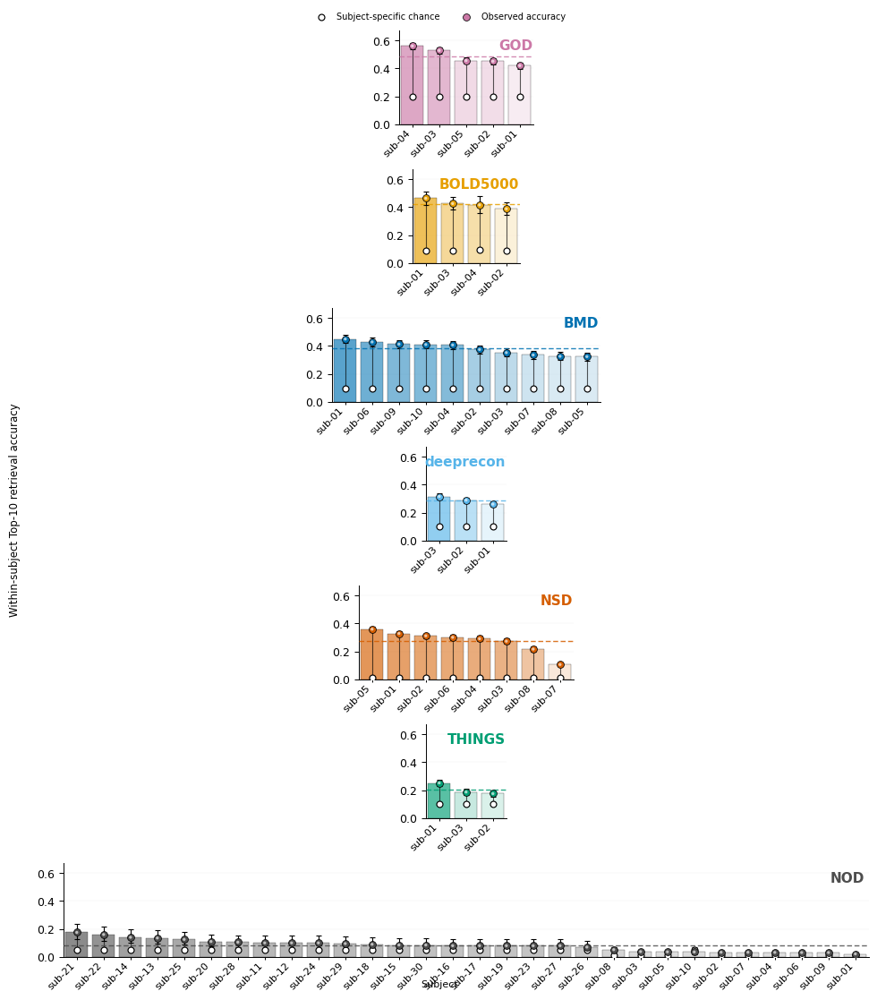

[<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >]

In [418]:
plot_within_subject_retrieval_with_chance_lollipops(
    subject_summary_df=subject_within_retrieval_summary,

    metric_col="unique_stimulus_top10",
    chance_col="chance_unique_stimulus_top10",
    n_col="n_queries",

    save_path=(
        output_dir /
        "within_subject_retrieval_top10_with_chance_lollipops.pdf"
    ),

    show_value_labels=False,
    show_chance_labels=False,

    show_dataset_mean=True,
    show_ci=True,

    bar_width=0.84,
    bar_alpha=0.65,

    observed_marker_size=32,
    chance_marker_size=25,

    slot_width_in=0.30,
    panel_height_in=1.05,
    panel_gap_in=0.50,

    # Increased fonts
    xtick_labelsize=8,
    ytick_labelsize=9,
    dataset_label_fontsize=11,

    axis_align="center",
)

### Fig. 2d — Retrieval examples
Each row ranks one query against all unique held-out stimuli of its dataset. The seven example queries shown in the paper are listed explicitly below. BMD clips are shown by a representative frame.

In [419]:
# [load embeddings for the examples]
# ============================================================
# Reload saved baseline retrieval embeddings and metadata
# ============================================================

import torch
import numpy as np
import pandas as pd


def get_first_existing_key(dictionary, possible_keys):
    for key in possible_keys:
        if key in dictionary:
            return dictionary[key], key

    raise KeyError(
        f"None of these keys were found: {possible_keys}\n"
        f"Available keys: {list(dictionary.keys())}"
    )


# PyTorch 2.6+ may require weights_only=False for dictionaries
saved_embeddings = torch.load(
    EMBEDDING_FILE,
    map_location="cpu",
    weights_only=False,
)

if not isinstance(saved_embeddings, dict):
    raise TypeError(
        "Expected retrieval_embeddings.pt to contain a dictionary, "
        f"but found {type(saved_embeddings)}."
    )

print("Saved embedding keys:")
print(list(saved_embeddings.keys()))


baseline_brain, brain_key = get_first_existing_key(
    saved_embeddings,
    [
        "brain_embeddings",
        "brain",
        "baseline_brain",
    ],
)

baseline_clip, clip_key = get_first_existing_key(
    saved_embeddings,
    [
        "clip_embeddings",
        "clip",
        "baseline_clip",
    ],
)

baseline_stimulus_ids, stimulus_key = get_first_existing_key(
    saved_embeddings,
    [
        "stimulus_ids",
        "baseline_stimulus_ids",
    ],
)

baseline_real_indices = saved_embeddings.get(
    "real_indices",
    saved_embeddings.get(
        "baseline_real_indices",
        None,
    ),
)


# ------------------------------------------------------------
# Find metadata saved beside retrieval_embeddings.pt
# ------------------------------------------------------------

retrieval_directory = EMBEDDING_FILE.parent

metadata_candidates = [
    retrieval_directory / "metadata.csv",
    retrieval_directory / "retrieval_metadata.csv",
    retrieval_directory / "baseline_metadata.csv",
    retrieval_directory / "metadata.parquet",
    retrieval_directory / "retrieval_metadata.parquet",
]

METADATA_FILE = next(
    (
        path
        for path in metadata_candidates
        if path.exists()
    ),
    None,
)

if METADATA_FILE is None:
    # Search the same directory more broadly
    nearby_metadata = (
        list(retrieval_directory.glob("*metadata*.csv"))
        + list(retrieval_directory.glob("*metadata*.parquet"))
    )

    if not nearby_metadata:
        raise FileNotFoundError(
            "Could not find the metadata file beside:\n"
            f"{EMBEDDING_FILE}"
        )

    print("Nearby metadata candidates:")
    for i, path in enumerate(nearby_metadata):
        print(f"[{i}] {path}")

    METADATA_FILE = nearby_metadata[0]


if METADATA_FILE.suffix.lower() == ".parquet":
    baseline_metadata_df = pd.read_parquet(
        METADATA_FILE
    )
else:
    baseline_metadata_df = pd.read_csv(
        METADATA_FILE
    )

baseline_metadata_df = baseline_metadata_df.reset_index(
    drop=True
)


print("\nLoaded:")
print(f"  brain key:       {brain_key}")
print(f"  CLIP key:        {clip_key}")
print(f"  stimulus key:    {stimulus_key}")
print(f"  metadata file:   {METADATA_FILE}")
print(f"  brain shape:     {tuple(baseline_brain.shape)}")
print(f"  CLIP shape:      {tuple(baseline_clip.shape)}")
print(f"  stimulus IDs:    {len(baseline_stimulus_ids)}")
print(f"  metadata rows:   {len(baseline_metadata_df)}")

Saved embedding keys:
['brain_embeddings', 'clip_embeddings', 'stimulus_ids', 'real_indices']

Loaded:
  brain key:       brain_embeddings
  CLIP key:        clip_embeddings
  stimulus key:    stimulus_ids
  metadata file:   /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject/retrieval_metadata.csv
  brain shape:     (65395, 512)
  CLIP shape:      (65395, 512)
  stimulus IDs:    65395
  metadata rows:   65395


In [420]:
# ============================================================
# QUALITATIVE WITHIN-DATASET RETRIEVAL VISUALIZATION
#
# Image-only datasets:
#   NSD sub05
#   THINGS sub01
#   GOD sub04
#   BOLD5000 sub01
#   deeprecon sub03
#   NOD sub21
#
# Candidate pool:
#   All unique stimuli from the same dataset as the query,
#   across all subjects in that dataset.
# ============================================================

from pathlib import Path
import ast
import re
import textwrap
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps, ImageDraw
from matplotlib.backends.backend_pdf import PdfPages


# ============================================================
# 1. Configuration
# ============================================================

SELECTED_SUBJECTS = [
    ("NSD", "sub05"),
    ("THINGS", "sub02"),
    ("GOD", "sub04"),
    ("BOLD5000", "sub01"),
    ("deeprecon", "sub03"),
    ("NOD", "sub21"),
]

# Representative-example selection:
#
# "median_success":
#     Select a typical successful Top-10 query.
#     Falls back to the median query if no Top-10 success exists.
#
# "median":
#     Select the query with true rank closest to the subject median.
#
# "best":
#     Select the query with the best true-stimulus rank.
#
# "worst":
#     Select the query with the worst true-stimulus rank.
#
# "random":
#     Select a deterministic random query.
# EXAMPLE_MODE = "median_success"
EXAMPLE_MODE = "rank"
TARGET_RANK = 2

TOP_K = 10
MAX_QUERIES_FOR_SELECTION = 300
RANDOM_SEED = 122

SHOW_FILENAMES = True
SAVE_INDIVIDUAL_PDFS = True
SAVE_COMBINED_PDF = True


# Output directory
qualitative_out = (
    Path(output_dir)
    / "qualitative_within_dataset_retrieval_image_only"
)

qualitative_out.mkdir(
    parents=True,
    exist_ok=True,
)

print("Output directory:", qualitative_out)


# ============================================================
# 2. Basic helpers
# ============================================================

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp",
    ".jfif",
}


def to_numpy_safe(x):
    if hasattr(x, "detach"):
        return x.detach().cpu().numpy()

    if hasattr(x, "cpu"):
        return x.cpu().numpy()

    return np.asarray(x)


def normalize_identifier(value):
    """
    Normalize dataset and subject labels so variants such as
    sub-01, sub_01 and sub01 match.
    """
    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(value).lower(),
    )


def normalize_dataset_name(value):
    value = normalize_identifier(value)

    aliases = {
        "bold": "bold5000",
        "bold5000": "bold5000",
        "thingsfmri": "things",
        "things": "things",
        "deepreconstruction": "deeprecon",
        "deeprecon": "deeprecon",
        "genericobjectdecoding": "god",
        "god": "god",
        "naturalobjectdataset": "nod",
        "nod": "nod",
        "naturalscenesdataset": "nsd",
        "nsd": "nsd",
    }

    return aliases.get(value, value)


def safe_filename(value):
    value = str(value)

    value = re.sub(
        r"[^A-Za-z0-9._-]+",
        "_",
        value,
    )

    return value.strip("_")


def _to_list(value):
    """
    Convert canonical_meta fields such as all_file_paths into
    a Python list.
    """
    if value is None:
        return []

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, (list, tuple, set)):
        return list(value)

    if isinstance(value, str):
        value = value.strip()

        if not value:
            return []

        try:
            parsed = ast.literal_eval(value)

            if isinstance(parsed, (list, tuple, set)):
                return list(parsed)

        except Exception:
            pass

        return [value]

    if pd.isna(value):
        return []

    return [value]


# ============================================================
# 3. Prepare embeddings and metadata
# ============================================================

brain_embeddings = (
    to_numpy_safe(baseline_brain)
    .astype(np.float32)
)

clip_embeddings = (
    to_numpy_safe(baseline_clip)
    .astype(np.float32)
)

retrieval_metadata = (
    baseline_metadata_df
    .copy()
    .reset_index(drop=True)
)


required_metadata_columns = [
    "dataset_name",
    "subject_name",
    "stimulus_clean",
]

missing_columns = [
    column
    for column in required_metadata_columns
    if column not in retrieval_metadata.columns
]

if missing_columns:
    raise KeyError(
        "baseline_metadata_df is missing required columns: "
        f"{missing_columns}"
    )


if len(brain_embeddings) != len(retrieval_metadata):
    raise RuntimeError(
        f"Brain embedding rows: {len(brain_embeddings)}\n"
        f"Metadata rows: {len(retrieval_metadata)}"
    )

if len(clip_embeddings) != len(retrieval_metadata):
    raise RuntimeError(
        f"CLIP embedding rows: {len(clip_embeddings)}\n"
        f"Metadata rows: {len(retrieval_metadata)}"
    )


# Normalize embeddings for cosine similarity
brain_embeddings = (
    brain_embeddings
    / (
        np.linalg.norm(
            brain_embeddings,
            axis=1,
            keepdims=True,
        )
        + 1e-12
    )
)

clip_embeddings = (
    clip_embeddings
    / (
        np.linalg.norm(
            clip_embeddings,
            axis=1,
            keepdims=True,
        )
        + 1e-12
    )
)


retrieval_metadata["dataset_normalized"] = (
    retrieval_metadata["dataset_name"]
    .map(normalize_dataset_name)
)

retrieval_metadata["subject_normalized"] = (
    retrieval_metadata["subject_name"]
    .map(normalize_identifier)
)

retrieval_metadata["stimulus_clean"] = (
    retrieval_metadata["stimulus_clean"]
    .astype(str)
)


print("Metadata columns:")
print(retrieval_metadata.columns.tolist())

print("\nDataset counts:")
display(
    retrieval_metadata["dataset_name"]
    .value_counts()
    .rename_axis("dataset")
    .reset_index(name="n_rows")
)


# ============================================================
# 4. Confirm selected subjects exist
# ============================================================

def find_subject_indices(
    metadata_df,
    dataset_name,
    subject_name,
):
    dataset_target = normalize_dataset_name(
        dataset_name
    )

    subject_target = normalize_identifier(
        subject_name
    )

    mask = (
        metadata_df["dataset_normalized"].eq(
            dataset_target
        )
        & metadata_df["subject_normalized"].eq(
            subject_target
        )
    )

    indices = np.flatnonzero(
        mask.to_numpy()
    )

    if len(indices) == 0:
        available_subjects = (
            metadata_df.loc[
                metadata_df["dataset_normalized"].eq(
                    dataset_target
                ),
                "subject_name",
            ]
            .dropna()
            .astype(str)
            .unique()
            .tolist()
        )

        raise ValueError(
            f"No rows found for {dataset_name}/{subject_name}.\n"
            f"Available subjects: {available_subjects[:30]}"
        )

    return indices


print("Selected-subject availability:\n")

for dataset_name, subject_name in SELECTED_SUBJECTS:
    indices = find_subject_indices(
        retrieval_metadata,
        dataset_name,
        subject_name,
    )

    print(
        f"{dataset_name:12s} {subject_name:8s}: "
        f"{len(indices):,} query rows"
    )


# ============================================================
# 5. Resolve image paths through canonical_meta
# ============================================================

if globals().get("canonical_meta") is None:
    raise NameError(
        "canonical_meta is not available. Load canonical_meta "
        "before running this section."
    )


canonical_meta_visual = (
    canonical_meta
    .copy()
    .reset_index(drop=True)
)


# Identify canonical stimulus key
if "clean" in canonical_meta_visual.columns:
    CANONICAL_CLEAN_COL = "clean"

elif "stimulus_clean" in canonical_meta_visual.columns:
    CANONICAL_CLEAN_COL = "stimulus_clean"

else:
    raise KeyError(
        "canonical_meta must contain either 'clean' "
        "or 'stimulus_clean'."
    )


# Identify optional canonical dataset column
CANONICAL_DATASET_CANDIDATES = [
    "dataset_name",
    "dataset",
    "dataset_tag",
    "tag",
    "source_dataset",
]

CANONICAL_DATASET_COL = next(
    (
        column
        for column in CANONICAL_DATASET_CANDIDATES
        if column in canonical_meta_visual.columns
    ),
    None,
)


canonical_meta_visual[
    CANONICAL_CLEAN_COL
] = (
    canonical_meta_visual[
        CANONICAL_CLEAN_COL
    ]
    .astype(str)
)


if CANONICAL_DATASET_COL is not None:
    canonical_meta_visual[
        "_dataset_normalized"
    ] = (
        canonical_meta_visual[
            CANONICAL_DATASET_COL
        ]
        .map(normalize_dataset_name)
    )

print("Canonical stimulus key:", CANONICAL_CLEAN_COL)
print("Canonical dataset column:", CANONICAL_DATASET_COL)


# Candidate path columns, in preferred order
PATH_COLUMNS_IN_PRIORITY = [
    "all_file_paths",
    "file_path",
    "filepath",
    "stimulus_path",
    "image_path",
    "path",
    "filename",
    "all_filenames",
]

available_path_columns = [
    column
    for column in PATH_COLUMNS_IN_PRIORITY
    if column in canonical_meta_visual.columns
]

if not available_path_columns:
    raise KeyError(
        "No usable path columns were found in canonical_meta.\n"
        f"Available columns: {canonical_meta_visual.columns.tolist()}"
    )

print("Canonical path columns:", available_path_columns)


# ============================================================
# 6. Path roots and old-mount rewrites
# ============================================================

DATA_FOLDER = Path(
    CONFIG["data_folder"]
).expanduser().resolve()


SEARCH_ROOTS = [
    DATA_FOLDER,
    DATA_FOLDER.parent,
    Path("/mount/share/moein"),
    Path(str(MOSAIC_ROOT) + ""),
    Path(str(MOSAIC_ROOT) + "/stimuli"),
]


# Paths may have been saved under old mount points
PATH_PREFIX_REWRITES = [
    (
        "/srv/nfs-data/sisko/michelangelo",
        "/mount/share/moein",
    ),
    (
        "/srv/nfs-data/sisko/storage",
        str(MOSAIC_ROOT) + "/stimuli",
    ),
]


_path_resolution_cache = {}
_basename_search_cache = {}


def resolve_image_path(path_like):
    """
    Resolve an image path stored in canonical_meta.

    Video files are intentionally excluded.
    """
    if path_like is None:
        return None

    raw_path = str(path_like).strip()

    if not raw_path:
        return None

    if raw_path in _path_resolution_cache:
        return _path_resolution_cache[
            raw_path
        ]

    original_path = Path(
        raw_path
    ).expanduser()

    candidates = []

    # Original absolute path
    if original_path.is_absolute():
        candidates.append(
            original_path
        )

        # Rewrite old mount locations
        for old_prefix, new_prefix in PATH_PREFIX_REWRITES:
            if raw_path.startswith(old_prefix):
                rewritten = raw_path.replace(
                    old_prefix,
                    new_prefix,
                    1,
                )

                candidates.append(
                    Path(rewritten)
                )

    else:
        # Relative paths
        for root in SEARCH_ROOTS:
            candidates.append(
                root / original_path
            )

    # Try basename directly under roots
    basename = original_path.name

    for root in SEARCH_ROOTS:
        candidates.append(
            root / basename
        )

    # Check direct candidates
    seen = set()

    for candidate in candidates:
        try:
            candidate = (
                candidate
                .expanduser()
                .resolve()
            )
        except Exception:
            continue

        candidate_string = str(
            candidate
        )

        if candidate_string in seen:
            continue

        seen.add(candidate_string)

        if (
            candidate.exists()
            and candidate.is_file()
            and candidate.suffix.lower()
            in IMAGE_EXTENSIONS
        ):
            _path_resolution_cache[
                raw_path
            ] = candidate

            return candidate

    # Slower recursive basename search
    if basename:
        for root in SEARCH_ROOTS:
            root = Path(root)

            if not root.exists():
                continue

            cache_key = (
                str(root),
                basename,
            )

            if cache_key in _basename_search_cache:
                found = _basename_search_cache[
                    cache_key
                ]

                if found is not None:
                    _path_resolution_cache[
                        raw_path
                    ] = found

                return found

            try:
                matches = [
                    match
                    for match in root.rglob(
                        basename
                    )
                    if (
                        match.is_file()
                        and match.suffix.lower()
                        in IMAGE_EXTENSIONS
                    )
                ]

            except Exception:
                matches = []

            found = (
                matches[0]
                if matches
                else None
            )

            _basename_search_cache[
                cache_key
            ] = found

            if found is not None:
                _path_resolution_cache[
                    raw_path
                ] = found

                return found

    _path_resolution_cache[
        raw_path
    ] = None

    return None


# ============================================================
# 7. Build dataset + stimulus → image path mapping
# ============================================================

selected_dataset_normalized = {
    normalize_dataset_name(dataset)
    for dataset, _ in SELECTED_SUBJECTS
}

needed_metadata = retrieval_metadata[
    retrieval_metadata[
        "dataset_normalized"
    ].isin(
        selected_dataset_normalized
    )
].copy()


needed_pairs = (
    needed_metadata[
        [
            "dataset_normalized",
            "stimulus_clean",
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print(
    "Unique dataset/stimulus pairs needed:",
    len(needed_pairs),
)


def get_possible_paths_from_row(
    row,
    path_columns,
):
    possible_paths = []

    for column in path_columns:
        if column not in row.index:
            continue

        possible_paths.extend(
            _to_list(
                row[column]
            )
        )

    # Preserve order while removing duplicates
    output = []
    seen = set()

    for path_value in possible_paths:
        path_string = str(
            path_value
        ).strip()

        if (
            not path_string
            or path_string in seen
        ):
            continue

        seen.add(
            path_string
        )

        output.append(
            path_string
        )

    return output


def build_dataset_clean_to_image_path(
    canonical_df,
    needed_pairs_df,
    clean_col,
    path_columns,
    dataset_col=None,
):
    """
    Create:
        (normalized dataset, stimulus_clean) -> image path

    If canonical_meta has no dataset column, matching falls
    back to stimulus_clean alone.
    """
    mapping = {}

    # Index canonical rows by clean key
    rows_by_clean = {}

    for row_index, clean in enumerate(
        canonical_df[clean_col].astype(str)
    ):
        rows_by_clean.setdefault(
            clean,
            [],
        ).append(row_index)

    total = len(needed_pairs_df)

    for pair_number, pair in needed_pairs_df.iterrows():
        dataset_normalized = str(
            pair["dataset_normalized"]
        )

        clean = str(
            pair["stimulus_clean"]
        )

        candidate_row_indices = rows_by_clean.get(
            clean,
            [],
        )

        # Prefer canonical rows from the matching dataset
        if (
            dataset_col is not None
            and candidate_row_indices
        ):
            matching_dataset_rows = [
                row_index
                for row_index
                in candidate_row_indices
                if (
                    str(
                        canonical_df.iloc[
                            row_index
                        ][
                            "_dataset_normalized"
                        ]
                    )
                    == dataset_normalized
                )
            ]

            if matching_dataset_rows:
                candidate_row_indices = (
                    matching_dataset_rows
                )

        resolved_path = None

        for row_index in candidate_row_indices:
            canonical_row = canonical_df.iloc[
                row_index
            ]

            possible_paths = (
                get_possible_paths_from_row(
                    canonical_row,
                    path_columns,
                )
            )

            for possible_path in possible_paths:
                resolved_path = resolve_image_path(
                    possible_path
                )

                if resolved_path is not None:
                    break

            if resolved_path is not None:
                break

        mapping[
            (
                dataset_normalized,
                clean,
            )
        ] = resolved_path

        if (
            (pair_number + 1) % 1000 == 0
            or pair_number + 1 == total
        ):
            print(
                f"Resolved {pair_number + 1:,} "
                f"of {total:,} stimulus keys"
            )

    return mapping


dataset_clean_to_image_path = (
    build_dataset_clean_to_image_path(
        canonical_df=canonical_meta_visual,
        needed_pairs_df=needed_pairs,
        clean_col=CANONICAL_CLEAN_COL,
        path_columns=available_path_columns,
        dataset_col=CANONICAL_DATASET_COL,
    )
)


resolved_count = sum(
    path is not None
    for path
    in dataset_clean_to_image_path.values()
)

resolution_rate = (
    resolved_count
    / max(
        len(dataset_clean_to_image_path),
        1,
    )
    * 100
)

print("\nImage-path resolution summary")
print("--------------------------------")
print(
    f"Required image keys: "
    f"{len(dataset_clean_to_image_path):,}"
)
print(
    f"Resolved image paths: "
    f"{resolved_count:,}"
)
print(
    f"Resolution rate: "
    f"{resolution_rate:.1f}%"
)


# Dataset-specific diagnostics
resolution_rows = []

for dataset_normalized in sorted(
    selected_dataset_normalized
):
    keys = [
        key
        for key
        in dataset_clean_to_image_path
        if key[0] == dataset_normalized
    ]

    found = sum(
        dataset_clean_to_image_path[
            key
        ] is not None
        for key in keys
    )

    resolution_rows.append({
        "dataset": dataset_normalized,
        "n_required": len(keys),
        "n_resolved": found,
        "resolution_percent": (
            100 * found / max(len(keys), 1)
        ),
    })

resolution_df = pd.DataFrame(
    resolution_rows
)

display(
    resolution_df.round(1)
)


# Show a few unresolved keys
unresolved_examples = [
    key
    for key, path
    in dataset_clean_to_image_path.items()
    if path is None
][:25]

print("\nExample unresolved keys:")
for key in unresolved_examples:
    print(key)


# ============================================================
# 8. Image loading
# ============================================================

_image_cache = {}


def make_missing_image(
    dataset_name,
    clean,
    size=(512, 512),
):
    """
    Create a diagnostic placeholder only when the real image
    cannot be resolved.
    """
    image = Image.new(
        "RGB",
        size,
        color=(244, 244, 244),
    )

    draw = ImageDraw.Draw(
        image
    )

    clean_wrapped = "\n".join(
        textwrap.wrap(
            str(clean),
            width=45,
        )
    )

    message = (
        "IMAGE NOT FOUND\n\n"
        f"Dataset: {dataset_name}\n\n"
        f"{clean_wrapped}"
    )

    draw.multiline_text(
        (
            size[0] / 2,
            size[1] / 2,
        ),
        message,
        fill=(70, 70, 70),
        anchor="mm",
        align="center",
        spacing=7,
    )

    return image


def load_image_from_path(path):
    if path is None:
        return None

    path = Path(path)
    cache_key = str(path)

    if cache_key in _image_cache:
        return _image_cache[
            cache_key
        ].copy()

    try:
        image = (
            Image.open(path)
            .convert("RGB")
        )

        image = ImageOps.exif_transpose(
            image
        )

        _image_cache[
            cache_key
        ] = image.copy()

        return image

    except Exception as error:
        warnings.warn(
            f"Could not open image:\n"
            f"{path}\n"
            f"{error}"
        )

        return None


def get_image_path(
    dataset_name,
    stimulus_clean,
):
    key = (
        normalize_dataset_name(
            dataset_name
        ),
        str(stimulus_clean),
    )

    return dataset_clean_to_image_path.get(
        key
    )


def load_image_for_stimulus(
    dataset_name,
    stimulus_clean,
):
    path = get_image_path(
        dataset_name,
        stimulus_clean,
    )

    image = load_image_from_path(
        path
    )

    if image is None:
        image = make_missing_image(
            dataset_name=dataset_name,
            clean=stimulus_clean,
        )

    return image, path


def load_image_from_metadata_row(row):
    return load_image_for_stimulus(
        dataset_name=row["dataset_name"],
        stimulus_clean=row["stimulus_clean"],
    )

Output directory: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject/qualitative_within_dataset_retrieval_image_only
Metadata columns:
['real_idx', 'stimulus_id', 'stimulus_clean', 'raw_name', 'dataset_name', 'subject_name', 'subject_key', 'dataset_normalized', 'subject_normalized']

Dataset counts:


,dataset,n_rows
0,NSD,21118
1,NOD,13752
2,BMD,10200
3,GOD,8750
4,deeprecon,6360
5,THINGS,3600
6,BOLD5000,1615


Selected-subject availability:

NSD          sub05   : 3,000 query rows
THINGS       sub02   : 1,200 query rows
GOD          sub04   : 1,750 query rows
BOLD5000     sub01   : 451 query rows
deeprecon    sub03   : 2,120 query rows
NOD          sub21   : 200 query rows
Canonical stimulus key: clean
Canonical dataset column: None
Canonical path columns: ['all_file_paths', 'filename', 'all_filenames']
Unique dataset/stimulus pairs needed: 12787
Resolved 1,000 of 12,787 stimulus keys
Resolved 2,000 of 12,787 stimulus keys
Resolved 3,000 of 12,787 stimulus keys
Resolved 4,000 of 12,787 stimulus keys
Resolved 5,000 of 12,787 stimulus keys
Resolved 6,000 of 12,787 stimulus keys
Resolved 7,000 of 12,787 stimulus keys
Resolved 8,000 of 12,787 stimulus keys
Resolved 9,000 of 12,787 stimulus keys
Resolved 10,000 of 12,787 stimulus keys
Resolved 11,000 of 12,787 stimulus keys
Resolved 12,000 of 12,787 stimulus keys
Resolved 12,787 of 12,787 stimulus keys

Image-path resolution summary
-------------

,dataset,n_required,n_resolved,resolution_percent
0,bold5000,113,113,100.0
1,deeprecon,100,100,100.0
2,god,50,50,100.0
3,nod,11424,11424,100.0
4,nsd,1000,1000,100.0
5,things,100,100,100.0



Example unresolved keys:


In [421]:
import matplotlib as mpl

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans"],
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})
RANDOM_SEED = 101
# ============================================================
# 10. Build one unique-stimulus candidate bank per dataset
# ============================================================

def build_unique_candidate_banks(
    metadata_df,
    clip_embeddings,
):
    """
    Keep one CLIP embedding and metadata row for each unique
    stimulus_clean value within each dataset.
    """
    banks = {}

    for dataset_normalized, group in metadata_df.groupby(
        "dataset_normalized",
        sort=False,
    ):
        group = group.copy()

        unique_group = (
            group
            .drop_duplicates(
                subset="stimulus_clean",
                keep="first",
            )
            .copy()
        )

        row_indices = (
            unique_group.index
            .to_numpy(dtype=int)
        )

        clean_values = (
            unique_group[
                "stimulus_clean"
            ]
            .astype(str)
            .to_numpy()
        )

        clean_to_position = {
            clean: position
            for position, clean
            in enumerate(clean_values)
        }

        banks[
            dataset_normalized
        ] = {
            "dataset_name": (
                unique_group[
                    "dataset_name"
                ]
                .iloc[0]
            ),
            "row_indices": row_indices,
            "stimulus_clean": clean_values,
            "clip_embeddings": (
                clip_embeddings[
                    row_indices
                ]
            ),
            "clean_to_position": clean_to_position,
        }

    return banks


dataset_candidate_banks = (
    build_unique_candidate_banks(
        metadata_df=retrieval_metadata,
        clip_embeddings=clip_embeddings,
    )
)


print("Unique candidate-bank sizes:")

for dataset_name, _ in SELECTED_SUBJECTS:
    dataset_normalized = normalize_dataset_name(
        dataset_name
    )

    bank = dataset_candidate_banks[
        dataset_normalized
    ]

    print(
        f"{dataset_name:12s}: "
        f"{len(bank['row_indices']):,} unique stimuli"
    )


# ============================================================
# 11. Retrieve Top-K unique stimuli for one query
# ============================================================

def retrieve_top_unique_within_dataset(
    query_index,
    brain_embeddings,
    metadata_df,
    candidate_banks,
    top_k=5,
):
    query_index = int(
        query_index
    )

    query_row = metadata_df.iloc[
        query_index
    ]

    dataset_normalized = str(
        query_row[
            "dataset_normalized"
        ]
    )

    target_clean = str(
        query_row[
            "stimulus_clean"
        ]
    )

    bank = candidate_banks[
        dataset_normalized
    ]

    candidate_clip = bank[
        "clip_embeddings"
    ]

    similarities = (
        candidate_clip
        @ brain_embeddings[
            query_index
        ]
    )

    sorted_positions = np.argsort(
        similarities
    )[::-1]

    top_positions = sorted_positions[
        :top_k
    ]

    top_rows = []

    for rank, candidate_position in enumerate(
        top_positions,
        start=1,
    ):
        candidate_row_index = int(
            bank[
                "row_indices"
            ][candidate_position]
        )

        candidate_clean = str(
            bank[
                "stimulus_clean"
            ][candidate_position]
        )

        top_rows.append({
            "rank": rank,
            "candidate_position": int(
                candidate_position
            ),
            "candidate_row_index": (
                candidate_row_index
            ),
            "stimulus_clean": (
                candidate_clean
            ),
            "similarity": float(
                similarities[
                    candidate_position
                ]
            ),
            "is_target": (
                candidate_clean
                == target_clean
            ),
        })

    topk_df = pd.DataFrame(
        top_rows
    )

    target_position = bank[
        "clean_to_position"
    ].get(
        target_clean
    )

    if target_position is None:
        target_rank = np.nan
        target_similarity = np.nan

    else:
        target_similarity = float(
            similarities[
                target_position
            ]
        )

        # Rank is 1-based
        target_rank = int(
            np.flatnonzero(
                sorted_positions
                == target_position
            )[0]
            + 1
        )

    return {
        "query_index": query_index,
        "dataset_name": query_row[
            "dataset_name"
        ],
        "dataset_normalized": (
            dataset_normalized
        ),
        "subject_name": query_row[
            "subject_name"
        ],
        "target_clean": target_clean,
        "target_rank": target_rank,
        "target_similarity": (
            target_similarity
        ),
        "n_unique_candidates": len(
            bank["row_indices"]
        ),
        "topk": topk_df,
    }


# ============================================================
# 12. Rank all candidate queries for one selected subject
# ============================================================

def compute_subject_query_ranks(
    metadata_df,
    brain_embeddings,
    candidate_banks,
    dataset_name,
    subject_name,
    max_queries=None,
    seed=42,
):
    subject_indices = find_subject_indices(
        metadata_df,
        dataset_name,
        subject_name,
    )

    rng = np.random.default_rng(
        seed
    )

    if (
        max_queries is not None
        and len(subject_indices) > max_queries
    ):
        evaluated_indices = np.sort(
            rng.choice(
                subject_indices,
                size=max_queries,
                replace=False,
            )
        )

    else:
        evaluated_indices = (
            subject_indices
        )

    rows = []

    for query_index in evaluated_indices:
        result = (
            retrieve_top_unique_within_dataset(
                query_index=query_index,
                brain_embeddings=brain_embeddings,
                metadata_df=metadata_df,
                candidate_banks=candidate_banks,
                top_k=TOP_K,
            )
        )

        rows.append({
            "query_index": int(
                query_index
            ),
            "target_clean": result[
                "target_clean"
            ],
            "target_rank": result[
                "target_rank"
            ],
            "target_similarity": result[
                "target_similarity"
            ],
            "top10_success": (
                result["target_rank"]
                <= TOP_K
                if np.isfinite(
                    result["target_rank"]
                )
                else False
            ),
        })

    return pd.DataFrame(
        rows
    )


# ============================================================
# 13. Select a representative query
# ============================================================

def select_representative_query(
    metadata_df,
    brain_embeddings,
    candidate_banks,
    dataset_name,
    subject_name,
    mode="median_success",
    max_queries=300,
    seed=42,
):
    rank_df = compute_subject_query_ranks(
        metadata_df=metadata_df,
        brain_embeddings=brain_embeddings,
        candidate_banks=candidate_banks,
        dataset_name=dataset_name,
        subject_name=subject_name,
        max_queries=max_queries,
        seed=seed,
    )

    rank_df = rank_df.dropna(
        subset=["target_rank"]
    ).copy()

    if len(rank_df) == 0:
        raise RuntimeError(
            f"No valid queries were found for "
            f"{dataset_name}/{subject_name}."
        )

    rank_df = rank_df.sort_values(
        [
            "target_rank",
            "query_index",
        ]
    ).reset_index(drop=True)

    rng = np.random.default_rng(
        seed
    )

    if mode == "best":
        selected_row = rank_df.iloc[
            0
        ]

    elif mode == "worst":
        selected_row = rank_df.iloc[
            -1
        ]

    elif mode == "random":
        selected_row = rank_df.iloc[
            rng.integers(
                0,
                len(rank_df),
            )
        ]

    elif mode == "median":
        median_rank = rank_df[
            "target_rank"
        ].median()

        selected_index = (
            rank_df[
                "target_rank"
            ]
            .sub(
                median_rank
            )
            .abs()
            .idxmin()
        )

        selected_row = rank_df.loc[
            selected_index
        ]


    elif mode == "rank":
        # Pick a query whose true stimulus landed at TARGET_RANK.
        # Ties are broken reproducibly by the seed; if no query has
        # exactly that rank, take the closest one.
        matches = rank_df[rank_df["target_rank"] == TARGET_RANK]

        if len(matches) > 0:
            selected_row = matches.iloc[
                rng.integers(0, len(matches))
            ]
        else:
            selected_row = rank_df.iloc[
                (rank_df["target_rank"] - TARGET_RANK).abs().argmin()
            ]

    elif mode == "median_success":
        successful_df = rank_df[
            rank_df[
                "target_rank"
            ]
            <= TOP_K
        ].copy()

        if len(successful_df) > 0:
            median_rank = successful_df[
                "target_rank"
            ].median()

            selected_index = (
                successful_df[
                    "target_rank"
                ]
                .sub(
                    median_rank
                )
                .abs()
                .idxmin()
            )

            selected_row = (
                successful_df.loc[
                    selected_index
                ]
            )

        else:
            median_rank = rank_df[
                "target_rank"
            ].median()

            selected_index = (
                rank_df[
                    "target_rank"
                ]
                .sub(
                    median_rank
                )
                .abs()
                .idxmin()
            )

            selected_row = rank_df.loc[
                selected_index
            ]

    else:
        raise ValueError(
            "mode must be one of:\n"
            "'median_success', 'median', "
            "'best', 'worst', or 'random'."
        )

    result = retrieve_top_unique_within_dataset(
        query_index=int(
            selected_row[
                "query_index"
            ]
        ),
        brain_embeddings=brain_embeddings,
        metadata_df=metadata_df,
        candidate_banks=candidate_banks,
        top_k=TOP_K,
    )

    result[
        "evaluated_query_ranks"
    ] = rank_df

    result[
        "selection_mode"
    ] = mode

    return result


# ============================================================
# 14. Plot one true stimulus plus Top-10 retrievals
# ============================================================

def shorten_text(
    value,
    max_length=34,
):
    value = str(value)

    if len(value) <= max_length:
        return value

    return (
        value[
            :max_length - 1
        ]
        + "…"
    )


def display_stimulus_name(
    row,
):
    if "stimulus_clean" in row.index:
        return shorten_text(
            row[
                "stimulus_clean"
            ],
            max_length=34,
        )

    return "Unknown stimulus"


# ============================================================
# Plot true stimulus plus Top-5 retrieved images
# No cosine values displayed
# ============================================================

def plot_within_dataset_retrieval_example(
    retrieval_result,
    metadata_df,
    save_path=None,
    figsize=(15.0, 3.5),
    show_filenames=True,
    close_after_saving=False,
):
    query_index = int(
        retrieval_result["query_index"]
    )

    query_row = metadata_df.iloc[
        query_index
    ]

    dataset_name = str(
        retrieval_result["dataset_name"]
    )

    subject_name = str(
        retrieval_result["subject_name"]
    )

    target_rank = retrieval_result[
        "target_rank"
    ]

    topk_df = (
        retrieval_result["topk"]
        .head(TOP_K)
        .copy()
    )

    query_image, query_path = (
        load_image_from_metadata_row(
            query_row
        )
    )

    # True image + Top-K images + summary panel
    n_retrieved = len(topk_df)
    n_panels = 1 + n_retrieved + 1

    fig, axes = plt.subplots(
        1,
        n_panels,
        figsize=figsize,
    )

    axes = np.asarray(axes).reshape(-1)

    # --------------------------------------------------------
    # True stimulus
    # --------------------------------------------------------
    query_ax = axes[0]

    query_ax.imshow(
        query_image
    )

    query_ax.set_xticks([])
    query_ax.set_yticks([])

    query_ax.set_title(
        "True stimulus",
        fontsize=11,
        fontweight="bold",
        pad=8,
    )

    for spine in query_ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#222222")
        spine.set_linewidth(2.4)

    if show_filenames:
        query_ax.set_xlabel(
            display_stimulus_name(query_row),
            fontsize=7,
            labelpad=4,
        )

    # --------------------------------------------------------
    # Retrieved Top-5 images
    # --------------------------------------------------------
    for panel_number, (_, retrieved) in enumerate(
        topk_df.iterrows(),
        start=1,
    ):
        ax = axes[panel_number]

        candidate_row_index = int(
            retrieved["candidate_row_index"]
        )

        candidate_row = metadata_df.iloc[
            candidate_row_index
        ]

        image, image_path = (
            load_image_from_metadata_row(
                candidate_row
            )
        )

        is_target = bool(
            retrieved["is_target"]
        )

        ax.imshow(image)

        ax.set_xticks([])
        ax.set_yticks([])

        title_color = (
            "#007A3D"
            if is_target
            else "#202020"
        )

        correctness_mark = (
            " ✓"
            if is_target
            else ""
        )

        # Cosine similarity removed
        ax.set_title(
            f"Rank {panel_number}{correctness_mark}",
            fontsize=10,
            color=title_color,
            fontweight=(
                "bold"
                if is_target
                else "normal"
            ),
            pad=8,
        )

        for spine in ax.spines.values():
            spine.set_visible(True)

            spine.set_color(
                "#007A3D"
                if is_target
                else "#B8B8B8"
            )

            spine.set_linewidth(
                2.8
                if is_target
                else 0.8
            )

        if show_filenames:
            ax.set_xlabel(
                display_stimulus_name(
                    candidate_row
                ),
                fontsize=6.5,
                labelpad=3,
            )

    # --------------------------------------------------------
    # Summary panel
    # --------------------------------------------------------
    summary_ax = axes[-1]
    summary_ax.axis("off")

    topk_success = (
        np.isfinite(target_rank)
        and target_rank <= TOP_K
    )

    summary_color = (
        "#007A3D"
        if topk_success
        else "#A32626"
    )

    status_text = (
        f"Top-{TOP_K} success"
        if topk_success
        else f"Not in Top {TOP_K}"
    )

    rank_text = (
        str(int(target_rank))
        if np.isfinite(target_rank)
        else "NA"
    )

    summary_ax.text(
        0.04,
        0.76,
        f"Dataset: {dataset_name}\n"
        f"Subject: {subject_name}\n"
        f"Candidate pool: "
        f"{retrieval_result['n_unique_candidates']:,} "
        f"unique stimuli\n"
        f"True rank: {rank_text}\n"
        f"{status_text}",
        ha="left",
        va="top",
        fontsize=9.5,
        linespacing=1.5,
        color=summary_color,
        fontweight="bold",
    )

    fig.suptitle(
        f"Within-dataset unique-stimulus Top-{TOP_K} retrieval",
        fontsize=13,
        fontweight="bold",
        y=0.99,
    )

    fig.subplots_adjust(
        left=0.02,
        right=0.99,
        top=0.82,
        bottom=0.12,
        wspace=0.16,
    )

    if save_path is not None:
        save_path = Path(save_path)

        if save_path.suffix.lower() != ".pdf":
            save_path = save_path.with_suffix(".pdf")

        fig.savefig(
            save_path,
            bbox_inches="tight",
            transparent=False,
        )

        print("Saved:", save_path)

    if close_after_saving:
        plt.close(fig)
    else:
        plt.show()

    return fig

Unique candidate-bank sizes:
NSD         : 1,000 unique stimuli
THINGS      : 100 unique stimuli
GOD         : 50 unique stimuli
BOLD5000    : 113 unique stimuli
deeprecon   : 100 unique stimuli
NOD         : 11,424 unique stimuli


In [422]:
# ============================================================
# QUALITATIVE WITHIN-DATASET RETRIEVAL VISUALIZATION: VIDEO
#
# Video datasets:
#   BMD sub01
#
# HAD is not shown: all HAD trials belong to the training split,
# so the held-out retrieval embeddings contain no HAD queries.
#
# Candidate pool:
#   All unique stimuli from the same dataset as the query,
#   across all subjects in that dataset.
#
# Each clip is shown as a vertical strip of frames sampled at
# fixed fractions of its duration.
#
# Reuses from the two cells above:
#   retrieval_metadata, brain_embeddings, dataset_candidate_banks,
#   find_subject_indices, select_representative_query,
#   canonical_meta_visual, CANONICAL_CLEAN_COL,
#   available_path_columns, PATH_PREFIX_REWRITES, SEARCH_ROOTS,
#   TOP_K, EXAMPLE_MODE, MAX_QUERIES_FOR_SELECTION, RANDOM_SEED
#
# Requires: opencv-python-headless
# ============================================================

from pathlib import Path
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from matplotlib.backends.backend_pdf import PdfPages


# ============================================================
# 1. Configuration
# ============================================================

SELECTED_VIDEO_SUBJECTS = [
    ("BMD", "sub09"),
]

# Frames are sampled at these fractions of each clip's duration
# VIDEO_FRAME_FRACTIONS = (0.15, 0.50, 0.85)
VIDEO_FRAME_FRACTIONS = ([0.50])

# Side length (pixels) of each square frame in a strip
VIDEO_FRAME_SIZE = 256

# Gap (pixels) between stacked frames
VIDEO_FRAME_GAP = 8

VIDEO_EXTENSIONS = {
    ".mp4",
    ".avi",
    ".mov",
    ".webm",
    ".mkv",
    ".m4v",
}

qualitative_video_out = (
    Path(output_dir)
    / "qualitative_within_dataset_retrieval_video"
)

qualitative_video_out.mkdir(
    parents=True,
    exist_ok=True,
)

print("Output directory:", qualitative_video_out)


# ============================================================
# 2. Confirm video datasets are in the retrieval embeddings
# ============================================================

for dataset_name in ["BMD", "HAD"]:
    n_rows = int(
        retrieval_metadata["dataset_normalized"]
        .eq(normalize_dataset_name(dataset_name))
        .sum()
    )

    print(
        f"{dataset_name:5s}: "
        f"{n_rows:,} held-out query rows"
    )

print(
    "\nHAD has no held-out trials (all HAD trials are in the "
    "training split), so only BMD is shown."
)

print("\nSelected-subject availability:\n")

for dataset_name, subject_name in SELECTED_VIDEO_SUBJECTS:
    indices = find_subject_indices(
        retrieval_metadata,
        dataset_name,
        subject_name,
    )

    print(
        f"{dataset_name:12s} {subject_name:8s}: "
        f"{len(indices):,} query rows"
    )


# ============================================================
# 3. Resolve video paths through canonical_meta
# ============================================================

_video_path_cache = {}


def resolve_video_path(path_like):
    """
    Resolve a video path stored in canonical_meta,
    applying the same old-mount rewrites as for images.
    """
    if path_like is None:
        return None

    raw_path = str(path_like).strip()

    if not raw_path:
        return None

    if raw_path in _video_path_cache:
        return _video_path_cache[raw_path]

    original_path = Path(raw_path).expanduser()

    candidates = []

    if original_path.is_absolute():
        candidates.append(original_path)

        for old_prefix, new_prefix in PATH_PREFIX_REWRITES:
            if raw_path.startswith(old_prefix):
                candidates.append(
                    Path(
                        raw_path.replace(
                            old_prefix,
                            new_prefix,
                            1,
                        )
                    )
                )

    else:
        for root in SEARCH_ROOTS:
            candidates.append(root / original_path)

    found = None

    for candidate in candidates:
        if (
            candidate.suffix.lower() in VIDEO_EXTENSIONS
            and candidate.is_file()
        ):
            found = candidate
            break

    _video_path_cache[raw_path] = found

    return found


canonical_rows_by_clean = {}

for row_index, clean in enumerate(
    canonical_meta_visual[CANONICAL_CLEAN_COL].astype(str)
):
    canonical_rows_by_clean.setdefault(
        clean,
        [],
    ).append(row_index)


def get_video_path(stimulus_clean):
    for row_index in canonical_rows_by_clean.get(
        str(stimulus_clean),
        [],
    ):
        canonical_row = canonical_meta_visual.iloc[row_index]

        for possible_path in get_possible_paths_from_row(
            canonical_row,
            available_path_columns,
        ):
            resolved = resolve_video_path(possible_path)

            if resolved is not None:
                return resolved

    return None


video_resolution_rows = []

for dataset_name, _ in SELECTED_VIDEO_SUBJECTS:
    dataset_normalized = normalize_dataset_name(dataset_name)

    bank = dataset_candidate_banks[dataset_normalized]

    n_found = sum(
        get_video_path(clean) is not None
        for clean in bank["stimulus_clean"]
    )

    video_resolution_rows.append({
        "dataset": dataset_name,
        "n_required": len(bank["stimulus_clean"]),
        "n_resolved": n_found,
        "resolution_percent": (
            100 * n_found / max(len(bank["stimulus_clean"]), 1)
        ),
    })

display(
    pd.DataFrame(video_resolution_rows).round(1)
)


# ============================================================
# 4. Frame extraction and strip construction
# ============================================================

_video_strip_cache = {}


def read_video_frames(
    path,
    fractions=VIDEO_FRAME_FRACTIONS,
):
    """
    Return one RGB PIL frame per requested fraction of the
    clip duration, or None if the clip cannot be decoded.
    """
    capture = cv2.VideoCapture(str(path))

    if not capture.isOpened():
        return None

    try:
        n_frames = int(
            capture.get(cv2.CAP_PROP_FRAME_COUNT)
        )

        frames = []

        if n_frames > 0:
            for fraction in fractions:
                frame_index = min(
                    int(round(fraction * (n_frames - 1))),
                    n_frames - 1,
                )

                capture.set(
                    cv2.CAP_PROP_POS_FRAMES,
                    frame_index,
                )

                ok, frame = capture.read()

                if not ok:
                    return None

                frames.append(frame)

        else:
            # Frame count unavailable: decode everything
            all_frames = []

            while True:
                ok, frame = capture.read()

                if not ok:
                    break

                all_frames.append(frame)

            if not all_frames:
                return None

            for fraction in fractions:
                frame_index = min(
                    int(round(fraction * (len(all_frames) - 1))),
                    len(all_frames) - 1,
                )

                frames.append(all_frames[frame_index])

    finally:
        capture.release()

    return [
        Image.fromarray(
            cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        )
        for frame in frames
    ]


def make_video_strip(frames):
    """
    Stack square, center-cropped frames vertically with
    white gaps.
    """
    size = VIDEO_FRAME_SIZE
    gap = VIDEO_FRAME_GAP

    strip = Image.new(
        "RGB",
        (
            size,
            len(frames) * size + (len(frames) - 1) * gap,
        ),
        color=(255, 255, 255),
    )

    for position, frame in enumerate(frames):
        tile = ImageOps.fit(
            frame,
            (size, size),
            method=Image.Resampling.LANCZOS,
        )

        strip.paste(
            tile,
            (0, position * (size + gap)),
        )

    return strip


def load_video_strip_for_stimulus(
    dataset_name,
    stimulus_clean,
):
    path = get_video_path(stimulus_clean)

    cache_key = str(path)

    if path is not None and cache_key in _video_strip_cache:
        return _video_strip_cache[cache_key].copy(), path

    frames = None

    if path is not None:
        try:
            frames = read_video_frames(path)

        except Exception as error:
            warnings.warn(
                f"Could not decode video:\n{path}\n{error}"
            )

    if frames is None:
        n = len(VIDEO_FRAME_FRACTIONS)

        placeholder = make_missing_image(
            dataset_name=dataset_name,
            clean=stimulus_clean,
            size=(
                VIDEO_FRAME_SIZE,
                n * VIDEO_FRAME_SIZE
                + (n - 1) * VIDEO_FRAME_GAP,
            ),
        )

        return placeholder, path

    strip = make_video_strip(frames)

    _video_strip_cache[cache_key] = strip.copy()

    return strip, path


def load_video_strip_from_metadata_row(row):
    return load_video_strip_for_stimulus(
        dataset_name=row["dataset_name"],
        stimulus_clean=row["stimulus_clean"],
    )


# ============================================================
# 5. Plot true clip plus Top-K retrieved clips
# No cosine values displayed
# ============================================================

def display_video_name(row):
    # BMD clip names are long; keep labels from overlapping
    return shorten_text(
        row["stimulus_clean"],
        max_length=18,
    )


def frame_fraction_label():
    return ", ".join(
        f"{int(round(100 * fraction))}%"
        for fraction in VIDEO_FRAME_FRACTIONS
    )


def plot_within_dataset_video_retrieval_example(
    retrieval_result,
    metadata_df,
    save_path=None,
    figsize=(16.2, 5.0),
    show_filenames=True,
    close_after_saving=False,
):
    query_index = int(
        retrieval_result["query_index"]
    )

    query_row = metadata_df.iloc[query_index]

    dataset_name = str(retrieval_result["dataset_name"])
    subject_name = str(retrieval_result["subject_name"])
    target_rank = retrieval_result["target_rank"]

    topk_df = (
        retrieval_result["topk"]
        .head(TOP_K)
        .copy()
    )

    query_strip, _ = load_video_strip_from_metadata_row(
        query_row
    )

    # True clip + Top-K clips + summary panel
    n_panels = 1 + len(topk_df) + 1

    fig, axes = plt.subplots(
        1,
        n_panels,
        figsize=figsize,
    )

    axes = np.asarray(axes).reshape(-1)

    # --------------------------------------------------------
    # True stimulus
    # --------------------------------------------------------
    query_ax = axes[0]

    query_ax.imshow(query_strip)

    query_ax.set_xticks([])
    query_ax.set_yticks([])

    query_ax.set_title(
        "True stimulus",
        fontsize=11,
        fontweight="bold",
        pad=8,
    )

    for spine in query_ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#222222")
        spine.set_linewidth(2.4)

    if show_filenames:
        query_ax.set_xlabel(
            display_video_name(query_row),
            fontsize=7,
            labelpad=4,
        )

    # --------------------------------------------------------
    # Retrieved Top-K clips
    # --------------------------------------------------------
    for panel_number, (_, retrieved) in enumerate(
        topk_df.iterrows(),
        start=1,
    ):
        ax = axes[panel_number]

        candidate_row = metadata_df.iloc[
            int(retrieved["candidate_row_index"])
        ]

        strip, _ = load_video_strip_from_metadata_row(
            candidate_row
        )

        is_target = bool(retrieved["is_target"])

        ax.imshow(strip)

        ax.set_xticks([])
        ax.set_yticks([])

        title_color = (
            "#007A3D"
            if is_target
            else "#202020"
        )

        correctness_mark = (
            " ✓"
            if is_target
            else ""
        )

        ax.set_title(
            f"Rank {panel_number}{correctness_mark}",
            fontsize=10,
            color=title_color,
            fontweight=(
                "bold"
                if is_target
                else "normal"
            ),
            pad=8,
        )

        for spine in ax.spines.values():
            spine.set_visible(True)

            spine.set_color(
                "#007A3D"
                if is_target
                else "#B8B8B8"
            )

            spine.set_linewidth(
                2.8
                if is_target
                else 0.8
            )

        if show_filenames:
            ax.set_xlabel(
                display_video_name(candidate_row),
                fontsize=6.5,
                labelpad=3,
            )

    # --------------------------------------------------------
    # Summary panel
    # --------------------------------------------------------
    summary_ax = axes[-1]
    summary_ax.axis("off")

    topk_success = (
        np.isfinite(target_rank)
        and target_rank <= TOP_K
    )

    summary_color = (
        "#007A3D"
        if topk_success
        else "#A32626"
    )

    status_text = (
        f"Top-{TOP_K} success"
        if topk_success
        else f"Not in Top {TOP_K}"
    )

    rank_text = (
        str(int(target_rank))
        if np.isfinite(target_rank)
        else "NA"
    )

    summary_ax.text(
        0.04,
        0.76,
        f"Dataset: {dataset_name}\n"
        f"Subject: {subject_name}\n"
        f"Candidate pool: "
        f"{retrieval_result['n_unique_candidates']:,} "
        f"unique clips\n"
        f"True rank: {rank_text}\n"
        f"{status_text}\n\n"
        f"Frames at {frame_fraction_label()}\n"
        f"of clip duration",
        ha="left",
        va="top",
        fontsize=9.5,
        linespacing=1.5,
        color=summary_color,
        fontweight="bold",
    )

    fig.suptitle(
        f"Within-dataset unique-stimulus Top-{TOP_K} retrieval (video)",
        fontsize=13,
        fontweight="bold",
        y=0.98,
    )

    fig.subplots_adjust(
        left=0.02,
        right=0.99,
        top=0.84,
        bottom=0.06,
        wspace=0.16,
    )

    if save_path is not None:
        save_path = Path(save_path)

        if save_path.suffix.lower() != ".pdf":
            save_path = save_path.with_suffix(".pdf")

        fig.savefig(
            save_path,
            bbox_inches="tight",
            transparent=False,
        )

        print("Saved:", save_path)

    if close_after_saving:
        plt.close(fig)
    else:
        plt.show()

    return fig

Output directory: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject/qualitative_within_dataset_retrieval_video
BMD  : 10,200 held-out query rows
HAD  : 0 held-out query rows

HAD has no held-out trials (all HAD trials are in the training split), so only BMD is shown.

Selected-subject availability:

BMD          sub09   : 1,020 query rows


,dataset,n_required,n_resolved,resolution_percent
0,BMD,102,102,100.0


BMD        sub-09: query 26214, true rank 2 (paper: 2) among 102 unique stimuli


Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject/qualitative_paper_examples/Fig2d_BMD_sub-09.pdf


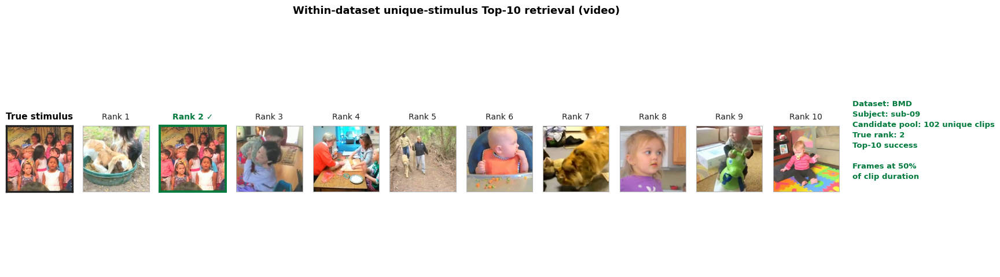

BOLD5000   sub-01: query 1285, true rank 4 (paper: 4) among 113 unique stimuli
Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject/qualitative_paper_examples/Fig2d_BOLD5000_sub-01.pdf


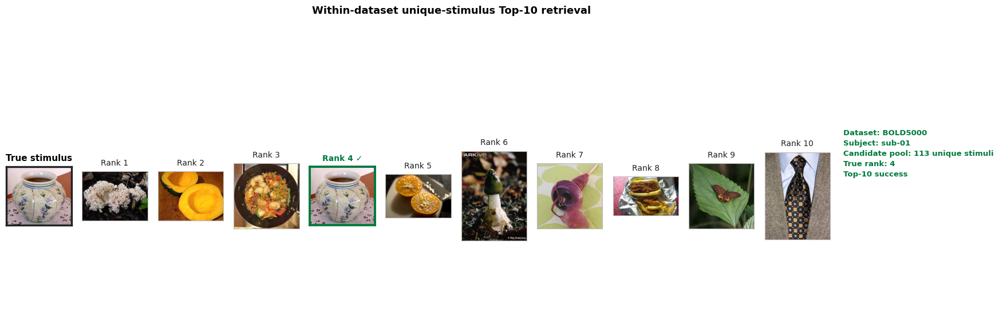

NSD        sub-05: query 3628, true rank 3 (paper: 3) among 1,000 unique stimuli
Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject/qualitative_paper_examples/Fig2d_NSD_sub-05.pdf


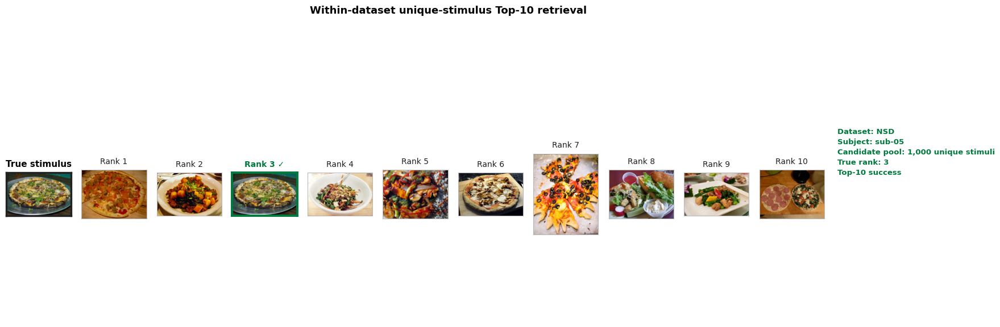

GOD        sub-04: query 45150, true rank 1 (paper: 1) among 50 unique stimuli
Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject/qualitative_paper_examples/Fig2d_GOD_sub-04.pdf


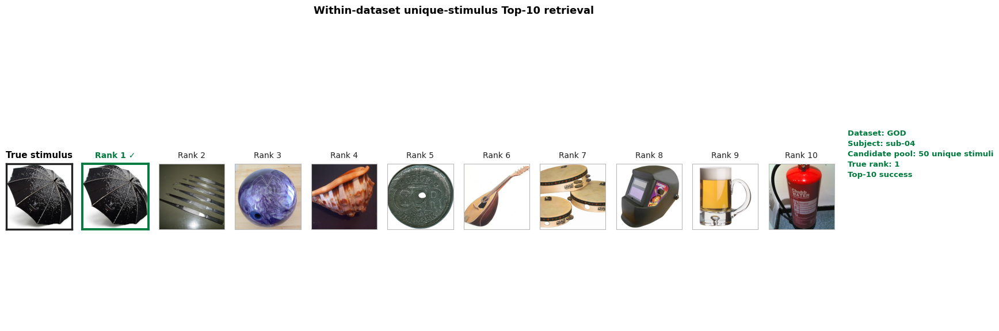

deeprecon  sub-03: query 12054, true rank 4 (paper: 4) among 100 unique stimuli
Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject/qualitative_paper_examples/Fig2d_deeprecon_sub-03.pdf


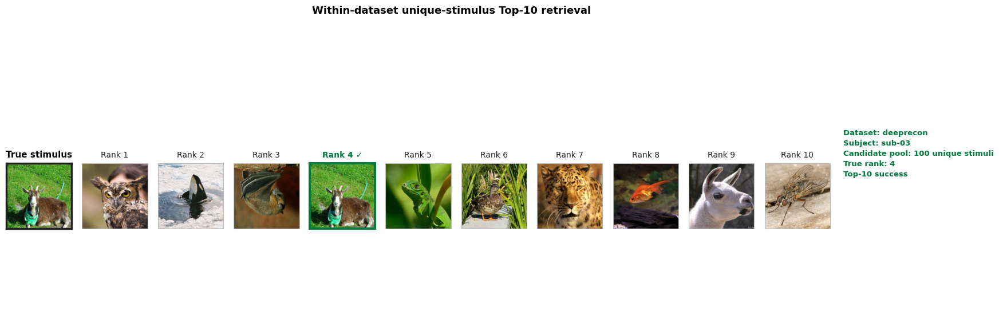

THINGS     sub-02: query 29804, true rank 2 (paper: 2) among 100 unique stimuli
Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject/qualitative_paper_examples/Fig2d_THINGS_sub-02.pdf


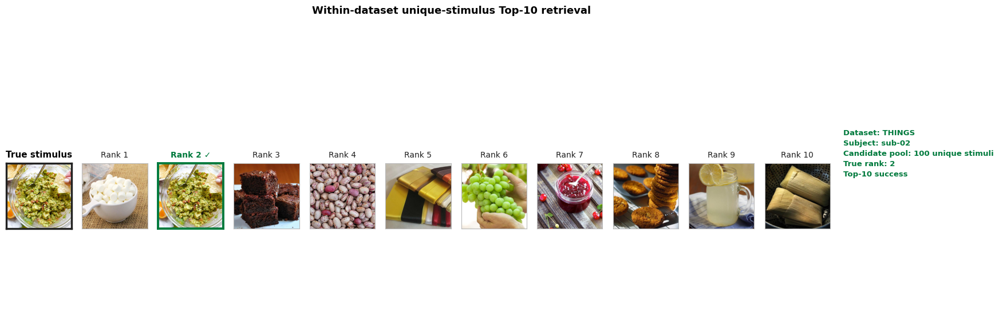

NOD        sub-21: query 28151, true rank 1 (paper: 1) among 11,424 unique stimuli
Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject/qualitative_paper_examples/Fig2d_NOD_sub-21.pdf


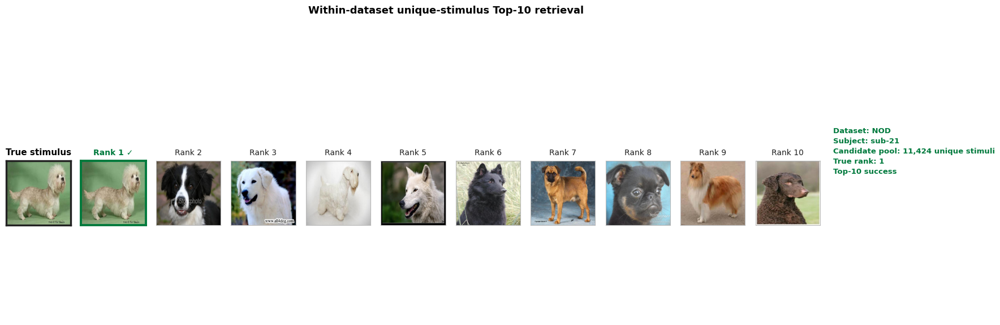

,dataset,subject,query_index,true_stimulus,true_rank,n_unique_candidates
0,BMD,sub-09,26214,flickr-4-4-6-0-7-0-7-4-18344607074_27,2,102
1,BOLD5000,sub-01,1285,n04522168_29661,4,113
2,NSD,sub-05,3628,000000321902,3,1000
3,GOD,sub-04,45150,n04507155_21299,1,50
4,deeprecon,sub-03,12054,n02416519_12793,4,100
5,THINGS,sub-02,29804,guacamole_18s,2,100
6,NOD,sub-21,28151,n02096437_603,1,11424


In [423]:
# ============================================================
# Fig. 2d: the seven retrieval examples shown in the paper
#
# Each row is one held-out query (row index into
# retrieval_metadata.csv / retrieval_embeddings.pt), ranked
# against all unique held-out stimuli of its own dataset.
# The rows were chosen for illustration; see the README.
# ============================================================

from matplotlib.backends.backend_pdf import PdfPages

FIG2D_EXAMPLES = [
    # (dataset, subject, query row, rank of the true stimulus in the paper)
    ("BMD", "sub-09", 26214, 2),
    ("BOLD5000", "sub-01", 1285, 4),
    ("NSD", "sub-05", 3628, 3),
    ("GOD", "sub-04", 45150, 1),
    ("deeprecon", "sub-03", 12054, 4),
    ("THINGS", "sub-02", 29804, 2),
    ("NOD", "sub-21", 28151, 1),
]

fig2d_out = output_dir / "qualitative_paper_examples"
fig2d_out.mkdir(parents=True, exist_ok=True)

SHOW_FILENAMES = False

fig2d_rows = []

with PdfPages(fig2d_out / "Fig2d_retrieval_examples.pdf") as pdf:
    for dataset_name, subject_name, query_index, paper_rank in FIG2D_EXAMPLES:
        query_row = retrieval_metadata.iloc[query_index]

        assert normalize_dataset_name(query_row["dataset_name"]) == normalize_dataset_name(dataset_name)
        assert normalize_identifier(query_row["subject_name"]) == normalize_identifier(subject_name)

        result = retrieve_top_unique_within_dataset(
            query_index=query_index,
            brain_embeddings=brain_embeddings,
            metadata_df=retrieval_metadata,
            candidate_banks=dataset_candidate_banks,
            top_k=TOP_K,
        )
        result["selection_mode"] = "paper"

        print(
            f"{dataset_name:10s} {subject_name}: query {query_index}, "
            f"true rank {result['target_rank']} (paper: {paper_rank}) "
            f"among {result['n_unique_candidates']:,} unique stimuli"
        )
        assert result["target_rank"] == paper_rank

        save_path = fig2d_out / f"Fig2d_{safe_filename(dataset_name)}_{safe_filename(subject_name)}.pdf"

        if dataset_name == "BMD":
            fig = plot_within_dataset_video_retrieval_example(
                retrieval_result=result,
                metadata_df=retrieval_metadata,
                save_path=save_path,
                show_filenames=SHOW_FILENAMES,
            )
        else:
            fig = plot_within_dataset_retrieval_example(
                retrieval_result=result,
                metadata_df=retrieval_metadata,
                save_path=save_path,
                figsize=(16.2, 6.4),
                show_filenames=SHOW_FILENAMES,
            )

        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

        fig2d_rows.append({
            "dataset": dataset_name,
            "subject": subject_name,
            "query_index": query_index,
            "true_stimulus": result["target_clean"],
            "true_rank": result["target_rank"],
            "n_unique_candidates": result["n_unique_candidates"],
        })

display(pd.DataFrame(fig2d_rows))

---
## Figure 3 — Semantic organization and network contributions (panels a–f)

### Semantic clusters
40 k-means clusters (k = 40, `random_state=42`, `n_init=50`) of the ℓ2-normalized CLIP embeddings of the 12,819 unique held-out stimuli. The cluster assignments, t-SNE coordinates and representative stimuli are loaded from `results/analysis_2_semantic_clusters/`.

In [424]:
# [analysis 2 paths]
# ============================================================
# Analysis 2: Semantic cluster profiling
# ============================================================

import os
import json
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from tqdm.auto import tqdm

import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix, adjusted_rand_score, normalized_mutual_info_score
from sklearn.preprocessing import normalize


# ============================================================
# Configuration
# ============================================================

ANALYSIS2_CONFIG = {
    # Analysis 1 output directory
    "analysis1_dir": str(RESULTS_ROOT) + "/analysis_1_dataset_subject",

    # Analysis 2 output directory
    "output_dir": str(RESULTS_ROOT) + "/analysis_2_semantic_clusters",

    # Number of semantic clusters, similar to WAVE using 5 clusters
    "n_clusters": 5,

    # Use "kmeans" clustering in CLIP space
    "random_state": 42,
    "n_init": 50,

    # Dimensionality reduction for visualization
    "make_tsne": True,
    "tsne_perplexity": 30,
    "tsne_learning_rate": "auto",
    "tsne_init": "pca",

    # Metrics
    "topk": (1, 5, 10),

    # Plotting
    "make_plots": True,

    # Optional: if you saved canonical_meta and want to inspect paths/labels later
    "canonical_metadata_path": str(MOSAIC_ROOT) + "/meta_data_compiled/canonical_meta_remapped.pkl",
}

analysis1_dir = Path(ANALYSIS2_CONFIG["analysis1_dir"])
analysis2_out = Path(ANALYSIS2_CONFIG["output_dir"])
analysis2_out.mkdir(parents=True, exist_ok=True)

print("Analysis 1 dir:", analysis1_dir.resolve())
print("Analysis 2 output dir:", analysis2_out.resolve())

Analysis 1 dir: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_1_dataset_subject
Analysis 2 output dir: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_2_semantic_clusters


In [425]:
# [load cluster assignments and summaries]
unique_stimulus_df = pd.read_csv(
    analysis2_out / "analysis2_unique_stimulus_clusters_with_coordinates.csv"
)


dataset_cluster_summary = pd.read_csv(
    analysis2_out / "analysis2_dataset_by_cluster_summary.csv"
)

cluster_summary = pd.read_csv(
    analysis2_out / "analysis2_cluster_wise_retrieval_summary.csv"
)

per_sample_cluster_df = pd.read_csv(
    analysis2_out / "analysis2_per_sample_with_semantic_clusters.csv"
)

In [426]:
# Representative stimuli per cluster: the 12 stimuli closest to each
# k-means centroid (saved by the clustering step).
from PIL import Image

cluster_examples_df = pd.read_csv(
    analysis2_out / "analysis2_cluster_example_images.csv"
)

# Image paths were stored for the original data location
cluster_examples_df["image_path"] = cluster_examples_df["image_path"].str.replace(
    "/mount/share/moein/MOSAIC", str(MOSAIC_ROOT), regex=False
)

print("Example images:", len(cluster_examples_df),
      "| found on disk:", int(cluster_examples_df["image_path"].map(lambda p: Path(p).exists()).sum()))

Example images: 480 | found on disk: 480


In [427]:
# ============================================================
# Plot image grid for each cluster
# ============================================================

def safe_open_image(path):
    try:
        img = Image.open(path).convert("RGB")
        return img
    except Exception as e:
        print(f"Could not open image: {path}")
        print(e)
        return None


def plot_cluster_image_grid(
    examples_df,
    cluster_id,
    n_cols=4,
    image_size=3.0,
    save_path=None,
    title_prefix="Semantic cluster",
):
    g = examples_df[examples_df["semantic_cluster"] == cluster_id].copy()
    g = g.sort_values("example_rank")

    n = len(g)
    if n == 0:
        print(f"No images for cluster {cluster_id}")
        return

    n_rows = int(np.ceil(n / n_cols))

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(n_cols * image_size, n_rows * image_size),
    )

    axes = np.asarray(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax_i, (_, row) in enumerate(g.iterrows()):
        ax = axes[ax_i]

        img = safe_open_image(row["image_path"])
        if img is None:
            continue

        ax.imshow(img)
        ax.axis("off")

        stim_name = str(row["stimulus_clean"])
        if len(stim_name) > 35:
            stim_name = stim_name[:32] + "..."

        ax.set_title(stim_name, fontsize=8)

    fig.suptitle(f"{title_prefix} {cluster_id}", fontsize=14)
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show();


# for cluster_id in sorted(cluster_examples_df["semantic_cluster"].unique()):
#     save_path = analysis2_out / f"semantic_cluster_{cluster_id}_example_images.png"

#     plot_cluster_image_grid(
#         examples_df=cluster_examples_df,
#         cluster_id=int(cluster_id),
#         n_cols=4,
#         image_size=3.0,
#         save_path=save_path,
#     )

#     print("Saved:", save_path)

### Fig. 3a — t-SNE of the 40 clusters with the ten representative clusters highlighted

In [428]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import math

# ------------------------------------------------------------
# Dataset colors (keep unchanged)
# ------------------------------------------------------------

DATASET_COLORS = {
    "BMD": "#0072B2",
    "NSD": "#D55E00",
    "THINGS": "#009E73",
    "GOD": "#CC79A7",
    "BOLD5000": "#E69F00",
    "deeprecon": "#56B4E9",
    "NOD": "#4D4D4D",
    "HAD": "#999933",
}

# ------------------------------------------------------------
# Manual names for the sampled 10 clusters
# ------------------------------------------------------------

MANUAL_CLUSTER_NAMES = {
    7:  "People & portraits",
    33: "Tennis action",
    4:  "Sharks & marine life",
    36: "Consumer electronics",
    22: "Trains & rail transport",
    18: "Water towers",
    35: "Rural fields",
    23: "Emergency vehicles",
    25: "Religious architecture",
    11: "Home appliances",
}

# ------------------------------------------------------------
# Manual cluster colors
# Chosen to be visually distinct and to avoid the dataset palette
# as much as possible.
# ------------------------------------------------------------

MANUAL_CLUSTER_COLORS = {
    7:  "#8E1B3A",   # deep cranberry
    33: "#660B9E",   # deep purple
    4:  "#00897B",   # dark teal
    36: "#D32F2F",   # vivid red
    22: "#9C8DB5",   # lavender purple
    18: "#8D6E63",   # warm brown
    35: "#EC407A",   # saturated rose
    23: "#4A2CD2",   # indigo-violet
    25: "#C0CA33",   # yellow-lime
    11: "#26C6DA",   # cyan
}

# Color for all non-highlighted clusters
other_cluster_color = "#D9D9D9"   # light grey

# ------------------------------------------------------------
# If your sampled clusters were generated automatically,
# keep their retrieval-rank order but replace generic labels
# with the manual semantic names above.
# ------------------------------------------------------------

metric_for_selection = "unique_stimulus_top10"

cluster_summary_sorted = (
    cluster_summary.copy()
    .sort_values(metric_for_selection, ascending=False)
    .reset_index(drop=True)
)

cluster_summary_sorted["retrieval_rank"] = np.arange(1, len(cluster_summary_sorted) + 1)

selected_positions = list(range(0, min(len(cluster_summary_sorted), 40), 4))[:10]
sampled_selected_cluster_ids = (
    cluster_summary_sorted.loc[selected_positions, "semantic_cluster"]
    .astype(int)
    .tolist()
)

print("Automatically sampled cluster IDs:", sampled_selected_cluster_ids)

# Short labels for legends / concise display
sampled_selected_cluster_short_names = {
    cid: MANUAL_CLUSTER_NAMES.get(cid, f"Cluster {cid}")
    for cid in sampled_selected_cluster_ids
}

# Rich labels for collage titles
sampled_selected_cluster_info = {}

for pos in selected_positions:
    row = cluster_summary_sorted.loc[pos]
    cid = int(row["semantic_cluster"])
    rank = int(row["retrieval_rank"])
    acc = float(row[metric_for_selection])

    name = MANUAL_CLUSTER_NAMES.get(cid, f"Cluster {cid}")
    sampled_selected_cluster_info[cid] = f"{name} (C{cid} | rank {rank} | Top-10={acc:.3f})"

# Manual highlight color map in the same sampled order
sampled_selected_color_map = {
    cid: MANUAL_CLUSTER_COLORS[cid]
    for cid in sampled_selected_cluster_ids
    if cid in MANUAL_CLUSTER_COLORS
}

print("\nSelected cluster labels:")
for cid in sampled_selected_cluster_ids:
    print(cid, "->", sampled_selected_cluster_info[cid])

Automatically sampled cluster IDs: [7, 33, 4, 36, 22, 18, 35, 23, 25, 11]

Selected cluster labels:
7 -> People & portraits (C7 | rank 1 | Top-10=0.333)
33 -> Tennis action (C33 | rank 5 | Top-10=0.245)
4 -> Sharks & marine life (C4 | rank 9 | Top-10=0.186)
36 -> Consumer electronics (C36 | rank 13 | Top-10=0.148)
22 -> Trains & rail transport (C22 | rank 17 | Top-10=0.125)
18 -> Water towers (C18 | rank 21 | Top-10=0.078)
35 -> Rural fields (C35 | rank 25 | Top-10=0.048)
23 -> Emergency vehicles (C23 | rank 29 | Top-10=0.033)
25 -> Religious architecture (C25 | rank 33 | Top-10=0.029)
11 -> Home appliances (C11 | rank 37 | Top-10=0.006)


In [429]:
def plot_tsne_highlight_sampled_clusters_legend_only(
    unique_stimulus_df,
    selected_cluster_info,
    selected_cluster_short_names,
    selected_color_map,
    x_col="tsne_x",
    y_col="tsne_y",
    save_path=None,
    figsize=(6.4, 5.4),
    title="t-SNE of semantic clusters",
    other_color="#D9D9D9",
    other_alpha=0.22,
    selected_alpha=0.88,
    selected_size=14,
    other_size=5,
    legend_ncol=1,
):
    df = unique_stimulus_df.copy()
    df["semantic_cluster"] = df["semantic_cluster"].astype(int)

    selected_clusters = list(selected_cluster_info.keys())

    fig, ax = plt.subplots(figsize=figsize)

    # ------------------------------------------------------------
    # Background points: all non-selected clusters
    # ------------------------------------------------------------

    bg = df[~df["semantic_cluster"].isin(selected_clusters)].copy()

    ax.scatter(
        bg[x_col],
        bg[y_col],
        s=other_size,
        c=other_color,
        alpha=other_alpha,
        linewidths=0,
        label="Other clusters",
        zorder=1,
    )

    # ------------------------------------------------------------
    # Highlighted clusters: colored, but no text on top of points
    # ------------------------------------------------------------

    for cid in selected_clusters:
        g = df[df["semantic_cluster"] == cid].copy()

        cluster_name = selected_cluster_short_names[cid]

        ax.scatter(
            g[x_col],
            g[y_col],
            s=selected_size,
            color=selected_color_map[cid],
            alpha=selected_alpha,
            linewidths=0,
            label=f"{cluster_name} (C{cid})",
            zorder=3,
        )

    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
    ax.set_title(title)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        frameon=False,
        fontsize=7,
        ncol=legend_ncol,
        bbox_to_anchor=(1.02, 1.0),
        loc="upper left",
        title="Highlighted clusters",
        title_fontsize=8,
        markerscale=1.5,
    )

    fig.tight_layout()

    if save_path is not None:
        save_path = Path(save_path)

        if save_path.suffix.lower() != ".pdf":
            save_path = save_path.with_suffix(".pdf")

        fig.savefig(save_path, bbox_inches="tight")
        print("Saved:", save_path)

    plt.show();

Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_2_semantic_clusters/tsne_sampled_every4_clusters_highlighted_legend_only.pdf


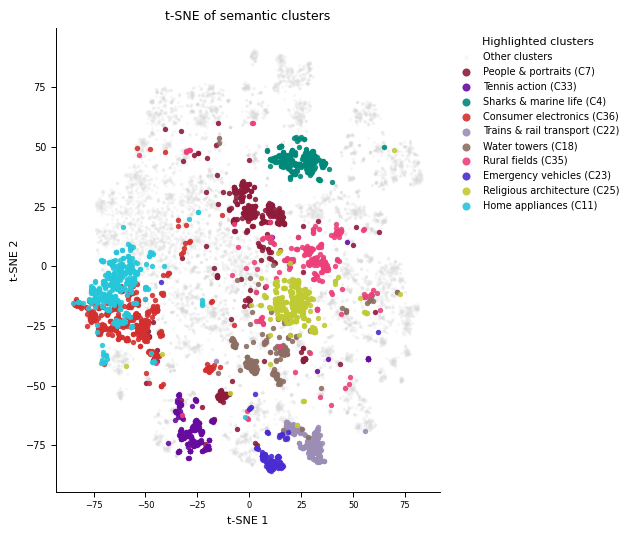

In [430]:
plot_tsne_highlight_sampled_clusters_legend_only(
    unique_stimulus_df=unique_stimulus_df,
    selected_cluster_info=sampled_selected_cluster_info,
    selected_cluster_short_names=sampled_selected_cluster_short_names,
    selected_color_map=sampled_selected_color_map,
    x_col="tsne_x",
    y_col="tsne_y",
    save_path=analysis2_out / "tsne_sampled_every4_clusters_highlighted_legend_only.pdf",
    title="t-SNE of semantic clusters",
    other_color=other_cluster_color,
    other_alpha=0.20,
    selected_alpha=0.90,
    selected_size=15,
    other_size=5,
    legend_ncol=1,
)

### Fig. 3c — Top-10 accuracy (top) and number of unique stimuli (bottom) for all clusters
Every fourth cluster in the retrieval-ranked order is highlighted; these ten clusters are used throughout.

In [431]:
def plot_all40_retrieval_bars_sampled_selected(
    cluster_summary,
    selected_cluster_info,
    selected_cluster_short_names,
    selected_color_map,
    metric_col="unique_stimulus_top10",
    save_path=None,
    ylabel="Unique-stimulus Top-10 accuracy",
    title=None,
    figsize=(11.2, 3.6),
    other_color="#D9D9D9",
    show_value_labels=False,
):
    df = (
        cluster_summary
        .copy()
        .sort_values(metric_col, ascending=False)
        .reset_index(drop=True)
    )

    df["semantic_cluster"] = df["semantic_cluster"].astype(int)
    selected_clusters = list(selected_cluster_info.keys())
    x = np.arange(len(df))

    colors = [
        selected_color_map[c] if c in selected_clusters else other_color
        for c in df["semantic_cluster"]
    ]

    fig, ax = plt.subplots(figsize=figsize)

    bars = ax.bar(
        x,
        df[metric_col].values,
        color=colors,
        edgecolor="black",
        linewidth=0.35,
        width=0.75,
    )

    for bar, cid in zip(bars, df["semantic_cluster"]):
        if cid in selected_clusters:
            bar.set_linewidth(0.95)
            bar.set_edgecolor("black")
            bar.set_alpha(0.95)
        else:
            bar.set_alpha(0.55)

    xtick_labels = [str(c) for c in df["semantic_cluster"].tolist()]
    ax.set_xticks(x)
    ax.set_xticklabels(xtick_labels, rotation=45, ha="right", fontsize=6)

    # Color selected tick labels
    for tick_label, cid in zip(ax.get_xticklabels(), df["semantic_cluster"].tolist()):
        if cid in selected_clusters:
            tick_label.set_color(selected_color_map[cid])
            tick_label.set_fontweight("bold")
        else:
            tick_label.set_color("0.35")

    ax.set_ylabel(ylabel)
    ax.set_xlabel("Semantic cluster (sorted by retrieval accuracy)")
    ax.set_title(title)

    ymax = max(0.01, df[metric_col].max() * 1.18)
    ax.set_ylim(0, ymax)

    if show_value_labels:
        for bar, val in zip(bars, df[metric_col].values):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                val + ymax * 0.015,
                f"{val:.2f}",
                ha="center",
                va="bottom",
                fontsize=5.5,
                rotation=90,
            )

    handles = [
        plt.Line2D(
            [0], [0],
            marker="s",
            linestyle="None",
            markersize=7,
            markerfacecolor=selected_color_map[cid],
            markeredgecolor="black",
            label=f"{selected_cluster_short_names[cid]} (C{cid})",
        )
        for cid in selected_clusters
    ]
    handles.append(
        plt.Line2D(
            [0], [0],
            marker="s",
            linestyle="None",
            markersize=7,
            markerfacecolor=other_color,
            markeredgecolor="black",
            label="Other clusters",
        )
    )

    ax.legend(
        handles=handles,
        frameon=False,
        fontsize=7,
        ncol=3,
        bbox_to_anchor=(0.5, 1.28),
        loc="upper center",
        title="Highlighted clusters",
        title_fontsize=8,
    )

    ax.grid(axis="y", linewidth=0.35, alpha=0.25)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()

    if save_path is not None:
        save_path = Path(save_path)
        if save_path.suffix.lower() != ".pdf":
            save_path = save_path.with_suffix(".pdf")
        fig.savefig(save_path, bbox_inches="tight")
        print("Saved:", save_path)

    plt.show();

    return df

Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_2_semantic_clusters/retrieval_bars_all40_sorted_sampled_highlighted_named.pdf


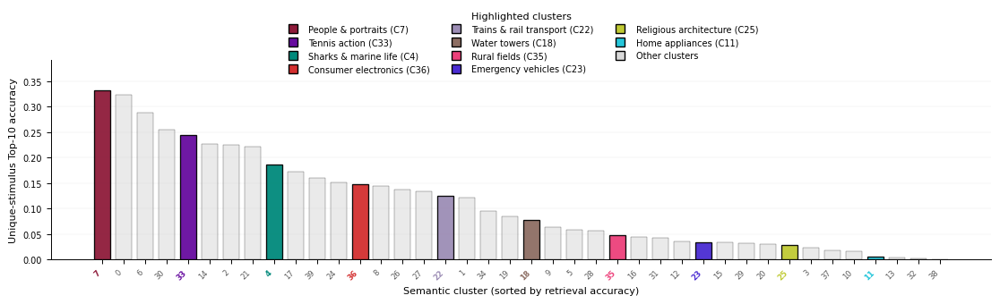

In [432]:
retrieval_plot_df = plot_all40_retrieval_bars_sampled_selected(
    cluster_summary=cluster_summary,
    selected_cluster_info=sampled_selected_cluster_info,
    selected_cluster_short_names=sampled_selected_cluster_short_names,
    selected_color_map=sampled_selected_color_map,
    metric_col="unique_stimulus_top10",
    save_path=analysis2_out / "retrieval_bars_all40_sorted_sampled_highlighted_named.pdf",
    # title="Retrieval accuracy by semantic cluster (sorted; every 4th highlighted)",
    other_color=other_cluster_color,
    show_value_labels=False,
)

In [433]:
def plot_all40_density_bars_sampled_selected(
    cluster_density_df,
    cluster_summary,
    selected_cluster_info,
    selected_cluster_short_names,
    selected_color_map,
    value_col="density",
    save_path=None,
    ylabel="Fraction of unique stimuli",
    title=None,
    figsize=(11.2, 3.6),
    other_color="#D9D9D9",
    show_value_labels=False,
):
    retrieval_order = (
        cluster_summary
        .copy()
        .sort_values("unique_stimulus_top10", ascending=False)["semantic_cluster"]
        .astype(int)
        .tolist()
    )

    df = cluster_density_df.copy()
    df["semantic_cluster"] = df["semantic_cluster"].astype(int)
    df["plot_order"] = df["semantic_cluster"].map(
        {cid: i for i, cid in enumerate(retrieval_order)}
    )
    df = df.sort_values("plot_order").reset_index(drop=True)

    selected_clusters = list(selected_cluster_info.keys())
    x = np.arange(len(df))

    colors = [
        selected_color_map[c] if c in selected_clusters else other_color
        for c in df["semantic_cluster"]
    ]

    fig, ax = plt.subplots(figsize=figsize)

    bars = ax.bar(
        x,
        df[value_col].values,
        color=colors,
        edgecolor="black",
        linewidth=0.35,
        width=0.75,
    )

    for bar, cid in zip(bars, df["semantic_cluster"]):
        if cid in selected_clusters:
            bar.set_linewidth(0.95)
            bar.set_edgecolor("black")
            bar.set_alpha(0.95)
        else:
            bar.set_alpha(0.55)

    ax.set_xticks(x)
    ax.set_xticklabels(
        [str(c) for c in df["semantic_cluster"].tolist()],
        rotation=45,
        ha="right",
        fontsize=6,
    )

    for tick_label, cid in zip(ax.get_xticklabels(), df["semantic_cluster"].tolist()):
        if cid in selected_clusters:
            tick_label.set_color(selected_color_map[cid])
            tick_label.set_fontweight("bold")
        else:
            tick_label.set_color("0.35")

    ax.set_ylabel(ylabel)
    ax.set_xlabel("Semantic cluster (same retrieval-sorted order)")
    ax.set_title(title)

    ymax = max(0.01, df[value_col].max() * 1.18)
    ax.set_ylim(0, ymax)

    if show_value_labels:
        for bar, val in zip(bars, df[value_col].values):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                val + ymax * 0.015,
                f"{val:.3f}",
                ha="center",
                va="bottom",
                fontsize=5.5,
                rotation=90,
            )

    handles = [
        plt.Line2D(
            [0], [0],
            marker="s",
            linestyle="None",
            markersize=7,
            markerfacecolor=selected_color_map[cid],
            markeredgecolor="black",
            label=f"{selected_cluster_short_names[cid]} (C{cid})",
        )
        for cid in selected_clusters
    ]
    handles.append(
        plt.Line2D(
            [0], [0],
            marker="s",
            linestyle="None",
            markersize=7,
            markerfacecolor=other_color,
            markeredgecolor="black",
            label="Other clusters",
        )
    )

    ax.legend(
        handles=handles,
        frameon=False,
        fontsize=7,
        ncol=3,
        bbox_to_anchor=(0.5, 1.28),
        loc="upper center",
        title="Highlighted clusters",
        title_fontsize=8,
    )

    ax.grid(axis="y", linewidth=0.35, alpha=0.25)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()

    if save_path is not None:
        save_path = Path(save_path)
        if save_path.suffix.lower() != ".pdf":
            save_path = save_path.with_suffix(".pdf")
        fig.savefig(save_path, bbox_inches="tight")
        print("Saved:", save_path)

    plt.show();

    return df

In [434]:
def compute_cluster_density_table(
    unique_stimulus_df,
    n_clusters=40,
):
    counts = (
        unique_stimulus_df
        .groupby("semantic_cluster")
        .size()
        .reset_index(name="n_unique_stimuli")
    )

    all_clusters = pd.DataFrame({"semantic_cluster": np.arange(n_clusters)})

    counts = all_clusters.merge(
        counts,
        on="semantic_cluster",
        how="left",
    )

    counts["n_unique_stimuli"] = counts["n_unique_stimuli"].fillna(0).astype(int)
    counts["density"] = counts["n_unique_stimuli"] / counts["n_unique_stimuli"].sum()

    return counts

In [435]:
cluster_density_df = compute_cluster_density_table(
    unique_stimulus_df=unique_stimulus_df,
    n_clusters=40,
)

display(cluster_density_df.head())

,semantic_cluster,n_unique_stimuli,density
0,0,251,0.019580
1,1,332,0.025899
2,2,259,0.020204
3,3,207,0.016148
4,4,308,0.024027


Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_2_semantic_clusters/cluster_size_all40_retrieval_sorted_sampled_highlighted_named.pdf


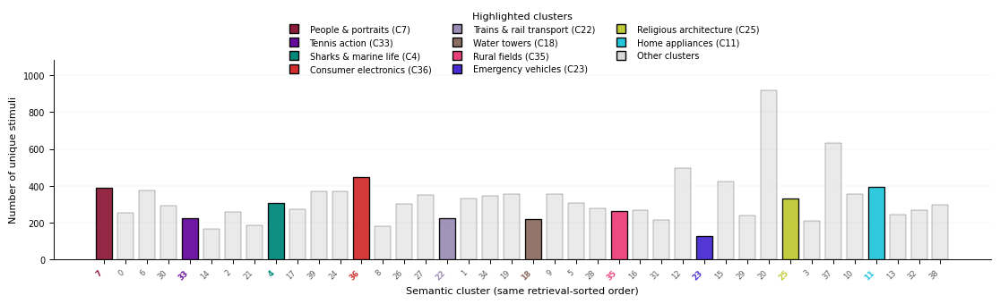

In [436]:
density_plot_df = plot_all40_density_bars_sampled_selected(
    cluster_density_df=cluster_density_df,
    cluster_summary=cluster_summary,
    selected_cluster_info=sampled_selected_cluster_info,
    selected_cluster_short_names=sampled_selected_cluster_short_names,
    selected_color_map=sampled_selected_color_map,
    value_col="n_unique_stimuli",
    save_path=analysis2_out / "cluster_size_all40_retrieval_sorted_sampled_highlighted_named.pdf",
    ylabel="Number of unique stimuli",
    # title="Semantic cluster size (same retrieval-sorted order; every 4th highlighted)",
    other_color=other_cluster_color,
)

### Fig. 3a (continued) — Representative stimuli of the ten highlighted clusters

In [437]:
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from pathlib import Path


def draw_cluster_circle_collage(
    ax,
    cluster_df,
    cluster_color="black",
    n_examples=16,
    pad=0.004,
    border_lw=2.2,
    background_color="white",
):
    """
    Draw a circular image collage for one semantic cluster.

    Required columns in cluster_df:
        - image_path
        - example_rank
    """

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.axis("off")

    # Main circular clip path
    circle_clip = Circle(
        (0.5, 0.5),
        0.48,
        facecolor=background_color,
        edgecolor="none",
        linewidth=0,
        zorder=1,
    )
    ax.add_patch(circle_clip)

    # Circle border
    circle_border = Circle(
        (0.5, 0.5),
        0.485,
        facecolor="none",
        edgecolor=cluster_color,
        linewidth=border_lw,
        zorder=10,
    )
    ax.add_patch(circle_border)

    g = (
        cluster_df.copy()
        .sort_values("example_rank")
        .head(n_examples)
        .reset_index(drop=True)
    )

    n = len(g)
    if n == 0:
        ax.text(
            0.5,
            0.5,
            "No images",
            ha="center",
            va="center",
            fontsize=8,
        )
        return

    # Square-ish grid inside the circle
    ncols = math.ceil(math.sqrt(n))
    nrows = math.ceil(n / ncols)

    tile_w = (1 - pad * (ncols + 1)) / ncols
    tile_h = (1 - pad * (nrows + 1)) / nrows

    for idx in range(n):
        row_i = idx // ncols
        col_i = idx % ncols

        x0 = pad + col_i * (tile_w + pad)
        y0 = 1 - (pad + (row_i + 1) * tile_h + row_i * pad)

        row = g.iloc[idx]
        img = safe_open_image(row["image_path"])

        if img is None:
            continue

        im = ax.imshow(
            img,
            extent=(x0, x0 + tile_w, y0, y0 + tile_h),
            zorder=2,
        )

        # Clip all image tiles to the large circular boundary
        im.set_clip_path(circle_clip)

In [438]:
def plot_sampled_clusters_circular_collages(
    examples_df,
    selected_cluster_info,
    selected_color_map,
    n_examples_per_cluster=16,
    ncols=5,
    panel_size=2.35,
    save_path=None,
    title="Representative images from sampled semantic clusters",
):
    cluster_ids = list(selected_cluster_info.keys())
    n_clusters = len(cluster_ids)
    nrows = math.ceil(n_clusters / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(ncols * panel_size, nrows * (panel_size + 0.35)),
    )

    axes = np.array(axes).reshape(nrows, ncols)

    for ax in axes.flatten():
        ax.axis("off")

    for i, cluster_id in enumerate(cluster_ids):
        ax = axes.flatten()[i]

        g = examples_df[
            examples_df["semantic_cluster"].astype(int) == int(cluster_id)
        ].copy()

        cluster_color = selected_color_map.get(cluster_id, "black")

        draw_cluster_circle_collage(
            ax=ax,
            cluster_df=g,
            cluster_color=cluster_color,
            n_examples=n_examples_per_cluster,
            pad=0.004,
            border_lw=2.2,
        )

        ax.set_title(
            selected_cluster_info[cluster_id],
            fontsize=7.2,
            color=cluster_color,
            pad=5,
            fontweight="bold",
        )

    fig.suptitle(title, fontsize=13, y=0.995)
    fig.tight_layout(rect=[0, 0, 1, 0.96])

    if save_path is not None:
        save_path = Path(save_path)
        if save_path.suffix.lower() != ".pdf":
            save_path = save_path.with_suffix(".pdf")

        fig.savefig(
            save_path,
            bbox_inches="tight",
            transparent=False,
        )
        print("Saved:", save_path)

    plt.show();

Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_2_semantic_clusters/sampled_every4_clusters_circular_collages_named.pdf


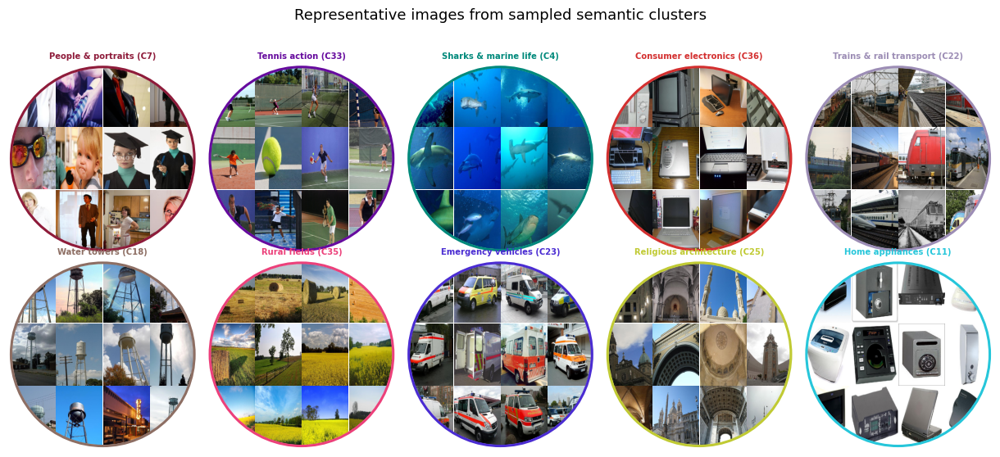

In [439]:
sampled_examples_df = cluster_examples_df[
    cluster_examples_df["semantic_cluster"].astype(int).isin(sampled_selected_cluster_ids)
].copy()

sampled_selected_cluster_info_short = {}

for cid in sampled_selected_cluster_ids:
    sampled_selected_cluster_info_short[cid] = (
        f"{sampled_selected_cluster_short_names[cid]} (C{cid})"
    )

plot_sampled_clusters_circular_collages(
    examples_df=sampled_examples_df,
    selected_cluster_info=sampled_selected_cluster_info_short,
    selected_color_map=sampled_selected_color_map,
    n_examples_per_cluster=16,
    ncols=5,
    panel_size=2.45,
    save_path=analysis2_out / "sampled_every4_clusters_circular_collages_named.pdf",
    title="Representative images from sampled semantic clusters",
)

### Fig. 3b — Dataset composition of the ten clusters

In [440]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path


# ============================================================
# Dataset colors
# ============================================================

DATASET_COLORS_CLEAN = {
    "BMD": "#0072B2",
    "NSD": "#D55E00",
    "THINGS": "#009E73",
    "GOD": "#CC79A7",
    "BOLD5000": "#E69F00",
    "deeprecon": "#56B4E9",
    "NOD": "#4D4D4D",
    "HAD": "#999933",
}

DATASET_ORDER = [
    "BMD",
    "NSD",
    "THINGS",
    "GOD",
    "BOLD5000",
    "deeprecon",
    "NOD",
    "HAD",
]


# ============================================================
# Manual semantic names for the sampled clusters
# ============================================================

MANUAL_CLUSTER_NAMES = {
    7:  "People & portraits",
    33: "Tennis action",
    4:  "Sharks & marine life",
    36: "Consumer electronics",
    22: "Trains & rail transport",
    18: "Water towers",
    35: "Rural fields",
    23: "Emergency vehicles",
    25: "Religious architecture",
    11: "Home appliances",
}


# ============================================================
# Manual cluster colors
# Use these only for semantic clusters, not datasets.
# ============================================================

MANUAL_CLUSTER_COLORS = {
    7:  "#8E1B3A",   # deep cranberry
    33: "#660B9E",   # deep purple
    4:  "#00897B",   # dark teal
    36: "#D32F2F",   # vivid red
    22: "#9C8DB5",   # lavender purple
    18: "#8D6E63",   # warm brown
    35: "#EC407A",   # saturated rose
    23: "#4A2CD2",   # indigo-violet
    25: "#C0CA33",   # yellow-lime
    11: "#26C6DA",   # cyan
}

other_cluster_color = "#D9D9D9"

In [441]:
# ============================================================
# Recreate sampled selected clusters and clean labels
# ============================================================

metric_for_selection = "unique_stimulus_top10"

cluster_summary_sorted = (
    cluster_summary.copy()
    .sort_values(metric_for_selection, ascending=False)
    .reset_index(drop=True)
)

cluster_summary_sorted["retrieval_rank"] = np.arange(1, len(cluster_summary_sorted) + 1)

# These are positions in the accuracy-sorted list: 0, 4, 8, 12, ...
selected_positions = list(range(0, min(len(cluster_summary_sorted), 40), 4))[:10]

sampled_selected_cluster_ids = (
    cluster_summary_sorted.loc[selected_positions, "semantic_cluster"]
    .astype(int)
    .tolist()
)

print("Selected sampled cluster IDs:")
print(sampled_selected_cluster_ids)


# Short semantic names
sampled_selected_cluster_short_names = {
    cid: MANUAL_CLUSTER_NAMES.get(cid, f"Cluster {cid}")
    for cid in sampled_selected_cluster_ids
}


# Clean labels for compact plots
sampled_selected_cluster_info_clean = {}

for pos in selected_positions:
    row = cluster_summary_sorted.loc[pos]

    cid = int(row["semantic_cluster"])
    rank = int(row["retrieval_rank"])

    name = MANUAL_CLUSTER_NAMES.get(cid, f"Cluster {cid}")

    sampled_selected_cluster_info_clean[cid] = f"{name} (C{cid}, rank {rank})"


# Longer labels, useful for collage titles
sampled_selected_cluster_info = {}

for pos in selected_positions:
    row = cluster_summary_sorted.loc[pos]

    cid = int(row["semantic_cluster"])
    rank = int(row["retrieval_rank"])
    acc = float(row[metric_for_selection])

    name = MANUAL_CLUSTER_NAMES.get(cid, f"Cluster {cid}")

    sampled_selected_cluster_info[cid] = (
        f"{name} | C{cid} | rank {rank} | Top-10={acc:.3f}"
    )


# Manual color map for selected clusters
sampled_selected_color_map = {
    cid: MANUAL_CLUSTER_COLORS.get(cid, "#000000")
    for cid in sampled_selected_cluster_ids
}


print("\nSelected sampled clusters:")
for cid, label in sampled_selected_cluster_info.items():
    print(cid, ":", label)

Selected sampled cluster IDs:
[7, 33, 4, 36, 22, 18, 35, 23, 25, 11]

Selected sampled clusters:
7 : People & portraits | C7 | rank 1 | Top-10=0.333
33 : Tennis action | C33 | rank 5 | Top-10=0.245
4 : Sharks & marine life | C4 | rank 9 | Top-10=0.186
36 : Consumer electronics | C36 | rank 13 | Top-10=0.148
22 : Trains & rail transport | C22 | rank 17 | Top-10=0.125
18 : Water towers | C18 | rank 21 | Top-10=0.078
35 : Rural fields | C35 | rank 25 | Top-10=0.048
23 : Emergency vehicles | C23 | rank 29 | Top-10=0.033
25 : Religious architecture | C25 | rank 33 | Top-10=0.029
11 : Home appliances | C11 | rank 37 | Top-10=0.006


In [442]:
def compute_cluster_dataset_distribution(
    unique_stimulus_df,
    selected_cluster_info,
    dataset_col="first_dataset_name",
):
    selected_clusters = list(selected_cluster_info.keys())

    df = unique_stimulus_df.copy()
    df["semantic_cluster"] = df["semantic_cluster"].astype(int)

    df = df[df["semantic_cluster"].isin(selected_clusters)].copy()

    counts = (
        df.groupby(["semantic_cluster", dataset_col])
        .size()
        .reset_index(name="n_unique_stimuli")
    )

    # Fill missing cluster-dataset combinations with zero
    all_datasets = sorted(unique_stimulus_df[dataset_col].dropna().unique())

    full_index = pd.MultiIndex.from_product(
        [selected_clusters, all_datasets],
        names=["semantic_cluster", dataset_col],
    )

    counts = (
        counts.set_index(["semantic_cluster", dataset_col])
        .reindex(full_index, fill_value=0)
        .reset_index()
    )

    totals = counts.groupby("semantic_cluster")["n_unique_stimuli"].transform("sum")

    counts["fraction_within_cluster"] = (
        counts["n_unique_stimuli"] / totals.replace(0, np.nan)
    ).fillna(0)

    return counts


sampled_cluster_dataset_dist = compute_cluster_dataset_distribution(
    unique_stimulus_df=unique_stimulus_df,
    selected_cluster_info=sampled_selected_cluster_info_clean,
    dataset_col="first_dataset_name",
)

display(sampled_cluster_dataset_dist.head())

,semantic_cluster,first_dataset_name,n_unique_stimuli,fraction_within_cluster
0,7,BMD,44,0.112821
1,7,BOLD5000,3,0.007692
2,7,GOD,1,0.002564
3,7,NOD,264,0.676923
4,7,NSD,69,0.176923


In [443]:
def plot_selected_cluster_dataset_stacked_bars_horizontal(
    dist_df,
    selected_cluster_info,
    selected_cluster_color_map=None,
    value_col="n_unique_stimuli",
    dataset_col="first_dataset_name",
    dataset_colors=None,
    dataset_order=None,
    save_path=None,
    xlabel="Number of unique stimuli",
    # title="Dataset composition of selected semantic clusters",
    title=None,
    figsize=(7.8, 4.8),
    bar_height=0.72,
):
    if dataset_colors is None:
        dataset_colors = DATASET_COLORS_CLEAN

    if dataset_order is None:
        dataset_order = DATASET_ORDER

    selected_clusters = list(selected_cluster_info.keys())

    pivot = dist_df.pivot_table(
        index="semantic_cluster",
        columns=dataset_col,
        values=value_col,
        fill_value=0,
    )

    # Keep selected-cluster order exactly as given
    pivot = pivot.reindex(selected_clusters)

    # Preserve dataset order
    present_datasets = [d for d in dataset_order if d in pivot.columns]
    remaining_datasets = [d for d in pivot.columns if d not in present_datasets]
    datasets = present_datasets + remaining_datasets

    pivot = pivot[datasets]

    labels = [
        selected_cluster_info[int(c)]
        for c in pivot.index
    ]

    y = np.arange(len(pivot))
    left = np.zeros(len(pivot))

    fig, ax = plt.subplots(figsize=figsize)

    for dset in datasets:
        vals = pivot[dset].values

        ax.barh(
            y,
            vals,
            left=left,
            height=bar_height,
            color=dataset_colors.get(dset, "0.65"),
            edgecolor="white",
            linewidth=1.0,
            label=dset,
        )

        left += vals

    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=8)
    ax.invert_yaxis()

    # Color the y tick labels by semantic cluster color
    if selected_cluster_color_map is not None:
        for tick_label, cid in zip(ax.get_yticklabels(), pivot.index):
            cid = int(cid)
            tick_label.set_color(selected_cluster_color_map.get(cid, "black"))
            tick_label.set_fontweight("bold")

    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    ax.set_title(title, pad=38)

    ax.grid(axis="x", linewidth=0.35, alpha=0.25)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    handles = [
        Patch(
            facecolor=dataset_colors.get(d, "0.65"),
            edgecolor="white",
            label=d,
        )
        for d in datasets
    ]

    ax.legend(
        handles=handles,
        frameon=False,
        fontsize=7,
        ncol=4,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.18),
        columnspacing=1.2,
        handlelength=1.4,
        handletextpad=0.4,
    )

    fig.tight_layout()

    if save_path is not None:
        save_path = Path(save_path)

        if save_path.suffix.lower() != ".pdf":
            save_path = save_path.with_suffix(".pdf")

        fig.savefig(save_path, bbox_inches="tight")
        print("Saved:", save_path)

    plt.show();

Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_2_semantic_clusters/sampled_clusters_dataset_unique_stimuli_counts.pdf


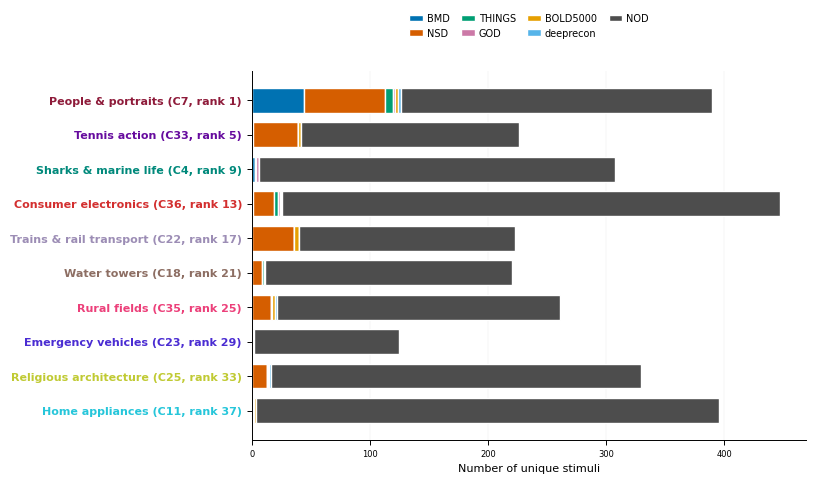

In [444]:
plot_selected_cluster_dataset_stacked_bars_horizontal(
    dist_df=sampled_cluster_dataset_dist,
    selected_cluster_info=sampled_selected_cluster_info_clean,
    selected_cluster_color_map=sampled_selected_color_map,
    value_col="n_unique_stimuli",
    dataset_col="first_dataset_name",
    xlabel="Number of unique stimuli",
    # title="Dataset composition across sampled semantic clusters",
    save_path=analysis2_out / "sampled_clusters_dataset_unique_stimuli_counts.pdf",
    figsize=(8.2, 4.9),
)

### Network ablation
Each ROI group was removed at inference by excluding its tokens from self-attention and from the attention-pooling readout (see Methods). The per-query results of all ablations are loaded from `results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/`.

In [445]:
# [analysis 5 paths]
# ============================================================
# Analysis 5 CLEAN: ROI / Network Ablation by Attention Masking
# ============================================================

import os
import re
import json
from pathlib import Path
from typing import Optional, Sequence, List

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)


# ============================================================
# IMPORTANT:
# Before running this notebook, you MUST already have:
#   model
#   retrieval_loader  -> ALL datasets / ALL subjects
#   roi_names
#
# Do NOT use an NSD-only retrieval_loader.
# ============================================================

ANALYSIS5_CONFIG = {
    "output_dir": str(RESULTS_ROOT) + "/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS",
    "device": CONFIG["device"] if "CONFIG" in globals() else ("cuda:0" if torch.cuda.is_available() else "cpu"),
    "retrieval_chunk_size": 512,
    "topk": (1, 5, 10),
    "max_eval_batches": None,
    "skip_groups": [],
}

analysis5_out = Path(ANALYSIS5_CONFIG["output_dir"])
analysis5_out.mkdir(parents=True, exist_ok=True)

analysis5_fig_out = analysis5_out / "publication_figures"
analysis5_fig_out.mkdir(parents=True, exist_ok=True)

print("Analysis 5 output:", analysis5_out)
print("Device:", ANALYSIS5_CONFIG["device"])

Analysis 5 output: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS
Device: cuda


In [446]:
import pandas as pd
import torch

# ============================================================
# Reconstruct saved paths
# ============================================================

per_sample_path = (
    analysis5_out
    / "analysis5_network_ablation_per_sample_ALL_DATASETS_CLEAN.pkl"
)

per_sample_csv_path = (
    analysis5_out
    / "analysis5_network_ablation_per_sample_ALL_DATASETS_CLEAN.csv"
)

partial_path = (
    analysis5_out
    / "analysis5_network_ablation_per_sample_ALL_DATASETS_CLEAN_partial.pkl"
)

baseline_embeddings_path = (
    analysis5_out
    / "analysis5_baseline_embeddings_ALL_DATASETS_CLEAN.pt"
)

baseline_metadata_path = (
    analysis5_out
    / "analysis5_baseline_metadata_ALL_DATASETS_CLEAN.csv"
)

In [447]:
all_network_ablation_per_sample_df = pd.read_csv(per_sample_csv_path)

print("Loaded CSV:")
print("Shape:", all_network_ablation_per_sample_df.shape)
display(all_network_ablation_per_sample_df.head())

Loaded CSV:
Shape: (653950, 21)


,real_idx,stimulus_id,stimulus_clean,raw_name,dataset_name,subject_name,subject_key,rank_unique,true_unique_similarity,top1_unique_similarity,top1_unique_stimulus_id,unique_hit_top1,unique_hit_top5,unique_hit_top10,semantic_cluster,top1_unique_semantic_cluster,top1_same_semantic_cluster,n_unique_stimulus_candidates,ablation_name,ablation_type,n_rois_removed
0,238625,73393,banana_13s,sub-03_THINGS_stimulus-banana_13s_phase-test_r...,THINGS,sub-03,THINGS::sub-03,181,0.236277,0.338924,73564,0.0,0.0,0.0,34,6,0.0,12819,baseline,baseline,0
1,323845,71628,flickr-5-6-5-9-6-6-9-8-4056596698_27,sub-09_BMD_stimulus-flickr-5-6-5-9-6-6-9-8-405...,BMD,sub-09,BMD::sub-09,14,0.288716,0.378403,71621,0.0,0.0,0.0,7,7,1.0,12819,baseline,baseline,0
2,338711,71758,n02916179_24850,sub-03_GOD_stimulus-n02916179_24850_phase-test...,GOD,sub-03,GOD::sub-03,3,0.313122,0.319207,113101,0.0,1.0,1.0,8,36,0.0,12819,baseline,baseline,0
3,319518,71597,flickr-1-8-2-7-3-9-4-1-3418273941_1,sub-08_BMD_stimulus-flickr-1-8-2-7-3-9-4-1-341...,BMD,sub-08,BMD::sub-08,4,0.341481,0.361188,71630,0.0,1.0,1.0,0,30,0.0,12819,baseline,baseline,0
4,239111,73744,dough_19s,sub-03_THINGS_stimulus-dough_19s_phase-test_rep-3,THINGS,sub-03,THINGS::sub-03,231,0.244093,0.336888,73411,0.0,0.0,0.0,6,12,0.0,12819,baseline,baseline,0


In [448]:
def summarize_ablation_performance(
    per_sample_df,
    group_cols=None,
    topk=(1, 5, 10),
):
    if group_cols is None:
        group_cols = []

    df = per_sample_df.copy()

    base_group_cols = ["ablation_name", "ablation_type", "n_rois_removed"]
    all_group_cols = base_group_cols + list(group_cols)

    agg_dict = {
        "n_eval_samples": ("stimulus_id", "size"),
        "n_unique_stimuli": ("stimulus_id", "nunique"),
        "rank_unique_mean": ("rank_unique", "mean"),
        "rank_unique_median": ("rank_unique", "median"),
        "true_unique_similarity_mean": ("true_unique_similarity", "mean"),
        "top1_unique_similarity_mean": ("top1_unique_similarity", "mean"),
        "top1_same_semantic_cluster": ("top1_same_semantic_cluster", "mean"),
    }

    for k in topk:
        agg_dict[f"unique_top{k}"] = (f"unique_hit_top{k}", "mean")

    summary = (
        df.groupby(all_group_cols, dropna=False)
        .agg(**agg_dict)
        .reset_index()
    )

    for k in topk:
        summary[f"chance_unique_top{k}"] = (
            k / summary["n_unique_stimuli"].replace(0, np.nan)
        ).clip(upper=1.0).fillna(0)

    return summary


def add_baseline_drops(summary_df, group_cols=None):
    if group_cols is None:
        group_cols = []

    df = summary_df.copy()

    key_cols = list(group_cols)

    if len(key_cols) == 0:
        df["_global_key"] = "all"
        key_cols = ["_global_key"]

    baseline = df[df["ablation_name"] == "baseline"].copy()
    ablated = df[df["ablation_name"] != "baseline"].copy()

    metrics = [
        "unique_top1",
        "unique_top5",
        "unique_top10",
        "rank_unique_mean",
        "rank_unique_median",
        "true_unique_similarity_mean",
        "top1_unique_similarity_mean",
        "top1_same_semantic_cluster",
    ]

    baseline_keep = key_cols + metrics

    baseline = baseline[baseline_keep].rename(
        columns={m: f"baseline_{m}" for m in metrics}
    )

    merged = ablated.merge(
        baseline,
        on=key_cols,
        how="left",
    )

    for m in [
        "unique_top1",
        "unique_top5",
        "unique_top10",
        "true_unique_similarity_mean",
        "top1_unique_similarity_mean",
        "top1_same_semantic_cluster",
    ]:
        merged[f"{m}_drop"] = merged[f"baseline_{m}"] - merged[m]

    for m in [
        "rank_unique_mean",
        "rank_unique_median",
    ]:
        merged[f"{m}_worsening"] = merged[m] - merged[f"baseline_{m}"]

    if "_global_key" in merged.columns:
        merged = merged.drop(columns=["_global_key"])

    return merged


summary_global = summarize_ablation_performance(
    all_network_ablation_per_sample_df,
    group_cols=[],
    topk=ANALYSIS5_CONFIG["topk"],
)

summary_by_dataset = summarize_ablation_performance(
    all_network_ablation_per_sample_df,
    group_cols=["dataset_name"],
    topk=ANALYSIS5_CONFIG["topk"],
)

summary_by_subject = summarize_ablation_performance(
    all_network_ablation_per_sample_df,
    group_cols=["dataset_name", "subject_name", "subject_key"],
    topk=ANALYSIS5_CONFIG["topk"],
)

summary_by_cluster = summarize_ablation_performance(
    all_network_ablation_per_sample_df.dropna(subset=["semantic_cluster"]),
    group_cols=["semantic_cluster"],
    topk=ANALYSIS5_CONFIG["topk"],
)

summary_by_dataset_cluster = summarize_ablation_performance(
    all_network_ablation_per_sample_df.dropna(subset=["semantic_cluster"]),
    group_cols=["dataset_name", "semantic_cluster"],
    topk=ANALYSIS5_CONFIG["topk"],
)


drop_global = add_baseline_drops(summary_global, group_cols=[])

drop_by_dataset = add_baseline_drops(
    summary_by_dataset,
    group_cols=["dataset_name"],
)

drop_by_subject = add_baseline_drops(
    summary_by_subject,
    group_cols=["dataset_name", "subject_name", "subject_key"],
)

drop_by_cluster = add_baseline_drops(
    summary_by_cluster,
    group_cols=["semantic_cluster"],
)

drop_by_dataset_cluster = add_baseline_drops(
    summary_by_dataset_cluster,
    group_cols=["dataset_name", "semantic_cluster"],
)


summary_global.to_csv(analysis5_out / "analysis5_summary_global.csv", index=False)
summary_by_dataset.to_csv(analysis5_out / "analysis5_summary_by_dataset.csv", index=False)
summary_by_subject.to_csv(analysis5_out / "analysis5_summary_by_subject.csv", index=False)
summary_by_cluster.to_csv(analysis5_out / "analysis5_summary_by_cluster.csv", index=False)
summary_by_dataset_cluster.to_csv(analysis5_out / "analysis5_summary_by_dataset_cluster.csv", index=False)

drop_global.to_csv(analysis5_out / "analysis5_drop_global.csv", index=False)
drop_by_dataset.to_csv(analysis5_out / "analysis5_drop_by_dataset.csv", index=False)
drop_by_subject.to_csv(analysis5_out / "analysis5_drop_by_subject.csv", index=False)
drop_by_cluster.to_csv(analysis5_out / "analysis5_drop_by_cluster.csv", index=False)
drop_by_dataset_cluster.to_csv(analysis5_out / "analysis5_drop_by_dataset_cluster.csv", index=False)

print("Saved clean summary/drop tables.")

display(
    drop_global
    .sort_values("unique_top10_drop", ascending=False)
)

Saved clean summary/drop tables.


,ablation_name,ablation_type,n_rois_removed,n_eval_samples,n_unique_stimuli,rank_unique_mean,rank_unique_median,true_unique_similarity_mean,top1_unique_similarity_mean,top1_same_semantic_cluster,unique_top1,unique_top5,unique_top10,chance_unique_top1,chance_unique_top5,chance_unique_top10,baseline_unique_top1,baseline_unique_top5,baseline_unique_top10,baseline_rank_unique_mean,baseline_rank_unique_median,baseline_true_unique_similarity_mean,baseline_top1_unique_similarity_mean,baseline_top1_same_semantic_cluster,unique_top1_drop,unique_top5_drop,unique_top10_drop,true_unique_similarity_mean_drop,top1_unique_similarity_mean_drop,top1_same_semantic_cluster_drop,rank_unique_mean_worsening,rank_unique_median_worsening
8,ventral_visual_object_scene,glasser_functional_group,40,65395,12819,2123.650875,553.0,0.203663,0.343457,0.192874,0.018809,0.065907,0.105895,0.000078,0.00039,0.00078,0.029528,0.097668,0.153697,1740.703892,220.0,0.223654,0.348357,0.249759,0.010719,0.031761,0.047802,0.019991,0.004900,0.056885,382.946984,333.0
1,early_visual,glasser_functional_group,18,65395,12819,1888.321431,302.0,0.204908,0.341400,0.219787,0.019390,0.072666,0.118878,0.000078,0.00039,0.00078,0.029528,0.097668,0.153697,1740.703892,220.0,0.223654,0.348357,0.249759,0.010138,0.025002,0.034819,0.018747,0.006958,0.029972,147.617540,82.0
5,parietal_attention,glasser_functional_group,46,65395,12819,1771.119627,259.0,0.218229,0.347861,0.238183,0.026577,0.090099,0.141555,0.000078,0.00039,0.00078,0.029528,0.097668,0.153697,1740.703892,220.0,0.223654,0.348357,0.249759,0.002951,0.007569,0.012142,0.005425,0.000496,0.011576,30.415735,39.0
4,other,glasser_functional_group,135,65395,12819,1761.507868,272.0,0.214578,0.351859,0.245386,0.026684,0.090573,0.143253,0.000078,0.00039,0.00078,0.029528,0.097668,0.153697,1740.703892,220.0,0.223654,0.348357,0.249759,0.002844,0.007095,0.010444,0.009076,-0.003501,0.004373,20.803976,52.0
3,motion_visual,glasser_functional_group,14,65395,12819,1781.970701,252.0,0.221080,0.348635,0.239498,0.027173,0.091490,0.144736,0.000078,0.00039,0.00078,0.029528,0.097668,0.153697,1740.703892,220.0,0.223654,0.348357,0.249759,0.002355,0.006178,0.008961,0.002574,-0.000278,0.010261,41.266809,32.0
2,frontal_control,glasser_functional_group,74,65395,12819,1736.624467,235.0,0.220819,0.350402,0.250585,0.029039,0.095283,0.150669,0.000078,0.00039,0.00078,0.029528,0.097668,0.153697,1740.703892,220.0,0.223654,0.348357,0.249759,0.000489,0.002386,0.003028,0.002835,-0.002045,-0.000826,-4.079425,15.0
0,cerebellum,glasser_functional_group,2,65395,12819,1739.734261,219.0,0.224859,0.349248,0.250768,0.029528,0.097729,0.152366,0.000078,0.00039,0.00078,0.029528,0.097668,0.153697,1740.703892,220.0,0.223654,0.348357,0.249759,0.000000,-0.000061,0.001330,-0.001205,-0.000891,-0.001009,-0.969631,-1.0
7,temporal_auditory_language,glasser_functional_group,35,65395,12819,1740.440447,224.0,0.223053,0.349617,0.250340,0.029635,0.097530,0.152397,0.000078,0.00039,0.00078,0.029528,0.097668,0.153697,1740.703892,220.0,0.223654,0.348357,0.249759,-0.000107,0.000138,0.001300,0.000601,-0.001260,-0.000581,-0.263445,4.0
6,subcortical,glasser_functional_group,15,65395,12819,1756.225140,230.0,0.224001,0.349787,0.250677,0.029804,0.097530,0.153972,0.000078,0.00039,0.00078,0.029528,0.097668,0.153697,1740.703892,220.0,0.223654,0.348357,0.249759,-0.000275,0.000138,-0.000275,-0.000347,-0.001430,-0.000918,15.521248,10.0


In [449]:
# ============================================================
# Publication plotting setup
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

analysis5_fig_out = analysis5_out / "publication_figures"
analysis5_fig_out.mkdir(parents=True, exist_ok=True)

PLOT_METRIC = "unique_top10"
DROP_METRIC = "unique_top10_drop"
BASELINE_METRIC = "baseline_unique_top10"

# Use percentage points in plots
SCALE = 100.0


def set_publication_style():
    plt.rcParams.update({
        "font.family": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 8,
        "axes.titlesize": 9,
        "axes.labelsize": 8,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "legend.fontsize": 7,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 0.7,
        "xtick.major.width": 0.7,
        "ytick.major.width": 0.7,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })


def save_pdf(fig, path):
    path = Path(path)
    if path.suffix.lower() != ".pdf":
        path = path.with_suffix(".pdf")

    fig.savefig(path, bbox_inches="tight", transparent=False)
    print("Saved:", path)


def clean_ablation_name(x):
    label_map = {
        "early_visual": "Early visual",
        "motion_visual": "Motion visual",
        "ventral_visual_object_scene": "Ventral visual/object",
        "parietal_attention": "Parietal attention",
        "frontal_control": "Frontal/control",
        "temporal_auditory_language": "Temporal/auditory",
        "cerebellum": "Cerebellum",
        "subcortical": "Subcortical",
        "other": "Other",
    }

    return label_map.get(str(x), str(x).replace("_", " ").title())


# Dynamic orders
network_order = (
    drop_global
    .sort_values(DROP_METRIC, ascending=False)["ablation_name"]
    .tolist()
)

network_label_map = {
    x: clean_ablation_name(x)
    for x in network_order
}

preferred_dataset_order = [
    "BMD",
    "NSD",
    "THINGS",
    "GOD",
    "BOLD5000",
    "deeprecon",
    "NOD",
    "HAD",
]

actual_datasets = list(drop_by_dataset["dataset_name"].dropna().unique())

DATASET_ORDER_ACTUAL = (
    [d for d in preferred_dataset_order if d in actual_datasets]
    + [d for d in actual_datasets if d not in preferred_dataset_order]
)

print("Network order:")
print(network_order)

print("\nDataset order:")
print(DATASET_ORDER_ACTUAL)

Network order:
['ventral_visual_object_scene', 'early_visual', 'parietal_attention', 'other', 'motion_visual', 'frontal_control', 'cerebellum', 'temporal_auditory_language', 'subcortical']

Dataset order:
['BMD', 'NSD', 'THINGS', 'GOD', 'BOLD5000', 'deeprecon', 'NOD']


In [450]:
# ============================================================
# Publication-style signed ablation-change heatmap
#
# Negative = retrieval reduction after ablation
# Positive = retrieval improvement after ablation
# ============================================================

import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import (
    TwoSlopeNorm,
    LinearSegmentedColormap,
)
from matplotlib.ticker import FuncFormatter


PLOT_METRIC = "unique_top10"
DROP_METRIC = "unique_top10_drop"
BASELINE_METRIC = "baseline_unique_top10"
SCALE = 100.0


# ColorBrewer-style diverging map:
# negative change = red
# zero = near-white
# positive change = blue

# ABLATION_CHANGE_CMAP = LinearSegmentedColormap.from_list(
#     "ablation_change",
#     [
#         "#8B1A1A",  # strong negative
#         "#D6604D",
#         "#F4A582",
#         "#F7F7F7",  # zero
#         "#92C5DE",
#         "#4393C3",
#         "#2166AC",  # strong positive
#     ],
# )

# ABLATION_CHANGE_CMAP.set_bad("#E8E8E8")

ABLATION_CHANGE_CMAP = LinearSegmentedColormap.from_list(
    "ablation_change",
    [
        "#4B065E",  # strong negative
        "#AC2896",
        "#C3748C",
        "#F7F7F7",  # zero
        "#7AE55A",
        "#3E9344",
        "#1E5C11",  # strong positive
    ],
)

ABLATION_CHANGE_CMAP.set_bad("#E8E8E8")


def wrap_label(label, width=16):
    return "\n".join(
        textwrap.wrap(str(label), width=width)
    )


def format_signed_value(value, decimals=1):
    """
    Format values as:
      −4.8
      +1.2
       0.0
    """
    if not np.isfinite(value):
        return ""

    if np.isclose(value, 0, atol=0.05):
        return f"{0:.{decimals}f}"

    return (
        f"{value:+.{decimals}f}"
        .replace("-", "−")
    )


def signed_colorbar_formatter(value, position):
    if np.isclose(value, 0):
        return "0"

    return f"{value:+.1f}".replace("-", "−")


def plot_ablation_change_heatmap_with_baseline(
    drop_df,
    row_col,
    col_col,
    value_col=DROP_METRIC,
    baseline_col=BASELINE_METRIC,
    row_order=None,
    col_order=None,
    row_label_map=None,
    col_label_map=None,
    title="Network ablation effects across datasets",
    cbar_label=(
        "Change in unique-stimulus Top-10 accuracy\n"
        "(ablated − baseline), percentage points"
    ),
    save_path=None,
    figsize=(7.2, 4.2),
    cmap=ABLATION_CHANGE_CMAP,
    annotate=True,
    decimals=1,
    rotate_xticks=35,
    wrap_col_labels=False,
    col_label_width=16,
    significance_lookup=None,
    show_ns=False,
    robust_percentile=None,
    
):
    """
    Plot signed accuracy change:

        change = ablated - baseline
               = -(baseline - ablated)
               = -stored_drop

    Therefore:
        negative = impaired retrieval after ablation
        positive = improved retrieval after ablation

    significance_lookup:
        Optional dictionary with keys:
            (row_value, column_value)

        Example:
            {
                ("early_visual", "NSD"): "****",
                ("parietal_attention", "BMD"): "*",
            }
    """

    set_publication_style()

    df = drop_df.copy()

    # --------------------------------------------------------
    # Construct stored-drop pivot
    # --------------------------------------------------------
    drop_pivot = df.pivot_table(
        index=row_col,
        columns=col_col,
        values=value_col,
        aggfunc="mean",
    )

    baseline_by_col = (
        df.groupby(col_col)[baseline_col]
        .mean()
        .to_dict()
    )

    # --------------------------------------------------------
    # Apply requested ordering
    # --------------------------------------------------------
    if row_order is not None:
        row_order = [
            value
            for value in row_order
            if value in drop_pivot.index
        ]

        drop_pivot = drop_pivot.reindex(
            index=row_order
        )

    if col_order is not None:
        col_order = [
            value
            for value in col_order
            if value in drop_pivot.columns
        ]

        drop_pivot = drop_pivot.reindex(
            columns=col_order
        )

    # --------------------------------------------------------
    # Convert stored drop to signed accuracy change
    #
    # stored:
    #   baseline - ablated
    #
    # displayed:
    #   ablated - baseline
    # --------------------------------------------------------
    change_pivot = -drop_pivot * SCALE
    values = change_pivot.to_numpy(dtype=float)

    finite_abs_values = np.abs(
        values[np.isfinite(values)]
    )

    if finite_abs_values.size == 0:
        raise RuntimeError(
            "No finite values were available for the heatmap."
        )

    # --------------------------------------------------------
    # Symmetric color scale around zero
    # --------------------------------------------------------
    if robust_percentile is None:
        color_limit = np.nanmax(finite_abs_values)
        colorbar_extend = "neither"
    else:
        color_limit = np.nanpercentile(
            finite_abs_values,
            robust_percentile,
        )
        colorbar_extend = "both"

    color_limit = max(float(color_limit), 1e-6)

    norm = TwoSlopeNorm(
        vmin=-color_limit,
        vcenter=0,
        vmax=color_limit,
    )

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=figsize)

    masked_values = np.ma.masked_invalid(values)

    im = ax.imshow(
        masked_values,
        aspect="auto",
        cmap=cmap,
        norm=norm,
        interpolation="nearest",
    )

    rows = list(change_pivot.index)
    cols = list(change_pivot.columns)

    # --------------------------------------------------------
    # Row labels
    # --------------------------------------------------------
    row_labels = [
        (
            row_label_map.get(row, str(row))
            if row_label_map is not None
            else clean_ablation_name(row)
        )
        for row in rows
    ]

    # --------------------------------------------------------
    # Column labels and baseline
    # --------------------------------------------------------
    col_labels = []

    for column in cols:
        if col_label_map is not None:
            dataset_label = col_label_map.get(
                column,
                str(column),
            )
        else:
            dataset_label = str(column)

        if wrap_col_labels:
            dataset_label = wrap_label(
                dataset_label,
                width=col_label_width,
            )

        baseline_value = baseline_by_col.get(
            column,
            np.nan,
        )

        if np.isfinite(baseline_value):
            label = (
                f"{dataset_label}\n"
                f"Baseline {baseline_value * SCALE:.1f}%"
            )
        else:
            label = f"{dataset_label}\nBaseline NA"

        col_labels.append(label)

    ax.set_yticks(np.arange(len(rows)))
    ax.set_yticklabels(row_labels)

    ax.set_xticks(np.arange(len(cols)))
    ax.set_xticklabels(
        col_labels,
        rotation=rotate_xticks,
        ha="left" if rotate_xticks > 0 else "center",
        va="bottom",
    )

    # Put dataset labels above the heatmap
    ax.xaxis.tick_top()

    ax.tick_params(
        axis="x",
        top=True,
        bottom=False,
        labeltop=True,
        labelbottom=False,
        pad=6,
        length=0,
    )

    ax.tick_params(
        axis="y",
        length=0,
        pad=5,
    )

    # --------------------------------------------------------
    # White borders between cells
    # --------------------------------------------------------
    ax.set_xticks(
        np.arange(-0.5, len(cols), 1),
        minor=True,
    )

    ax.set_yticks(
        np.arange(-0.5, len(rows), 1),
        minor=True,
    )

    ax.grid(
        which="minor",
        color="white",
        linestyle="-",
        linewidth=1.4,
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False,
    )

    # --------------------------------------------------------
    # Cell annotations
    # --------------------------------------------------------
    if annotate:
        for row_index, row_name in enumerate(rows):
            for column_index, column_name in enumerate(cols):
                value = values[row_index, column_index]

                if not np.isfinite(value):
                    continue

                significance = ""

                if significance_lookup is not None:
                    significance = significance_lookup.get(
                        (row_name, column_name),
                        "",
                    )

                    if significance in ["NA", None]:
                        significance = ""

                    if significance == "ns" and not show_ns:
                        significance = ""

                annotation = format_signed_value(
                    value,
                    decimals=decimals,
                )

                if significance:
                    annotation = (
                        f"{annotation}\n"
                        f"{significance}"
                    )

                # White text only for strongly colored cells
                use_white_text = (
                    abs(value) > 0.58 * color_limit
                )

                ax.text(
                    column_index,
                    row_index,
                    annotation,
                    ha="center",
                    va="center",
                    fontsize=9,
                    fontweight=(
                        "bold"
                        if significance not in ["", "ns"]
                        else "normal"
                    ),
                    color=(
                        "white"
                        if use_white_text
                        else "#202020"
                    ),
                )

    # --------------------------------------------------------
    # Title
    # --------------------------------------------------------
    ax.set_title(
        title,
        fontsize=10,
        fontweight="bold",
        pad=32,
    )

    ax.set_xlabel("")
    ax.set_ylabel("")

    # Remove outer box
    for spine in ax.spines.values():
        spine.set_visible(False)

    # --------------------------------------------------------
    # Colorbar
    # --------------------------------------------------------
    cbar = fig.colorbar(
        im,
        ax=ax,
        fraction=0.043,
        pad=0.035,
        extend=colorbar_extend,
    )

    cbar.set_label(
        cbar_label,
        fontsize=8,
        labelpad=8,
    )

    cbar.ax.yaxis.set_major_formatter(
        FuncFormatter(signed_colorbar_formatter)
    )

    cbar.outline.set_linewidth(0.6)

    # Clarify sign convention
    fig.text(
        0.5,
        0.012,
        "Negative values indicate impaired retrieval; "
        "positive values indicate improved retrieval after ablation.",
        ha="center",
        va="bottom",
        fontsize=7.5,
        color="0.30",
    )

    fig.tight_layout(
        rect=[0, 0.04, 1, 1]
    )

    if save_path is not None:
        save_pdf(fig, save_path)

    plt.show()

    return change_pivot

### Fig. 3e — Dataset-specific ablation effects

Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/fig2_network_by_dataset_signed_accuracy_change_top10.pdf


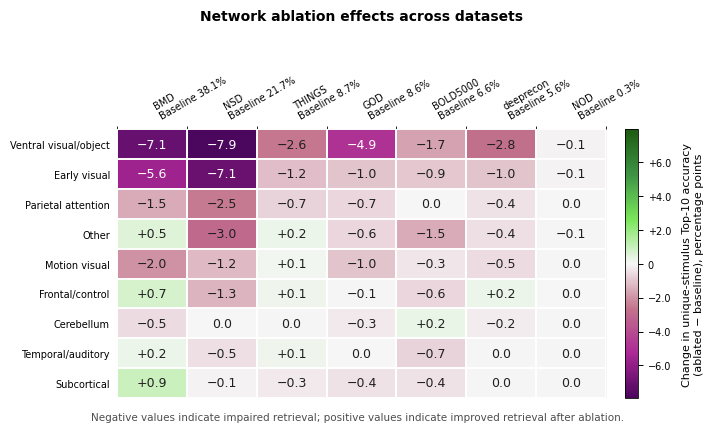

In [451]:
fig2_dataset_change_pivot = (
    plot_ablation_change_heatmap_with_baseline(
        drop_df=drop_by_dataset,
        row_col="ablation_name",
        col_col="dataset_name",
        value_col=DROP_METRIC,
        baseline_col=BASELINE_METRIC,
        row_order=network_order,
        col_order=DATASET_ORDER_ACTUAL,
        row_label_map=network_label_map,
        col_label_map=None,
        title="Network ablation effects across datasets",
        cbar_label=(
            "Change in unique-stimulus Top-10 accuracy\n"
            "(ablated − baseline), percentage points"
        ),
        save_path=(
            analysis5_fig_out
            / "fig2_network_by_dataset_signed_accuracy_change_top10.pdf"
        ),
        figsize=(
            max(7.2, 0.86 * len(DATASET_ORDER_ACTUAL)),
            4.3,
        ),
        annotate=True,
        rotate_xticks=30,
        robust_percentile=None,
    )
)

### Statistics for Fig. 3d,f (one-sided Wilcoxon signed-rank, Benjamini–Hochberg across nine groups)

In [452]:
# ============================================================
# Statistical testing setup
# ============================================================

import numpy as np
import pandas as pd

from scipy import stats
from scipy.stats import rankdata
from statsmodels.stats.multitest import multipletests


ALTERNATIVE = "greater"   # drop > 0; use "two-sided" if not pre-specified
FDR_ALPHA = 0.05
N_BOOTSTRAP = 20_000
RANDOM_SEED = 42


def infer_subject_column(df):
    candidates = [
        "subject_key",
        "subject_id",
        "subject_name",
        "subject",
    ]

    for column in candidates:
        if column in df.columns:
            return column

    raise KeyError(
        "Could not find a subject identifier. "
        f"Tried: {candidates}"
    )


subject_col = infer_subject_column(drop_by_subject)

subject_network_df = drop_by_subject.copy()

# Ensure subjects with the same name in different datasets remain distinct
subject_network_df["subject_uid"] = (
    subject_network_df["dataset_name"].astype(str)
    + "::"
    + subject_network_df[subject_col].astype(str)
)

subject_network_df["drop_pp"] = (
    subject_network_df[DROP_METRIC].astype(float) * SCALE
)

# Safeguard against duplicate subject × network rows
subject_network_df = (
    subject_network_df
    .groupby(
        [
            "subject_uid",
            "dataset_name",
            "ablation_name",
        ],
        as_index=False,
    )
    .agg(
        drop_pp=("drop_pp", "mean"),
        baseline_pp=(BASELINE_METRIC, lambda x: np.nanmean(x) * SCALE),
    )
)

subject_network_df = subject_network_df[
    np.isfinite(subject_network_df["drop_pp"])
].copy()

display(subject_network_df.head())

print("Number of subjects:", subject_network_df["subject_uid"].nunique())
print("Number of networks:", subject_network_df["ablation_name"].nunique())

,subject_uid,dataset_name,ablation_name,drop_pp,baseline_pp
0,BMD::BMD::sub-01,BMD,cerebellum,0.000000,44.901961
1,BMD::BMD::sub-01,BMD,early_visual,6.960784,44.901961
2,BMD::BMD::sub-01,BMD,frontal_control,-1.764706,44.901961
3,BMD::BMD::sub-01,BMD,motion_visual,2.156863,44.901961
4,BMD::BMD::sub-01,BMD,other,-1.176471,44.901961


Number of subjects: 63
Number of networks: 9


In [453]:
# ============================================================
# Per-network tests against zero
# ============================================================

def bootstrap_ci(
    values,
    statistic=np.mean,
    n_bootstrap=20_000,
    confidence=0.95,
    seed=42,
):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return np.nan, np.nan

    rng = np.random.default_rng(seed)

    bootstrap_indices = rng.integers(
        0,
        len(values),
        size=(n_bootstrap, len(values)),
    )

    bootstrap_values = values[bootstrap_indices]
    estimates = statistic(bootstrap_values, axis=1)

    alpha = 1.0 - confidence

    return (
        float(np.quantile(estimates, alpha / 2)),
        float(np.quantile(estimates, 1 - alpha / 2)),
    )


def signed_rank_biserial(values):
    """
    Signed-rank rank-biserial effect size.

    +1: all non-zero drops are positive
     0: balanced positive and negative ranks
    -1: all non-zero drops are negative
    """
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    values = values[values != 0]

    if len(values) == 0:
        return 0.0

    ranks = rankdata(np.abs(values))

    positive_rank_sum = ranks[values > 0].sum()
    negative_rank_sum = ranks[values < 0].sum()

    return float(
        (positive_rank_sum - negative_rank_sum)
        / (positive_rank_sum + negative_rank_sum)
    )


def significance_symbol(q):
    if not np.isfinite(q):
        return "NA"
    if q < 1e-4:
        return "****"
    if q < 1e-3:
        return "***"
    if q < 1e-2:
        return "**"
    if q < 0.05:
        return "*"
    return "ns"


def compute_network_drop_statistics(
    subject_network_df,
    network_order,
    alternative="greater",
    n_bootstrap=20_000,
    seed=42,
):
    rows = []

    for network_index, network in enumerate(network_order):
        values = (
            subject_network_df.loc[
                subject_network_df["ablation_name"] == network,
                "drop_pp",
            ]
            .dropna()
            .to_numpy(dtype=float)
        )

        n_subjects = len(values)
        n_nonzero = int(np.sum(values != 0))

        if n_nonzero == 0:
            wilcoxon_statistic = 0.0
            p_value = 1.0
        else:
            result = stats.wilcoxon(
                values,
                zero_method="wilcox",
                alternative=alternative,
                method="auto",
            )

            wilcoxon_statistic = float(result.statistic)
            p_value = float(result.pvalue)

        mean_ci_low, mean_ci_high = bootstrap_ci(
            values,
            statistic=np.mean,
            n_bootstrap=n_bootstrap,
            seed=seed + network_index,
        )

        median_ci_low, median_ci_high = bootstrap_ci(
            values,
            statistic=np.median,
            n_bootstrap=n_bootstrap,
            seed=seed + 100 + network_index,
        )

        rows.append({
            "ablation_name": network,
            "network_label": clean_ablation_name(network),
            "n_subjects": n_subjects,
            "n_positive": int(np.sum(values > 0)),
            "n_negative": int(np.sum(values < 0)),
            "n_zero": int(np.sum(values == 0)),
            "proportion_positive": float(np.mean(values > 0)),
            "mean_drop_pp": float(np.mean(values)),
            "mean_ci_low": mean_ci_low,
            "mean_ci_high": mean_ci_high,
            "median_drop_pp": float(np.median(values)),
            "median_ci_low": median_ci_low,
            "median_ci_high": median_ci_high,
            "wilcoxon_statistic": wilcoxon_statistic,
            "p_value": p_value,
            "rank_biserial": signed_rank_biserial(values),
        })

    result_df = pd.DataFrame(rows)

    reject, q_values, _, _ = multipletests(
        result_df["p_value"].values,
        alpha=FDR_ALPHA,
        method="fdr_bh",
    )

    result_df["q_value"] = q_values
    result_df["significant_fdr"] = reject
    result_df["significance"] = result_df["q_value"].map(
        significance_symbol
    )

    return result_df


network_drop_stats = compute_network_drop_statistics(
    subject_network_df=subject_network_df,
    network_order=network_order,
    alternative=ALTERNATIVE,
    n_bootstrap=N_BOOTSTRAP,
    seed=RANDOM_SEED,
)

display(
    network_drop_stats[
        [
            "network_label",
            "n_subjects",
            "mean_drop_pp",
            "mean_ci_low",
            "mean_ci_high",
            "median_drop_pp",
            "proportion_positive",
            "rank_biserial",
            "p_value",
            "q_value",
            "significance",
        ]
    ].round(4)
)

,network_label,n_subjects,mean_drop_pp,mean_ci_low,mean_ci_high,median_drop_pp,proportion_positive,rank_biserial,p_value,q_value,significance
0,Ventral visual/object,63,2.8922,2.0396,3.7854,1.0000,0.6508,0.9424,0.0000,0.0000,****
1,Early visual,63,2.0644,1.3671,2.8045,0.4435,0.6190,0.9514,0.0000,0.0000,****
2,Parietal attention,63,0.6606,0.4148,0.9286,0.1143,0.5397,0.8018,0.0000,0.0000,****
3,Other,63,0.4595,0.1797,0.7692,0.0000,0.4762,0.4425,0.0049,0.0088,**
4,Motion visual,63,0.5824,0.3731,0.8024,0.1667,0.5556,0.8383,0.0000,0.0000,****
5,Frontal/control,63,0.0660,-0.0916,0.2345,0.0000,0.2540,0.0939,0.3093,0.3479,ns
6,Cerebellum,63,0.0881,-0.0460,0.2149,0.0000,0.4127,0.2973,0.0486,0.0729,ns
7,Temporal/auditory,63,0.0550,-0.0371,0.1567,0.0000,0.3016,0.1337,0.2514,0.3232,ns
8,Subcortical,63,-0.0655,-0.1894,0.0494,0.0000,0.3333,-0.0240,0.5500,0.5500,ns


In [454]:
network_drop_stats.to_csv(
    analysis5_fig_out / "network_ablation_subject_level_statistics.csv",
    index=False,
)

In [455]:
# ============================================================
# Friedman repeated-measures omnibus test
# ============================================================

subject_network_pivot = subject_network_df.pivot_table(
    index="subject_uid",
    columns="ablation_name",
    values="drop_pp",
    aggfunc="mean",
)

subject_network_pivot = subject_network_pivot.reindex(
    columns=network_order
)

# Friedman requires complete observations across all networks
complete_subject_network_pivot = subject_network_pivot.dropna()

n_complete_subjects = len(complete_subject_network_pivot)
n_networks = len(network_order)

if n_complete_subjects < 2:
    raise RuntimeError(
        "Not enough subjects with complete observations across networks."
    )

friedman_result = stats.friedmanchisquare(
    *[
        complete_subject_network_pivot[network].values
        for network in network_order
    ]
)

friedman_chi2 = float(friedman_result.statistic)
friedman_p = float(friedman_result.pvalue)

# Kendall's W: omnibus repeated-measures effect size
kendalls_w = (
    friedman_chi2
    / (n_complete_subjects * (n_networks - 1))
)

print(f"Complete subjects: {n_complete_subjects}")
print(f"Networks: {n_networks}")
print(f"Friedman chi-square: {friedman_chi2:.3f}")
print(f"p-value: {friedman_p:.4g}")
print(f"Kendall's W: {kendalls_w:.3f}")

Complete subjects: 63
Networks: 9
Friedman chi-square: 135.396
p-value: 2.148e-25
Kendall's W: 0.269


In [456]:
# ============================================================
# Add significance labels to violin plot
# ============================================================

def add_network_significance_to_violin(
    ax,
    data,
    selected_networks,
    network_stats,
    show_q_values=False,
):
    stats_lookup = (
        network_stats
        .set_index("ablation_name")
        .to_dict("index")
    )

    current_ymin, current_ymax = ax.get_ylim()
    y_range = current_ymax - current_ymin

    annotation_positions = []

    for position, network, values in zip(
        range(len(selected_networks)),
        selected_networks,
        data,
    ):
        values = np.asarray(values, dtype=float)
        values = values[np.isfinite(values)]

        if len(values) == 0 or network not in stats_lookup:
            continue

        result = stats_lookup[network]
        q_value = result["q_value"]
        symbol = result["significance"]

        y_position = np.nanmax(values) + 0.055 * y_range
        annotation_positions.append(y_position)

        if show_q_values:
            if q_value < 0.001:
                label = f"{symbol}\nq<0.001"
            else:
                label = f"{symbol}\nq={q_value:.3f}"
        else:
            label = symbol

        ax.text(
            position,
            y_position,
            label,
            ha="center",
            va="bottom",
            fontsize=7,
            fontweight="bold",
            color="black",
            clip_on=False,
            zorder=10,
        )

    if annotation_positions:
        new_ymax = max(
            current_ymax,
            max(annotation_positions) + 0.10 * y_range,
        )
        ax.set_ylim(current_ymin, new_ymax)

### Fig. 3d — Global Top-10 accuracy after masking each ROI group

In [457]:
def plot_global_ablation_baseline_reference_clean_v2(
    drop_global,
    metric="unique_top10",
    drop_metric="unique_top10_drop",
    baseline_metric="baseline_unique_top10",
    network_order=None,
    save_path=None,
    figsize=(7.4, 4.5),
):
    set_publication_style()

    df = drop_global.copy()

    if network_order is None:
        network_order = (
            df.sort_values(drop_metric, ascending=False)["ablation_name"]
            .tolist()
        )

    df["ablation_name"] = pd.Categorical(
        df["ablation_name"],
        categories=network_order,
        ordered=True,
    )

    df = df.sort_values("ablation_name").reset_index(drop=True)

    labels = [clean_ablation_name(x) for x in df["ablation_name"].astype(str)]

    baseline = df[baseline_metric].values * 100.0
    ablated = df[metric].values * 100.0
    drop = df[drop_metric].values * 100.0

    # Global baseline (should be the same across rows)
    baseline_ref = float(np.nanmean(baseline))

    y = np.arange(len(df))

    xmin = np.nanmin(ablated) - 0.7
    xmax = baseline_ref + 1.7

    fig, ax = plt.subplots(figsize=figsize)

    # Horizontal connectors
    for i in range(len(df)):
        ax.plot(
            [ablated[i], baseline_ref],
            [y[i], y[i]],
            color="0.72",
            linewidth=1.4,
            solid_capstyle="round",
            zorder=1,
        )

    # Baseline reference line
    ax.axvline(
        baseline_ref,
        color="black",
        linewidth=1.0,
        linestyle="--",
        zorder=2,
    )

    # Ablated points
    ax.scatter(
        ablated,
        y,
        s=48,
        facecolor="black",
        edgecolor="white",
        linewidth=0.5,
        zorder=4,
    )

    # Right-side drop column
    drop_x = baseline_ref + 0.55
    stats_lookup = (
        network_drop_stats
        .set_index("ablation_name")["significance"]
        .to_dict()
    )
    for i in range(len(df)):
        network = str(df.loc[i, "ablation_name"])
        significance = stats_lookup.get(network, "")

        drop_txt = (
            f"−{drop[i]:.1f} {significance}"
            if drop[i] >= 0
            else f"+{abs(drop[i]):.1f} {significance}"
        )

        ax.text(
            drop_x,
            y[i],
            drop_txt,
            ha="left",
            va="center",
            fontsize=7.5,
            color="0.25",
            zorder=5,
    )
    # Baseline header above dashed line
    ax.text(
        baseline_ref,
        1.02,
        f"Baseline\n{baseline_ref:.1f}%",
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=8,
        fontweight="bold",
        clip_on=False,
    )

    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()

    ax.set_xlim(xmin, xmax)

    ax.set_xlabel("Unique-stimulus Top-10 retrieval accuracy (%)")

    # Title + subtitle separated cleanly
    ax.set_title(
        "Network ablation reduces retrieval relative to baseline",
        pad=28,
        fontsize=10,
        fontweight="bold",
    )

    # fig.text(
    #     0.5,
    #     0.91,
    #     "Each point shows ablated performance; dashed line indicates the global baseline.",
    #     ha="center",
    #     va="center",
    #     fontsize=8,
    #     color="0.25",
    # )

    ax.grid(axis="x", linewidth=0.35, alpha=0.25)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # More room for long labels and top annotations
    fig.subplots_adjust(
        left=0.31,
        right=0.86,
        top=0.82,
        bottom=0.16,
    )

    if save_path is not None:
        save_pdf(fig, save_path)

    plt.show()

    return df

Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/fig1_global_network_ablation_baseline_reference_CLEAN_v2.pdf


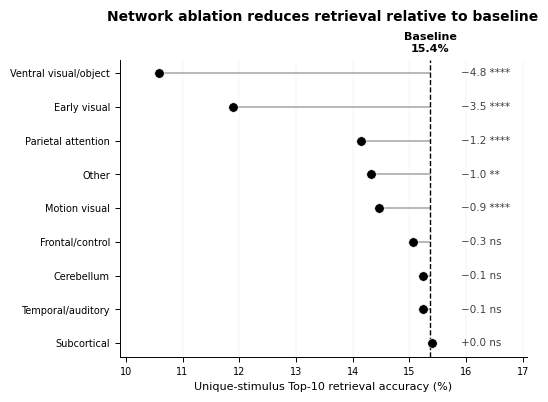

In [458]:
fig1_clean_df = plot_global_ablation_baseline_reference_clean_v2(
    drop_global=drop_global,
    network_order=network_order,
    save_path=analysis5_fig_out / "fig1_global_network_ablation_baseline_reference_CLEAN_v2.pdf",
    figsize=(7.4, 4.5),
)

### Fig. 3f — Participant-level effects for the four most disruptive groups

In [589]:
# ============================================================
# Figure 3A: Subject-level drop distributions for top 4 networks
# Violin + box + subject points
# ============================================================

DATASET_COLORS = {
    "BMD": "#0072B2",
    "NSD": "#D55E00",
    "THINGS": "#009E73",
    "GOD": "#CC79A7",
    "BOLD5000": "#E69F00",
    "deeprecon": "#56B4E9",
    "NOD": "#4D4D4D",
    "HAD": "#999933",
}


# ============================================================
# Subject-level change distributions
# Negative = ablation reduced retrieval
# Positive = ablation improved retrieval
# ============================================================

from matplotlib.ticker import FuncFormatter


def signed_tick_formatter(value, position):
    """Display positive ticks with + and use a true minus sign."""
    if np.isclose(value, 0):
        return "0"

    return f"{value:+.0f}".replace("-", "−")


def plot_subject_change_violin_box(
    drop_by_subject,
    network_order,
    top_n_networks=4,
    drop_col=DROP_METRIC,
    baseline_col=BASELINE_METRIC,
    save_path=None,
):
    set_publication_style()

    selected_networks = network_order[:top_n_networks]

    df = drop_by_subject[
        drop_by_subject["ablation_name"].isin(selected_networks)
    ].copy()

    # --------------------------------------------------------
    # Sign convention
    #
    # Stored drop:
    #   baseline - ablated
    #   positive = retrieval became worse
    #
    # Plotted change:
    #   ablated - baseline
    #   negative = retrieval became worse
    #   positive = retrieval improved
    # --------------------------------------------------------
    df["change_pp"] = -df[drop_col].astype(float) * SCALE
    df["baseline_pp"] = df[baseline_col].astype(float) * SCALE

    positions = np.arange(len(selected_networks))

    data = [
        df.loc[
            df["ablation_name"] == network,
            "change_pp",
        ].dropna().values
        for network in selected_networks
    ]

    baseline_means = [
        df.loc[
            df["ablation_name"] == network,
            "baseline_pp",
        ].mean()
        for network in selected_networks
    ]

    fig, ax = plt.subplots(figsize=(6.6, 3.7))

    # Violin distributions
    parts = ax.violinplot(
        data,
        positions=positions,
        widths=0.72,
        showmeans=False,
        showmedians=False,
        showextrema=False,
    )

    for body in parts["bodies"]:
        body.set_facecolor("0.78")
        body.set_edgecolor("black")
        body.set_linewidth(0.6)
        body.set_alpha(0.85)

    # Boxplot overlay
    ax.boxplot(
        data,
        positions=positions,
        widths=0.20,
        patch_artist=True,
        showfliers=False,
        medianprops=dict(
            color="black",
            linewidth=1.2,
        ),
        boxprops=dict(
            facecolor="white",
            edgecolor="black",
            linewidth=0.8,
        ),
        whiskerprops=dict(
            color="black",
            linewidth=0.8,
        ),
        capprops=dict(
            color="black",
            linewidth=0.8,
        ),
    )

    # Subject points colored by dataset
    rng = np.random.default_rng(2)

    for position, network in zip(positions, selected_networks):
        group = df[
            df["ablation_name"] == network
        ].copy()

        jitter = rng.normal(
            0,
            0.055,
            size=len(group),
        )

        x_values = position + jitter

        colors = [
            DATASET_COLORS.get(dataset, "0.35")
            for dataset in group["dataset_name"].values
        ]

        ax.scatter(
            x_values,
            group["change_pp"].values,
            s=12,
            c=colors,
            edgecolor="white",
            linewidth=0.25,
            alpha=0.72,
            zorder=4,
        )

    # Zero-change reference
    ax.axhline(
        0,
        color="black",
        linewidth=0.7,
        linestyle="--",
        alpha=0.65,
    )

    # Mean markers
    means = [
        np.nanmean(values)
        for values in data
    ]

    ax.scatter(
        positions,
        means,
        s=42,
        facecolor="black",
        edgecolor="white",
        linewidth=0.6,
        zorder=6,
        label="Mean change",
    )

    # Significance annotations
    add_network_significance_to_violin(
        ax=ax,
        data=data,
        selected_networks=selected_networks,
        network_stats=network_drop_stats,
        show_q_values=False,
    )

    # X labels with mean subject baseline
    xlabels = [
        (
            f"{clean_ablation_name(network)}"
            
        )
        for network, baseline in zip(
            selected_networks,
            baseline_means,
        )
    ]

    ax.set_xticks(positions)
    ax.set_xticklabels(
        xlabels,
        rotation=25,
        ha="right",
    )

    ax.set_ylabel(
        "Change in unique-stimulus Top-10 accuracy\n"
        "from baseline, percentage points"
    )

    ax.set_title(
        "Subject-level impact of ablating the most disruptive networks"
    )

    # Explicit + signs for improvements
    ax.yaxis.set_major_formatter(
        FuncFormatter(signed_tick_formatter)
    )

    ax.grid(
        axis="y",
        linewidth=0.35,
        alpha=0.25,
    )
    ax.set_axisbelow(True)

    # Dataset legend
    present_datasets = [
        dataset
        for dataset in DATASET_ORDER_ACTUAL
        if dataset in df["dataset_name"].unique()
    ]

    handles = [
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="none",
            markerfacecolor=DATASET_COLORS.get(dataset, "0.35"),
            markeredgecolor="white",
            markeredgewidth=0.3,
            markersize=5,
            label=dataset,
        )
        for dataset in present_datasets
    ]

    ax.legend(
        handles=handles,
        frameon=False,
        loc="upper left",
        bbox_to_anchor=(1.01, 1.0),
        title="Dataset",
        title_fontsize=8,
    )

    fig.tight_layout()

    if save_path is not None:
        save_pdf(fig, save_path)

    plt.show()

    return df

Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/fig3_subject_accuracy_change_violin_box_top4_networks.pdf


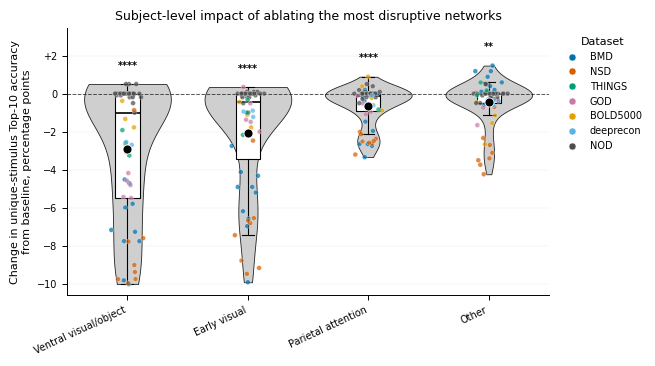

In [590]:
fig3_subject_change_df = plot_subject_change_violin_box(
    drop_by_subject=drop_by_subject,
    network_order=network_order,
    top_n_networks=4,
    save_path=(
        analysis5_fig_out
        / "fig3_subject_accuracy_change_violin_box_top4_networks.pdf"
    ),
)

---
## Figure 4 — CLIP-space semantic organization and category-associated attribution patterns

### Fig. 4a–c — Identity and semantic margins

In [461]:
# [retrieval-ranked cluster colours]
# ============================================================
# Ordered semantic-cluster spectrum
#
# Colour follows RETRIEVAL ORDER, not cluster number.
#
# First cluster  -> strong/deep blue
# Middle         -> cyan -> green -> yellow -> orange
# Last cluster   -> darkest red
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from matplotlib.colors import LinearSegmentedColormap


# ============================================================
# 1. Retrieval-ranked cluster order
# ============================================================

CLUSTER_RETRIEVAL_ORDER = [
    7, 0, 6, 30, 33, 14, 2, 21, 4, 17,
    39, 24, 36, 8, 26, 27, 22, 1, 34, 19,
    18, 9, 5, 28, 35, 16, 31, 12, 23, 15,
    29, 20, 25, 3, 37, 10, 11, 13, 32, 38,
]

assert len(CLUSTER_RETRIEVAL_ORDER) == 40
assert set(CLUSTER_RETRIEVAL_ORDER) == set(range(40))


# ============================================================
# 2. Custom blue -> red spectrum
#
# Designed so:
#   rank 1  = saturated/deep blue
#   early   = progressively lighter blue/cyan
#   middle  = green/yellow
#   late    = orange/red
#   rank 40 = very dark red
# ============================================================

SPECTRUM_ANCHORS = [
    "#08306B",  # deep saturated blue
    "#1558A6",  # royal blue
    "#2C7FB8",  # medium blue
    "#41B6C4",  # cyan
    "#1FA187",  # teal
    "#4AC16D",  # green
    "#A0DA39",  # yellow-green
    "#F6E620",  # yellow
    "#FDAE32",  # orange-yellow
    "#F46D43",  # orange-red
    "#D73027",  # red
    "#A50026",  # deep crimson
    "#67001F",  # darkest red
]


cluster_spectrum_cmap = LinearSegmentedColormap.from_list(
    "cluster_retrieval_blue_to_red",
    SPECTRUM_ANCHORS,
    N=4096,
)


# ============================================================
# 3. Sample exactly 40 colours
# ============================================================

spectrum_positions = np.linspace(
    0.0,
    1.0,
    len(CLUSTER_RETRIEVAL_ORDER),
)

rank_colors_rgba = cluster_spectrum_cmap(
    spectrum_positions
)

rank_colors_hex = [
    mcolors.to_hex(color)
    for color in rank_colors_rgba
]


# ============================================================
# 4. Assign colours according to retrieval rank
# ============================================================

ALL_CLUSTER_COLORS = {
    cluster_id: color
    for cluster_id, color
    in zip(
        CLUSTER_RETRIEVAL_ORDER,
        rank_colors_hex,
    )
}


# ============================================================
# 5. Preserve your previous MANUAL / EXTRA dictionary structure
# ============================================================

MAIN_TEXT_CLUSTER_IDS = [
    7,
    33,
    4,
    36,
    22,
    18,
    35,
    23,
    25,
    11,
]


MANUAL_CLUSTER_COLORS = {
    cluster_id: ALL_CLUSTER_COLORS[
        cluster_id
    ]
    for cluster_id
    in MAIN_TEXT_CLUSTER_IDS
}


EXTRA_CLUSTER_COLORS = {
    cluster_id: ALL_CLUSTER_COLORS[
        cluster_id
    ]
    for cluster_id
    in range(40)
    if cluster_id
    not in MAIN_TEXT_CLUSTER_IDS
}


# ============================================================
# 6. Sanity checks
# ============================================================

assert len(ALL_CLUSTER_COLORS) == 40
assert len(MANUAL_CLUSTER_COLORS) == 10
assert len(EXTRA_CLUSTER_COLORS) == 30

print(
    "First-ranked cluster:",
    CLUSTER_RETRIEVAL_ORDER[0],
    ALL_CLUSTER_COLORS[
        CLUSTER_RETRIEVAL_ORDER[0]
    ],
)

print(
    "Last-ranked cluster:",
    CLUSTER_RETRIEVAL_ORDER[-1],
    ALL_CLUSTER_COLORS[
        CLUSTER_RETRIEVAL_ORDER[-1]
    ],
)

First-ranked cluster: 7 #08306b
Last-ranked cluster: 38 #67001f


In [462]:
# ============================================================
# CELL 1
# Appendix analysis for ALL 40 semantic clusters
# Imports, output paths, semantic names, and colours
# ============================================================

from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Circle

from PIL import Image


# ============================================================
# Output directory
# ============================================================

appendix40_out = (
    Path(analysis2_out)
    / "appendix_all40_semantic_clusters"
)

appendix40_out.mkdir(
    parents=True,
    exist_ok=True,
)

print("Appendix output:", appendix40_out)


# ============================================================
# Publication plotting style
# ============================================================

plt.rcParams.update({
    "font.family": [
        "Arial",
        "Helvetica",
        "DejaVu Sans",
    ],
    "font.size": 8.5,
    "axes.titlesize": 10.5,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 7.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


# ============================================================
# Dataset colours
# Keep exactly consistent with the main-text figures
# ============================================================

DATASET_COLORS_CLEAN = {
    "BMD": "#0072B2",
    "NSD": "#D55E00",
    "THINGS": "#009E73",
    "GOD": "#CC79A7",
    "BOLD5000": "#E69F00",
    "deeprecon": "#56B4E9",
    "NOD": "#4D4D4D",
    "HAD": "#999933",
}


DATASET_ORDER = [
    "BMD",
    "NSD",
    "THINGS",
    "GOD",
    "BOLD5000",
    "deeprecon",
    "NOD",
    "HAD",
]


# ============================================================
# Semantic names for ALL 40 clusters
#
# Existing 10 names are retained exactly.
# New names are manually assigned from the representative
# samples in semantic_clusters_representative_images_all.pdf
# ============================================================

ALL_CLUSTER_NAMES = {
    0:  "Mountain landscapes",
    1:  "Bathrooms & washrooms",
    2:  "Dogs",
    3:  "Clocks & timers",
    4:  "Sharks & marine life",
    5:  "Wooden furniture",
    6:  "Soups & hot beverages",
    7:  "People & portraits",
    8:  "Stone bridges & viaducts",
    9:  "Coastal landscapes",
    10: "Insects",
    11: "Home appliances",
    12: "Textile accessories",
    13: "Household containers & bins",
    14: "Snakes",
    15: "Sailboats & sailing",
    16: "Buses & trucks",
    17: "Airplanes & aviation",
    18: "Water towers",
    19: "Shorebirds & wading birds",
    20: "Structural details & patterns",
    21: "Baseball",
    22: "Trains & rail transport",
    23: "Emergency vehicles",
    24: "Bridges & urban infrastructure",
    25: "Religious architecture",
    26: "Libraries & auditoriums",
    27: "Zebras",
    28: "Ceramics & tableware",
    29: "Flowers",
    30: "Skiing & snow sports",
    31: "Classic vehicles",
    32: "Toiletries & personal care",
    33: "Tennis action",
    34: "Citrus & fruit",
    35: "Rural fields",
    36: "Consumer electronics",
    37: "Tools & hardware",
    38: "Books, plaques & instruments",
    39: "Birds",
}


# ============================================================
# Original colours for the 10 main-text clusters
# DO NOT CHANGE
# ============================================================

# MANUAL_CLUSTER_COLORS = {
#     7:  "#8E1B3A",   # deep cranberry
#     33: "#660B9E",   # deep purple
#     4:  "#00897B",   # dark teal
#     36: "#D32F2F",   # vivid red
#     22: "#9C8DB5",   # lavender purple
#     18: "#8D6E63",   # warm brown
#     35: "#EC407A",   # saturated rose
#     23: "#4A2CD2",   # indigo-violet
#     25: "#C0CA33",   # yellow-lime
#     11: "#26C6DA",   # cyan
# }


# # ============================================================
# # Additional fixed colours for the other 30 clusters
# # ============================================================

# EXTRA_CLUSTER_COLORS = {
#     0:  "#355070",
#     1:  "#E56B6F",
#     2:  "#6A994E",
#     3:  "#B08900",
#     5:  "#A44A3F",
#     6:  "#F4A261",
#     8:  "#577590",
#     9:  "#277DA1",
#     10: "#43AA8B",
#     12: "#F8961E",
#     13: "#90BE6D",
#     14: "#2A9D8F",
#     15: "#1D4E89",
#     16: "#E76F51",
#     17: "#5E60CE",
#     19: "#4D908E",
#     20: "#6C757D",
#     21: "#C44536",
#     24: "#264653",
#     26: "#9B5DE5",
#     27: "#F3722C",
#     28: "#00A896",
#     29: "#F94144",
#     30: "#00B4D8",
#     31: "#8D99AE",
#     32: "#FF6B6B",
#     34: "#F9C74F",
#     37: "#386641",
#     38: "#A47148",
#     39: "#3A86FF",
# }






# Combine while ensuring the original 10 take precedence
ALL_CLUSTER_COLORS = {
    **EXTRA_CLUSTER_COLORS,
    **MANUAL_CLUSTER_COLORS,
}


# ============================================================
# Sanity checks
# ============================================================

assert set(ALL_CLUSTER_NAMES.keys()) == set(range(40))
assert set(ALL_CLUSTER_COLORS.keys()) == set(range(40))

assert len(set(ALL_CLUSTER_COLORS.values())) == 40, (
    "Duplicate cluster colours detected."
)

print("Number of cluster names:", len(ALL_CLUSTER_NAMES))
print("Number of cluster colours:", len(ALL_CLUSTER_COLORS))


# ============================================================
# Compact display labels
# ============================================================

ALL_CLUSTER_LABELS = {
    cid: f"{ALL_CLUSTER_NAMES[cid]} (C{cid})"
    for cid in range(40)
}

for cid in range(40):
    print(
        f"C{cid:02d}: "
        f"{ALL_CLUSTER_NAMES[cid]:35s} "
        f"{ALL_CLUSTER_COLORS[cid]}"
    )

Appendix output: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_2_semantic_clusters/appendix_all40_semantic_clusters
Number of cluster names: 40
Number of cluster colours: 40
C00: Mountain landscapes                 #0c3c7d
C01: Bathrooms & washrooms               #5ec761
C02: Dogs                                #2879b5
C03: Clocks & timers                     #cf2927
C04: Sharks & marine life                #3698be
C05: Wooden furniture                    #e2e326
C06: Soups & hot beverages               #10498f
C07: People & portraits                  #08306b
C08: Stone bridges & viaducts            #1fa187
C09: Coastal landscapes                  #c8e02d
C10: Insects                             #b10b26
C11: Home appliances                     #a00025
C12: Textile accessories                 #fa9a37
C13: Household containers & bins         #8d0023
C14: Snakes                              #216db0
C15: Sailboats & sailing                 #f57242
C16

In [463]:
# ============================================================
# CELL 2
# Validate objects and build master cluster metadata table
# ============================================================

required_objects = {
    "unique_stimulus_df": unique_stimulus_df,
    "cluster_summary": cluster_summary,
    "cluster_examples_df": cluster_examples_df,
}

for object_name, obj in required_objects.items():
    if obj is None:
        raise RuntimeError(
            f"{object_name} is not available."
        )


# ============================================================
# Ensure integer cluster IDs
# ============================================================

unique_stimulus_df = unique_stimulus_df.copy()
unique_stimulus_df["semantic_cluster"] = (
    unique_stimulus_df["semantic_cluster"]
    .astype(int)
)

cluster_summary = cluster_summary.copy()
cluster_summary["semantic_cluster"] = (
    cluster_summary["semantic_cluster"]
    .astype(int)
)

cluster_examples_df = cluster_examples_df.copy()
cluster_examples_df["semantic_cluster"] = (
    cluster_examples_df["semantic_cluster"]
    .astype(int)
)


# ============================================================
# Confirm all 40 clusters exist
# ============================================================

observed_clusters = sorted(
    unique_stimulus_df[
        "semantic_cluster"
    ].unique()
)

print("Observed cluster IDs:")
print(observed_clusters)

assert observed_clusters == list(range(40)), (
    "Expected semantic clusters 0-39."
)


# ============================================================
# Retrieval ranking
# ============================================================

METRIC_FOR_SELECTION = "unique_stimulus_top10"

cluster_summary_sorted = (
    cluster_summary
    .copy()
    .sort_values(
        METRIC_FOR_SELECTION,
        ascending=False,
    )
    .reset_index(drop=True)
)

cluster_summary_sorted[
    "retrieval_rank"
] = np.arange(
    1,
    len(cluster_summary_sorted) + 1,
)


# ============================================================
# Add semantic names and colours
# ============================================================

cluster_summary_sorted["cluster_name"] = (
    cluster_summary_sorted[
        "semantic_cluster"
    ].map(ALL_CLUSTER_NAMES)
)

cluster_summary_sorted["cluster_color"] = (
    cluster_summary_sorted[
        "semantic_cluster"
    ].map(ALL_CLUSTER_COLORS)
)

cluster_summary_sorted["cluster_label"] = (
    cluster_summary_sorted.apply(
        lambda row: (
            f"{row['cluster_name']} "
            f"(C{int(row['semantic_cluster'])})"
        ),
        axis=1,
    )
)


# ============================================================
# Useful cluster orders
# ============================================================

ALL_CLUSTER_IDS_BY_ID = list(range(40))

ALL_CLUSTER_IDS_BY_RETRIEVAL = (
    cluster_summary_sorted[
        "semantic_cluster"
    ]
    .astype(int)
    .tolist()
)


# ============================================================
# Lookup dictionaries with rank information
# ============================================================

ALL_CLUSTER_INFO_WITH_RANK = {}

for _, row in cluster_summary_sorted.iterrows():

    cid = int(
        row["semantic_cluster"]
    )

    rank = int(
        row["retrieval_rank"]
    )

    acc = float(
        row[METRIC_FOR_SELECTION]
    )

    ALL_CLUSTER_INFO_WITH_RANK[cid] = (
        f"{ALL_CLUSTER_NAMES[cid]} "
        f"(C{cid}, rank {rank}, "
        f"Top-10={acc:.3f})"
    )


# ============================================================
# Save master table
# ============================================================

cluster_summary_sorted.to_csv(
    appendix40_out
    / "all40_cluster_master_summary.csv",
    index=False,
)


display(
    cluster_summary_sorted[
        [
            "retrieval_rank",
            "semantic_cluster",
            "cluster_name",
            METRIC_FOR_SELECTION,
            "n_unique_stimuli",
            "n_queries",
        ]
    ]
)

print(
    "\nRetrieval-ranked cluster IDs:"
)

print(
    ALL_CLUSTER_IDS_BY_RETRIEVAL
)

Observed cluster IDs:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39)]


,retrieval_rank,semantic_cluster,cluster_name,unique_stimulus_top10,n_unique_stimuli,n_queries
0,1,7,People & portraits,0.332543,390,7172
1,2,0,Mountain landscapes,0.324183,251,765
2,3,6,Soups & hot beverages,0.289017,373,2768
3,4,30,Skiing & snow sports,0.255308,291,5511
4,5,33,Tennis action,0.244969,226,1143
5,6,14,Snakes,0.226351,166,592
6,7,2,Dogs,0.225164,259,3815
7,8,21,Baseball,0.220738,186,1273
8,9,4,Sharks & marine life,0.186396,308,1132
9,10,17,Airplanes & aviation,0.172212,273,1713



Retrieval-ranked cluster IDs:
[7, 0, 6, 30, 33, 14, 2, 21, 4, 17, 39, 24, 36, 8, 26, 27, 22, 1, 34, 19, 18, 9, 5, 28, 35, 16, 31, 12, 23, 15, 29, 20, 25, 3, 37, 10, 11, 13, 32, 38]


In [464]:
# ============================================================
# Configuration
# ============================================================

selected_clusters = [4,7,11,18,22,23,25,33,35,36]

geometry_out = (
    Path(analysis5_fig_out)
    / "embedding_geometry"
)

geometry_out.mkdir(
    parents=True,
    exist_ok=True,
)

GEOMETRY_RANDOM_SEED = 42

# Permutation test for correspondence between the two matrices
N_GEOMETRY_PERMUTATIONS = 20_000

# Stimulus-level bootstrap confidence intervals
N_GEOMETRY_BOOTSTRAPS = 2_000

# The same 10 clusters used in the saliency and ablation figures
selected_clusters_geometry = [
    int(cluster_id)
    for cluster_id in selected_clusters
]

print(
    "Selected clusters:",
    selected_clusters_geometry,
)

Selected clusters: [4, 7, 11, 18, 22, 23, 25, 33, 35, 36]


In [465]:
# Work on a copy
unique_cluster_df = unique_stimulus_df.copy().reset_index(drop=True)

# Reattach the k-means labels if the column is absent
if "semantic_cluster" not in unique_cluster_df.columns:
    if len(unique_cluster_df) != len(cluster_labels):
        raise RuntimeError(
            f"unique_stimulus_df has {len(unique_cluster_df)} rows, "
            f"but cluster_labels has {len(cluster_labels)} values."
        )

    unique_cluster_df["semantic_cluster"] = cluster_labels.astype(int)

# Check that each stimulus has only one cluster
cluster_nunique = (
    unique_cluster_df
    .groupby("stimulus_id")["semantic_cluster"]
    .nunique()
)

if (cluster_nunique > 1).any():
    raise RuntimeError("Some stimulus IDs are assigned to multiple clusters.")

# Build mapping
stimulus_id_to_cluster = (
    unique_cluster_df
    .drop_duplicates("stimulus_id")
    .set_index("stimulus_id")["semantic_cluster"]
    .astype(int)
    .to_dict()
)

# Check coverage of the retrieval metadata
mapped_clusters = baseline_metadata_df["stimulus_id"].map(
    stimulus_id_to_cluster
)

print("Mapping size:", len(stimulus_id_to_cluster))
print("Metadata rows mapped:", mapped_clusters.notna().sum())
print("Metadata rows missing:", mapped_clusters.isna().sum())
print(
    "Unique stimuli missing:",
    baseline_metadata_df.loc[
        mapped_clusters.isna(),
        "stimulus_id",
    ].nunique()
)

Mapping size: 12819
Metadata rows mapped: 65395
Metadata rows missing: 0
Unique stimuli missing: 0


In [466]:
# ============================================================
# CELL 1
# DIRECT BRAIN-SPACE RSA / CKA
#
# Goals:
#
# 1. Diagnose raw brain-embedding anisotropy
#
# 2. Construct a brain-only semantic RDM after removing
#    the global common embedding direction
#
# 3. Estimate cluster-pair geometry directly from
#    stimulus-to-stimulus brain similarities
#
# 4. Visualise the resulting 40-cluster brain geometry
#
# 5. Quantify cross-subject representation consistency
#    within each cluster using linear CKA
# ============================================================

from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from scipy.stats import (
    spearmanr,
    pearsonr,
    wilcoxon,
)

from scipy.cluster.hierarchy import (
    linkage,
    dendrogram,
)

from scipy.spatial.distance import (
    squareform,
)

from matplotlib.colors import (
    TwoSlopeNorm,
)


# ============================================================
# Output
# ============================================================

brain_rsa_out = (
    Path(analysis5_out)
    / "brain_only_rsa_cka"
)

brain_rsa_out.mkdir(
    parents=True,
    exist_ok=True,
)


brain_rsa_fig_out = (
    Path(analysis5_fig_out)
    / "brain_only_rsa_cka"
)

brain_rsa_fig_out.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# Cluster ordering
# ============================================================

CLUSTER_RETRIEVAL_ORDER = [
    7, 0, 6, 30, 33, 14, 2, 21, 4, 17,
    39, 24, 36, 8, 26, 27, 22, 1, 34, 19,
    18, 9, 5, 28, 35, 16, 31, 12, 23, 15,
    29, 20, 25, 3, 37, 10, 11, 13, 32, 38,
]

assert len(CLUSTER_RETRIEVAL_ORDER) == 40
assert set(CLUSTER_RETRIEVAL_ORDER) == set(range(40))


# ============================================================
# Cluster labels
# ============================================================

CLUSTER_NAME_MAP = {
    0:  "Mountains & landscapes",
    1:  "Bathrooms & interiors",
    2:  "Dogs",
    3:  "Clocks & gauges",
    4:  "Sharks & marine life",
    5:  "Wooden furniture",
    6:  "Bowls & drinks",
    7:  "People & portraits",
    8:  "Stone arches & ruins",
    9:  "Coasts & oceans",
    10: "Insects",
    11: "Home appliances",
    12: "Bags & textiles",
    13: "Containers & boxes",
    14: "Reptiles & frogs",
    15: "Sailboats",
    16: "Buses",
    17: "Airplanes",
    18: "Water towers",
    19: "Shore birds",
    20: "Architectural details",
    21: "Baseball",
    22: "Trains & rail transport",
    23: "Emergency vehicles",
    24: "Bridges",
    25: "Religious architecture",
    26: "Libraries & theatres",
    27: "Zebras",
    28: "Cups & jugs",
    29: "Flowers",
    30: "Skiing",
    31: "Cars & trucks",
    32: "Toiletries & bottles",
    33: "Tennis action",
    34: "Fruits",
    35: "Rural fields",
    36: "Consumer electronics",
    37: "Tools & hardware",
    38: "Books & artifacts",
    39: "Birds",
}


# ============================================================
# Colours
# ============================================================

assert "ALL_CLUSTER_COLORS" in globals()

CLUSTER_COLORS_BRAIN_RSA = {
    cluster_id:
        ALL_CLUSTER_COLORS[
            cluster_id
        ]

    for cluster_id
    in range(40)
}


# ============================================================
# Configuration
# ============================================================

BRAIN_RSA_SEED = 42

# Pairwise stimulus similarities are calculated blockwise,
# so there is no need to construct a 12,819 × 12,819 matrix.
PAIRWISE_BLOCK_SIZE = 512

# For the diagnostic plot only
N_DIAGNOSTIC_RANDOM_PAIRS = 100_000

# CKA
MIN_SHARED_STIMULI_CKA = 10

# To avoid subject pairs with thousands of shared stimuli
# dominating purely because of sample count.
MAX_SHARED_STIMULI_CKA = 500

N_CKA_BOOTSTRAPS = 5000


# ============================================================
# Publication style
# ============================================================

mpl.rcParams.update({
    "font.family": [
        "Arial",
        "Helvetica",
        "DejaVu Sans",
    ],
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print("Output:", brain_rsa_out)

Output: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/brain_only_rsa_cka


In [467]:
# ============================================================
# HIERARCHICAL CROSS-MODAL SIMILARITY — STEP 1
#
# Prepare:
#   - one normalized brain embedding per query
#   - one normalized CLIP embedding per unique stimulus
#   - matched candidate index for each query
#   - semantic-cluster labels
#
# Queries:
#   Only samples belonging to the 10 highlighted clusters
#
# Candidate pool:
#   All unique stimuli across all 40 clusters
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Helpers
# ------------------------------------------------------------

def to_numpy_safe(x):
    if hasattr(x, "detach"):
        return x.detach().cpu().numpy()

    if hasattr(x, "cpu"):
        return x.cpu().numpy()

    return np.asarray(x)


def normalize_rows(x, eps=1e-12):
    x = np.asarray(x, dtype=np.float32)

    return x / (
        np.linalg.norm(
            x,
            axis=1,
            keepdims=True,
        )
        + eps
    )


# ------------------------------------------------------------
# 2. Selected semantic clusters
# ------------------------------------------------------------

if "selected_clusters_geometry" in globals():
    selected_clusters_hierarchy = [
        int(cluster_id)
        for cluster_id in selected_clusters_geometry
    ]

elif "selected_clusters" in globals():
    selected_clusters_hierarchy = [
        int(cluster_id)
        for cluster_id in selected_clusters
    ]

else:
    selected_clusters_hierarchy = [
        7,   # People & portraits
        33,  # Tennis action
        4,   # Sharks & marine life
        36,  # Consumer electronics
        22,  # Trains & rail transport
        18,  # Water towers
        35,  # Rural fields
        23,  # Emergency vehicles
        25,  # Religious architecture
        11,  # Home appliances
    ]


# ------------------------------------------------------------
# 3. Prepare row-level metadata and embeddings
# ------------------------------------------------------------

hierarchy_metadata_all = (
    baseline_metadata_df
    .copy()
    .reset_index(drop=True)
)

hierarchy_metadata_all["semantic_cluster"] = (
    hierarchy_metadata_all["stimulus_id"]
    .map(stimulus_id_to_cluster)
)

if hierarchy_metadata_all["semantic_cluster"].isna().any():
    raise RuntimeError(
        "Some stimuli could not be mapped to semantic clusters."
    )

hierarchy_metadata_all["semantic_cluster"] = (
    hierarchy_metadata_all["semantic_cluster"]
    .astype(int)
)


brain_all = normalize_rows(
    to_numpy_safe(baseline_brain)
)

clip_all = normalize_rows(
    to_numpy_safe(baseline_clip)
)


if not (
    len(hierarchy_metadata_all)
    == len(brain_all)
    == len(clip_all)
):
    raise RuntimeError(
        "Metadata, brain embeddings, and CLIP embeddings "
        "have different numbers of rows."
    )


# ------------------------------------------------------------
# 4. Build one CLIP embedding per unique stimulus
#
# Repeated CLIP rows for the same stimulus are averaged and
# then renormalized.
# ------------------------------------------------------------

candidate_rows = []
candidate_clip_embeddings = []

for stimulus_id, group in hierarchy_metadata_all.groupby(
    "stimulus_id",
    sort=False,
):
    row_indices = group.index.to_numpy(dtype=int)

    mean_clip = clip_all[
        row_indices
    ].mean(axis=0)

    mean_clip = mean_clip / (
        np.linalg.norm(mean_clip) + 1e-12
    )

    candidate_rows.append({
        "stimulus_id": stimulus_id,
        "stimulus_clean": group[
            "stimulus_clean"
        ].iloc[0],
        "semantic_cluster": int(
            group["semantic_cluster"].iloc[0]
        ),
        "dataset_name": group[
            "dataset_name"
        ].iloc[0],
        "n_repetitions": len(row_indices),
    })

    candidate_clip_embeddings.append(
        mean_clip
    )


candidate_metadata = pd.DataFrame(
    candidate_rows
).reset_index(drop=True)

candidate_clip_embeddings = np.stack(
    candidate_clip_embeddings,
    axis=0,
).astype(np.float32)


# ------------------------------------------------------------
# 5. Map stimulus IDs to candidate indices
# ------------------------------------------------------------

stimulus_id_to_candidate_index = {
    stimulus_id: candidate_index
    for candidate_index, stimulus_id
    in enumerate(
        candidate_metadata["stimulus_id"]
    )
}


# ------------------------------------------------------------
# 6. Keep brain queries from the selected 10 clusters
# ------------------------------------------------------------

selected_query_mask = (
    hierarchy_metadata_all["semantic_cluster"]
    .isin(selected_clusters_hierarchy)
    .to_numpy()
)

query_metadata = (
    hierarchy_metadata_all.loc[
        selected_query_mask
    ]
    .copy()
    .reset_index(drop=True)
)

query_brain_embeddings = brain_all[
    selected_query_mask
]


query_matched_candidate_index = (
    query_metadata["stimulus_id"]
    .map(stimulus_id_to_candidate_index)
    .to_numpy()
)


if pd.isna(
    query_matched_candidate_index
).any():
    raise RuntimeError(
        "Some brain queries do not have a matched CLIP candidate."
    )

query_matched_candidate_index = (
    query_matched_candidate_index
    .astype(int)
)


# ------------------------------------------------------------
# 7. Validation
# ------------------------------------------------------------

matched_candidate_ids = (
    candidate_metadata.iloc[
        query_matched_candidate_index
    ]["stimulus_id"]
    .to_numpy()
)

if not np.array_equal(
    matched_candidate_ids,
    query_metadata["stimulus_id"].to_numpy(),
):
    raise RuntimeError(
        "The brain-query to matched-candidate mapping is incorrect."
    )


print("Preparation successful")
print("----------------------")
print(
    f"All retrieval rows:       "
    f"{len(hierarchy_metadata_all):,}"
)
print(
    f"Unique CLIP candidates:   "
    f"{len(candidate_metadata):,}"
)
print(
    f"Selected brain queries:   "
    f"{len(query_metadata):,}"
)
print(
    f"Selected query clusters:  "
    f"{query_metadata['semantic_cluster'].nunique()}"
)
print(
    f"Candidate clusters:       "
    f"{candidate_metadata['semantic_cluster'].nunique()}"
)

print("\nSelected-query counts by cluster:")

display(
    query_metadata
    .groupby("semantic_cluster")
    .agg(
        n_queries=("stimulus_id", "size"),
        n_unique_stimuli=("stimulus_id", "nunique"),
        n_subjects=("subject_key", "nunique"),
    )
    .reset_index()
)

Preparation successful
----------------------
All retrieval rows:       65,395
Unique CLIP candidates:   12,819
Selected brain queries:   16,250
Selected query clusters:  10
Candidate clusters:       40

Selected-query counts by cluster:


,semantic_cluster,n_queries,n_unique_stimuli,n_subjects
0,4,1132,308,51
1,7,7172,390,63
2,11,703,396,45
3,18,567,220,45
4,22,1226,223,42
5,23,270,125,41
6,25,1175,330,50
7,33,1143,226,52
8,35,1102,261,50
9,36,1760,447,63


In [468]:
# ============================================================
# HIERARCHICAL CROSS-MODAL SIMILARITY — STEP 2
#
# For every selected brain query, compute:
#   1. similarity to the exact matched CLIP stimulus
#   2. mean similarity to non-matched stimuli in the same cluster
#   3. mean similarity to stimuli in different clusters
#   4. strongest same-cluster and different-cluster distractors
#   5. exact matched-stimulus rank
#
# Computed in chunks to avoid storing the complete
# 16,250 x 12,819 similarity matrix.
# ============================================================

import numpy as np
import pandas as pd


SIMILARITY_CHUNK_SIZE = 512

candidate_clusters = (
    candidate_metadata["semantic_cluster"]
    .to_numpy(dtype=int)
)

query_clusters = (
    query_metadata["semantic_cluster"]
    .to_numpy(dtype=int)
)

n_queries = len(query_metadata)
n_candidates = len(candidate_metadata)


matched_similarity = np.empty(
    n_queries,
    dtype=np.float32,
)

same_cluster_mean_similarity = np.empty(
    n_queries,
    dtype=np.float32,
)

different_cluster_mean_similarity = np.empty(
    n_queries,
    dtype=np.float32,
)

same_cluster_max_similarity = np.empty(
    n_queries,
    dtype=np.float32,
)

different_cluster_max_similarity = np.empty(
    n_queries,
    dtype=np.float32,
)

matched_rank = np.empty(
    n_queries,
    dtype=np.int32,
)


for start in range(
    0,
    n_queries,
    SIMILARITY_CHUNK_SIZE,
):
    stop = min(
        start + SIMILARITY_CHUNK_SIZE,
        n_queries,
    )

    query_chunk = query_brain_embeddings[
        start:stop
    ]

    cluster_chunk = query_clusters[
        start:stop
    ]

    matched_index_chunk = (
        query_matched_candidate_index[
            start:stop
        ]
    )

    # Cosine similarity because both embedding sets
    # were already L2-normalized.
    similarities = (
        query_chunk
        @ candidate_clip_embeddings.T
    )

    local_rows = np.arange(
        stop - start
    )

    matched_chunk = similarities[
        local_rows,
        matched_index_chunk,
    ]

    matched_similarity[
        start:stop
    ] = matched_chunk


    # --------------------------------------------------------
    # Same-cluster candidates, excluding the exact match
    # --------------------------------------------------------

    same_cluster_mask = (
        candidate_clusters[None, :]
        == cluster_chunk[:, None]
    )

    same_cluster_mask[
        local_rows,
        matched_index_chunk,
    ] = False

    same_cluster_counts = (
        same_cluster_mask.sum(axis=1)
    )

    if np.any(same_cluster_counts == 0):
        raise RuntimeError(
            "At least one query has no non-matched candidate "
            "from its semantic cluster."
        )

    same_cluster_sums = np.where(
        same_cluster_mask,
        similarities,
        0.0,
    ).sum(axis=1)

    same_cluster_mean_similarity[
        start:stop
    ] = (
        same_cluster_sums
        / same_cluster_counts
    )

    same_cluster_max_similarity[
        start:stop
    ] = np.where(
        same_cluster_mask,
        similarities,
        -np.inf,
    ).max(axis=1)


    # --------------------------------------------------------
    # Different-cluster candidates
    # --------------------------------------------------------

    different_cluster_mask = (
        ~same_cluster_mask
    )

    # The matched candidate was manually removed from the
    # same-cluster mask above, so exclude it here as well.
    different_cluster_mask[
        local_rows,
        matched_index_chunk,
    ] = False

    # Retain only candidates whose cluster truly differs.
    different_cluster_mask &= (
        candidate_clusters[None, :]
        != cluster_chunk[:, None]
    )

    different_cluster_counts = (
        different_cluster_mask.sum(axis=1)
    )

    different_cluster_sums = np.where(
        different_cluster_mask,
        similarities,
        0.0,
    ).sum(axis=1)

    different_cluster_mean_similarity[
        start:stop
    ] = (
        different_cluster_sums
        / different_cluster_counts
    )

    different_cluster_max_similarity[
        start:stop
    ] = np.where(
        different_cluster_mask,
        similarities,
        -np.inf,
    ).max(axis=1)


    # --------------------------------------------------------
    # Exact matched-stimulus rank in the global candidate pool
    # --------------------------------------------------------

    matched_rank[
        start:stop
    ] = (
        similarities
        > matched_chunk[:, None]
    ).sum(axis=1) + 1


    if (
        stop % 2048 == 0
        or stop == n_queries
    ):
        print(
            f"Processed {stop:,} / "
            f"{n_queries:,} queries"
        )


# ============================================================
# Assemble query-level results
# ============================================================

hierarchical_similarity_df = (
    query_metadata[
        [
            "real_idx",
            "stimulus_id",
            "stimulus_clean",
            "dataset_name",
            "subject_name",
            "subject_key",
            "semantic_cluster",
        ]
    ]
    .copy()
)

hierarchical_similarity_df[
    "matched_similarity"
] = matched_similarity

hierarchical_similarity_df[
    "same_cluster_mean_similarity"
] = same_cluster_mean_similarity

hierarchical_similarity_df[
    "different_cluster_mean_similarity"
] = different_cluster_mean_similarity

hierarchical_similarity_df[
    "same_cluster_max_similarity"
] = same_cluster_max_similarity

hierarchical_similarity_df[
    "different_cluster_max_similarity"
] = different_cluster_max_similarity

hierarchical_similarity_df[
    "matched_rank"
] = matched_rank

hierarchical_similarity_df[
    "matched_top1"
] = (
    matched_rank <= 1
)

hierarchical_similarity_df[
    "matched_top10"
] = (
    matched_rank <= 10
)

hierarchical_similarity_df[
    "matched_minus_same_mean"
] = (
    matched_similarity
    - same_cluster_mean_similarity
)

hierarchical_similarity_df[
    "same_mean_minus_different_mean"
] = (
    same_cluster_mean_similarity
    - different_cluster_mean_similarity
)


# ============================================================
# Initial descriptive summary
# ============================================================

# ============================================================
# Initial descriptive summary
# ============================================================

summary_columns = [
    "matched_similarity",
    "same_cluster_mean_similarity",
    "different_cluster_mean_similarity",
    "same_cluster_max_similarity",
    "different_cluster_max_similarity",
    "matched_minus_same_mean",
    "same_mean_minus_different_mean",
]

display(
    hierarchical_similarity_df[
        summary_columns
    ]
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
        ]
    )
    .T
    .round(4)
)


# ============================================================
# Hierarchy checks
# ============================================================

matched_above_same = np.mean(
    matched_similarity
    > same_cluster_mean_similarity
)

same_above_different = np.mean(
    same_cluster_mean_similarity
    > different_cluster_mean_similarity
)

full_hierarchy = np.mean(
    (
        matched_similarity
        > same_cluster_mean_similarity
    )
    &
    (
        same_cluster_mean_similarity
        > different_cluster_mean_similarity
    )
)

global_top1 = (
    hierarchical_similarity_df[
        "matched_top1"
    ].mean()
)

global_top10 = (
    hierarchical_similarity_df[
        "matched_top10"
    ].mean()
)


print("\nHierarchy checks")
print("----------------")

print(
    "Matched > same-cluster mean: "
    f"{100 * matched_above_same:.1f}%"
)

print(
    "Same-cluster mean > different-cluster mean: "
    f"{100 * same_above_different:.1f}%"
)

print(
    "Full hierarchy "
    "(matched > same-cluster > different-cluster): "
    f"{100 * full_hierarchy:.1f}%"
)

print(
    f"Global Top-1:  {100 * global_top1:.2f}%"
)

print(
    f"Global Top-10: {100 * global_top10:.2f}%"
)

Processed 2,048 / 16,250 queries
Processed 4,096 / 16,250 queries
Processed 6,144 / 16,250 queries
Processed 8,192 / 16,250 queries
Processed 10,240 / 16,250 queries
Processed 12,288 / 16,250 queries
Processed 14,336 / 16,250 queries
Processed 16,250 / 16,250 queries


,count,mean,std,min,25%,50%,75%,max
matched_similarity,16250.0,0.2388,0.0966,-0.1251,0.1685,0.2456,0.3121,0.4864
same_cluster_mean_similarity,16250.0,0.0868,0.0833,-0.1420,0.0209,0.0860,0.1481,0.3358
different_cluster_mean_similarity,16250.0,0.0143,0.0878,-0.1578,-0.0639,-0.0047,0.1006,0.1682
same_cluster_max_similarity,16250.0,0.3036,0.0794,-0.0257,0.2480,0.3063,0.3605,0.4899
different_cluster_max_similarity,16250.0,0.3420,0.0400,0.1995,0.3145,0.3425,0.3698,0.4868
matched_minus_same_mean,16250.0,0.1520,0.1280,-0.2089,0.0542,0.1256,0.2654,0.4636
same_mean_minus_different_mean,16250.0,0.0725,0.0813,-0.1356,0.0113,0.0645,0.1279,0.3512



Hierarchy checks
----------------
Matched > same-cluster mean: 90.6%
Same-cluster mean > different-cluster mean: 80.4%
Full hierarchy (matched > same-cluster > different-cluster): 74.3%
Global Top-1:  4.04%
Global Top-10: 21.13%


In [469]:
# ============================================================
# HIERARCHICAL CROSS-MODAL SIMILARITY — STEP 3
#
# Subject-level aggregation and statistical testing
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import wilcoxon


# ------------------------------------------------------------
# 1. Aggregate query-level results within each subject
# ------------------------------------------------------------

subject_hierarchy_df = (
    hierarchical_similarity_df
    .groupby(
        [
            "subject_key",
            "dataset_name",
            "subject_name",
        ],
        as_index=False,
    )
    .agg(
        n_queries=(
            "stimulus_id",
            "size",
        ),
        n_clusters=(
            "semantic_cluster",
            "nunique",
        ),
        matched_similarity=(
            "matched_similarity",
            "mean",
        ),
        same_cluster_similarity=(
            "same_cluster_mean_similarity",
            "mean",
        ),
        different_cluster_similarity=(
            "different_cluster_mean_similarity",
            "mean",
        ),
        matched_minus_same=(
            "matched_minus_same_mean",
            "mean",
        ),
        same_minus_different=(
            "same_mean_minus_different_mean",
            "mean",
        ),
        top1_accuracy=(
            "matched_top1",
            "mean",
        ),
        top10_accuracy=(
            "matched_top10",
            "mean",
        ),
    )
)


print(
    "Number of subjects:",
    len(subject_hierarchy_df),
)

print("\nSubjects by dataset:")

display(
    subject_hierarchy_df[
        "dataset_name"
    ]
    .value_counts()
    .rename_axis("dataset_name")
    .reset_index(name="n_subjects")
)


# ------------------------------------------------------------
# 2. One-sided subject-level Wilcoxon tests
#
# H1:
#   matched similarity > same-cluster similarity
#   same-cluster similarity > different-cluster similarity
# ------------------------------------------------------------

test_matched_same = wilcoxon(
    subject_hierarchy_df[
        "matched_minus_same"
    ],
    alternative="greater",
    zero_method="wilcox",
)

test_same_different = wilcoxon(
    subject_hierarchy_df[
        "same_minus_different"
    ],
    alternative="greater",
    zero_method="wilcox",
)


# ------------------------------------------------------------
# 3. Subject bootstrap confidence intervals
# ------------------------------------------------------------

def bootstrap_mean_ci(
    values,
    n_bootstrap=10_000,
    seed=42,
):
    values = np.asarray(
        values,
        dtype=float,
    )

    rng = np.random.default_rng(
        seed
    )

    bootstrap_means = np.empty(
        n_bootstrap,
        dtype=float,
    )

    for bootstrap_index in range(
        n_bootstrap
    ):
        sampled_values = rng.choice(
            values,
            size=len(values),
            replace=True,
        )

        bootstrap_means[
            bootstrap_index
        ] = sampled_values.mean()

    return (
        float(values.mean()),
        float(
            np.percentile(
                bootstrap_means,
                2.5,
            )
        ),
        float(
            np.percentile(
                bootstrap_means,
                97.5,
            )
        ),
    )


matched_same_mean, matched_same_low, matched_same_high = (
    bootstrap_mean_ci(
        subject_hierarchy_df[
            "matched_minus_same"
        ]
    )
)

same_different_mean, same_different_low, same_different_high = (
    bootstrap_mean_ci(
        subject_hierarchy_df[
            "same_minus_different"
        ]
    )
)


# ------------------------------------------------------------
# 4. Print results
# ------------------------------------------------------------

print("\nSubject-level results")
print("---------------------")

print(
    "Matched minus same-cluster similarity:\n"
    f"  mean = {matched_same_mean:.4f}\n"
    f"  95% bootstrap CI = "
    f"[{matched_same_low:.4f}, {matched_same_high:.4f}]\n"
    f"  one-sided Wilcoxon p = {test_matched_same.pvalue:.4g}"
)

print()

print(
    "Same-cluster minus different-cluster similarity:\n"
    f"  mean = {same_different_mean:.4f}\n"
    f"  95% bootstrap CI = "
    f"[{same_different_low:.4f}, {same_different_high:.4f}]\n"
    f"  one-sided Wilcoxon p = {test_same_different.pvalue:.4g}"
)


print("\nSubject-level descriptive statistics:")

display(
    subject_hierarchy_df[
        [
            "matched_similarity",
            "same_cluster_similarity",
            "different_cluster_similarity",
            "matched_minus_same",
            "same_minus_different",
            "top1_accuracy",
            "top10_accuracy",
        ]
    ]
    .describe()
    .T
    .round(4)
)

Number of subjects: 63

Subjects by dataset:


,dataset_name,n_subjects
0,NOD,30
1,BMD,10
2,NSD,8
3,GOD,5
4,BOLD5000,4
5,THINGS,3
6,deeprecon,3



Subject-level results
---------------------
Matched minus same-cluster similarity:
  mean = 0.0944
  95% bootstrap CI = [0.0685, 0.1218]
  one-sided Wilcoxon p = 6.404e-12

Same-cluster minus different-cluster similarity:
  mean = 0.0431
  95% bootstrap CI = [0.0315, 0.0555]
  one-sided Wilcoxon p = 3.928e-10

Subject-level descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
matched_similarity,63.0,0.2010,0.0611,0.1288,0.1500,0.1773,0.2406,0.3240
same_cluster_similarity,63.0,0.1067,0.0511,-0.0089,0.0908,0.1311,0.1417,0.1512
different_cluster_similarity,63.0,0.0636,0.0830,-0.0886,-0.0277,0.0961,0.1323,0.1421
matched_minus_same,63.0,0.0944,0.1060,-0.0073,0.0129,0.0737,0.1349,0.3182
same_minus_different,63.0,0.0431,0.0481,-0.0189,0.0086,0.0228,0.0709,0.1562
top1_accuracy,63.0,0.0211,0.0308,0.0000,0.0000,0.0000,0.0489,0.0878
top10_accuracy,63.0,0.1134,0.1537,0.0000,0.0000,0.0196,0.2527,0.4306


In [470]:
# ============================================================
# HIERARCHICAL SIMILARITY — STEP 4
#
# Check whether the two semantic margins are consistent
# across datasets and remain positive when each dataset
# is removed in turn.
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import wilcoxon


# ------------------------------------------------------------
# 1. Dataset-level descriptive results
# ------------------------------------------------------------

dataset_hierarchy_summary = (
    subject_hierarchy_df
    .groupby(
        "dataset_name",
        as_index=False,
    )
    .agg(
        n_subjects=(
            "subject_key",
            "nunique",
        ),
        matched_minus_same_mean=(
            "matched_minus_same",
            "mean",
        ),
        matched_minus_same_median=(
            "matched_minus_same",
            "median",
        ),
        same_minus_different_mean=(
            "same_minus_different",
            "mean",
        ),
        same_minus_different_median=(
            "same_minus_different",
            "median",
        ),
        mean_top10_accuracy=(
            "top10_accuracy",
            "mean",
        ),
    )
)


# Percentage of subjects with a positive margin
positive_fraction_rows = []

for dataset_name, group in subject_hierarchy_df.groupby(
    "dataset_name"
):
    positive_fraction_rows.append({
        "dataset_name": dataset_name,
        "matched_above_same_percent": (
            100
            * np.mean(
                group["matched_minus_same"] > 0
            )
        ),
        "same_above_different_percent": (
            100
            * np.mean(
                group["same_minus_different"] > 0
            )
        ),
    })


positive_fraction_df = pd.DataFrame(
    positive_fraction_rows
)

dataset_hierarchy_summary = (
    dataset_hierarchy_summary
    .merge(
        positive_fraction_df,
        on="dataset_name",
        how="left",
    )
    .sort_values(
        "matched_minus_same_mean",
        ascending=False,
    )
    .reset_index(drop=True)
)


print("Dataset-level semantic hierarchy:")
display(
    dataset_hierarchy_summary.round(4)
)


# ------------------------------------------------------------
# 2. Leave-one-dataset-out sensitivity analysis
# ------------------------------------------------------------

leave_one_dataset_out_rows = []

datasets = sorted(
    subject_hierarchy_df[
        "dataset_name"
    ].unique()
)

for omitted_dataset in datasets:

    retained = subject_hierarchy_df.loc[
        subject_hierarchy_df[
            "dataset_name"
        ].ne(omitted_dataset)
    ].copy()

    matched_same_values = (
        retained["matched_minus_same"]
        .to_numpy(dtype=float)
    )

    same_different_values = (
        retained["same_minus_different"]
        .to_numpy(dtype=float)
    )

    matched_same_test = wilcoxon(
        matched_same_values,
        alternative="greater",
        zero_method="wilcox",
    )

    same_different_test = wilcoxon(
        same_different_values,
        alternative="greater",
        zero_method="wilcox",
    )

    leave_one_dataset_out_rows.append({
        "omitted_dataset": omitted_dataset,
        "n_subjects_remaining": len(retained),

        "matched_minus_same_mean": (
            matched_same_values.mean()
        ),
        "matched_minus_same_positive_percent": (
            100
            * np.mean(
                matched_same_values > 0
            )
        ),
        "matched_minus_same_p": (
            matched_same_test.pvalue
        ),

        "same_minus_different_mean": (
            same_different_values.mean()
        ),
        "same_minus_different_positive_percent": (
            100
            * np.mean(
                same_different_values > 0
            )
        ),
        "same_minus_different_p": (
            same_different_test.pvalue
        ),
    })


leave_one_dataset_out_df = pd.DataFrame(
    leave_one_dataset_out_rows
)


print("\nLeave-one-dataset-out sensitivity:")
display(
    leave_one_dataset_out_df.round(6)
)

Dataset-level semantic hierarchy:


,dataset_name,n_subjects,matched_minus_same_mean,matched_minus_same_median,same_minus_different_mean,same_minus_different_median,mean_top10_accuracy,matched_above_same_percent,same_above_different_percent
0,BMD,10,0.3120,0.3134,0.0793,0.0763,0.3890,100.0,100.0000
1,NSD,8,0.1379,0.1386,0.1411,0.1498,0.2773,100.0,100.0000
2,THINGS,3,0.1247,0.1252,0.0061,0.0101,0.0299,100.0,66.6667
3,deeprecon,3,0.0805,0.0811,0.0423,0.0437,0.1100,100.0,100.0000
4,BOLD5000,4,0.0800,0.0796,0.0620,0.0629,0.0271,100.0,100.0000
5,GOD,5,0.0773,0.0778,0.0385,0.0397,0.0919,100.0,100.0000
6,NOD,30,0.0134,0.0123,0.0070,0.0092,0.0016,90.0,73.3333



Leave-one-dataset-out sensitivity:


,omitted_dataset,n_subjects_remaining,matched_minus_same_mean,matched_minus_same_positive_percent,matched_minus_same_p,same_minus_different_mean,same_minus_different_positive_percent,same_minus_different_p
0,BMD,53,0.053315,94.339623,0.0,0.036285,83.018868,0.0
1,BOLD5000,59,0.095352,94.915254,0.0,0.041829,84.745763,0.0
2,GOD,58,0.095850,94.827586,0.0,0.043502,84.482759,0.0
3,NOD,33,0.168034,100.000000,0.0,0.075970,96.969697,0.0
4,NSD,55,0.088052,94.545455,0.0,0.028862,83.636364,0.0
5,THINGS,60,0.092862,95.000000,0.0,0.044957,86.666667,0.0
6,deeprecon,60,0.095070,95.000000,0.0,0.043148,85.000000,0.0


In [471]:
# ============================================================
# HIERARCHICAL SIMILARITY — STEP 5
#
# Test the two geometric margins separately for each of the
# 10 selected semantic clusters.
#
# Independent observations:
#   subject-level means within each cluster
#
# Statistics:
#   one-sided Wilcoxon signed-rank tests
#   Benjamini-Hochberg FDR correction across 10 clusters
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests


# ------------------------------------------------------------
# 1. Average queries within each subject and semantic cluster
# ------------------------------------------------------------

subject_cluster_hierarchy_df = (
    hierarchical_similarity_df
    .groupby(
        [
            "subject_key",
            "dataset_name",
            "subject_name",
            "semantic_cluster",
        ],
        as_index=False,
    )
    .agg(
        n_queries=(
            "stimulus_id",
            "size",
        ),
        n_unique_stimuli=(
            "stimulus_id",
            "nunique",
        ),
        matched_similarity=(
            "matched_similarity",
            "mean",
        ),
        same_cluster_similarity=(
            "same_cluster_mean_similarity",
            "mean",
        ),
        different_cluster_similarity=(
            "different_cluster_mean_similarity",
            "mean",
        ),
        matched_minus_same=(
            "matched_minus_same_mean",
            "mean",
        ),
        same_minus_different=(
            "same_mean_minus_different_mean",
            "mean",
        ),
        top10_accuracy=(
            "matched_top10",
            "mean",
        ),
    )
)


# ------------------------------------------------------------
# 2. Cluster-level summary and tests
# ------------------------------------------------------------

cluster_test_rows = []

for cluster_id, group in subject_cluster_hierarchy_df.groupby(
    "semantic_cluster"
):
    matched_same_values = (
        group["matched_minus_same"]
        .to_numpy(dtype=float)
    )

    same_different_values = (
        group["same_minus_different"]
        .to_numpy(dtype=float)
    )

    matched_same_test = wilcoxon(
        matched_same_values,
        alternative="greater",
        zero_method="wilcox",
    )

    same_different_test = wilcoxon(
        same_different_values,
        alternative="greater",
        zero_method="wilcox",
    )

    cluster_test_rows.append({
        "semantic_cluster": int(cluster_id),

        "cluster_label": CLUSTER_NAME_MAP.get(
            int(cluster_id),
            f"Cluster {cluster_id}",
        ),

        "n_subjects": group["subject_key"].nunique(),
        "n_queries": int(group["n_queries"].sum()),
        "n_unique_stimuli": int(
            group["n_unique_stimuli"].sum()
        ),

        "matched_similarity_mean": (
            group["matched_similarity"].mean()
        ),

        "same_cluster_similarity_mean": (
            group["same_cluster_similarity"].mean()
        ),

        "different_cluster_similarity_mean": (
            group["different_cluster_similarity"].mean()
        ),

        "matched_minus_same_mean": (
            matched_same_values.mean()
        ),

        "matched_minus_same_median": (
            np.median(matched_same_values)
        ),

        "matched_minus_same_positive_percent": (
            100 * np.mean(matched_same_values > 0)
        ),

        "matched_minus_same_p": (
            matched_same_test.pvalue
        ),

        "same_minus_different_mean": (
            same_different_values.mean()
        ),

        "same_minus_different_median": (
            np.median(same_different_values)
        ),

        "same_minus_different_positive_percent": (
            100 * np.mean(same_different_values > 0)
        ),

        "same_minus_different_p": (
            same_different_test.pvalue
        ),

        "mean_top10_accuracy": (
            group["top10_accuracy"].mean()
        ),
    })


cluster_hierarchy_summary = pd.DataFrame(
    cluster_test_rows
)


# ------------------------------------------------------------
# 3. FDR correction across the 10 clusters
# ------------------------------------------------------------

cluster_hierarchy_summary[
    "matched_minus_same_q"
] = multipletests(
    cluster_hierarchy_summary[
        "matched_minus_same_p"
    ],
    method="fdr_bh",
)[1]

cluster_hierarchy_summary[
    "same_minus_different_q"
] = multipletests(
    cluster_hierarchy_summary[
        "same_minus_different_p"
    ],
    method="fdr_bh",
)[1]


cluster_hierarchy_summary[
    "matched_minus_same_significant"
] = (
    cluster_hierarchy_summary[
        "matched_minus_same_q"
    ] < 0.05
)

cluster_hierarchy_summary[
    "same_minus_different_significant"
] = (
    cluster_hierarchy_summary[
        "same_minus_different_q"
    ] < 0.05
)


# ------------------------------------------------------------
# 4. Sort and display
# ------------------------------------------------------------

cluster_hierarchy_summary = (
    cluster_hierarchy_summary
    .sort_values(
        "matched_minus_same_mean",
        ascending=False,
    )
    .reset_index(drop=True)
)


display_columns = [
    "semantic_cluster",
    "cluster_label",
    "n_subjects",
    "matched_minus_same_mean",
    "matched_minus_same_positive_percent",
    "matched_minus_same_p",
    "matched_minus_same_q",
    "same_minus_different_mean",
    "same_minus_different_positive_percent",
    "same_minus_different_p",
    "same_minus_different_q",
    "mean_top10_accuracy",
]


display(
    cluster_hierarchy_summary[
        display_columns
    ].style.format({
        "matched_minus_same_mean": "{:.4f}",
        "matched_minus_same_positive_percent": "{:.1f}",
        "matched_minus_same_p": "{:.3e}",
        "matched_minus_same_q": "{:.3e}",
        "same_minus_different_mean": "{:.4f}",
        "same_minus_different_positive_percent": "{:.1f}",
        "same_minus_different_p": "{:.3e}",
        "same_minus_different_q": "{:.3e}",
        "mean_top10_accuracy": "{:.4f}",
    })
)

,semantic_cluster,cluster_label,n_subjects,matched_minus_same_mean,matched_minus_same_positive_percent,matched_minus_same_p,matched_minus_same_q,same_minus_different_mean,same_minus_different_positive_percent,same_minus_different_p,same_minus_different_q,mean_top10_accuracy
0,7,People & portraits,63,0.1206,100.0,2.584e-12,2.584e-11,0.0228,54.0,1.351e-02,2.251e-02,0.1306
1,33,Tennis action,52,0.0941,100.0,1.752e-10,5.840e-10,0.0415,67.3,2.883e-04,5.765e-04,0.0549
2,36,Consumer electronics,63,0.0911,92.1,1.296e-11,6.478e-11,0.0370,92.1,4.488e-11,2.244e-10,0.0597
3,4,Sharks & marine life,51,0.0869,90.2,9.325e-09,1.865e-08,0.0427,94.1,3.675e-10,1.225e-09,0.1095
4,35,Rural fields,50,0.0603,88.0,9.663e-10,2.416e-09,0.0268,76.0,5.663e-07,1.416e-06,0.0293
5,18,Water towers,45,0.0481,64.4,7.354e-05,1.016e-04,0.0148,48.9,3.478e-01,3.478e-01,0.0370
6,25,Religious architecture,50,0.0331,68.0,5.952e-05,9.920e-05,0.0209,54.0,7.857e-02,1.122e-01,0.0209
7,22,Trains & rail transport,42,0.0284,69.0,8.128e-05,1.016e-04,0.0278,57.1,1.603e-01,1.781e-01,0.0378
8,23,Emergency vehicles,41,0.0208,51.2,8.568e-02,8.568e-02,0.0250,51.2,1.129e-01,1.411e-01,0.0569
9,11,Home appliances,45,0.0100,73.3,1.314e-03,1.460e-03,0.0555,100.0,2.842e-14,2.842e-13,0.0028


In [472]:
# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

geometry_figure_out = (
    Path(geometry_out)
    if "geometry_out" in globals()
    else Path(".")
)

geometry_figure_out.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# Dataset colours
# ------------------------------------------------------------

DATASET_COLORS = {
    "BMD": "#D55E00",
    "NSD": "#0072B2",
    "THINGS": "#009E73",
    "GOD": "#CC79A7",
    "BOLD5000": "#E69F00",
    "deeprecon": "#56B4E9",
    "NOD": "#666666",
}


# ------------------------------------------------------------
# Bootstrap CI
# ------------------------------------------------------------

def bootstrap_mean_ci(
    values,
    n_bootstrap=10_000,
    seed=42,
):
    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:
        return np.nan, np.nan, np.nan

    rng = np.random.default_rng(seed)

    sampled_indices = rng.integers(
        0,
        len(values),
        size=(
            n_bootstrap,
            len(values),
        ),
    )

    bootstrap_means = values[
        sampled_indices
    ].mean(axis=1)

    return (
        float(values.mean()),
        float(np.percentile(bootstrap_means, 2.5)),
        float(np.percentile(bootstrap_means, 97.5)),
    )


def significance_label(q_value):
    if not np.isfinite(q_value):
        return ""

    if q_value < 0.0001:
        return "****"
    if q_value < 0.001:
        return "***"
    if q_value < 0.01:
        return "**"
    if q_value < 0.05:
        return "*"

    return "ns"

In [473]:
# ============================================================
# Cluster-level statistics
# ============================================================

cluster_plot_rows = []

for cluster_id, group in subject_cluster_hierarchy_df.groupby(
    "semantic_cluster"
):
    matched_mean, matched_low, matched_high = (
        bootstrap_mean_ci(
            group["matched_minus_same"],
            seed=42 + int(cluster_id),
        )
    )

    semantic_mean, semantic_low, semantic_high = (
        bootstrap_mean_ci(
            group["same_minus_different"],
            seed=142 + int(cluster_id),
        )
    )

    q_row = cluster_hierarchy_summary.loc[
        cluster_hierarchy_summary[
            "semantic_cluster"
        ].eq(int(cluster_id))
    ]

    if len(q_row) != 1:
        raise RuntimeError(
            f"Expected one summary row for cluster {cluster_id}."
        )

    q_row = q_row.iloc[0]

    cluster_plot_rows.append({
        "semantic_cluster": int(cluster_id),
        "cluster_label": CLUSTER_NAME_MAP.get(
            int(cluster_id),
            f"Cluster {cluster_id}",
        ),
        "n_subjects": group["subject_key"].nunique(),

        "matched_minus_same_mean": matched_mean,
        "matched_minus_same_low": matched_low,
        "matched_minus_same_high": matched_high,
        "matched_minus_same_q": float(
            q_row["matched_minus_same_q"]
        ),

        "same_minus_different_mean": semantic_mean,
        "same_minus_different_low": semantic_low,
        "same_minus_different_high": semantic_high,
        "same_minus_different_q": float(
            q_row["same_minus_different_q"]
        ),
    })


cluster_plot_df = pd.DataFrame(
    cluster_plot_rows
)


# Preserve the previous ordering by matched-stimulus margin
cluster_order = (
    cluster_hierarchy_summary[
        "semantic_cluster"
    ]
    .astype(int)
    .tolist()
)

cluster_plot_df["_order"] = (
    cluster_plot_df["semantic_cluster"]
    .map({
        cluster_id: index
        for index, cluster_id
        in enumerate(cluster_order)
    })
)

cluster_plot_df = (
    cluster_plot_df
    .sort_values("_order")
    .reset_index(drop=True)
)


# ============================================================
# Dataset-level statistics
# ============================================================

dataset_plot_rows = []

for dataset_name, group in subject_hierarchy_df.groupby(
    "dataset_name"
):
    matched_mean, matched_low, matched_high = (
        bootstrap_mean_ci(
            group["matched_minus_same"],
            seed=500 + len(dataset_name),
        )
    )

    semantic_mean, semantic_low, semantic_high = (
        bootstrap_mean_ci(
            group["same_minus_different"],
            seed=800 + len(dataset_name),
        )
    )

    dataset_plot_rows.append({
        "dataset_name": dataset_name,
        "n_subjects": group["subject_key"].nunique(),

        "matched_minus_same_mean": matched_mean,
        "matched_minus_same_low": matched_low,
        "matched_minus_same_high": matched_high,

        "same_minus_different_mean": semantic_mean,
        "same_minus_different_low": semantic_low,
        "same_minus_different_high": semantic_high,
    })


dataset_plot_df = pd.DataFrame(
    dataset_plot_rows
)

dataset_plot_df = (
    dataset_plot_df
    .sort_values(
        "matched_minus_same_mean",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(cluster_plot_df.round(4))
display(dataset_plot_df.round(4))

,semantic_cluster,cluster_label,n_subjects,matched_minus_same_mean,matched_minus_same_low,matched_minus_same_high,matched_minus_same_q,same_minus_different_mean,same_minus_different_low,same_minus_different_high,same_minus_different_q,_order
0,7,People & portraits,63,0.1206,0.0983,0.1443,0.0000,0.0228,0.0077,0.0385,0.0225,0
1,33,Tennis action,52,0.0941,0.0737,0.1151,0.0000,0.0415,0.0224,0.0626,0.0006,1
2,36,Consumer electronics,63,0.0911,0.0674,0.1157,0.0000,0.0370,0.0280,0.0460,0.0000,2
3,4,Sharks & marine life,51,0.0869,0.0575,0.1190,0.0000,0.0427,0.0386,0.0464,0.0000,3
4,35,Rural fields,50,0.0603,0.0441,0.0773,0.0000,0.0268,0.0176,0.0366,0.0000,4
5,18,Water towers,45,0.0481,0.0300,0.0669,0.0001,0.0148,-0.0020,0.0324,0.3478,5
6,25,Religious architecture,50,0.0331,0.0197,0.0468,0.0001,0.0209,0.0086,0.0343,0.1122,6
7,22,Trains & rail transport,42,0.0284,0.0149,0.0416,0.0001,0.0278,0.0021,0.0562,0.1781,7
8,23,Emergency vehicles,41,0.0208,0.0034,0.0396,0.0857,0.0250,0.0039,0.0488,0.1411,8
9,11,Home appliances,45,0.0100,-0.0003,0.0195,0.0015,0.0555,0.0423,0.0701,0.0000,9


,dataset_name,n_subjects,matched_minus_same_mean,matched_minus_same_low,matched_minus_same_high,same_minus_different_mean,same_minus_different_low,same_minus_different_high
0,BMD,10,0.3120,0.3085,0.3151,0.0793,0.0738,0.0852
1,NSD,8,0.1379,0.1299,0.1444,0.1411,0.1268,0.1523
2,THINGS,3,0.1247,0.1229,0.1259,0.0061,-0.0030,0.0113
3,deeprecon,3,0.0805,0.0784,0.0821,0.0423,0.0350,0.0482
4,BOLD5000,4,0.0800,0.0734,0.0870,0.0620,0.0535,0.0704
5,GOD,5,0.0773,0.0749,0.0796,0.0385,0.0313,0.0448
6,NOD,30,0.0134,0.0095,0.0174,0.0070,0.0028,0.0111


Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/embedding_geometry/hierarchical_semantic_geometry_publication.pdf
Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/embedding_geometry/hierarchical_semantic_geometry_publication.png


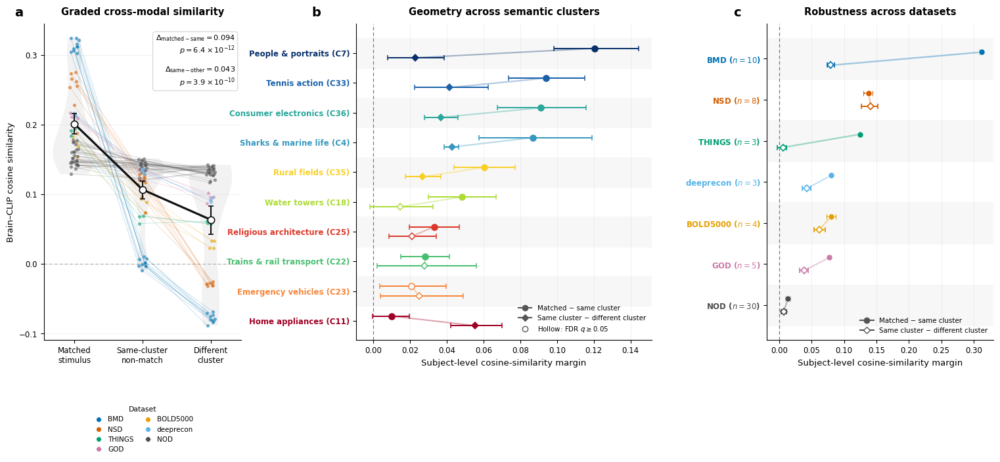

In [474]:
# ============================================================
# PUBLICATION FIGURE
# Hierarchical semantic geometry
#
# Panel a:
#   paired subject trajectories + distribution + mean 95% CI
#
# Panel b:
#   cluster-coloured dumbbell/forest plot
#
# Panel c:
#   dataset-coloured dumbbell/forest plot
# ============================================================

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ============================================================
# 1. Colour maps
# ============================================================

CLUSTER_NAMES = MANUAL_CLUSTER_NAMES.copy()
CLUSTER_COLORS = MANUAL_CLUSTER_COLORS.copy()
DATASET_COLORS = DATASET_COLORS_CLEAN.copy()


# ============================================================
# 2. Plotting configuration
# ============================================================

plt.rcParams.update({
    "font.family": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5,
    "axes.titlesize": 10.5,
    "axes.labelsize": 9.5,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 7.5,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white",
    "axes.facecolor": "white",
})


# ============================================================
# 3. Helpers
# ============================================================

def asymmetric_error(mean, low, high):
    return np.asarray([
        [mean - low],
        [high - mean],
    ])


def add_alternating_rows(
    axis,
    n_rows,
    facecolor="#F7F7F7",
):
    for row_index in range(n_rows):
        if row_index % 2 == 0:
            axis.axhspan(
                row_index - 0.5,
                row_index + 0.5,
                color=facecolor,
                zorder=0,
            )


def colour_tick_labels(
    axis,
    labels_to_colors,
):
    for tick_label in axis.get_yticklabels():
        clean_label = tick_label.get_text()

        for key, color in labels_to_colors.items():
            if clean_label.startswith(str(key)):
                tick_label.set_color(color)
                tick_label.set_fontweight("bold")
                break


# ============================================================
# 4. Prepare plotting tables
# ============================================================

cluster_plot_df_final = (
    cluster_plot_df
    .sort_values(
        "matched_minus_same_mean",
        ascending=False,
    )
    .reset_index(drop=True)
)

dataset_plot_df_final = (
    dataset_plot_df
    .sort_values(
        "matched_minus_same_mean",
        ascending=False,
    )
    .reset_index(drop=True)
)


# Overall statistics for panel a
similarity_columns = [
    "matched_similarity",
    "same_cluster_similarity",
    "different_cluster_similarity",
]

similarity_labels = [
    "Matched\nstimulus",
    "Same-cluster\nnon-match",
    "Different\ncluster",
]

overall_means = []
overall_lows = []
overall_highs = []

for column_index, column_name in enumerate(
    similarity_columns
):
    mean_value, low_value, high_value = (
        bootstrap_mean_ci(
            subject_hierarchy_df[column_name],
            seed=1000 + column_index,
        )
    )

    overall_means.append(mean_value)
    overall_lows.append(low_value)
    overall_highs.append(high_value)

overall_means = np.asarray(overall_means)
overall_lows = np.asarray(overall_lows)
overall_highs = np.asarray(overall_highs)


# ============================================================
# 5. Figure layout
# ============================================================

fig = plt.figure(
    figsize=(15.8, 6.6)
)

grid = fig.add_gridspec(
    1,
    3,
    width_ratios=[
        1.0,
        1.50,
        1.15,
    ],
    wspace=0.48,
)

ax_a = fig.add_subplot(grid[0, 0])
ax_b = fig.add_subplot(grid[0, 1])
ax_c = fig.add_subplot(grid[0, 2])


# ============================================================
# PANEL A
# Graded subject-level similarity
# ============================================================

x_positions = np.arange(3)

# Light distribution shapes behind subject trajectories
violin_data = [
    subject_hierarchy_df[column_name]
    .to_numpy(dtype=float)
    for column_name in similarity_columns
]

violin_parts = ax_a.violinplot(
    violin_data,
    positions=x_positions,
    widths=0.63,
    showmeans=False,
    showmedians=False,
    showextrema=False,
)

for violin_body in violin_parts["bodies"]:
    violin_body.set_facecolor("#D9D9D9")
    violin_body.set_edgecolor("none")
    violin_body.set_alpha(0.34)
    violin_body.set_zorder(0)


# Give each subject a small fixed horizontal offset so that
# trajectories remain paired but overlap less strongly.
rng = np.random.default_rng(42)

subject_offsets = rng.uniform(
    -0.065,
    0.065,
    size=len(subject_hierarchy_df),
)


for subject_index, (_, row) in enumerate(
    subject_hierarchy_df.iterrows()
):
    dataset_name = str(
        row["dataset_name"]
    )

    dataset_color = DATASET_COLORS.get(
        dataset_name,
        "#777777",
    )

    values = row[
        similarity_columns
    ].to_numpy(dtype=float)

    shifted_x = (
        x_positions
        + subject_offsets[subject_index]
    )

    ax_a.plot(
        shifted_x,
        values,
        color=dataset_color,
        alpha=0.20,
        linewidth=0.75,
        zorder=1,
    )

    ax_a.scatter(
        shifted_x,
        values,
        s=15,
        facecolor=dataset_color,
        edgecolor="white",
        linewidth=0.25,
        alpha=0.58,
        zorder=2,
    )


# Across-subject mean trajectory
ax_a.plot(
    x_positions,
    overall_means,
    color="#111111",
    linewidth=2.3,
    zorder=5,
)

ax_a.errorbar(
    x_positions,
    overall_means,
    yerr=np.vstack([
        overall_means - overall_lows,
        overall_highs - overall_means,
    ]),
    fmt="o",
    color="#111111",
    markerfacecolor="white",
    markeredgecolor="#111111",
    markeredgewidth=1.2,
    markersize=7.5,
    linewidth=1.5,
    capsize=3.2,
    zorder=6,
)


# Margin annotations
annotation_text = (
    r"$\Delta_{\mathrm{matched-same}}=0.094$"
    "\n"
    r"$p=6.4\times10^{-12}$"
    "\n\n"
    r"$\Delta_{\mathrm{same-other}}=0.043$"
    "\n"
    r"$p=3.9\times10^{-10}$"
)

ax_a.text(
    0.97,
    0.97,
    annotation_text,
    transform=ax_a.transAxes,
    ha="right",
    va="top",
    fontsize=8.1,
    bbox={
        "boxstyle": "round,pad=0.35",
        "facecolor": "white",
        "edgecolor": "#D0D0D0",
        "linewidth": 0.8,
        "alpha": 0.96,
    },
    zorder=10,
)


ax_a.axhline(
    0,
    color="#8C8C8C",
    linestyle=(0, (4, 3)),
    linewidth=0.8,
    zorder=0,
)

ax_a.set_xticks(x_positions)
ax_a.set_xticklabels(similarity_labels)

ax_a.set_ylabel(
    "Brain–CLIP cosine similarity"
)

ax_a.set_title(
    "Graded cross-modal similarity",
    fontweight="bold",
    pad=10,
)

ax_a.grid(
    axis="y",
    color="#D8D8D8",
    linewidth=0.5,
    alpha=0.55,
)

ax_a.set_axisbelow(True)


# Dataset legend for panel a
present_datasets = [
    dataset_name
    for dataset_name in DATASET_COLORS
    if dataset_name in set(
        subject_hierarchy_df[
            "dataset_name"
        ].astype(str)
    )
]

dataset_legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor=DATASET_COLORS[
            dataset_name
        ],
        markeredgecolor="white",
        markeredgewidth=0.4,
        markersize=5.5,
        label=dataset_name,
    )
    for dataset_name in present_datasets
]

ax_a.legend(
    handles=dataset_legend_handles,
    title="Dataset",
    title_fontsize=7.8,
    frameon=False,
    ncol=2,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.19),
    columnspacing=1.0,
    handletextpad=0.35,
)


# ============================================================
# PANEL B
# Cluster-level margins
# ============================================================

n_clusters_plot = len(
    cluster_plot_df_final
)

cluster_y = np.arange(
    n_clusters_plot
)

vertical_offset = 0.16

add_alternating_rows(
    ax_b,
    n_clusters_plot,
)


for row_index, row in cluster_plot_df_final.iterrows():

    cluster_id = int(
        row["semantic_cluster"]
    )

    cluster_color = CLUSTER_COLORS.get(
        cluster_id,
        "#666666",
    )

    exact_mean = float(
        row["matched_minus_same_mean"]
    )

    exact_low = float(
        row["matched_minus_same_low"]
    )

    exact_high = float(
        row["matched_minus_same_high"]
    )

    exact_q = float(
        row["matched_minus_same_q"]
    )

    semantic_mean = float(
        row["same_minus_different_mean"]
    )

    semantic_low = float(
        row["same_minus_different_low"]
    )

    semantic_high = float(
        row["same_minus_different_high"]
    )

    semantic_q = float(
        row["same_minus_different_q"]
    )


    # Dumbbell connector
    ax_b.plot(
        [
            exact_mean,
            semantic_mean,
        ],
        [
            cluster_y[row_index] - vertical_offset,
            cluster_y[row_index] + vertical_offset,
        ],
        color=cluster_color,
        linewidth=1.6,
        alpha=0.34,
        zorder=1,
    )


    # Exact-stimulus margin
    ax_b.errorbar(
        exact_mean,
        cluster_y[row_index] - vertical_offset,
        xerr=asymmetric_error(
            exact_mean,
            exact_low,
            exact_high,
        ),
        fmt="o",
        color=cluster_color,
        markerfacecolor=(
            cluster_color
            if exact_q < 0.05
            else "white"
        ),
        markeredgecolor=cluster_color,
        markeredgewidth=1.1,
        markersize=6.6,
        linewidth=1.45,
        capsize=2.7,
        zorder=3,
    )


    # Category-level margin
    ax_b.errorbar(
        semantic_mean,
        cluster_y[row_index] + vertical_offset,
        xerr=asymmetric_error(
            semantic_mean,
            semantic_low,
            semantic_high,
        ),
        fmt="D",
        color=cluster_color,
        markerfacecolor=(
            cluster_color
            if semantic_q < 0.05
            else "white"
        ),
        markeredgecolor=cluster_color,
        markeredgewidth=1.1,
        markersize=5.6,
        linewidth=1.45,
        capsize=2.7,
        zorder=3,
    )


cluster_tick_labels = [
    (
        f"{row['cluster_label']} "
        f"(C{int(row['semantic_cluster'])})"
    )
    for _, row in cluster_plot_df_final.iterrows()
]

ax_b.set_yticks(
    cluster_y
)

ax_b.set_yticklabels(
    cluster_tick_labels
)

ax_b.invert_yaxis()

for tick_label, (_, row) in zip(
    ax_b.get_yticklabels(),
    cluster_plot_df_final.iterrows(),
):
    cluster_id = int(
        row["semantic_cluster"]
    )

    tick_label.set_color(
        CLUSTER_COLORS.get(
            cluster_id,
            "#333333",
        )
    )

    tick_label.set_fontweight(
        "bold"
    )


ax_b.axvline(
    0,
    color="#777777",
    linestyle=(0, (4, 3)),
    linewidth=0.9,
)

ax_b.set_xlabel(
    "Subject-level cosine-similarity margin"
)

ax_b.set_title(
    "Geometry across semantic clusters",
    fontweight="bold",
    pad=10,
)

ax_b.grid(
    axis="x",
    color="#D8D8D8",
    linewidth=0.5,
    alpha=0.55,
)

ax_b.set_axisbelow(True)


cluster_legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="-",
        color="#555555",
        markerfacecolor="#555555",
        markersize=6,
        label="Matched − same cluster",
    ),
    Line2D(
        [0],
        [0],
        marker="D",
        linestyle="-",
        color="#555555",
        markerfacecolor="#555555",
        markersize=5.2,
        label="Same cluster − different cluster",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        color="#555555",
        markerfacecolor="white",
        markersize=6,
        label=r"Hollow: FDR $q\geq0.05$",
    ),
]

ax_b.legend(
    handles=cluster_legend_handles,
    frameon=False,
    loc="lower right",
    fontsize=7.4,
)


# ============================================================
# PANEL C
# Dataset-level margins
# ============================================================

n_datasets_plot = len(
    dataset_plot_df_final
)

dataset_y = np.arange(
    n_datasets_plot
)

add_alternating_rows(
    ax_c,
    n_datasets_plot,
)


for row_index, row in dataset_plot_df_final.iterrows():

    dataset_name = str(
        row["dataset_name"]
    )

    dataset_color = DATASET_COLORS.get(
        dataset_name,
        "#666666",
    )

    exact_mean = float(
        row["matched_minus_same_mean"]
    )

    exact_low = float(
        row["matched_minus_same_low"]
    )

    exact_high = float(
        row["matched_minus_same_high"]
    )

    semantic_mean = float(
        row["same_minus_different_mean"]
    )

    semantic_low = float(
        row["same_minus_different_low"]
    )

    semantic_high = float(
        row["same_minus_different_high"]
    )


    ax_c.plot(
        [
            exact_mean,
            semantic_mean,
        ],
        [
            dataset_y[row_index] - vertical_offset,
            dataset_y[row_index] + vertical_offset,
        ],
        color=dataset_color,
        linewidth=1.7,
        alpha=0.36,
        zorder=1,
    )


    ax_c.errorbar(
        exact_mean,
        dataset_y[row_index] - vertical_offset,
        xerr=asymmetric_error(
            exact_mean,
            exact_low,
            exact_high,
        ),
        fmt="o",
        color=dataset_color,
        markerfacecolor=dataset_color,
        markeredgecolor="white",
        markeredgewidth=0.7,
        markersize=6.8,
        linewidth=1.5,
        capsize=2.8,
        zorder=3,
    )


    ax_c.errorbar(
        semantic_mean,
        dataset_y[row_index] + vertical_offset,
        xerr=asymmetric_error(
            semantic_mean,
            semantic_low,
            semantic_high,
        ),
        fmt="D",
        color=dataset_color,
        markerfacecolor="white",
        markeredgecolor=dataset_color,
        markeredgewidth=1.25,
        markersize=5.6,
        linewidth=1.45,
        capsize=2.8,
        zorder=3,
    )


dataset_tick_labels = [
    (
        f"{row['dataset_name']} "
        f"($n={int(row['n_subjects'])}$)"
    )
    for _, row in dataset_plot_df_final.iterrows()
]

ax_c.set_yticks(
    dataset_y
)

ax_c.set_yticklabels(
    dataset_tick_labels
)

ax_c.invert_yaxis()

for tick_label, (_, row) in zip(
    ax_c.get_yticklabels(),
    dataset_plot_df_final.iterrows(),
):
    dataset_name = str(
        row["dataset_name"]
    )

    tick_label.set_color(
        DATASET_COLORS.get(
            dataset_name,
            "#333333",
        )
    )

    tick_label.set_fontweight(
        "bold"
    )


ax_c.axvline(
    0,
    color="#777777",
    linestyle=(0, (4, 3)),
    linewidth=0.9,
)

ax_c.set_xlabel(
    "Subject-level cosine-similarity margin"
)

ax_c.set_title(
    "Robustness across datasets",
    fontweight="bold",
    pad=10,
)

ax_c.grid(
    axis="x",
    color="#D8D8D8",
    linewidth=0.5,
    alpha=0.55,
)

ax_c.set_axisbelow(True)


dataset_margin_legend = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="-",
        color="#555555",
        markerfacecolor="#555555",
        markersize=6,
        label="Matched − same cluster",
    ),
    Line2D(
        [0],
        [0],
        marker="D",
        linestyle="-",
        color="#555555",
        markerfacecolor="white",
        markersize=5.3,
        label="Same cluster − different cluster",
    ),
]

ax_c.legend(
    handles=dataset_margin_legend,
    frameon=False,
    loc="lower right",
    fontsize=7.4,
)


# ============================================================
# 6. Panel labels and spacing
# ============================================================

for panel_label, axis in zip(
    ["a", "b", "c"],
    [ax_a, ax_b, ax_c],
):
    axis.text(
        -0.15,
        1.055,
        panel_label,
        transform=axis.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="left",
        va="top",
    )


# No figure-level title: the caption carries the message,
# which is generally cleaner for journal figures.
fig.subplots_adjust(
    left=0.07,
    right=0.985,
    bottom=0.18,
    top=0.91,
    wspace=0.48,
)


# ============================================================
# 7. Save
# ============================================================

figure_pdf = (
    geometry_figure_out
    / "hierarchical_semantic_geometry_publication.pdf"
)

figure_png = (
    geometry_figure_out
    / "hierarchical_semantic_geometry_publication.png"
)

fig.savefig(
    figure_pdf,
    bbox_inches="tight",
)

fig.savefig(
    figure_png,
    dpi=500,
    bbox_inches="tight",
)

print("Saved:", figure_pdf)
print("Saved:", figure_png)

plt.show()

### Fig. 4d — Cluster-associated ROI beta patterns on the cortical surface
The cluster-mean ROI betas were mapped to HCP-MMP1.0 parcels (NIfTI files in `results/.../wholebrain_cluster_beta_maps/`) and are rendered on the conte69 fs_LR 32k surface with BrainSpace (needs a working VTK/offscreen renderer).

In [475]:
# ============================================================
# Standalone setup for BrainSpace cluster beta maps (cell below)
# Loads everything from disk — no earlier cells needed.
# Provides: cluster_beta_img_paths, CLUSTER_NAME_MAP, get_cluster_label,
#   atlas_img, atlas_data, TOP_K_ROIS_FOR_BETA_MAP, VISUAL_MIN_BETA,
#   beta_brainspace_out, surf_lh, surf_rh, vertex_atlas_label_lh/rh
# ============================================================

from pathlib import Path
import os
import re

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.spatial import cKDTree

from nilearn.plotting.cm import cold_hot
from brainspace.datasets import load_conte69
from brainspace.plotting import plot_hemispheres


# ------------------------------------------------------------
# 0. Paths + display settings (same as the nilearn beta panels)
# ------------------------------------------------------------

analysis5_out = Path(
    str(RESULTS_ROOT) + "/"
    "analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS"
)
analysis5_fig_out = analysis5_out / "publication_figures"
beta_wholebrain_out = analysis5_out / "wholebrain_cluster_beta_maps"
beta_wholebrain_fig_out = analysis5_fig_out / "wholebrain_cluster_beta_maps"

beta_brainspace_out = beta_wholebrain_fig_out / "brainspace_surface_panels"
beta_brainspace_out.mkdir(parents=True, exist_ok=True)

atlas_img_path = Path(
    str(ATLAS_ROOT) + "/The-HCP-MMP1.0-atlas-in-FSL/MNI_Glasser_HCP_v1.0.nii.gz"
)

TOP_K_ROIS_FOR_BETA_MAP = 100
VISUAL_MIN_BETA = 0.25

selected_clusters = [4, 7, 11, 18, 22, 23, 25, 33, 35, 36]

CLUSTER_NAME_MAP = {
    0:  "Mountains & landscapes",
    1:  "Bathrooms & interiors",
    2:  "Dogs",
    3:  "Clocks & gauges",
    4:  "Sharks & marine life",
    5:  "Wooden furniture",
    6:  "Bowls & drinks",
    7:  "People & portraits",
    8:  "Stone arches & ruins",
    9:  "Coasts & oceans",
    10: "Insects",
    11: "Home appliances",
    12: "Bags & textiles",
    13: "Containers & boxes",
    14: "Reptiles & frogs",
    15: "Sailboats",
    16: "Buses",
    17: "Airplanes",
    18: "Water towers",
    19: "Shore birds",
    20: "Architectural details",
    21: "Baseball",
    22: "Trains & rail transport",
    23: "Emergency vehicles",
    24: "Bridges",
    25: "Religious architecture",
    26: "Libraries & theatres",
    27: "Zebras",
    28: "Cups & jugs",
    29: "Flowers",
    30: "Skiing",
    31: "Cars & trucks",
    32: "Toiletries & bottles",
    33: "Tennis action",
    34: "Fruits",
    35: "Rural fields",
    36: "Consumer electronics",
    37: "Tools & hardware",
    38: "Books & artifacts",
    39: "Birds",
}


def get_cluster_label(cluster_id):
    return CLUSTER_NAME_MAP.get(int(cluster_id), f"Cluster {int(cluster_id)}")


# ------------------------------------------------------------
# 1. Cluster beta NIfTIs saved by the "Create NIfTI maps" cell
# ------------------------------------------------------------

cluster_beta_img_paths = {}
for cluster_id in selected_clusters:
    safe_name = re.sub(r"[^a-zA-Z0-9]+", "_", get_cluster_label(cluster_id)).strip("_")
    nii_path = (
        beta_wholebrain_out
        / f"cluster_{cluster_id:02d}_{safe_name}_top{TOP_K_ROIS_FOR_BETA_MAP}_beta_hcp_mmp1.nii.gz"
    )
    if not nii_path.exists():
        raise FileNotFoundError(nii_path)
    cluster_beta_img_paths[cluster_id] = nii_path

print(f"Found {len(cluster_beta_img_paths)} cluster beta maps in {beta_wholebrain_out}")


# ------------------------------------------------------------
# 2. Atlas + conte69 surfaces
# ------------------------------------------------------------

atlas_img = nib.load(str(atlas_img_path))
atlas_data = np.asarray(atlas_img.get_fdata()).astype(np.int32)

surf_lh, surf_rh = load_conte69()


# ------------------------------------------------------------
# 3. Vertex -> Glasser label lookup (computed once, reused per cluster)
#    Each conte69 vertex takes the label of the nearest labeled atlas
#    voxel in its own hemisphere (within max_dist_mm); this fills the
#    thin Glasser ribbon without bleeding values between ROIs.
# ------------------------------------------------------------

def vertex_atlas_labels(bs_surf, hemisphere, max_dist_mm=4.0):
    ijk = np.argwhere(atlas_data > 0)
    xyz = nib.affines.apply_affine(atlas_img.affine, ijk)
    keep = xyz[:, 0] < 0 if hemisphere == "left" else xyz[:, 0] > 0
    ijk, xyz = ijk[keep], xyz[keep]
    labels = atlas_data[tuple(ijk.T)]

    dist, idx = cKDTree(xyz).query(np.asarray(bs_surf.GetPoints()), k=1)
    vertex_labels = labels[idx]
    vertex_labels[dist > max_dist_mm] = 0
    return vertex_labels


vertex_atlas_label_lh = vertex_atlas_labels(surf_lh, "left")
vertex_atlas_label_rh = vertex_atlas_labels(surf_rh, "right")

print(f"conte69 vertices with a Glasser label: "
      f"L {(vertex_atlas_label_lh > 0).mean():.1%}, "
      f"R {(vertex_atlas_label_rh > 0).mean():.1%}")

Found 10 cluster beta maps in /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/wholebrain_cluster_beta_maps


conte69 vertices with a Glasser label: L 95.9%, R 96.1%


/home/moein/miniconda/envs/b2txt25/lib/python3.10/site-packages/brainspace/plotting/surface_plotting.py:437: RuntimeWarning: Running plot_hemispheres without a display may result in a crash. For a workaround please consult https://github.com/MICA-MNI/BrainSpace/issues/66. To suppress this warning set suppress_warnings=True.
  warnings.warn(
2026-10-07 02:46:00.502 (64836.822s) [    7FF63EF0E740]    vtkX11Functions.cxx:194   WARN| Failed to load Xcursor library


Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/wholebrain_cluster_beta_maps/brainspace_surface_panels/cluster_04_Sharks_marine_life_brainspace_2x2_top100_beta.pdf


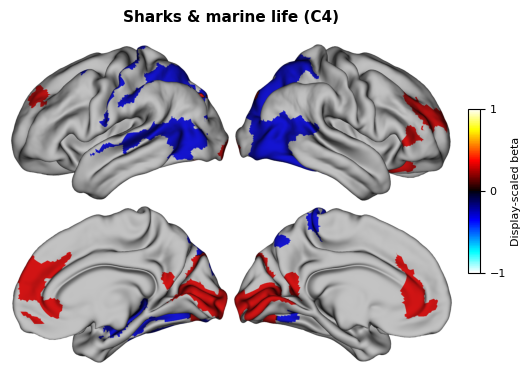

/home/moein/miniconda/envs/b2txt25/lib/python3.10/site-packages/brainspace/plotting/surface_plotting.py:437: RuntimeWarning: Running plot_hemispheres without a display may result in a crash. For a workaround please consult https://github.com/MICA-MNI/BrainSpace/issues/66. To suppress this warning set suppress_warnings=True.
  warnings.warn(
2026-10-07 02:46:02.493 (64838.813s) [    7FF63EF0E740]    vtkX11Functions.cxx:194   WARN| Failed to load Xcursor library


Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/wholebrain_cluster_beta_maps/brainspace_surface_panels/cluster_07_People_portraits_brainspace_2x2_top100_beta.pdf


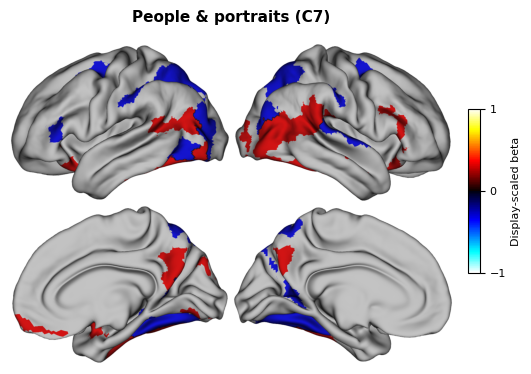

/home/moein/miniconda/envs/b2txt25/lib/python3.10/site-packages/brainspace/plotting/surface_plotting.py:437: RuntimeWarning: Running plot_hemispheres without a display may result in a crash. For a workaround please consult https://github.com/MICA-MNI/BrainSpace/issues/66. To suppress this warning set suppress_warnings=True.
  warnings.warn(
2026-10-07 02:46:04.513 (64840.833s) [    7FF63EF0E740]    vtkX11Functions.cxx:194   WARN| Failed to load Xcursor library


Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/wholebrain_cluster_beta_maps/brainspace_surface_panels/cluster_11_Home_appliances_brainspace_2x2_top100_beta.pdf


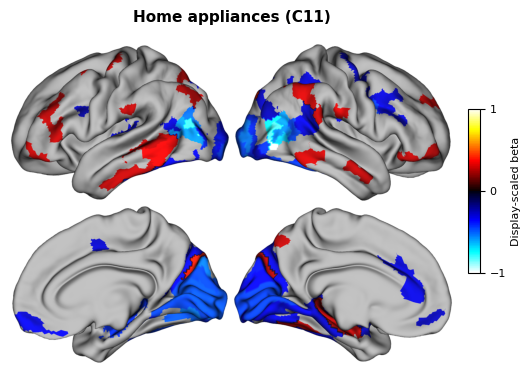

/home/moein/miniconda/envs/b2txt25/lib/python3.10/site-packages/brainspace/plotting/surface_plotting.py:437: RuntimeWarning: Running plot_hemispheres without a display may result in a crash. For a workaround please consult https://github.com/MICA-MNI/BrainSpace/issues/66. To suppress this warning set suppress_warnings=True.
  warnings.warn(
2026-10-07 02:46:06.547 (64842.867s) [    7FF63EF0E740]    vtkX11Functions.cxx:194   WARN| Failed to load Xcursor library


Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/wholebrain_cluster_beta_maps/brainspace_surface_panels/cluster_18_Water_towers_brainspace_2x2_top100_beta.pdf


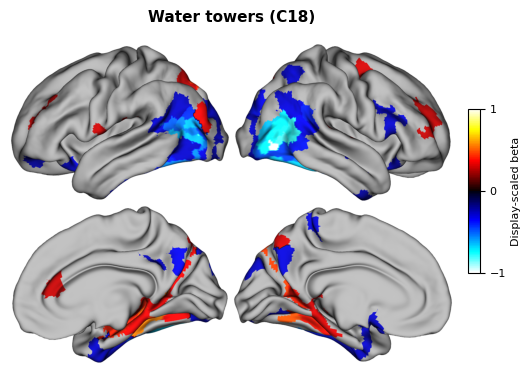

/home/moein/miniconda/envs/b2txt25/lib/python3.10/site-packages/brainspace/plotting/surface_plotting.py:437: RuntimeWarning: Running plot_hemispheres without a display may result in a crash. For a workaround please consult https://github.com/MICA-MNI/BrainSpace/issues/66. To suppress this warning set suppress_warnings=True.
  warnings.warn(
2026-10-07 02:46:08.555 (64844.875s) [    7FF63EF0E740]    vtkX11Functions.cxx:194   WARN| Failed to load Xcursor library


Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/wholebrain_cluster_beta_maps/brainspace_surface_panels/cluster_22_Trains_rail_transport_brainspace_2x2_top100_beta.pdf


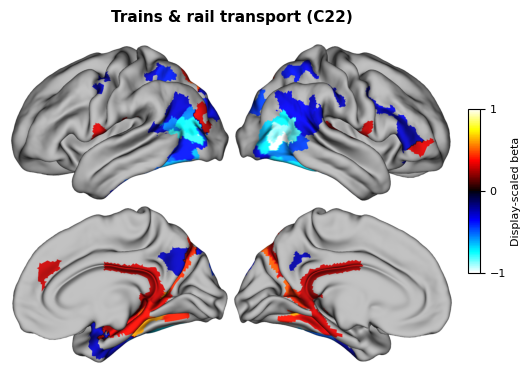

/home/moein/miniconda/envs/b2txt25/lib/python3.10/site-packages/brainspace/plotting/surface_plotting.py:437: RuntimeWarning: Running plot_hemispheres without a display may result in a crash. For a workaround please consult https://github.com/MICA-MNI/BrainSpace/issues/66. To suppress this warning set suppress_warnings=True.
  warnings.warn(
2026-10-07 02:46:10.528 (64846.848s) [    7FF63EF0E740]    vtkX11Functions.cxx:194   WARN| Failed to load Xcursor library


Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/wholebrain_cluster_beta_maps/brainspace_surface_panels/cluster_23_Emergency_vehicles_brainspace_2x2_top100_beta.pdf


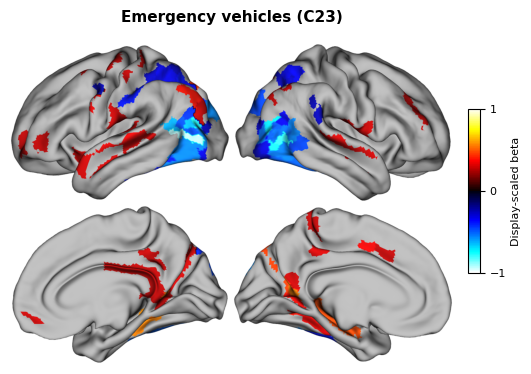

/home/moein/miniconda/envs/b2txt25/lib/python3.10/site-packages/brainspace/plotting/surface_plotting.py:437: RuntimeWarning: Running plot_hemispheres without a display may result in a crash. For a workaround please consult https://github.com/MICA-MNI/BrainSpace/issues/66. To suppress this warning set suppress_warnings=True.
  warnings.warn(
2026-10-07 02:46:12.532 (64848.852s) [    7FF63EF0E740]    vtkX11Functions.cxx:194   WARN| Failed to load Xcursor library


Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/wholebrain_cluster_beta_maps/brainspace_surface_panels/cluster_25_Religious_architecture_brainspace_2x2_top100_beta.pdf


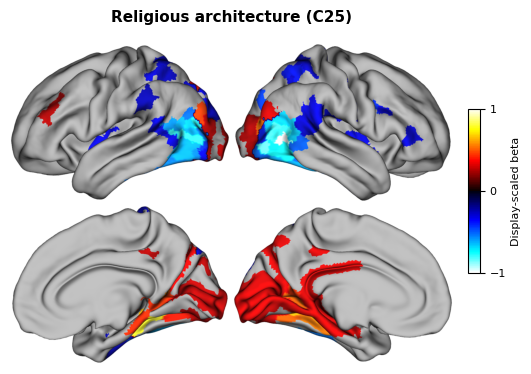

/home/moein/miniconda/envs/b2txt25/lib/python3.10/site-packages/brainspace/plotting/surface_plotting.py:437: RuntimeWarning: Running plot_hemispheres without a display may result in a crash. For a workaround please consult https://github.com/MICA-MNI/BrainSpace/issues/66. To suppress this warning set suppress_warnings=True.
  warnings.warn(
2026-10-07 02:46:14.547 (64850.867s) [    7FF63EF0E740]    vtkX11Functions.cxx:194   WARN| Failed to load Xcursor library


Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/wholebrain_cluster_beta_maps/brainspace_surface_panels/cluster_33_Tennis_action_brainspace_2x2_top100_beta.pdf


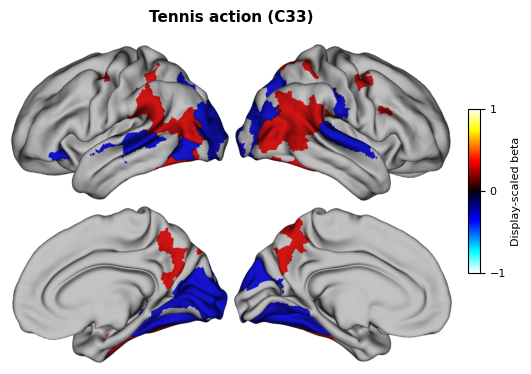

/home/moein/miniconda/envs/b2txt25/lib/python3.10/site-packages/brainspace/plotting/surface_plotting.py:437: RuntimeWarning: Running plot_hemispheres without a display may result in a crash. For a workaround please consult https://github.com/MICA-MNI/BrainSpace/issues/66. To suppress this warning set suppress_warnings=True.
  warnings.warn(
2026-10-07 02:46:16.846 (64853.167s) [    7FF63EF0E740]    vtkX11Functions.cxx:194   WARN| Failed to load Xcursor library


Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/wholebrain_cluster_beta_maps/brainspace_surface_panels/cluster_35_Rural_fields_brainspace_2x2_top100_beta.pdf


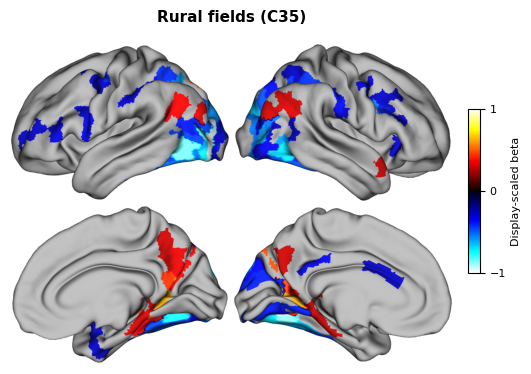

/home/moein/miniconda/envs/b2txt25/lib/python3.10/site-packages/brainspace/plotting/surface_plotting.py:437: RuntimeWarning: Running plot_hemispheres without a display may result in a crash. For a workaround please consult https://github.com/MICA-MNI/BrainSpace/issues/66. To suppress this warning set suppress_warnings=True.
  warnings.warn(
2026-10-07 02:46:19.528 (64855.848s) [    7FF63EF0E740]    vtkX11Functions.cxx:194   WARN| Failed to load Xcursor library


Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/wholebrain_cluster_beta_maps/brainspace_surface_panels/cluster_36_Consumer_electronics_brainspace_2x2_top100_beta.pdf


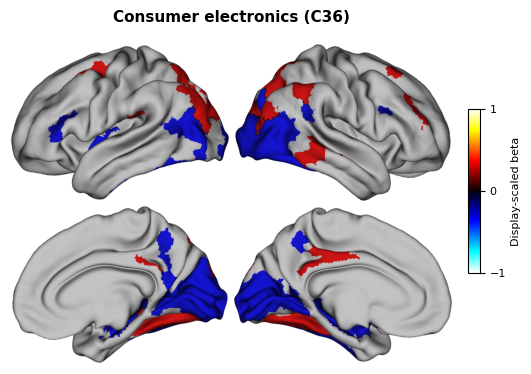

Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/wholebrain_cluster_beta_maps/brainspace_surface_panels/all_clusters_brainspace_2x2_top100_beta.pdf


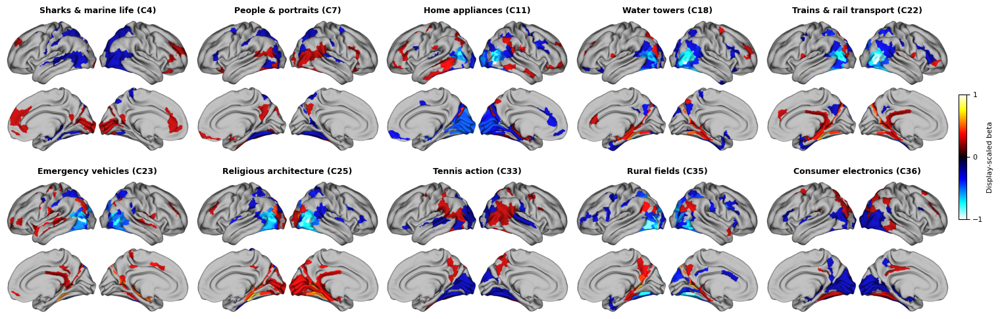

In [476]:
# ============================================================
# Cluster beta maps on BrainSpace (conte69) surfaces
# 2x2 layout per cluster (L lateral, R lateral / R medial, L medial)
# Same colormap / range / threshold as the clean 4-view nilearn panels:
#   cmap = BETA_CMAP, vmin/vmax = -1/+1, |beta| <= 0.5 * VISUAL_MIN_BETA hidden
# Required: run the standalone setup cell above
# ============================================================

from matplotlib.colors import LinearSegmentedColormap

BETA_VMAX = 1.0
BETA_THRESHOLD = 0.5 * VISUAL_MIN_BETA

# Brain (background) color: lower values = grayer / darker
BETA_NAN_COLOR = (0.65, 0.65, 0.65, 1)

# Diverging map: negative -> green, positive -> purple.
# No white center: shown ROIs have |beta| >= VISUAL_MIN_BETA, so the map
# jumps from medium green to medium purple at 0 to keep weak ROIs saturated.
# (use BETA_CMAP.reversed() to swap sides, or plt.get_cmap("PRGn") for the built-in)
BETA_CMAP = LinearSegmentedColormap.from_list(
    "green_purple",
    [
        (0.000, "#00441B"),   # -1  dark green
        (0.250, "#1B7837"),
        (0.499, "#5AAE61"),   # ~0- medium green
        (0.501, "#9E7BBF"),   # ~0+ medium purple
        (0.750, "#762A83"),
        (1.000, "#40004B"),   # +1  dark purple
    ],
)
BETA_CMAP = "cold_hot"
# BETA_CMAP = "managua"


def beta_img_to_vertex_values(beta_img, threshold=BETA_THRESHOLD):
    """Glasser label -> beta value from the volume, then label -> vertex."""
    beta_data = np.asarray(beta_img.get_fdata())

    nonzero = beta_data != 0
    label_to_beta = np.zeros(int(atlas_data.max()) + 1, dtype=float)
    label_to_beta[atlas_data[nonzero]] = beta_data[nonzero]

    out = []
    for vertex_labels in (vertex_atlas_label_lh, vertex_atlas_label_rh):
        values = label_to_beta[vertex_labels]
        values[(vertex_labels == 0) | (np.abs(values) <= threshold)] = np.nan
        out.append(values)

    return np.concatenate(out)


def render_brainspace_row(vertex_values, raw_png):
    plot_hemispheres(
        surf_lh, surf_rh, array_name=vertex_values, size=(1200, 260),
        cmap=BETA_CMAP, color_range=(-BETA_VMAX, BETA_VMAX),
        nan_color=BETA_NAN_COLOR, zoom=1.2,
        interactive=False, embed_nb=False, screenshot=True,
        filename=str(raw_png), transparent_bg=True, scale=(3, 3),
    )
    image = plt.imread(str(raw_png))
    os.remove(raw_png)
    return image


def crop_to_content(img, pad=4):
    """Crop an RGB(A) render to the non-background pixels."""
    if img.shape[-1] == 4:
        mask = img[..., 3] > 0.01
    else:
        mask = np.any(img[..., :3] < 0.98, axis=-1)
    rows, cols = np.where(mask)
    if rows.size == 0:
        return img
    r0, r1 = max(rows.min() - pad, 0), min(rows.max() + pad + 1, img.shape[0])
    c0, c1 = max(cols.min() - pad, 0), min(cols.max() + pad + 1, img.shape[1])
    return img[r0:r1, c0:c1]


def to_rgba_white(img):
    """RGBA -> RGBA composited on white (so gaps are white, not black)."""
    img = img[..., :4] if img.shape[-1] == 4 else np.dstack([img, np.ones(img.shape[:2])])
    alpha = img[..., 3:4]
    rgb = img[..., :3] * alpha + (1 - alpha)
    return np.dstack([rgb, np.ones(img.shape[:2])])


def row_render_to_2x2(row_img, gap_px=10):
    """
    Split the 1x4 plot_hemispheres render
    [L lateral | L medial | R medial | R lateral]
    into a tight 2x2 grid (outside views on top, inside views below):
        L lateral   R lateral
        R medial    L medial
    """
    n_views = 4
    w = row_img.shape[1] // n_views
    views = [
        to_rgba_white(crop_to_content(row_img[:, k * w:(k + 1) * w]))
        for k in range(n_views)
    ]

    cell_h = max(v.shape[0] for v in views)
    cell_w = max(v.shape[1] for v in views)

    def pad_to_cell(v):
        out = np.ones((cell_h, cell_w, 4))
        r0 = (cell_h - v.shape[0]) // 2
        c0 = (cell_w - v.shape[1]) // 2
        out[r0:r0 + v.shape[0], c0:c0 + v.shape[1]] = v
        return out

    cells = [pad_to_cell(v) for v in views]
    hgap = np.ones((cell_h, gap_px, 4))
    vgap = np.ones((gap_px, 2 * cell_w + gap_px, 4))

    top = np.hstack([cells[0], hgap, cells[3]])
    bottom = np.hstack([cells[2], hgap, cells[1]])
    return np.vstack([top, vgap, bottom])


def add_beta_colorbar(fig, rect):
    cax = fig.add_axes(rect)
    sm = plt.cm.ScalarMappable(
        cmap=BETA_CMAP, norm=mcolors.Normalize(vmin=-BETA_VMAX, vmax=BETA_VMAX),
    )
    cbar = fig.colorbar(sm, cax=cax, orientation="vertical")
    cbar.set_ticks([-BETA_VMAX, 0, BETA_VMAX])
    cbar.ax.tick_params(labelsize=8)
    cbar.set_label("Display-scaled beta", fontsize=8)
    return cbar


# ------------------------------------------------------------
# 1. One 2x2 panel per cluster
# ------------------------------------------------------------

cluster_brainspace_images = {}

for cluster_id, nii_path in cluster_beta_img_paths.items():
    cluster_label = get_cluster_label(cluster_id)
    safe_name = re.sub(r"[^a-zA-Z0-9]+", "_", cluster_label).strip("_")

    vertex_values = beta_img_to_vertex_values(nib.load(str(nii_path)))

    row_img = render_brainspace_row(
        vertex_values, beta_brainspace_out / f"_cluster_{cluster_id:02d}_raw.png",
    )
    image = row_render_to_2x2(row_img)
    cluster_brainspace_images[cluster_id] = image

    img_h_in = 3.2
    img_w_in = img_h_in * image.shape[1] / image.shape[0]
    cbar_in = 0.9
    fig_w, fig_h = img_w_in + cbar_in, img_h_in + 0.45

    fig = plt.figure(figsize=(fig_w, fig_h))
    ax = fig.add_axes([0, 0, img_w_in / fig_w, img_h_in / fig_h])
    ax.imshow(image)
    ax.axis("off")
    fig.text(
        0.5 * img_w_in / fig_w, 1 - 0.18 / fig_h,
        f"{cluster_label} (C{cluster_id})",
        ha="center", va="center", fontsize=11, fontweight="bold",
    )
    add_beta_colorbar(fig, [(img_w_in + 0.15) / fig_w, 0.25, 0.12 / fig_w, 0.45])

    out_stem = beta_brainspace_out / f"cluster_{cluster_id:02d}_{safe_name}_brainspace_2x2_top{TOP_K_ROIS_FOR_BETA_MAP}_beta"
    fig.savefig(f"{out_stem}.pdf", dpi=300, bbox_inches="tight", pad_inches=0.02, facecolor="white")
    fig.savefig(f"{out_stem}.png", dpi=300, bbox_inches="tight", pad_inches=0.02, facecolor="white")
    print("Saved:", f"{out_stem}.pdf")

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 2. All clusters in one figure (2 rows x 5 clusters)
# ------------------------------------------------------------

n_clusters = len(cluster_brainspace_images)
n_cols = 5
n_rows = int(np.ceil(n_clusters / n_cols))

first_image = next(iter(cluster_brainspace_images.values()))
panel_h = 2.0                                        # inches per brain panel
panel_w = panel_h * first_image.shape[1] / first_image.shape[0]
title_h, col_gap, row_gap, cbar_w = 0.3, 0.12, 0.15, 0.8   # inches

fig_w = n_cols * panel_w + (n_cols - 1) * col_gap + cbar_w
fig_h = n_rows * (panel_h + title_h) + (n_rows - 1) * row_gap

fig = plt.figure(figsize=(fig_w, fig_h))

for k, (cluster_id, image) in enumerate(cluster_brainspace_images.items()):
    r, c = divmod(k, n_cols)
    left = c * (panel_w + col_gap)
    top = fig_h - r * (panel_h + title_h + row_gap)
    bottom = top - title_h - panel_h

    ax = fig.add_axes([left / fig_w, bottom / fig_h, panel_w / fig_w, panel_h / fig_h])
    ax.imshow(image)
    ax.axis("off")
    fig.text(
        (left + 0.5 * panel_w) / fig_w, (top - 0.5 * title_h) / fig_h,
        f"{get_cluster_label(cluster_id)} (C{cluster_id})",
        ha="center", va="center", fontsize=9, fontweight="bold",
    )

grid_w = n_cols * panel_w + (n_cols - 1) * col_gap
add_beta_colorbar(fig, [(grid_w + 0.15) / fig_w, 0.3, 0.12 / fig_w, 0.4])

all_stem = beta_brainspace_out / f"all_clusters_brainspace_2x2_top{TOP_K_ROIS_FOR_BETA_MAP}_beta"
fig.savefig(f"{all_stem}.pdf", dpi=300, bbox_inches="tight", pad_inches=0.02, facecolor="white")
fig.savefig(f"{all_stem}.png", dpi=300, bbox_inches="tight", pad_inches=0.02, facecolor="white")
print("Saved:", f"{all_stem}.pdf")

plt.show()
plt.close(fig)

### Fig. 4f — Cluster-specific ablation effects (ten representative clusters)

In [477]:
# ============================================================
# Select 10 semantic clusters by baseline retrieval rank
# positions 0, 4, 8, ...
# ============================================================

CLUSTER_NAME_MAP = {
    0:  "Mountains & landscapes",
    1:  "Bathrooms & interiors",
    2:  "Dogs",
    3:  "Clocks & gauges",
    4:  "Sharks & marine life",
    5:  "Wooden furniture",
    6:  "Bowls & drinks",
    7:  "People & portraits",
    8:  "Stone arches & ruins",
    9:  "Coasts & oceans",
    10: "Insects",
    11: "Home appliances",
    12: "Bags & textiles",
    13: "Containers & boxes",
    14: "Reptiles & frogs",
    15: "Sailboats",
    16: "Buses",
    17: "Airplanes",
    18: "Water towers",
    19: "Shore birds",
    20: "Architectural details",
    21: "Baseball",
    22: "Trains & rail transport",
    23: "Emergency vehicles",
    24: "Bridges",
    25: "Religious architecture",
    26: "Libraries & theatres",
    27: "Zebras",
    28: "Cups & jugs",
    29: "Flowers",
    30: "Skiing",
    31: "Cars & trucks",
    32: "Toiletries & bottles",
    33: "Tennis action",
    34: "Fruits",
    35: "Rural fields",
    36: "Consumer electronics",
    37: "Tools & hardware",
    38: "Books & artifacts",
    39: "Birds",
}

baseline_cluster_perf = (
    summary_by_cluster[
        summary_by_cluster["ablation_name"] == "baseline"
    ]
    .copy()
)

baseline_cluster_perf["semantic_cluster"] = baseline_cluster_perf["semantic_cluster"].astype(int)

baseline_cluster_perf = (
    baseline_cluster_perf
    .sort_values(PLOT_METRIC, ascending=False)
    .reset_index(drop=True)
)

baseline_cluster_perf["retrieval_rank"] = np.arange(
    1,
    len(baseline_cluster_perf) + 1,
)

selected_positions = list(range(0, min(len(baseline_cluster_perf), 40), 4))[:10]

selected_clusters = (
    baseline_cluster_perf
    .loc[selected_positions, "semantic_cluster"]
    .astype(int)
    .tolist()
)

selected_cluster_label_map = {
    cid: f"{CLUSTER_NAME_MAP.get(cid, f'Cluster {cid}')} (C{cid})"
    for cid in selected_clusters
}

print("Selected positions:", selected_positions)
print("Selected clusters:", selected_clusters)

display(
    baseline_cluster_perf.loc[
        selected_positions,
        [
            "retrieval_rank",
            "semantic_cluster",
            PLOT_METRIC,
            "n_unique_stimuli",
            "n_eval_samples",
        ],
    ]
)

Selected positions: [0, 4, 8, 12, 16, 20, 24, 28, 32, 36]
Selected clusters: [7, 33, 4, 36, 22, 18, 35, 23, 25, 11]


,retrieval_rank,semantic_cluster,unique_top10,n_unique_stimuli,n_eval_samples
0,1,7,0.332543,390,7172
4,5,33,0.244969,226,1143
8,9,4,0.186396,308,1132
12,13,36,0.148295,447,1760
16,17,22,0.124796,223,1226
20,21,18,0.077601,220,567
24,25,35,0.048094,261,1102
28,29,23,0.033333,125,270
32,33,25,0.028936,330,1175
36,37,11,0.005690,396,703


Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/fig4_network_by_sampled10_clusters_signed_accuracy_change_top10.pdf


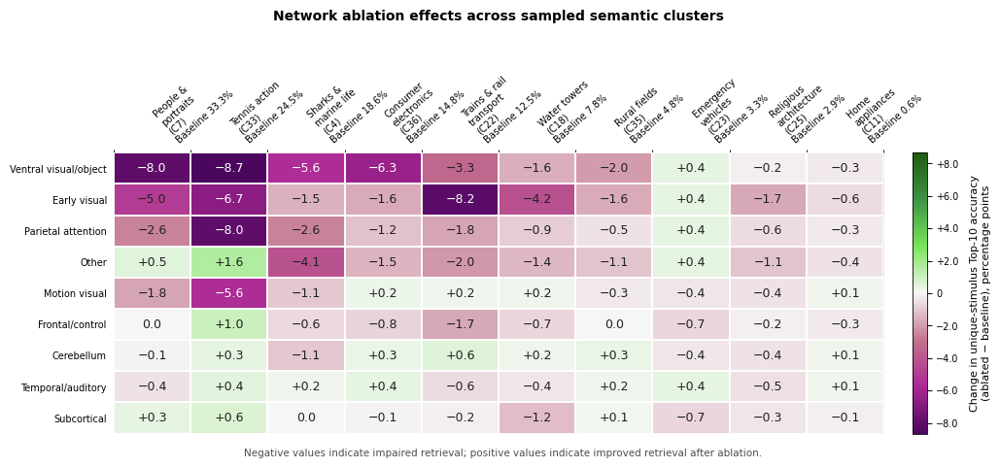

In [478]:
# ============================================================
# Revised Figure 4:
# signed accuracy change across sampled semantic clusters
# baseline shown above each cluster column
# ============================================================

selected_clusters = [int(c) for c in selected_clusters]

drop_by_selected_cluster = drop_by_cluster.copy()

drop_by_selected_cluster["semantic_cluster"] = (
    drop_by_selected_cluster["semantic_cluster"]
    .astype(int)
)

drop_by_selected_cluster = drop_by_selected_cluster[
    drop_by_selected_cluster["semantic_cluster"].isin(selected_clusters)
].copy()

# Ensure cluster-label keys are integers
selected_cluster_label_map_int = {
    int(cluster_id): label
    for cluster_id, label in selected_cluster_label_map.items()
}

fig4_cluster_change_pivot = (
    plot_ablation_change_heatmap_with_baseline(
        drop_df=drop_by_selected_cluster,
        row_col="ablation_name",
        col_col="semantic_cluster",
        value_col=DROP_METRIC,
        baseline_col=BASELINE_METRIC,
        row_order=network_order,
        col_order=selected_clusters,
        row_label_map=network_label_map,
        col_label_map=selected_cluster_label_map_int,
        title=(
            "Network ablation effects across sampled "
            "semantic clusters"
        ),
        cbar_label=(
            "Change in unique-stimulus Top-10 accuracy\n"
            "(ablated − baseline), percentage points"
        ),
        save_path=(
            analysis5_fig_out
            / "fig4_network_by_sampled10_clusters_signed_accuracy_change_top10.pdf"
        ),
        figsize=(10.4, 4.8),
        annotate=True,
        decimals=1,
        rotate_xticks=42,
        wrap_col_labels=True,
        col_label_width=13,
        robust_percentile=None,
    )
)

### Fig. 4e — Network composition of positively cluster-selective saliency
ROI saliency is the sum over voxels of |gradient × input| of the matched brain–CLIP cosine similarity, normalized per query. Selectivity is a within-ROI standardized contrast (Cohen's d) between queries inside and outside each cluster; the top 20 positively selective ROIs per cluster are counted per network.

In [479]:
# ============================================================
# CELL 1
# Prepare ALL 40 semantic clusters for network-ablation heatmap
#
# Ordering:
#   baseline unique-stimulus retrieval performance,
#   highest -> lowest
#
# Cell colour:
#   signed ablation effect
#
# Cluster identity:
#   encoded in x-axis label colour using ALL_CLUSTER_COLORS
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path


# ============================================================
# Semantic names for all 40 clusters
# ============================================================

CLUSTER_NAME_MAP = {
    0:  "Mountains & landscapes",
    1:  "Bathrooms & interiors",
    2:  "Dogs",
    3:  "Clocks & gauges",
    4:  "Sharks & marine life",
    5:  "Wooden furniture",
    6:  "Bowls & drinks",
    7:  "People & portraits",
    8:  "Stone arches & ruins",
    9:  "Coasts & oceans",
    10: "Insects",
    11: "Home appliances",
    12: "Bags & textiles",
    13: "Containers & boxes",
    14: "Reptiles & frogs",
    15: "Sailboats",
    16: "Buses",
    17: "Airplanes",
    18: "Water towers",
    19: "Shore birds",
    20: "Architectural details",
    21: "Baseball",
    22: "Trains & rail transport",
    23: "Emergency vehicles",
    24: "Bridges",
    25: "Religious architecture",
    26: "Libraries & theatres",
    27: "Zebras",
    28: "Cups & jugs",
    29: "Flowers",
    30: "Skiing",
    31: "Cars & trucks",
    32: "Toiletries & bottles",
    33: "Tennis action",
    34: "Fruits",
    35: "Rural fields",
    36: "Consumer electronics",
    37: "Tools & hardware",
    38: "Books & artifacts",
    39: "Birds",
}


# ============================================================
# Baseline cluster performance
# ============================================================

baseline_cluster_perf_all40 = (
    summary_by_cluster[
        summary_by_cluster["ablation_name"].eq("baseline")
    ]
    .copy()
)

baseline_cluster_perf_all40["semantic_cluster"] = (
    baseline_cluster_perf_all40["semantic_cluster"]
    .astype(int)
)


# Highest baseline retrieval -> lowest
baseline_cluster_perf_all40 = (
    baseline_cluster_perf_all40
    .sort_values(
        PLOT_METRIC,
        ascending=False,
    )
    .reset_index(drop=True)
)

baseline_cluster_perf_all40[
    "retrieval_rank"
] = np.arange(
    1,
    len(baseline_cluster_perf_all40) + 1,
)


# ============================================================
# All 40 clusters in baseline-retrieval order
# ============================================================

all40_clusters_ablation = (
    baseline_cluster_perf_all40[
        "semantic_cluster"
    ]
    .astype(int)
    .tolist()
)


assert len(all40_clusters_ablation) == 40
assert set(all40_clusters_ablation) == set(range(40))


print("All-40 retrieval order:")
print(all40_clusters_ablation)


# Optional check against the order used elsewhere
if "CLUSTER_RETRIEVAL_ORDER" in globals():

    print(
        "\nMatches previous retrieval order:",
        all40_clusters_ablation
        == CLUSTER_RETRIEVAL_ORDER,
    )


# ============================================================
# Labels
# ============================================================

all40_cluster_label_map = {
    cid: (
        f"{CLUSTER_NAME_MAP.get(cid, f'Cluster {cid}')} "
        f"(C{cid})"
    )
    for cid in all40_clusters_ablation
}


# ============================================================
# Display baseline information
# ============================================================

display(
    baseline_cluster_perf_all40[
        [
            "retrieval_rank",
            "semantic_cluster",
            PLOT_METRIC,
            "n_unique_stimuli",
            "n_eval_samples",
        ]
    ]
)

All-40 retrieval order:
[7, 0, 6, 30, 33, 14, 2, 21, 4, 17, 39, 24, 36, 8, 26, 27, 22, 1, 34, 19, 18, 9, 5, 28, 35, 16, 31, 12, 23, 15, 29, 20, 25, 3, 37, 10, 11, 13, 32, 38]

Matches previous retrieval order: True


,retrieval_rank,semantic_cluster,unique_top10,n_unique_stimuli,n_eval_samples
0,1,7,0.332543,390,7172
1,2,0,0.324183,251,765
2,3,6,0.289017,373,2768
3,4,30,0.255308,291,5511
4,5,33,0.244969,226,1143
5,6,14,0.226351,166,592
6,7,2,0.225164,259,3815
7,8,21,0.220738,186,1273
8,9,4,0.186396,308,1132
9,10,17,0.172212,273,1713


In [480]:
# ============================================================
# Load unique_stimulus_df from Analysis 2
# It must contain: stimulus_id, semantic_cluster
# ============================================================

SEARCH_ROOT = Path(str(RESULTS_ROOT) + "")

if "unique_stimulus_df" in globals():
    print("Using unique_stimulus_df already in memory.")

else:
    candidate_files = []

    candidate_files += list(SEARCH_ROOT.glob("**/*unique*stimulus*.csv"))
    candidate_files += list(SEARCH_ROOT.glob("**/*unique*stimulus*.pkl"))
    candidate_files += list(SEARCH_ROOT.glob("**/*cluster*.csv"))
    candidate_files += list(SEARCH_ROOT.glob("**/*cluster*.pkl"))

    candidate_files = sorted(set(candidate_files))

    valid_candidates = []

    for path in candidate_files:
        try:
            if path.suffix.lower() == ".pkl":
                tmp = pd.read_pickle(path)
            else:
                tmp = pd.read_csv(path, nrows=5)

            if {"stimulus_id", "semantic_cluster"}.issubset(set(tmp.columns)):
                valid_candidates.append(path)

        except Exception:
            continue

    print("Valid candidate files:")
    for i, path in enumerate(valid_candidates):
        print(i, path)

    if len(valid_candidates) == 0:
        raise RuntimeError(
            "Could not find a saved file with columns stimulus_id and semantic_cluster.\n"
            "Please manually load unique_stimulus_df from Analysis 2 before continuing."
        )

    chosen_cluster_file = valid_candidates[0]
    print("Loading:", chosen_cluster_file)

    if chosen_cluster_file.suffix.lower() == ".pkl":
        unique_stimulus_df = pd.read_pickle(chosen_cluster_file)
    else:
        unique_stimulus_df = pd.read_csv(chosen_cluster_file)


unique_stimulus_df["stimulus_id"] = unique_stimulus_df["stimulus_id"].astype(int)
unique_stimulus_df["semantic_cluster"] = unique_stimulus_df["semantic_cluster"].astype(int)

stimulus_id_to_cluster = dict(
    zip(
        unique_stimulus_df["stimulus_id"],
        unique_stimulus_df["semantic_cluster"],
    )
)

print("N unique stimuli in cluster map:", unique_stimulus_df["stimulus_id"].nunique())
print("N semantic clusters:", unique_stimulus_df["semantic_cluster"].nunique())

Using unique_stimulus_df already in memory.
N unique stimuli in cluster map: 12819
N semantic clusters: 40


In [481]:
# ============================================================
# ROI saliency map generation
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from pathlib import Path
import matplotlib.pyplot as plt

saliency_out = analysis5_out / "roi_saliency_maps"
saliency_out.mkdir(parents=True, exist_ok=True)

saliency_fig_out = analysis5_fig_out / "roi_saliency_maps"
saliency_fig_out.mkdir(parents=True, exist_ok=True)

SALIENCY_CONFIG = {
    "device": ANALYSIS5_CONFIG["device"],
    "target": "matched_clip_similarity",
    "method": "grad_x_input_abs",
    "normalize_per_sample": True,

    # Use selected clusters for speed and for publication figures.
    # Set to None if you want all 40 clusters.
    "clusters_to_run": selected_clusters if "selected_clusters" in globals() else None,

    # Useful for testing. Set to None for the final run.
    "max_batches": None,
}

print("Saliency output:", saliency_out)
print("Device:", SALIENCY_CONFIG["device"])
print("Clusters to run:", SALIENCY_CONFIG["clusters_to_run"])

Saliency output: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/roi_saliency_maps
Device: cuda
Clusters to run: [7, 33, 4, 36, 22, 18, 35, 23, 25, 11]


In [482]:
import pandas as pd
import torch

# ============================================================
# Reconstruct saved paths
# ============================================================

saliency_tensor_path = (
    saliency_out / "roi_saliency_matrix_grad_x_input_abs.pt"
)

saliency_meta_path = (
    saliency_out / "roi_saliency_metadata.csv"
)

saliency_similarity_path = (
    saliency_out / "matched_similarity_for_saliency.pt"
)



saliency_results = torch.load(
    saliency_tensor_path,
    map_location="cpu",
    weights_only=False,
)

saliency_matrix = saliency_results["saliency_matrix"]
matched_similarity = saliency_results["matched_similarity"]
roi_names = saliency_results["roi_names"]

saliency_method = saliency_results["method"]
normalize_per_sample = saliency_results["normalize_per_sample"]
clusters_to_run = saliency_results["clusters_to_run"]

print("Saliency matrix shape:", saliency_matrix.shape)
print("Matched similarity shape:", matched_similarity.shape)
print("Number of ROI names:", len(roi_names))

print("Method:", saliency_method)
print("Normalize per sample:", normalize_per_sample)
print("Clusters included:", clusters_to_run)


saliency_metadata_df = pd.read_csv(saliency_meta_path)

print("Saliency metadata shape:", saliency_metadata_df.shape)
display(saliency_metadata_df.head())

Saliency matrix shape: torch.Size([16250, 379])
Matched similarity shape: torch.Size([16250])
Number of ROI names: 379
Method: grad_x_input_abs
Normalize per sample: True
Clusters included: [7, 33, 4, 36, 22, 18, 35, 23, 25, 11]
Saliency metadata shape: (16250, 10)


,sample_index,batch_idx,real_idx,stimulus_id,stimulus_clean,raw_name,dataset_name,subject_name,subject_key,semantic_cluster
0,0,0,323845,71628,flickr-5-6-5-9-6-6-9-8-4056596698_27,sub-09_BMD_stimulus-flickr-5-6-5-9-6-6-9-8-405...,BMD,sub-09,BMD::sub-09,7
1,1,0,327536,71595,flickr-1-6-3-4-7-1-2-2-7416347122_13,sub-10_BMD_stimulus-flickr-1-6-3-4-7-1-2-2-741...,BMD,sub-10,BMD::sub-10,33
2,2,0,341526,71727,n03124170_13920,sub-04_GOD_stimulus-n03124170_13920_phase-test...,GOD,sub-04,GOD::sub-04,35
3,3,0,319476,71593,flickr-1-3-3-4-2-0-4-4-8713342044_16,sub-08_BMD_stimulus-flickr-1-3-3-4-2-0-4-4-871...,BMD,sub-08,BMD::sub-08,7
4,4,0,311895,71639,flickr-6-6-6-3-3-6-2-9-3366633629_3,sub-06_BMD_stimulus-flickr-6-6-6-3-3-6-2-9-336...,BMD,sub-06,BMD::sub-06,7


In [483]:
# ============================================================
# Aggregate saliency maps by semantic cluster and ROI
# ============================================================

saliency_np = saliency_matrix.numpy()
n_samples, n_rois = saliency_np.shape

if len(roi_names) != n_rois:
    raise RuntimeError(
        f"len(roi_names)={len(roi_names)} does not match saliency_matrix n_rois={n_rois}"
    )

rows = []

for cluster_id, idx in saliency_metadata_df.groupby("semantic_cluster").groups.items():
    if pd.isna(cluster_id):
        continue

    sample_indices = np.array(list(idx), dtype=int)
    cluster_sal = saliency_np[sample_indices]

    mean_sal = cluster_sal.mean(axis=0)
    median_sal = np.median(cluster_sal, axis=0)
    std_sal = cluster_sal.std(axis=0)

    for r in range(n_rois):
        rows.append({
            "semantic_cluster": int(cluster_id),
            "roi_index": int(r),
            "roi_name": roi_names[r],
            "mean_saliency": float(mean_sal[r]),
            "median_saliency": float(median_sal[r]),
            "std_saliency": float(std_sal[r]),
            "n_samples": int(len(sample_indices)),
        })

cluster_roi_saliency = pd.DataFrame(rows)

cluster_roi_saliency["rank_in_cluster"] = (
    cluster_roi_saliency
    .groupby("semantic_cluster")["mean_saliency"]
    .rank(method="first", ascending=False)
    .astype(int)
)

cluster_roi_saliency.to_csv(
    saliency_out / "cluster_roi_mean_saliency.csv",
    index=False,
)

display(cluster_roi_saliency.head())

,semantic_cluster,roi_index,roi_name,mean_saliency,median_saliency,std_saliency,n_samples,rank_in_cluster
0,4,0,L_1,0.002805,0.002711,0.000671,1132,69
1,4,1,L_10d,0.001388,0.001332,0.000341,1132,204
2,4,2,L_10pp,0.000914,0.000894,0.000171,1132,318
3,4,3,L_10r,0.000997,0.000986,0.000201,1132,300
4,4,4,L_10v,0.001264,0.001245,0.000223,1132,225


In [484]:
# ============================================================
# Attach network labels
# ============================================================

if "roi_group_df" not in globals():
    roi_group_path = analysis5_out / "analysis5_glasser_roi_group_mapping.csv"
    roi_group_df = pd.read_csv(roi_group_path)

roi_network_df = roi_group_df[
    ["roi_index", "roi_name", "ablation_group"]
].copy()

roi_network_df["roi_index"] = roi_network_df["roi_index"].astype(int)

cluster_roi_saliency = cluster_roi_saliency.merge(
    roi_network_df[["roi_index", "ablation_group"]],
    on="roi_index",
    how="left",
)

if cluster_roi_saliency["ablation_group"].isna().any():
    missing_rois = (
        cluster_roi_saliency
        .loc[cluster_roi_saliency["ablation_group"].isna(), "roi_index"]
        .drop_duplicates()
        .tolist()
    )

    raise RuntimeError(f"Some ROIs have no network label: {missing_rois[:20]}")

network_display_order = [
    "early_visual",
    "motion_visual",
    "ventral_visual_object_scene",
    "parietal_attention",
    "frontal_control",
    "temporal_auditory_language",
    "cerebellum",
    "subcortical",
    "other",
]

network_display_order = [
    n for n in network_display_order
    if n in cluster_roi_saliency["ablation_group"].unique()
]

network_label_map = {
    "early_visual": "Early visual",
    "motion_visual": "Motion visual",
    "ventral_visual_object_scene": "Ventral visual/object",
    "parietal_attention": "Parietal attention",
    "frontal_control": "Frontal/control",
    "temporal_auditory_language": "Temporal/auditory",
    "cerebellum": "Cerebellum",
    "subcortical": "Subcortical",
    "other": "Other",
}

display(
    roi_network_df
    .groupby("ablation_group")
    .agg(n_rois=("roi_index", "nunique"))
    .reset_index()
    .sort_values("n_rois", ascending=False)
)

,ablation_group,n_rois
4,other,135
2,frontal_control,74
5,parietal_attention,46
8,ventral_visual_object_scene,40
7,temporal_auditory_language,35
1,early_visual,18
6,subcortical,15
3,motion_visual,14
0,cerebellum,2


In [485]:
# ============================================================
# Decompose top salient ROIs by network
# ============================================================

TOP_K_ROIS = 80

top_cluster_roi_df = (
    cluster_roi_saliency[
        cluster_roi_saliency["rank_in_cluster"] <= TOP_K_ROIS
    ]
    .copy()
    .sort_values(["semantic_cluster", "rank_in_cluster"])
)

top_network_counts = (
    top_cluster_roi_df
    .groupby(["semantic_cluster", "ablation_group"])
    .agg(
        n_top_rois=("roi_index", "nunique"),
        mean_top_saliency=("mean_saliency", "mean"),
    )
    .reset_index()
)

all_clusters = sorted(cluster_roi_saliency["semantic_cluster"].unique())

complete_index = pd.MultiIndex.from_product(
    [all_clusters, network_display_order],
    names=["semantic_cluster", "ablation_group"],
)

top_network_counts = (
    top_network_counts
    .set_index(["semantic_cluster", "ablation_group"])
    .reindex(complete_index)
    .reset_index()
)

top_network_counts["n_top_rois"] = top_network_counts["n_top_rois"].fillna(0)
top_network_counts["mean_top_saliency"] = top_network_counts["mean_top_saliency"].fillna(0)

top_network_counts["top_roi_share"] = (
    top_network_counts["n_top_rois"] /
    top_network_counts.groupby("semantic_cluster")["n_top_rois"].transform("sum").replace(0, np.nan)
).fillna(0)

network_size_df = (
    roi_network_df
    .groupby("ablation_group")
    .agg(network_n_rois=("roi_index", "nunique"))
    .reset_index()
)

network_size_df["network_roi_fraction"] = (
    network_size_df["network_n_rois"] /
    network_size_df["network_n_rois"].sum()
)

top_network_counts = top_network_counts.merge(
    network_size_df,
    on="ablation_group",
    how="left",
)

top_network_counts["top_roi_enrichment"] = (
    top_network_counts["top_roi_share"] /
    top_network_counts["network_roi_fraction"]
)

top_network_counts["log2_top_roi_enrichment"] = np.log2(
    top_network_counts["top_roi_enrichment"].replace(0, np.nan)
)

top_network_counts["cluster_label"] = top_network_counts["semantic_cluster"].map(
    lambda c: CLUSTER_NAME_MAP.get(int(c), f"Cluster {int(c)}")
)

top_network_counts["network_label"] = top_network_counts["ablation_group"].map(
    lambda x: network_label_map.get(x, x)
)

top_network_counts.to_csv(
    saliency_out / f"top{TOP_K_ROIS}_roi_network_decomposition_by_cluster.csv",
    index=False,
)

top_cluster_roi_df.to_csv(
    saliency_out / f"top{TOP_K_ROIS}_roi_details_by_cluster.csv",
    index=False,
)

display(top_network_counts.head())
display(top_cluster_roi_df.head(20))

,semantic_cluster,ablation_group,n_top_rois,mean_top_saliency,top_roi_share,network_n_rois,network_roi_fraction,top_roi_enrichment,log2_top_roi_enrichment,cluster_label,network_label
0,4,early_visual,12,0.008994,0.1500,18,0.047493,3.158333,1.659163,Sharks & marine life,Early visual
1,4,motion_visual,3,0.003132,0.0375,14,0.036939,1.015179,0.021734,Sharks & marine life,Motion visual
2,4,ventral_visual_object_scene,22,0.004565,0.2750,40,0.105541,2.605625,1.381629,Sharks & marine life,Ventral visual/object
3,4,parietal_attention,14,0.003527,0.1750,46,0.121372,1.441848,0.527919,Sharks & marine life,Parietal attention
4,4,frontal_control,2,0.002717,0.0250,74,0.195251,0.128041,-2.965327,Sharks & marine life,Frontal/control


,semantic_cluster,roi_index,roi_name,mean_saliency,median_saliency,std_saliency,n_samples,rank_in_cluster,ablation_group
367,4,367,cerebellum_left,0.091599,0.088549,0.026308,1132,1,cerebellum
368,4,368,cerebellum_right,0.088415,0.086436,0.023729,1132,2,cerebellum
364,4,364,brainStem,0.026210,0.025543,0.006898,1132,3,subcortical
143,4,143,L_V1,0.018382,0.015841,0.008699,1132,4,early_visual
323,4,323,R_V1,0.016789,0.014969,0.007591,1132,5,early_visual
324,4,324,R_V2,0.011916,0.011102,0.003906,1132,6,early_visual
149,4,149,L_V4,0.011229,0.010909,0.003024,1132,7,early_visual
144,4,144,L_V2,0.011155,0.010099,0.004432,1132,8,early_visual
329,4,329,R_V4,0.010520,0.009989,0.002671,1132,9,early_visual
378,4,378,thalamus_right,0.009471,0.009267,0.002134,1132,10,subcortical


Selected clusters: [7, 33, 4, 36, 22, 18, 35, 23, 25, 11]
Color-map keys: [7, 33, 4, 36, 22, 18, 35, 23, 25, 11]
Label-map keys: [7, 33, 4, 36, 22, 18, 35, 23, 25, 11]
Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/roi_saliency_maps/top80_roi_network_distribution_grouped_bar_counts.pdf


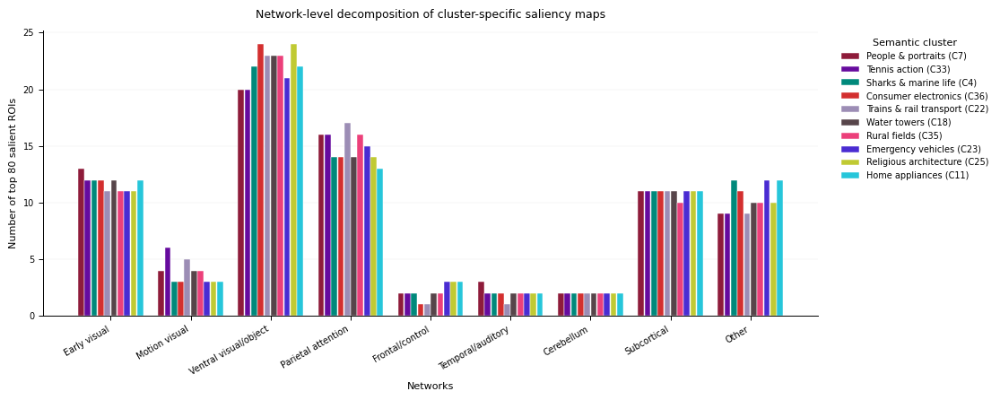

In [486]:
# ============================================================
# Grouped bar chart:
# Networks on x-axis, semantic clusters as colored bars
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


SAMPLED_CLUSTER_COLOR_LIST = [
        "#8E1B3A",  # deep cranberry
        "#660B9E",  # deep violet
        "#00897B",  # dark cyan-teal
        "#D32F2F",  # deep red
        "#9C8DB5",  # violet lavender
        "#57454A",  # warm brown
        "#EC407A",  # magenta rose
        "#4A2CD2",  # indigo
        "#C0CA33",  # lime olive
        "#26C6DA",  # cyan
    ]



selected_clusters = [int(c) for c in selected_clusters]

# Rebuild color and label maps safely
selected_cluster_color_map = {
    cid: SAMPLED_CLUSTER_COLOR_LIST[i % len(SAMPLED_CLUSTER_COLOR_LIST)]
    for i, cid in enumerate(selected_clusters)
}

selected_cluster_label_map = {
    cid: f"{CLUSTER_NAME_MAP.get(cid, f'Cluster {cid}')} (C{cid})"
    for cid in selected_clusters
}

print("Selected clusters:", selected_clusters)
print("Color-map keys:", list(selected_cluster_color_map.keys()))
print("Label-map keys:", list(selected_cluster_label_map.keys()))


def plot_top_roi_network_distribution_grouped_bar(
    top_network_counts,
    selected_clusters,
    network_order=None,
    value_col="n_top_rois",
    normalize_to_percent=False,
    save_path=None,
    figsize=(10.8, 4.4),
):
    """
    Plot grouped bars similar to the example paper figure.

    x-axis: networks
    bars: semantic clusters
    y-axis: number or percentage of top salient ROIs
    """
    set_publication_style()

    df = top_network_counts.copy()
    df["semantic_cluster"] = df["semantic_cluster"].astype(int)

    selected_clusters = [int(c) for c in selected_clusters]
    df = df[df["semantic_cluster"].isin(selected_clusters)].copy()

    if network_order is None:
        network_order = network_display_order

    network_order = [
        n for n in network_order
        if n in df["ablation_group"].unique()
    ]

    # Complete all network × cluster combinations
    complete_index = pd.MultiIndex.from_product(
        [network_order, selected_clusters],
        names=["ablation_group", "semantic_cluster"],
    )

    df_complete = (
        df.set_index(["ablation_group", "semantic_cluster"])
        .reindex(complete_index)
        .reset_index()
    )

    for col in ["n_top_rois", "top_roi_share"]:
        if col in df_complete.columns:
            df_complete[col] = df_complete[col].fillna(0)

    if normalize_to_percent:
        # percentage within each cluster's top K ROIs
        plot_col = "top_roi_share"
        y_label = f"Top {TOP_K_ROIS} salient ROIs in network (%)"
        scale = 100.0
    else:
        plot_col = value_col
        y_label = f"Number of top {TOP_K_ROIS} salient ROIs"
        scale = 1.0

    pivot = df_complete.pivot_table(
        index="ablation_group",
        columns="semantic_cluster",
        values=plot_col,
        aggfunc="mean",
        fill_value=0,
    )

    pivot = pivot.reindex(index=network_order, columns=selected_clusters)

    n_networks = len(network_order)
    n_clusters = len(selected_clusters)

    x = np.arange(n_networks)

    total_group_width = 0.82
    bar_width = total_group_width / max(n_clusters, 1)

    fig, ax = plt.subplots(figsize=figsize)

    for i, cid in enumerate(selected_clusters):
        offset = (
            -total_group_width / 2
            + bar_width / 2
            + i * bar_width
        )

        values = pivot[cid].values * scale

        ax.bar(
            x + offset,
            values,
            width=bar_width * 0.92,
            color=selected_cluster_color_map[cid],
            edgecolor="white",
            linewidth=0.35,
            label=selected_cluster_label_map.get(cid, f"Cluster {cid}"),
            zorder=3,
        )

    xlabels = [
        network_label_map.get(n, clean_ablation_name(n))
        for n in network_order
    ]

    ax.set_xticks(x)
    ax.set_xticklabels(xlabels, rotation=30, ha="right")

    ax.set_ylabel(y_label)
    ax.set_xlabel("Networks")
    ax.set_title(
        "Network-level decomposition of cluster-specific saliency maps",
        pad=10,
    )

    ax.grid(axis="y", linewidth=0.35, alpha=0.25)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        frameon=False,
        bbox_to_anchor=(1.02, 1.0),
        loc="upper left",
        title="Semantic cluster",
        title_fontsize=8,
        fontsize=7,
        ncol=1,
    )

    fig.tight_layout()

    if save_path is not None:
        save_pdf(fig, save_path)

    plt.show()

    return pivot


top_roi_grouped_bar_pivot = plot_top_roi_network_distribution_grouped_bar(
    top_network_counts=top_network_counts,
    selected_clusters=selected_clusters,
    network_order=network_display_order,
    normalize_to_percent=False,
    save_path=saliency_fig_out / f"top{TOP_K_ROIS}_roi_network_distribution_grouped_bar_counts.pdf",
    figsize=(11.2, 4.5),
)

In [487]:
# ============================================================
# Cluster-selective saliency:
# mean saliency in cluster - mean saliency outside cluster
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

SELECTIVITY_METRIC = "selectivity_z"   # options: selectivity_delta, selectivity_z, selectivity_log2
TOP_K_SELECTIVE_ROIS = 20              # try 20, 40, 80; 40 usually shows clearer selectivity
REQUIRE_POSITIVE_SELECTIVITY = True

def to_numpy_safe(x):
    if hasattr(x, "detach"):
        return x.detach().cpu().numpy()
    if hasattr(x, "cpu"):
        return x.cpu().numpy()
    return np.asarray(x)


def build_cluster_selective_saliency_df(
    saliency_matrix,
    saliency_metadata_df,
    roi_names,
    stimulus_id_to_cluster=None,
    selected_clusters=None,
):
    sal_np = to_numpy_safe(saliency_matrix)

    if sal_np.ndim != 2:
        raise RuntimeError(f"saliency_matrix must be [n_samples, n_rois], got {sal_np.shape}")

    n_samples, n_rois = sal_np.shape

    if len(roi_names) != n_rois:
        raise RuntimeError(f"len(roi_names)={len(roi_names)} does not match n_rois={n_rois}")

    meta = saliency_metadata_df.copy().reset_index(drop=True)

    if len(meta) != n_samples:
        raise RuntimeError(
            f"saliency_metadata_df length {len(meta)} does not match saliency_matrix rows {n_samples}"
        )

    if "semantic_cluster" not in meta.columns:
        if "stimulus_id" not in meta.columns:
            raise RuntimeError("Need semantic_cluster or stimulus_id in saliency_metadata_df.")

        if stimulus_id_to_cluster is None:
            raise RuntimeError("Need stimulus_id_to_cluster to recover semantic_cluster.")

        meta["semantic_cluster"] = meta["stimulus_id"].astype(int).map(stimulus_id_to_cluster)

    meta = meta.dropna(subset=["semantic_cluster"]).copy()
    meta["semantic_cluster"] = meta["semantic_cluster"].astype(int)

    sal_np = sal_np[meta.index.values]
    meta = meta.reset_index(drop=True)

    available_clusters = sorted(meta["semantic_cluster"].unique())

    if selected_clusters is None:
        clusters_to_use = available_clusters
    else:
        clusters_to_use = [int(c) for c in selected_clusters if int(c) in available_clusters]

    rows = []

    for cluster_id in clusters_to_use:
        in_mask = meta["semantic_cluster"].values == int(cluster_id)
        out_mask = ~in_mask

        n_in = int(in_mask.sum())
        n_out = int(out_mask.sum())

        if n_in == 0 or n_out == 0:
            continue

        in_vals = sal_np[in_mask]
        out_vals = sal_np[out_mask]

        mean_in = np.nanmean(in_vals, axis=0)
        mean_out = np.nanmean(out_vals, axis=0)

        delta = mean_in - mean_out

        sd_in = np.nanstd(in_vals, axis=0, ddof=1)
        sd_out = np.nanstd(out_vals, axis=0, ddof=1)

        pooled_sd = np.sqrt(
            ((n_in - 1) * sd_in**2 + (n_out - 1) * sd_out**2)
            / max(n_in + n_out - 2, 1)
        )

        selectivity_z = delta / (pooled_sd + 1e-12)

        selectivity_log2 = np.log2(
            (mean_in + 1e-12) / (mean_out + 1e-12)
        )

        for r in range(n_rois):
            rows.append({
                "semantic_cluster": int(cluster_id),
                "roi_index": int(r),
                "roi_name": roi_names[r],
                "mean_saliency_in_cluster": float(mean_in[r]),
                "mean_saliency_out_cluster": float(mean_out[r]),
                "selectivity_delta": float(delta[r]),
                "selectivity_z": float(selectivity_z[r]),
                "selectivity_log2": float(selectivity_log2[r]),
                "n_in_cluster": n_in,
                "n_out_cluster": n_out,
            })

    df = pd.DataFrame(rows)

    df["rank_selective_in_cluster"] = (
        df.groupby("semantic_cluster")[SELECTIVITY_METRIC]
        .rank(method="first", ascending=False)
        .astype(int)
    )

    df["cluster_label"] = df["semantic_cluster"].map(
        lambda c: CLUSTER_NAME_MAP.get(int(c), f"Cluster {int(c)}")
    )

    return df


selective_roi_saliency_df = build_cluster_selective_saliency_df(
    saliency_matrix=saliency_matrix,
    saliency_metadata_df=saliency_metadata_df,
    roi_names=roi_names,
    stimulus_id_to_cluster=stimulus_id_to_cluster if "stimulus_id_to_cluster" in globals() else None,
    selected_clusters=selected_clusters,
)

selective_roi_saliency_df.to_csv(
    saliency_out / "cluster_selective_roi_saliency.csv",
    index=False,
)

display(selective_roi_saliency_df.head())

display(
    selective_roi_saliency_df
    .groupby("semantic_cluster")
    .agg(
        min_selectivity=(SELECTIVITY_METRIC, "min"),
        max_selectivity=(SELECTIVITY_METRIC, "max"),
        mean_selectivity=(SELECTIVITY_METRIC, "mean"),
        n_positive=(SELECTIVITY_METRIC, lambda x: int((x > 0).sum())),
    )
    .reset_index()
)

,semantic_cluster,roi_index,roi_name,mean_saliency_in_cluster,mean_saliency_out_cluster,selectivity_delta,selectivity_z,selectivity_log2,n_in_cluster,n_out_cluster,rank_selective_in_cluster,cluster_label
0,7,0,L_1,0.002609,0.002572,0.000038,0.056844,0.020950,7172,9078,311,People & portraits
1,7,1,L_10d,0.001393,0.001294,0.000099,0.308073,0.106723,7172,9078,134,People & portraits
2,7,2,L_10pp,0.000882,0.000845,0.000036,0.203640,0.060937,7172,9078,226,People & portraits
3,7,3,L_10r,0.001052,0.000966,0.000086,0.422034,0.123516,7172,9078,46,People & portraits
4,7,4,L_10v,0.001239,0.001203,0.000036,0.158430,0.042805,7172,9078,263,People & portraits


,semantic_cluster,min_selectivity,max_selectivity,mean_selectivity,n_positive
0,4,-0.615280,0.583276,-0.002496,192
1,7,-0.678782,0.775811,0.205373,327
2,11,-0.641478,1.000475,-0.114050,102
3,18,-0.560772,0.738793,-0.149147,72
4,22,-0.804734,1.104832,-0.246138,64
5,23,-0.743013,0.693988,-0.011756,181
6,25,-0.522505,0.746936,-0.094613,92
7,33,-0.629060,1.435517,0.045889,192
8,35,-0.466967,0.594507,-0.148404,52
9,36,-0.602993,0.810076,-0.103238,102


In [488]:
# ============================================================
# Network decomposition of top cluster-selective ROIs
# ============================================================

roi_network_df = roi_group_df[["roi_index", "roi_name", "ablation_group"]].copy()
roi_network_df["roi_index"] = roi_network_df["roi_index"].astype(int)

selective_roi_saliency_df = selective_roi_saliency_df.merge(
    roi_network_df[["roi_index", "ablation_group"]],
    on="roi_index",
    how="left",
)

if selective_roi_saliency_df["ablation_group"].isna().any():
    missing = (
        selective_roi_saliency_df
        .loc[selective_roi_saliency_df["ablation_group"].isna(), "roi_index"]
        .drop_duplicates()
        .tolist()
    )
    raise RuntimeError(f"Missing network labels for ROIs: {missing[:20]}")

network_size_df = (
    roi_network_df
    .groupby("ablation_group")
    .agg(network_n_rois=("roi_index", "nunique"))
    .reset_index()
)

network_size_df["network_roi_fraction"] = (
    network_size_df["network_n_rois"] / network_size_df["network_n_rois"].sum()
)

top_selective_roi_df = selective_roi_saliency_df[
    selective_roi_saliency_df["rank_selective_in_cluster"] <= TOP_K_SELECTIVE_ROIS
].copy()

if REQUIRE_POSITIVE_SELECTIVITY:
    top_selective_roi_df = top_selective_roi_df[
        top_selective_roi_df[SELECTIVITY_METRIC] > 0
    ].copy()

top_selective_network_counts = (
    top_selective_roi_df
    .groupby(["semantic_cluster", "ablation_group"])
    .agg(
        n_top_selective_rois=("roi_index", "nunique"),
        mean_selectivity=(SELECTIVITY_METRIC, "mean"),
        sum_selectivity=(SELECTIVITY_METRIC, "sum"),
    )
    .reset_index()
)

clusters_to_use = sorted(selective_roi_saliency_df["semantic_cluster"].unique())
network_order_actual = [
    n for n in network_display_order
    if n in selective_roi_saliency_df["ablation_group"].unique()
]

complete_index = pd.MultiIndex.from_product(
    [clusters_to_use, network_order_actual],
    names=["semantic_cluster", "ablation_group"],
)

top_selective_network_counts = (
    top_selective_network_counts
    .set_index(["semantic_cluster", "ablation_group"])
    .reindex(complete_index)
    .reset_index()
)

top_selective_network_counts["n_top_selective_rois"] = (
    top_selective_network_counts["n_top_selective_rois"].fillna(0)
)

top_selective_network_counts["mean_selectivity"] = (
    top_selective_network_counts["mean_selectivity"].fillna(0)
)

top_selective_network_counts["sum_selectivity"] = (
    top_selective_network_counts["sum_selectivity"].fillna(0)
)

top_selective_network_counts = top_selective_network_counts.merge(
    network_size_df,
    on="ablation_group",
    how="left",
)

top_selective_network_counts["n_top_total_cluster"] = (
    top_selective_network_counts
    .groupby("semantic_cluster")["n_top_selective_rois"]
    .transform("sum")
)

top_selective_network_counts["expected_n_by_network_size"] = (
    top_selective_network_counts["n_top_total_cluster"]
    * top_selective_network_counts["network_roi_fraction"]
)

top_selective_network_counts["excess_n_top_selective_rois"] = (
    top_selective_network_counts["n_top_selective_rois"]
    - top_selective_network_counts["expected_n_by_network_size"]
)

top_selective_network_counts["top_selective_enrichment"] = (
    top_selective_network_counts["n_top_selective_rois"]
    / top_selective_network_counts["expected_n_by_network_size"].replace(0, np.nan)
)

top_selective_network_counts["log2_top_selective_enrichment"] = np.log2(
    top_selective_network_counts["top_selective_enrichment"].replace(0, np.nan)
)

top_selective_network_counts["cluster_label"] = top_selective_network_counts["semantic_cluster"].map(
    lambda c: CLUSTER_NAME_MAP.get(int(c), f"Cluster {int(c)}")
)

top_selective_network_counts["network_label"] = top_selective_network_counts["ablation_group"].map(
    lambda n: network_label_map.get(n, clean_ablation_name(n))
)

top_selective_network_counts.to_csv(
    saliency_out / f"top{TOP_K_SELECTIVE_ROIS}_cluster_selective_roi_network_decomposition.csv",
    index=False,
)

display(top_selective_network_counts.head())

,semantic_cluster,ablation_group,n_top_selective_rois,mean_selectivity,sum_selectivity,network_n_rois,network_roi_fraction,n_top_total_cluster,expected_n_by_network_size,excess_n_top_selective_rois,top_selective_enrichment,log2_top_selective_enrichment,cluster_label,network_label
0,4,early_visual,1.0,0.297131,0.297131,18,0.047493,20.0,0.949868,0.050132,1.052778,0.074201,Sharks & marine life,Early visual
1,4,motion_visual,0.0,0.000000,0.000000,14,0.036939,20.0,0.738786,-0.738786,0.000000,NaN,Sharks & marine life,Motion visual
2,4,ventral_visual_object_scene,6.0,0.395259,2.371551,40,0.105541,20.0,2.110818,3.889182,2.842500,1.507160,Sharks & marine life,Ventral visual/object
3,4,parietal_attention,0.0,0.000000,0.000000,46,0.121372,20.0,2.427441,-2.427441,0.000000,NaN,Sharks & marine life,Parietal attention
4,4,frontal_control,4.0,0.310735,1.242941,74,0.195251,20.0,3.905013,0.094987,1.024324,0.034673,Sharks & marine life,Frontal/control


Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/roi_saliency_maps/top20_cluster_selective_network_excess_grouped_bar.pdf


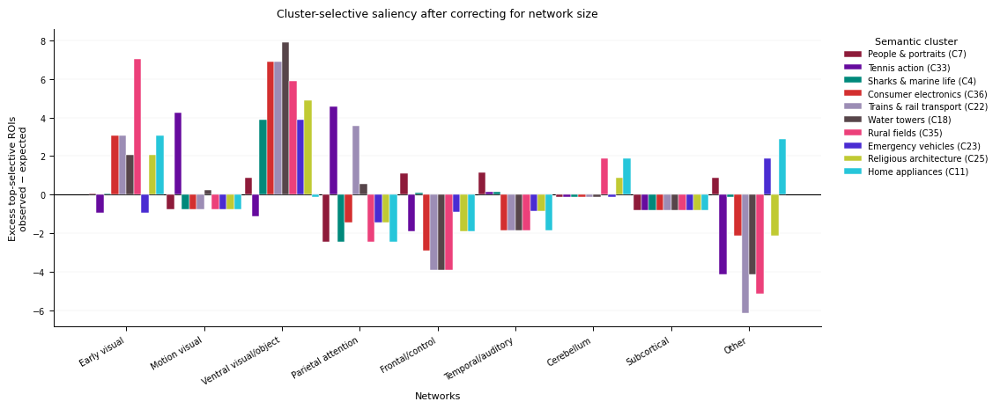

In [489]:
# ============================================================
# Plot: grouped bar of excess top-selective ROIs
# ============================================================

def plot_cluster_selective_network_excess_grouped_bar(
    top_selective_network_counts,
    selected_clusters,
    network_order=None,
    value_col="excess_n_top_selective_rois",
    save_path=None,
    figsize=(11.4, 4.7),
):
    set_publication_style()

    df = top_selective_network_counts.copy()
    df["semantic_cluster"] = df["semantic_cluster"].astype(int)

    selected_clusters = [int(c) for c in selected_clusters]

    if network_order is None:
        network_order = network_order_actual

    network_order = [n for n in network_order if n in df["ablation_group"].unique()]

    df = df[df["semantic_cluster"].isin(selected_clusters)].copy()

    pivot = df.pivot_table(
        index="ablation_group",
        columns="semantic_cluster",
        values=value_col,
        aggfunc="mean",
        fill_value=0,
    )

    pivot = pivot.reindex(index=network_order, columns=selected_clusters)

    n_networks = len(network_order)
    n_clusters = len(selected_clusters)

    # Increase horizontal separation between different networks.
    x_spacing = 2.5
    x = np.arange(n_networks) * x_spacing

    # Width occupied by all cluster bars within one network.
    # Must remain smaller than x_spacing to avoid overlap.
    total_group_width = 2.4
    bar_width = total_group_width / max(n_clusters, 1)

    fig, ax = plt.subplots(figsize=figsize)

    for i, cid in enumerate(selected_clusters):
        offset = (
            -total_group_width / 2
            + bar_width / 2
            + i * bar_width
        )

        values = pivot[cid].values

        ax.bar(
            x + offset,
            values,
            width=bar_width,
            color=selected_cluster_color_map.get(cid, "0.5"),
            edgecolor="white",
            linewidth=0.35,
            label=selected_cluster_label_map.get(
                cid,
                f"Cluster {cid}",
            ),
            zorder=3,
        )

    ax.axhline(0, color="black", linewidth=0.8)

    xlabels = [
        network_label_map.get(n, clean_ablation_name(n))
        for n in network_order
    ]

    ax.set_xticks(x)
    ax.set_xticklabels(xlabels, rotation=30, ha="right")

    ax.set_ylabel("Excess top-selective ROIs\nobserved − expected")
    ax.set_xlabel("Networks")

    ax.set_title(
        f"Cluster-selective saliency after correcting for network size",
        pad=10,
    )

    ax.grid(axis="y", linewidth=0.35, alpha=0.25)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        frameon=False,
        bbox_to_anchor=(1.02, 1.0),
        loc="upper left",
        title="Semantic cluster",
        title_fontsize=8,
        fontsize=7,
        ncol=1,
    )

    fig.tight_layout()

    if save_path is not None:
        save_pdf(fig, save_path)

    plt.show()

    return pivot


selective_network_excess_pivot = plot_cluster_selective_network_excess_grouped_bar(
    top_selective_network_counts=top_selective_network_counts,
    selected_clusters=selected_clusters,
    network_order=network_order_actual,
    save_path=saliency_fig_out / f"top{TOP_K_SELECTIVE_ROIS}_cluster_selective_network_excess_grouped_bar.pdf",
    figsize=(11.4, 4.7),
)

In [490]:
# ============================================================
# Prepare observed-count pivot for radar plots
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math


def prepare_observed_count_radar_pivot(
    top_selective_network_counts,
    selected_clusters,
    network_order=None,
):
    df = top_selective_network_counts.copy()
    df["semantic_cluster"] = df["semantic_cluster"].astype(int)

    selected_clusters = [int(c) for c in selected_clusters]

    if network_order is None:
        network_order = network_order_actual

    network_order = [
        network
        for network in network_order
        if network in df["ablation_group"].unique()
    ]

    df = df[
        df["semantic_cluster"].isin(selected_clusters)
    ].copy()

    pivot = df.pivot_table(
        index="semantic_cluster",
        columns="ablation_group",
        values="n_top_selective_rois",
        aggfunc="sum",
        fill_value=0,
    )

    pivot = pivot.reindex(
        index=selected_clusters,
        columns=network_order,
        fill_value=0,
    )

    pivot = (
        pivot
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
        .astype(int)
    )

    return pivot


observed_count_radar_pivot = prepare_observed_count_radar_pivot(
    top_selective_network_counts=top_selective_network_counts,
    selected_clusters=selected_clusters,
    network_order=network_order_actual,
)

display(observed_count_radar_pivot)

ablation_group,early_visual,motion_visual,ventral_visual_object_scene,parietal_attention,frontal_control,temporal_auditory_language,cerebellum,subcortical,other
semantic_cluster,,,,,,,,,
7,1,0,3,0,5,3,0,0,8
33,0,5,1,7,2,2,0,0,3
4,1,0,6,0,4,2,0,0,7
36,4,0,9,1,1,0,0,0,5
22,4,0,9,6,0,0,0,0,1
18,3,1,10,3,0,0,0,0,3
35,8,0,8,0,0,0,2,0,2
23,0,0,6,1,3,1,0,0,9
25,3,0,7,1,2,1,1,0,5


In [491]:
# ============================================================
# Short labels for radar axes
# ============================================================

RADAR_NETWORK_LABELS = {
    "early_visual": "Early\nvisual",
    "motion_visual": "Motion\nvisual",
    "ventral_visual_object_scene": "Ventral\nvisual/object",
    "parietal_attention": "Parietal\nattention",
    "frontal_control": "Frontal\ncontrol",
    "temporal_auditory_language": "Temporal/\nauditory",
    "cerebellum": "Cerebellum",
    "subcortical": "Subcortical",
    "other": "Other",
}


def get_radar_network_label(network_name):
    return RADAR_NETWORK_LABELS.get(
        network_name,
        clean_ablation_name(network_name),
    )

In [492]:
def plot_cluster_network_observed_count_radar_panel_publication(
    radar_pivot,
    selected_clusters,
    selected_cluster_color_map,
    selected_cluster_label_map,
    network_label_func=get_radar_network_label,
    radial_max=None,
    radial_tick_step=None,
    ncols=4,
    annotate_values=False,   # <<< remove ROI numbers by default
    save_path=None,
    figsize=None,
    title=None,

    # Typography
    network_fontsize=9.5,         # bigger network labels
    network_fontfamily="DejaVu Sans",
    network_fontweight="bold",
    network_label_color="black",

    radial_fontsize=7.2,
    cluster_title_fontsize=10.0,
    cluster_n_fontsize=8.5,
    value_fontsize=7.0,
    figure_title_fontsize=14.0,
    footer_fontsize=8.5,

    # Polygon appearance
    line_width=2.6,
    marker_size=5.4,
    fill_alpha=0.20,

    # Marker colors (circles on the polygon)
    marker_facecolor="white",      # change this if you want
    marker_edgecolor="black",      # change this if you want
    marker_edgewidth=1.2,

    # Grid / circle appearance
    radial_grid_color="#B0B7C3",   # radial circles
    angular_grid_color="#D9DCE2",
    radial_grid_width=0.9,
    angular_grid_width=0.7,
    outer_ring_color="#7A7F87",    # outermost circle
    outer_ring_width=1.0,
    show_background_bands=True,
):
    import math
    import numpy as np
    import matplotlib.pyplot as plt

    set_publication_style()

    pivot = radar_pivot.copy()
    pivot.index = pivot.index.astype(int)

    selected_clusters = [
        int(cluster_id)
        for cluster_id in selected_clusters
        if int(cluster_id) in pivot.index
    ]

    network_order = list(pivot.columns)
    n_networks = len(network_order)

    if n_networks < 3:
        raise ValueError("Radar plots require at least three networks.")

    observed_max = float(
        np.nanmax(
            pivot.loc[selected_clusters, network_order].values
        )
    )

    if radial_max is None:
        radial_max = max(5, int(np.ceil(observed_max / 2.0) * 2))

    if radial_tick_step is None:
        if radial_max <= 10:
            radial_tick_step = 2
        elif radial_max <= 20:
            radial_tick_step = 4
        else:
            radial_tick_step = 5

    radial_ticks = np.arange(
        radial_tick_step,
        radial_max + radial_tick_step,
        radial_tick_step,
    )
    radial_ticks = radial_ticks[radial_ticks <= radial_max]

    radial_boundaries = np.concatenate([[0], radial_ticks])
    if radial_boundaries[-1] < radial_max:
        radial_boundaries = np.append(radial_boundaries, radial_max)

    angles = np.linspace(0, 2 * np.pi, n_networks, endpoint=False)
    angles_closed = np.concatenate([angles, [angles[0]]])
    background_angles = np.linspace(0, 2 * np.pi, 720)

    n_clusters = len(selected_clusters)
    nrows = math.ceil(n_clusters / ncols)

    if figsize is None:
        figsize = (4.25 * ncols, 4.15 * nrows)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=figsize,
        subplot_kw={"projection": "polar"},
        squeeze=False,
    )

    fig.patch.set_facecolor("white")
    axes_flat = axes.reshape(-1)

    for ax in axes_flat:
        ax.set_visible(False)

    for panel_index, cluster_id in enumerate(selected_clusters):
        ax = axes_flat[panel_index]
        ax.set_visible(True)
        ax.set_facecolor("white")

        values = pivot.loc[cluster_id, network_order].to_numpy(dtype=float)
        values_closed = np.concatenate([values, [values[0]]])

        cluster_color = selected_cluster_color_map.get(cluster_id, "0.30")
        cluster_label = selected_cluster_label_map.get(cluster_id, f"Cluster {cluster_id}")
        total_observed = int(np.nansum(values))

        ax.set_theta_offset(np.pi / 2)
        ax.set_theta_direction(-1)
        ax.set_ylim(0, radial_max)
        ax.set_axisbelow(True)

        if show_background_bands:
            for band_index in range(len(radial_boundaries) - 1):
                if band_index % 2 == 0:
                    inner_radius = radial_boundaries[band_index]
                    outer_radius = radial_boundaries[band_index + 1]
                    ax.fill_between(
                        background_angles,
                        inner_radius,
                        outer_radius,
                        color="#F2F3F5",
                        alpha=0.80,
                        zorder=0,
                    )

        ax.set_yticks(radial_ticks)
        ax.set_yticklabels(
            [str(int(tick)) for tick in radial_ticks],
            fontsize=radial_fontsize,
            color="#50545B",
            fontweight="medium",
        )
        ax.set_rlabel_position(82)

        ax.yaxis.grid(
            True,
            color=radial_grid_color,
            linewidth=radial_grid_width,
            alpha=0.95,
            linestyle="-",
            zorder=1,
        )
        ax.xaxis.grid(
            True,
            color=angular_grid_color,
            linewidth=angular_grid_width,
            alpha=0.90,
            linestyle="-",
            zorder=1,
        )

        ax.spines["polar"].set_color(outer_ring_color)
        ax.spines["polar"].set_linewidth(outer_ring_width)

        for radial_label in ax.get_yticklabels():
            radial_label.set_bbox({
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.72,
                "pad": 0.5,
            })

        ax.fill(
            angles_closed,
            values_closed,
            color=cluster_color,
            alpha=fill_alpha,
            zorder=2,
        )

        ax.plot(
            angles_closed,
            values_closed,
            color=cluster_color,
            linewidth=line_width,
            solid_capstyle="round",
            solid_joinstyle="round",
            zorder=4,
        )

        # marker circles
        ax.scatter(
            angles,
            values,
            s=marker_size**2,
            facecolor=marker_facecolor,
            edgecolor=marker_edgecolor,
            linewidth=marker_edgewidth,
            zorder=5,
        )

        ax.set_xticks(angles)
        ax.set_xticklabels(
            [network_label_func(network) for network in network_order],
            fontsize=network_fontsize,
            color=network_label_color,
            fontweight=network_fontweight,
            fontfamily=network_fontfamily,
        )

        ax.tick_params(axis="x", pad=12)

        for angle, label in zip(np.degrees(angles), ax.get_xticklabels()):
            displayed_angle = (90 - angle) % 360
            if 20 < displayed_angle < 160:
                label.set_horizontalalignment("left")
            elif 200 < displayed_angle < 340:
                label.set_horizontalalignment("right")
            else:
                label.set_horizontalalignment("center")

        # Optional annotations
        if annotate_values:
            for angle, value in zip(angles, values):
                if not np.isfinite(value) or value <= 0:
                    continue
                text_radius = min(value + radial_max * 0.060, radial_max * 0.94)
                ax.text(
                    angle,
                    text_radius,
                    f"{int(value)}",
                    ha="center",
                    va="center",
                    fontsize=value_fontsize,
                    color=cluster_color,
                    fontweight="bold",
                    bbox={
                        "facecolor": "white",
                        "edgecolor": cluster_color,
                        "linewidth": 0.45,
                        "alpha": 0.88,
                        "boxstyle": "round,pad=0.14",
                    },
                    zorder=7,
                )

        ax.text(
            0.5,
            1.17,
            cluster_label,
            transform=ax.transAxes,
            ha="center",
            va="bottom",
            fontsize=cluster_title_fontsize,
            color=cluster_color,
            fontweight="bold",
            clip_on=False,
        )

        ax.text(
            0.5,
            1.095,
            f"$n$ = {total_observed} selected ROIs",
            transform=ax.transAxes,
            ha="center",
            va="bottom",
            fontsize=cluster_n_fontsize,
            color=cluster_color,
            fontweight="semibold",
            clip_on=False,
        )

    if title is None:
        title = (
            f"Network composition of the top "
            f"{TOP_K_SELECTIVE_ROIS} cluster-selective ROIs"
        )

    fig.suptitle(
        title,
        fontsize=figure_title_fontsize,
        fontweight="bold",
        y=0.985,
    )

    fig.text(
        0.5,
        0.018,
        "Radius indicates the observed number of selected ROIs assigned to each network.",
        ha="center",
        va="bottom",
        fontsize=footer_fontsize,
        color="#42464D",
    )

    fig.subplots_adjust(
        left=0.035,
        right=0.975,
        top=0.88,
        bottom=0.075,
        wspace=0.38,
        hspace=0.62,
    )

    if save_path is not None:
        save_pdf(fig, save_path)

    plt.show()

    return pivot

Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/roi_saliency_maps/top20_cluster_selective_network_observed_count_radar_PUBLICATION_v2.pdf


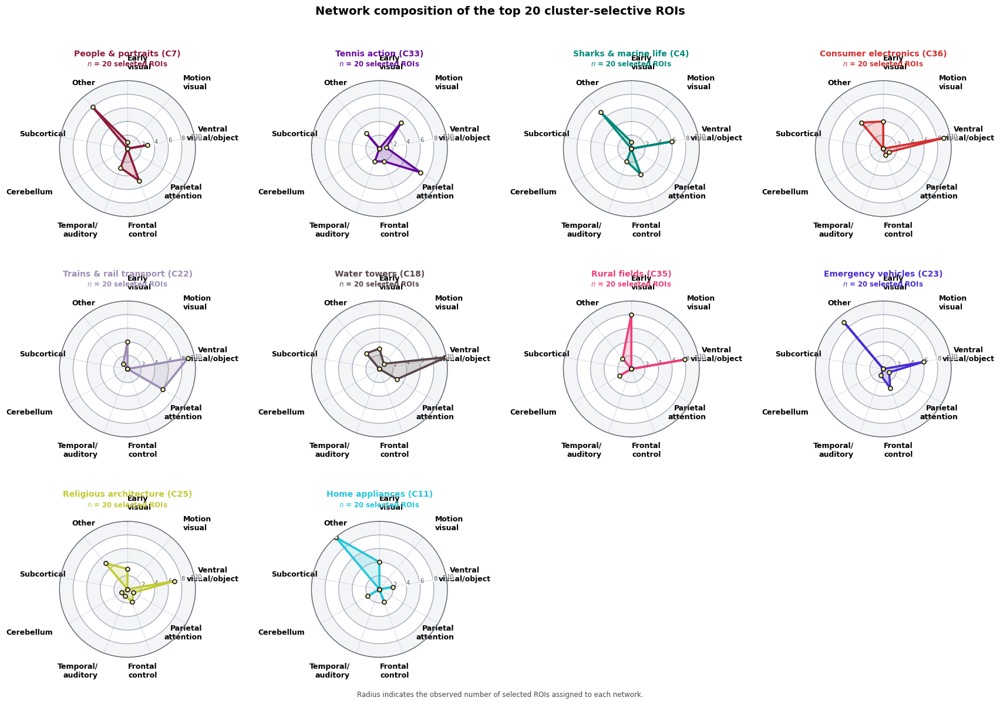

In [493]:
observed_count_radar_result_publication = (
    plot_cluster_network_observed_count_radar_panel_publication(
        radar_pivot=observed_count_radar_pivot,
        selected_clusters=selected_clusters,
        selected_cluster_color_map=selected_cluster_color_map,
        selected_cluster_label_map=selected_cluster_label_map,

        ncols=4,
        figsize=(17.0, 12.2),

        annotate_values=False,   # no numbers on the radar

        # bigger network labels
        network_fontsize=9,
        network_fontfamily="Arial",
        network_fontweight="bold",
        network_label_color="black",

        # marker circle style
        marker_facecolor="#FFF3B0",   # light yellow
        marker_edgecolor="#222222",   # dark edge
        marker_edgewidth=1.3,
        marker_size=5.,

        # circle/grid colors
        radial_grid_color="#9AA3B2",
        angular_grid_color="#D0D5DD",
        outer_ring_color="#5F6670",

        save_path=(
            saliency_fig_out
            / f"top{TOP_K_SELECTIVE_ROIS}_cluster_selective_network_observed_count_radar_PUBLICATION_v2.pdf"
        ),
    )
)

---
## Figure 5 — Semantic organization and robustness of the learned brain representation

In [494]:
# ============================================================
# CELL 1
# FIGURE 5
# Shared representation generalization and robustness
# ============================================================

from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

import matplotlib.pyplot as plt
import matplotlib as mpl

from scipy.stats import (
    spearmanr,
    wilcoxon,
    hypergeom,
)

from statsmodels.stats.multitest import multipletests


# ============================================================
# Output
# ============================================================

figure5_out = (
    Path(analysis5_out)
    / "figure5_generalization"
)

figure5_out.mkdir(
    parents=True,
    exist_ok=True,
)

figure5_fig_out = (
    Path(analysis5_fig_out)
    / "figure5_generalization"
)

figure5_fig_out.mkdir(
    parents=True,
    exist_ok=True,
)

print("Analysis output:", figure5_out)
print("Figure output:", figure5_fig_out)


# ============================================================
# Configuration
# ============================================================

FIG5_SEED = 42

TOP_K = 10

DEVICE = (
    ANALYSIS5_CONFIG["device"]
    if "ANALYSIS5_CONFIG" in globals()
    else (
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )
)


# ------------------------------------------------------------
# Panel a
# ------------------------------------------------------------

MAX_SUBJECT_PAIRS_PER_STIMULUS = 10
N_CONTROL_DRAWS_PER_PAIR = 5


# ------------------------------------------------------------
# Panel b
# ------------------------------------------------------------

MIN_STIMULI_PER_CLUSTER_RDM = 5
N_RDM_PERMUTATIONS = 2000


# ------------------------------------------------------------
# Panel c
# ------------------------------------------------------------

N_WRONG_SUBJECT_SWAPS = 3
SWAP_MAX_BATCHES = None


# ------------------------------------------------------------
# Panel d
# ------------------------------------------------------------

CANDIDATE_POOL_SIZES_REQUESTED = [
    25,
    50,
    100,
    250,
    500,
    1000,
    2500,
    5000,
    10000,
]


# ------------------------------------------------------------
# Panel e
# ------------------------------------------------------------

HARD_NEGATIVE_POOL_SIZE_TARGET = 200

HARD_NEGATIVE_FRACTIONS = [
    0.00,
    0.25,
    0.50,
    0.75,
    1.00,
]


# ------------------------------------------------------------
# Panel f
# ------------------------------------------------------------

KNN_K_VALUES = [
    5,
    10,
    20,
    50,
    100,
    250,
]

KNN_CHUNK_SIZE = 512


# ============================================================
# Dataset colours
# ============================================================

DATASET_COLORS_FIG5 = {
    "BMD": "#0072B2",
    "NSD": "#D55E00",
    "THINGS": "#009E73",
    "GOD": "#CC79A7",
    "BOLD5000": "#E69F00",
    "deeprecon": "#56B4E9",
    "NOD": "#4D4D4D",
    "HAD": "#999933",
}


# ============================================================
# Publication style
# ============================================================

mpl.rcParams.update({
    "font.family": [
        "Arial",
        "Helvetica",
        "DejaVu Sans",
    ],
    "font.size": 8.5,
    "axes.titlesize": 10.5,
    "axes.labelsize": 9.5,
    "xtick.labelsize": 8.0,
    "ytick.labelsize": 8.0,
    "legend.fontsize": 7.3,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


print("Device:", DEVICE)

Analysis output: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/figure5_generalization
Figure output: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/figure5_generalization
Device: cuda


In [495]:
# ============================================================
# CELL 2
# Prepare common retrieval objects
# ============================================================

import re


def to_numpy_safe(x):
    if hasattr(x, "detach"):
        return x.detach().cpu().numpy()

    if hasattr(x, "cpu"):
        return x.cpu().numpy()

    return np.asarray(x)


def normalize_rows(
    x,
    eps=1e-12,
):
    x = np.asarray(
        x,
        dtype=np.float32,
    )

    return (
        x
        /
        (
            np.linalg.norm(
                x,
                axis=1,
                keepdims=True,
            )
            + eps
        )
    )


def normalize_identifier(value):
    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(value).lower(),
    )


def normalize_dataset_name(value):

    value = normalize_identifier(
        value
    )

    aliases = {
        "bold": "bold5000",
        "bold5000": "bold5000",

        "thingsfmri": "things",
        "things": "things",

        "deepreconstruction": "deeprecon",
        "deeprecon": "deeprecon",

        "genericobjectdecoding": "god",
        "god": "god",

        "naturalobjectdataset": "nod",
        "nod": "nod",

        "naturalscenesdataset": "nsd",
        "nsd": "nsd",
    }

    normalized = aliases.get(
        value,
        value,
    )

    pretty_lookup = {
        "bmd": "BMD",
        "nsd": "NSD",
        "things": "THINGS",
        "god": "GOD",
        "bold5000": "BOLD5000",
        "deeprecon": "deeprecon",
        "nod": "NOD",
        "had": "HAD",
    }

    return pretty_lookup.get(
        normalized,
        str(value),
    )


def normalize_stimulus_key(value):

    if pd.isna(value):
        return None

    if isinstance(
        value,
        (int, np.integer),
    ):
        return int(value)

    if isinstance(
        value,
        (float, np.floating),
    ):
        if float(value).is_integer():
            return int(value)

    value_string = str(
        value
    ).strip()

    try:
        numeric = float(
            value_string
        )

        if numeric.is_integer():
            return int(
                numeric
            )

    except Exception:
        pass

    return value_string


# ============================================================
# Embeddings
# ============================================================

brain_embeddings_fig5 = normalize_rows(
    to_numpy_safe(
        baseline_brain
    )
)

clip_embeddings_fig5 = normalize_rows(
    to_numpy_safe(
        baseline_clip
    )
)


# ============================================================
# Metadata
# ============================================================

metadata_fig5 = (
    baseline_metadata_df
    .copy()
    .reset_index(drop=True)
)


if "stimulus_id" not in metadata_fig5.columns:

    metadata_fig5[
        "stimulus_id"
    ] = to_numpy_safe(
        baseline_stimulus_ids
    )


metadata_fig5[
    "stimulus_key"
] = (
    metadata_fig5[
        "stimulus_id"
    ]
    .map(
        normalize_stimulus_key
    )
)


metadata_fig5[
    "dataset_name"
] = (
    metadata_fig5[
        "dataset_name"
    ]
    .map(
        normalize_dataset_name
    )
)


if "subject_key" not in metadata_fig5.columns:

    metadata_fig5[
        "subject_key"
    ] = (
        metadata_fig5[
            "dataset_name"
        ].astype(str)
        + "::"
        + metadata_fig5[
            "subject_name"
        ].astype(str)
    )


# ============================================================
# Semantic clusters
# ============================================================

if (
    "semantic_cluster"
    in metadata_fig5.columns
    and
    metadata_fig5[
        "semantic_cluster"
    ].notna().all()
):

    metadata_fig5[
        "semantic_cluster"
    ] = (
        metadata_fig5[
            "semantic_cluster"
        ]
        .astype(int)
    )

else:

    metadata_fig5[
        "semantic_cluster"
    ] = (
        metadata_fig5[
            "stimulus_id"
        ]
        .map(
            stimulus_id_to_cluster
        )
    )

    if metadata_fig5[
        "semantic_cluster"
    ].isna().any():

        raise RuntimeError(
            "Some retrieval rows could not be "
            "mapped to semantic clusters."
        )

    metadata_fig5[
        "semantic_cluster"
    ] = (
        metadata_fig5[
            "semantic_cluster"
        ]
        .astype(int)
    )


# ============================================================
# Sanity checks
# ============================================================

assert (
    len(metadata_fig5)
    == len(brain_embeddings_fig5)
    == len(clip_embeddings_fig5)
)


print(
    "Rows:",
    len(metadata_fig5),
)

print(
    "Unique stimuli:",
    metadata_fig5[
        "stimulus_key"
    ].nunique(),
)

print(
    "Subjects:",
    metadata_fig5[
        "subject_key"
    ].nunique(),
)

print(
    "Datasets:",
    sorted(
        metadata_fig5[
            "dataset_name"
        ].unique()
    ),
)

print(
    "Clusters:",
    metadata_fig5[
        "semantic_cluster"
    ].nunique(),
)

Rows: 65395
Unique stimuli: 12819
Subjects: 63
Datasets: ['BMD', 'BOLD5000', 'GOD', 'NOD', 'NSD', 'THINGS', 'deeprecon']
Clusters: 40


In [496]:
# ============================================================
# CELL 3
# One CLIP candidate per unique stimulus
# ============================================================

candidate_rows_fig5 = []
candidate_clip_fig5 = []


for stimulus_key, group in metadata_fig5.groupby(
    "stimulus_key",
    sort=False,
):

    row_indices = (
        group.index
        .to_numpy(dtype=int)
    )

    mean_clip = (
        clip_embeddings_fig5[
            row_indices
        ]
        .mean(axis=0)
    )

    mean_clip = (
        mean_clip
        /
        (
            np.linalg.norm(
                mean_clip
            )
            + 1e-12
        )
    )

    cluster_values = (
        group[
            "semantic_cluster"
        ].unique()
    )

    if len(cluster_values) != 1:

        raise RuntimeError(
            f"Stimulus {stimulus_key} "
            "maps to multiple clusters."
        )

    candidate_rows_fig5.append({
        "stimulus_key":
            stimulus_key,

        "stimulus_id":
            group[
                "stimulus_id"
            ].iloc[0],

        "stimulus_clean":
            group[
                "stimulus_clean"
            ].iloc[0],

        "semantic_cluster":
            int(
                cluster_values[0]
            ),

        "n_rows":
            len(row_indices),
    })

    candidate_clip_fig5.append(
        mean_clip
    )


candidate_metadata_fig5 = (
    pd.DataFrame(
        candidate_rows_fig5
    )
    .reset_index(drop=True)
)


candidate_clip_fig5 = (
    np.stack(
        candidate_clip_fig5
    )
    .astype(np.float32)
)


stimulus_to_candidate_fig5 = {
    stimulus_key:
        index

    for index, stimulus_key
    in enumerate(
        candidate_metadata_fig5[
            "stimulus_key"
        ]
    )
}


query_true_candidate_index_fig5 = (
    metadata_fig5[
        "stimulus_key"
    ]
    .map(
        stimulus_to_candidate_fig5
    )
    .to_numpy(dtype=int)
)


candidate_cluster_fig5 = (
    candidate_metadata_fig5[
        "semantic_cluster"
    ]
    .to_numpy(dtype=int)
)


N_CANDIDATES_FIG5 = len(
    candidate_metadata_fig5
)


candidate_clip_tensor_fig5 = (
    torch.from_numpy(
        candidate_clip_fig5
    )
    .to(
        DEVICE
    )
)


print(
    "Global unique candidate pool:",
    N_CANDIDATES_FIG5,
)

Global unique candidate pool: 12819


In [497]:
# ============================================================
# CELL 4
# Global exact true-stimulus rank for every brain query
# ============================================================

GLOBAL_RANK_CACHE = (
    figure5_out
    / "fig5_global_query_ranks.csv"
)


if GLOBAL_RANK_CACHE.exists():

    print(
        "Loading cached ranks:"
    )

    print(
        GLOBAL_RANK_CACHE
    )

    query_rank_fig5_df = (
        pd.read_csv(
            GLOBAL_RANK_CACHE
        )
    )


else:

    GLOBAL_RANK_CHUNK = 512

    n_queries = len(
        metadata_fig5
    )

    true_rank = np.empty(
        n_queries,
        dtype=np.int32,
    )

    true_similarity = np.empty(
        n_queries,
        dtype=np.float32,
    )


    for start in range(
        0,
        n_queries,
        GLOBAL_RANK_CHUNK,
    ):

        stop = min(
            start + GLOBAL_RANK_CHUNK,
            n_queries,
        )


        brain_chunk = (
            torch.from_numpy(
                brain_embeddings_fig5[
                    start:stop
                ]
            )
            .to(
                DEVICE
            )
        )


        similarities = (
            brain_chunk
            @ candidate_clip_tensor_fig5.T
        )


        matched_idx = torch.as_tensor(
            query_true_candidate_index_fig5[
                start:stop
            ],
            dtype=torch.long,
            device=DEVICE,
        )


        local_rows = torch.arange(
            stop - start,
            device=DEVICE,
        )


        matched_similarity = (
            similarities[
                local_rows,
                matched_idx,
            ]
        )


        ranks = (
            (
                similarities
                >
                matched_similarity[
                    :, None
                ]
            )
            .sum(dim=1)
            + 1
        )


        true_rank[
            start:stop
        ] = (
            ranks
            .detach()
            .cpu()
            .numpy()
        )


        true_similarity[
            start:stop
        ] = (
            matched_similarity
            .detach()
            .cpu()
            .numpy()
        )


        if (
            stop % 4096 == 0
            or stop == n_queries
        ):

            print(
                f"{stop:,} / "
                f"{n_queries:,}"
            )


    query_rank_fig5_df = (
        metadata_fig5[
            [
                "stimulus_key",
                "stimulus_id",
                "semantic_cluster",
                "dataset_name",
                "subject_name",
                "subject_key",
            ]
        ]
        .copy()
    )


    query_rank_fig5_df[
        "query_index"
    ] = np.arange(
        len(
            query_rank_fig5_df
        )
    )


    query_rank_fig5_df[
        "true_rank"
    ] = true_rank


    query_rank_fig5_df[
        "true_similarity"
    ] = true_similarity


    query_rank_fig5_df[
        "top1_success"
    ] = (
        true_rank <= 1
    )


    query_rank_fig5_df[
        "top10_success"
    ] = (
        true_rank <= 10
    )


    query_rank_fig5_df.to_csv(
        GLOBAL_RANK_CACHE,
        index=False,
    )


print(
    "Global Top-10:",
    query_rank_fig5_df[
        "top10_success"
    ].mean(),
)

Loading cached ranks:
/data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/figure5_generalization/fig5_global_query_ranks.csv
Global Top-10: 0.15369676580778346


In [498]:
# ============================================================
# CELL 5
# Statistical helpers
# ============================================================

def bootstrap_mean_ci(
    values,
    n_bootstrap=5000,
    seed=42,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:

        return (
            np.nan,
            np.nan,
            np.nan,
        )


    rng = np.random.default_rng(
        seed
    )


    means = np.empty(
        n_bootstrap,
        dtype=float,
    )


    for b in range(
        n_bootstrap
    ):

        sample = rng.choice(
            values,
            size=len(values),
            replace=True,
        )

        means[b] = (
            sample.mean()
        )


    return (
        float(
            values.mean()
        ),

        float(
            np.percentile(
                means,
                2.5,
            )
        ),

        float(
            np.percentile(
                means,
                97.5,
            )
        ),
    )


def asymmetric_error(
    mean,
    low,
    high,
):

    return np.asarray([
        [
            mean - low
        ],
        [
            high - mean
        ],
    ])

### Fig. 5a — Brain–brain similarity across participant pairs

In [499]:
# ============================================================
# CELL 6
# PANEL A
#
# One predicted brain embedding for every
# subject × unique stimulus combination
# ============================================================

subject_stimulus_rows = []
subject_stimulus_embeddings = []


for (
    subject_key,
    stimulus_key,
), group in metadata_fig5.groupby(
    [
        "subject_key",
        "stimulus_key",
    ],
    sort=False,
):

    indices = (
        group.index
        .to_numpy(dtype=int)
    )


    mean_brain = (
        brain_embeddings_fig5[
            indices
        ]
        .mean(axis=0)
    )


    mean_brain = (
        mean_brain
        /
        (
            np.linalg.norm(
                mean_brain
            )
            + 1e-12
        )
    )


    subject_stimulus_rows.append({

        "subject_key":
            subject_key,

        "subject_name":
            group[
                "subject_name"
            ].iloc[0],

        "dataset_name":
            group[
                "dataset_name"
            ].iloc[0],

        "stimulus_key":
            stimulus_key,

        "stimulus_id":
            group[
                "stimulus_id"
            ].iloc[0],

        "semantic_cluster":
            int(
                group[
                    "semantic_cluster"
                ].iloc[0]
            ),
    })


    subject_stimulus_embeddings.append(
        mean_brain
    )


subject_stimulus_df = (
    pd.DataFrame(
        subject_stimulus_rows
    )
)


subject_stimulus_embeddings = (
    np.stack(
        subject_stimulus_embeddings
    )
    .astype(
        np.float32
    )
)


subject_stimulus_df[
    "embedding_index"
] = np.arange(
    len(
        subject_stimulus_df
    )
)


print(
    "Subject × stimulus rows:",
    len(
        subject_stimulus_df
    ),
)

print(
    "Stimuli shared by >=2 subject entries:",
    (
        subject_stimulus_df
        .groupby(
            "stimulus_key"
        )[
            "subject_key"
        ]
        .nunique()
        .ge(2)
        .sum()
    ),
)

Subject × stimulus rows: 21605
Stimuli shared by >=2 subject entries: 1419


In [500]:
# ============================================================
# CELL 7
# PANEL A
#
# Same stimulus, different subject entries
# vs
# same semantic cluster, different stimulus
# vs
# different semantic cluster
# ============================================================

rng = np.random.default_rng(
    FIG5_SEED
)


# ============================================================
# Lookup tables
# ============================================================

subject_to_indices = {
    subject_key:
        group[
            "embedding_index"
        ].to_numpy(dtype=int)

    for subject_key, group
    in subject_stimulus_df.groupby(
        "subject_key"
    )
}


subject_cluster_to_indices = {
    (
        subject_key,
        int(cluster_id)
    ):
        group[
            "embedding_index"
        ].to_numpy(dtype=int)

    for (
        subject_key,
        cluster_id
    ), group

    in subject_stimulus_df.groupby(
        [
            "subject_key",
            "semantic_cluster",
        ]
    )
}


def directional_control_similarity(
    source_index,
    target_subject,
    target_cluster,
    exclude_stimulus,
    same_cluster,
):

    if same_cluster:

        candidates = (
            subject_cluster_to_indices
            .get(
                (
                    target_subject,
                    int(
                        target_cluster
                    ),
                ),
                np.asarray(
                    [],
                    dtype=int,
                ),
            )
        )

    else:

        all_indices = (
            subject_to_indices[
                target_subject
            ]
        )

        candidate_clusters = (
            subject_stimulus_df.iloc[
                all_indices
            ][
                "semantic_cluster"
            ]
            .to_numpy(dtype=int)
        )

        candidates = (
            all_indices[
                candidate_clusters
                != int(
                    target_cluster
                )
            ]
        )


    if len(candidates) == 0:
        return np.nan


    candidate_stimuli = (
        subject_stimulus_df.iloc[
            candidates
        ][
            "stimulus_key"
        ]
        .to_numpy()
    )


    candidates = (
        candidates[
            candidate_stimuli
            != exclude_stimulus
        ]
    )


    if len(candidates) == 0:
        return np.nan


    n_draw = min(
        N_CONTROL_DRAWS_PER_PAIR,
        len(candidates),
    )


    sampled = rng.choice(
        candidates,
        size=n_draw,
        replace=False,
    )


    similarities = (
        subject_stimulus_embeddings[
            sampled
        ]
        @
        subject_stimulus_embeddings[
            source_index
        ]
    )


    return float(
        np.mean(
            similarities
        )
    )


# ============================================================
# Same-stimulus subject pairs
# ============================================================

cross_brain_rows = []


for stimulus_key, group in (
    subject_stimulus_df
    .groupby(
        "stimulus_key"
    )
):

    if group[
        "subject_key"
    ].nunique() < 2:

        continue


    indices = (
        group[
            "embedding_index"
        ]
        .to_numpy(dtype=int)
    )


    possible_pairs = list(
        combinations(
            indices,
            2,
        )
    )


    # Avoid stimuli seen by many participants dominating
    # the complete analysis.
    if (
        len(possible_pairs)
        >
        MAX_SUBJECT_PAIRS_PER_STIMULUS
    ):

        pair_indices = rng.choice(
            len(possible_pairs),
            size=
                MAX_SUBJECT_PAIRS_PER_STIMULUS,
            replace=False,
        )

        possible_pairs = [
            possible_pairs[i]
            for i in pair_indices
        ]


    for index_a, index_b in possible_pairs:

        row_a = (
            subject_stimulus_df.iloc[
                index_a
            ]
        )

        row_b = (
            subject_stimulus_df.iloc[
                index_b
            ]
        )


        if (
            row_a[
                "subject_key"
            ]
            ==
            row_b[
                "subject_key"
            ]
        ):

            continue


        cluster_id = int(
            row_a[
                "semantic_cluster"
            ]
        )


        same_stimulus_similarity = float(
            subject_stimulus_embeddings[
                index_a
            ]
            @
            subject_stimulus_embeddings[
                index_b
            ]
        )


        # ----------------------------------------------------
        # Same-cluster controls in both directions
        # ----------------------------------------------------

        same_ab = (
            directional_control_similarity(
                source_index=
                    index_a,
                target_subject=
                    row_b[
                        "subject_key"
                    ],
                target_cluster=
                    cluster_id,
                exclude_stimulus=
                    stimulus_key,
                same_cluster=
                    True,
            )
        )


        same_ba = (
            directional_control_similarity(
                source_index=
                    index_b,
                target_subject=
                    row_a[
                        "subject_key"
                    ],
                target_cluster=
                    cluster_id,
                exclude_stimulus=
                    stimulus_key,
                same_cluster=
                    True,
            )
        )


        same_cluster_similarity = (
            np.nanmean(
                [
                    same_ab,
                    same_ba,
                ]
            )
        )


        # ----------------------------------------------------
        # Different-cluster controls
        # ----------------------------------------------------

        diff_ab = (
            directional_control_similarity(
                source_index=
                    index_a,
                target_subject=
                    row_b[
                        "subject_key"
                    ],
                target_cluster=
                    cluster_id,
                exclude_stimulus=
                    stimulus_key,
                same_cluster=
                    False,
            )
        )


        diff_ba = (
            directional_control_similarity(
                source_index=
                    index_b,
                target_subject=
                    row_a[
                        "subject_key"
                    ],
                target_cluster=
                    cluster_id,
                exclude_stimulus=
                    stimulus_key,
                same_cluster=
                    False,
            )
        )


        different_cluster_similarity = (
            np.nanmean(
                [
                    diff_ab,
                    diff_ba,
                ]
            )
        )


        if not (
            np.isfinite(
                same_cluster_similarity
            )
            and
            np.isfinite(
                different_cluster_similarity
            )
        ):

            continue


        subject_pair = "::PAIR::".join(
            sorted([
                str(
                    row_a[
                        "subject_key"
                    ]
                ),
                str(
                    row_b[
                        "subject_key"
                    ]
                ),
            ])
        )


        dataset_relation = (
            "Same dataset"
            if (
                row_a[
                    "dataset_name"
                ]
                ==
                row_b[
                    "dataset_name"
                ]
            )
            else
            "Different datasets"
        )


        cross_brain_rows.append({

            "stimulus_key":
                stimulus_key,

            "semantic_cluster":
                cluster_id,

            "subject_pair":
                subject_pair,

            "dataset_a":
                row_a[
                    "dataset_name"
                ],

            "dataset_b":
                row_b[
                    "dataset_name"
                ],

            "dataset_relation":
                dataset_relation,

            "same_stimulus_similarity":
                same_stimulus_similarity,

            "same_cluster_nonmatch_similarity":
                same_cluster_similarity,

            "different_cluster_similarity":
                different_cluster_similarity,
        })


cross_brain_query_df = (
    pd.DataFrame(
        cross_brain_rows
    )
)


# ============================================================
# Subject-pair level statistics
# ============================================================

cross_brain_pair_df = (
    cross_brain_query_df
    .groupby(
        [
            "subject_pair",
            "dataset_relation",
        ],
        as_index=False,
    )
    .agg(

        n_shared_stimuli=(
            "stimulus_key",
            "nunique",
        ),

        same_stimulus_similarity=(
            "same_stimulus_similarity",
            "mean",
        ),

        same_cluster_nonmatch_similarity=(
            "same_cluster_nonmatch_similarity",
            "mean",
        ),

        different_cluster_similarity=(
            "different_cluster_similarity",
            "mean",
        ),
    )
)


cross_brain_pair_df[
    "same_minus_samecluster"
] = (
    cross_brain_pair_df[
        "same_stimulus_similarity"
    ]
    -
    cross_brain_pair_df[
        "same_cluster_nonmatch_similarity"
    ]
)


cross_brain_pair_df[
    "samecluster_minus_different"
] = (
    cross_brain_pair_df[
        "same_cluster_nonmatch_similarity"
    ]
    -
    cross_brain_pair_df[
        "different_cluster_similarity"
    ]
)


print(
    "Subject pairs:",
    len(
        cross_brain_pair_df
    ),
)

print(
    "\nDataset relation:"
)

display(
    cross_brain_pair_df[
        "dataset_relation"
    ]
    .value_counts()
)


test_same = wilcoxon(
    cross_brain_pair_df[
        "same_minus_samecluster"
    ],
    alternative="greater",
)


test_semantic = wilcoxon(
    cross_brain_pair_df[
        "samecluster_minus_different"
    ],
    alternative="greater",
)


print(
    "Same stimulus > same-cluster nonmatch:",
    test_same.pvalue,
)

print(
    "Same cluster > different cluster:",
    test_semantic.pvalue,
)


cross_brain_pair_df.to_csv(
    figure5_out
    / "panel_a_cross_brain_convergence.csv",
    index=False,
)

/tmp/ipykernel_2335159/2514348864.py:312: RuntimeWarning: Mean of empty slice
  np.nanmean(


Subject pairs: 176

Dataset relation:


dataset_relation
Same dataset          131
Different datasets     45
Name: count, dtype: int64

Same stimulus > same-cluster nonmatch: 6.303600657448378e-31
Same cluster > different cluster: 8.287830134372741e-31


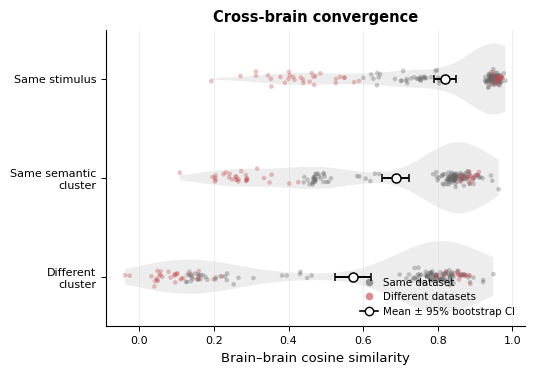

In [501]:
# ============================================================
# CELL 8
# PANEL A plot
# ============================================================

from matplotlib.lines import Line2D

def draw_panel_a(
    ax,
    cross_brain_pair_df,
):

    columns = [
        "same_stimulus_similarity",
        "same_cluster_nonmatch_similarity",
        "different_cluster_similarity",
    ]

    labels = [
        "Same stimulus",
        "Same semantic\ncluster",
        "Different\ncluster",
    ]


    values = [
        cross_brain_pair_df[
            column
        ].to_numpy(dtype=float)

        for column
        in columns
    ]


    positions = np.asarray([
        2,
        1,
        0,
    ])


    # ========================================================
    # Violin distributions
    # ========================================================

    violin = ax.violinplot(
        values,
        positions=positions,
        vert=False,
        widths=0.72,
        showextrema=False,
        showmeans=False,
        showmedians=False,
    )


    for body in violin[
        "bodies"
    ]:

        body.set_facecolor(
            "#D9D9D9"
        )

        body.set_alpha(
            0.45
        )

        body.set_edgecolor(
            "none"
        )


    # ========================================================
    # Individual subject-pair estimates
    # ========================================================

    rng_local = np.random.default_rng(
        52
    )


    pair_colors = {
        "Same dataset":
            "#666666",

        "Different datasets":
            "#C44E52",
    }


    for condition_index, (
        column,
        y_position,
    ) in enumerate(
        zip(
            columns,
            positions,
        )
    ):

        for relation, color in (
            pair_colors.items()
        ):

            subset = (
                cross_brain_pair_df[
                    cross_brain_pair_df[
                        "dataset_relation"
                    ].eq(
                        relation
                    )
                ]
            )


            jitter = rng_local.normal(
                0,
                0.035,
                size=len(
                    subset
                ),
            )


            ax.scatter(
                subset[
                    column
                ],
                y_position
                + jitter,

                s=11,

                alpha=0.35,

                color=color,

                edgecolor="none",

                rasterized=True,

                zorder=3,
            )


        # ====================================================
        # Mean ± 95% bootstrap CI
        # ====================================================

        mean, low, high = (
            bootstrap_mean_ci(
                cross_brain_pair_df[
                    column
                ],
                seed=
                    100
                    + condition_index,
            )
        )


        ax.errorbar(
            mean,
            y_position,

            xerr=
                asymmetric_error(
                    mean,
                    low,
                    high,
                ),

            fmt="o",

            color="black",

            markerfacecolor="white",

            markeredgecolor="black",

            markeredgewidth=1.1,

            markersize=6.5,

            capsize=3,

            linewidth=1.4,

            zorder=10,
        )


    # ========================================================
    # Axes
    # ========================================================

    ax.set_yticks(
        positions
    )

    ax.set_yticklabels(
        labels
    )


    ax.set_xlabel(
        "Brain–brain cosine similarity"
    )


    ax.set_title(
        "Cross-brain convergence",
        fontweight="bold",
    )


    ax.grid(
        axis="x",
        color="#D8D8D8",
        linewidth=0.6,
        alpha=0.55,
    )

    ax.set_axisbelow(
        True
    )


    # ========================================================
    # Legend
    # ========================================================

    legend_handles = [

        Line2D(
            [0],
            [0],

            marker="o",

            linestyle="none",

            markerfacecolor=
                pair_colors[
                    "Same dataset"
                ],

            markeredgecolor="none",

            markersize=5.5,

            alpha=0.65,

            label="Same dataset",
        ),


        Line2D(
            [0],
            [0],

            marker="o",

            linestyle="none",

            markerfacecolor=
                pair_colors[
                    "Different datasets"
                ],

            markeredgecolor="none",

            markersize=5.5,

            alpha=0.65,

            label="Different datasets",
        ),


        Line2D(
            [0],
            [0],

            marker="o",

            linestyle="-",

            color="black",

            markerfacecolor="white",

            markeredgecolor="black",

            markeredgewidth=1.0,

            linewidth=1.2,

            markersize=6,

            label="Mean ± 95% bootstrap CI",
        ),
    ]


    ax.legend(
        handles=
            legend_handles,

        frameon=False,

        fontsize=7.4,

        loc="lower right",

        handlelength=1.7,

        handletextpad=0.55,

        borderaxespad=0.5,

        labelspacing=0.45,
    )

fig, ax = plt.subplots(
    figsize=(5.4, 3.8)
)

draw_panel_a(
    ax,
    cross_brain_pair_df,
)

fig.tight_layout()

fig.savefig(
    figure5_fig_out
    / "panel_a_cross_brain_convergence.pdf",
    bbox_inches="tight",
)

plt.show()

### Fig. 5b — Cross-dataset correspondence of semantic representational geometry

In [502]:
# ============================================================
# CELL 9
# PANEL B
#
# Dataset-specific semantic geometry
# ============================================================

dataset_stimulus_rows = []
dataset_stimulus_embeddings = []


# ============================================================
# One brain embedding per dataset × unique stimulus
# ============================================================

for (
    dataset_name,
    stimulus_key,
), group in metadata_fig5.groupby(
    [
        "dataset_name",
        "stimulus_key",
    ],
    sort=False,
):

    indices = (
        group.index
        .to_numpy(dtype=int)
    )


    mean_brain = (
        brain_embeddings_fig5[
            indices
        ]
        .mean(axis=0)
    )


    mean_brain = (
        mean_brain
        /
        (
            np.linalg.norm(
                mean_brain
            )
            + 1e-12
        )
    )


    dataset_stimulus_rows.append({

        "dataset_name":
            dataset_name,

        "stimulus_key":
            stimulus_key,

        "semantic_cluster":
            int(
                group[
                    "semantic_cluster"
                ].iloc[0]
            ),
    })


    dataset_stimulus_embeddings.append(
        mean_brain
    )


dataset_stimulus_df = (
    pd.DataFrame(
        dataset_stimulus_rows
    )
)


dataset_stimulus_embeddings = (
    np.stack(
        dataset_stimulus_embeddings
    )
)


dataset_stimulus_df[
    "embedding_index"
] = np.arange(
    len(
        dataset_stimulus_df
    )
)


# ============================================================
# Dataset × semantic-cluster centroid
# ============================================================

dataset_cluster_centroid_dict = {}


for (
    dataset_name,
    cluster_id,
), group in dataset_stimulus_df.groupby(
    [
        "dataset_name",
        "semantic_cluster",
    ]
):

    indices = (
        group[
            "embedding_index"
        ]
        .to_numpy(dtype=int)
    )


    if (
        len(indices)
        <
        MIN_STIMULI_PER_CLUSTER_RDM
    ):

        continue


    centroid = (
        dataset_stimulus_embeddings[
            indices
        ]
        .mean(axis=0)
    )


    centroid = (
        centroid
        /
        (
            np.linalg.norm(
                centroid
            )
            + 1e-12
        )
    )


    dataset_cluster_centroid_dict[
        (
            dataset_name,
            int(
                cluster_id
            ),
        )
    ] = centroid


datasets_rdm = sorted(
    dataset_stimulus_df[
        "dataset_name"
    ].unique()
)


# ============================================================
# Pairwise RDM correspondence
# ============================================================

rdm_rows = []


for dataset_a, dataset_b in combinations(
    datasets_rdm,
    2,
):

    clusters_a = {
        cluster_id

        for dataset_name, cluster_id
        in dataset_cluster_centroid_dict

        if dataset_name
        == dataset_a
    }


    clusters_b = {
        cluster_id

        for dataset_name, cluster_id
        in dataset_cluster_centroid_dict

        if dataset_name
        == dataset_b
    }


    common_clusters = sorted(
        clusters_a
        &
        clusters_b
    )


    if len(
        common_clusters
    ) < 5:

        continue


    centroids_a = np.stack([
        dataset_cluster_centroid_dict[
            (
                dataset_a,
                cluster_id,
            )
        ]

        for cluster_id
        in common_clusters
    ])


    centroids_b = np.stack([
        dataset_cluster_centroid_dict[
            (
                dataset_b,
                cluster_id,
            )
        ]

        for cluster_id
        in common_clusters
    ])


    rdm_a = (
        1
        -
        centroids_a
        @ centroids_a.T
    )


    rdm_b = (
        1
        -
        centroids_b
        @ centroids_b.T
    )


    upper = np.triu_indices(
        len(
            common_clusters
        ),
        k=1,
    )


    vector_a = (
        rdm_a[
            upper
        ]
    )

    vector_b = (
        rdm_b[
            upper
        ]
    )


    observed_rho = (
        spearmanr(
            vector_a,
            vector_b,
        ).statistic
    )


    # --------------------------------------------------------
    # Mantel-style cluster permutation
    # --------------------------------------------------------

    rng_local = np.random.default_rng(
        FIG5_SEED
        + len(
            rdm_rows
        )
    )


    null_rho = np.empty(
        N_RDM_PERMUTATIONS,
        dtype=float,
    )


    for permutation_index in range(
        N_RDM_PERMUTATIONS
    ):

        permutation = (
            rng_local.permutation(
                len(
                    common_clusters
                )
            )
        )


        permuted_b = (
            rdm_b[
                permutation
            ][
                :,
                permutation
            ]
        )


        null_rho[
            permutation_index
        ] = (
            spearmanr(
                vector_a,
                permuted_b[
                    upper
                ],
            ).statistic
        )


    p_value = (
        1
        +
        np.sum(
            null_rho
            >= observed_rho
        )
    ) / (
        N_RDM_PERMUTATIONS
        + 1
    )


    rdm_rows.append({

        "dataset_a":
            dataset_a,

        "dataset_b":
            dataset_b,

        "n_common_clusters":
            len(
                common_clusters
            ),

        "spearman_rho":
            observed_rho,

        "permutation_p":
            p_value,
    })


dataset_rdm_correspondence_df = (
    pd.DataFrame(
        rdm_rows
    )
)


# ============================================================
# FDR correction
# ============================================================

if len(
    dataset_rdm_correspondence_df
) > 0:

    dataset_rdm_correspondence_df[
        "permutation_q"
    ] = multipletests(
        dataset_rdm_correspondence_df[
            "permutation_p"
        ],
        method="fdr_bh",
    )[1]


dataset_rdm_correspondence_df.to_csv(
    figure5_out
    / "panel_b_cross_dataset_rdm_correspondence.csv",
    index=False,
)


display(
    dataset_rdm_correspondence_df.round(
        4
    )
)

,dataset_a,dataset_b,n_common_clusters,spearman_rho,permutation_p,permutation_q
0,BOLD5000,NOD,9,0.6425,0.0040,0.0050
1,BOLD5000,NSD,9,0.6360,0.0005,0.0008
2,NOD,NSD,25,0.6058,0.0005,0.0008
3,NOD,THINGS,7,0.8792,0.0005,0.0008
4,NSD,THINGS,5,0.8545,0.0210,0.0210


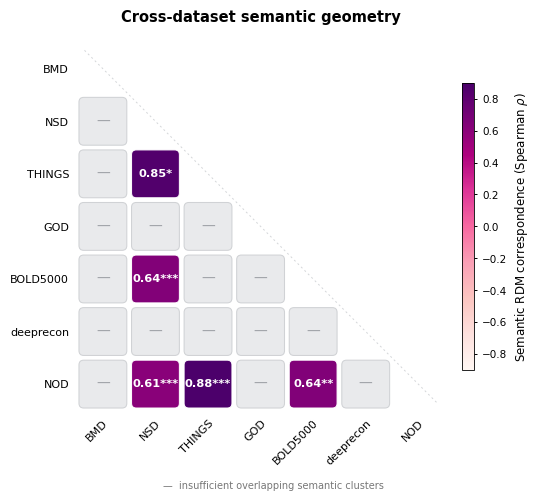

In [503]:
# ============================================================
# CELL 10
# PANEL B
#
# Triangular cross-dataset semantic-geometry matrix
#
# - Lower triangle only
# - Diagonal omitted because rho = 1 by definition
# - Rounded separated tiles
# - Diverging colormap centred at rho = 0
# - Significance stars from FDR-corrected permutation q-values
# - Missing comparisons shown in light grey with an em dash
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from matplotlib.colors import (
    LinearSegmentedColormap,
    TwoSlopeNorm,
)
from matplotlib.patches import FancyBboxPatch
from matplotlib.cm import ScalarMappable


# ============================================================
# 1. Significance labels
# ============================================================

def significance_star(q):

    if not np.isfinite(q):
        return ""

    if q < 0.001:
        return "***"

    if q < 0.01:
        return "**"

    if q < 0.05:
        return "*"

    return ""


# ============================================================
# 2. Dataset ordering
# ============================================================

dataset_order_rdm = [
    dataset
    for dataset
    in [
        "BMD",
        "NSD",
        "THINGS",
        "GOD",
        "BOLD5000",
        "deeprecon",
        "NOD",
        "HAD",
    ]
    if dataset
    in datasets_rdm
]


# ============================================================
# 3. Build symmetric rho / q matrices
# ============================================================

def build_rdm_matrix():

    n = len(
        dataset_order_rdm
    )

    matrix = np.full(
        (n, n),
        np.nan,
        dtype=float,
    )

    q_matrix = np.full(
        (n, n),
        np.nan,
        dtype=float,
    )

    n_cluster_matrix = np.full(
        (n, n),
        np.nan,
        dtype=float,
    )


    lookup = {
        (
            row["dataset_a"],
            row["dataset_b"],
        ): row

        for _, row
        in dataset_rdm_correspondence_df.iterrows()
    }


    for i, dataset_a in enumerate(
        dataset_order_rdm
    ):

        for j, dataset_b in enumerate(
            dataset_order_rdm
        ):

            if i == j:
                continue


            key = (
                dataset_a,
                dataset_b,
            )

            reverse = (
                dataset_b,
                dataset_a,
            )


            if key in lookup:
                row = lookup[key]

            elif reverse in lookup:
                row = lookup[reverse]

            else:
                continue


            matrix[
                i,
                j
            ] = float(
                row[
                    "spearman_rho"
                ]
            )


            q_matrix[
                i,
                j
            ] = float(
                row.get(
                    "permutation_q",
                    np.nan,
                )
            )


            n_cluster_matrix[
                i,
                j
            ] = float(
                row.get(
                    "n_common_clusters",
                    np.nan,
                )
            )


    return (
        matrix,
        q_matrix,
        n_cluster_matrix,
    )


(
    rdm_matrix_fig5,
    rdm_q_matrix_fig5,
    rdm_n_clusters_fig5,
) = build_rdm_matrix()


# ============================================================
# 4. Fancy publication colormap
#
# Negative rho:
#   navy / blue
#
# rho ~ 0:
#   warm ivory
#
# Positive rho:
#   coral -> burgundy
# ============================================================


semantic_geometry_cmap = (
    plt.get_cmap(
        "RdPu"
    ).copy()
)


# Missing comparisons remain clearly distinct
semantic_geometry_cmap.set_bad(
    "#E9EAEC"
)


# ============================================================
# 5. Shared normalization
# ============================================================

# ============================================================
# 5. Shared normalization
# ============================================================

off_diagonal_values = (
    rdm_matrix_fig5[
        ~np.eye(
            len(
                rdm_matrix_fig5
            ),
            dtype=bool,
        )
    ]
)


finite_values = (
    off_diagonal_values[
        np.isfinite(
            off_diagonal_values
        )
    ]
)


if len(finite_values) == 0:
    raise RuntimeError(
        "No finite cross-dataset RDM correlations "
        "were available for plotting."
    )


abs_limit = max(
    0.90,
    float(
        np.nanmax(
            np.abs(
                finite_values
            )
        )
    ),
)


norm = mcolors.Normalize(
    vmin=-abs_limit,
    vmax=abs_limit,
)


# ============================================================
# 6. Drawing function
# ============================================================

def draw_panel_b(
    ax,
    show_n_common_clusters=False,
):

    n = len(
        dataset_order_rdm
    )


    # --------------------------------------------------------
    # Geometry / appearance
    # --------------------------------------------------------

    tile_size = 0.88

    tile_offset = (
        1.0
        - tile_size
    ) / 2


    missing_facecolor = (
        "#E9EAEC"
    )

    missing_edgecolor = (
        "#D0D2D5"
    )


    # ========================================================
    # Lower triangle only
    # ========================================================

    for i in range(n):

        for j in range(n):

            # Only plot cells strictly below diagonal
            if i <= j:
                continue


            value = (
                rdm_matrix_fig5[
                    i,
                    j
                ]
            )


            q_value = (
                rdm_q_matrix_fig5[
                    i,
                    j
                ]
            )


            n_common = (
                rdm_n_clusters_fig5[
                    i,
                    j
                ]
            )


            # ------------------------------------------------
            # Valid comparison
            # ------------------------------------------------

            if np.isfinite(
                value
            ):

                facecolor = (
                    semantic_geometry_cmap(
                        norm(
                            value
                        )
                    )
                )

                edgecolor = (
                    mcolors.to_rgba(
                        "#FFFFFF",
                        alpha=0.95,
                    )
                )


            # ------------------------------------------------
            # Insufficient overlap / missing comparison
            # ------------------------------------------------

            else:

                facecolor = (
                    missing_facecolor
                )

                edgecolor = (
                    missing_edgecolor
                )


            # ------------------------------------------------
            # Rounded tile
            # ------------------------------------------------

            tile = FancyBboxPatch(

                (
                    j
                    - 0.5
                    + tile_offset,

                    i
                    - 0.5
                    + tile_offset,
                ),

                tile_size,
                tile_size,

                boxstyle=(
                    "round,pad=0.015,"
                    "rounding_size=0.09"
                ),

                linewidth=0.75,

                edgecolor=edgecolor,

                facecolor=facecolor,

                zorder=2,
            )


            ax.add_patch(
                tile
            )


            # =================================================
            # Cell annotation
            # =================================================

            if np.isfinite(
                value
            ):

                star = (
                    significance_star(
                        q_value
                    )
                )


                # Strong tiles get white annotation
                text_color = (
                    "white"
                    if abs(
                        value
                    ) >= 0.52
                    else "#222222"
                )


                if (
                    show_n_common_clusters
                    and np.isfinite(
                        n_common
                    )
                ):

                    # rho on first line,
                    # number of common clusters beneath
                    ax.text(

                        j,
                        i - 0.07,

                        (
                            f"{value:.2f}"
                            f"{star}"
                        ),

                        ha="center",
                        va="center",

                        fontsize=12,

                        fontweight="bold",

                        color=text_color,

                        zorder=5,
                    )


                    ax.text(

                        j,
                        i + 0.22,

                        (
                            f"$n_c$="
                            f"{int(n_common)}"
                        ),

                        ha="center",
                        va="center",

                        fontsize=5.7,

                        color=text_color,

                        alpha=0.88,

                        zorder=5,
                    )


                else:

                    ax.text(

                        j,
                        i,

                        (
                            f"{value:.2f}"
                            f"{star}"
                        ),

                        ha="center",
                        va="center",

                        fontsize=8.2,

                        fontweight="bold",

                        color=text_color,

                        zorder=5,
                    )


            else:

                # Explicitly distinguish unavailable
                # comparisons from rho = 0
                ax.text(

                    j,
                    i,

                    "—",

                    ha="center",
                    va="center",

                    fontsize=10,

                    color="#A0A3A8",

                    zorder=5,
                )


    # ========================================================
    # Axis labels
    # ========================================================

    ax.set_xticks(
        np.arange(n)
    )

    ax.set_xticklabels(
        dataset_order_rdm,
        rotation=45,
        ha="right",
        rotation_mode="anchor",
    )


    ax.set_yticks(
        np.arange(n)
    )

    ax.set_yticklabels(
        dataset_order_rdm
    )


    # ========================================================
    # Limits
    #
    # Keep square coordinate system but only lower triangle
    # contains information.
    # ========================================================

    ax.set_xlim(
        -0.55,
        n - 0.45,
    )

    ax.set_ylim(
        n - 0.45,
        -0.55,
    )


    ax.set_aspect(
        "equal"
    )


    # ========================================================
    # Remove conventional heatmap frame
    # ========================================================

    for spine in (
        ax.spines.values()
    ):

        spine.set_visible(
            False
        )


    ax.tick_params(
        axis="both",
        which="both",
        length=0,
    )


    # ========================================================
    # Light diagonal guide
    # ========================================================

    ax.plot(
        [
            -0.35,
            n - 0.65,
        ],
        [
            -0.35,
            n - 0.65,
        ],
        color="#D4D6D9",
        linewidth=0.7,
        linestyle=(0, (2, 3)),
        zorder=0,
    )


    # ========================================================
    # Title
    # ========================================================

    ax.set_title(
        "Cross-dataset semantic geometry",
        fontweight="bold",
        pad=13,
    )


    # ========================================================
    # Colorbar-compatible mappable
    # ========================================================

    scalar_mappable = (
        ScalarMappable(
            norm=norm,
            cmap=
                'RdPu',
        )
    )

    scalar_mappable.set_array([])


    return scalar_mappable


# ============================================================
# 7. Draw standalone panel
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        5.5,
        5.0,
    )
)


image = draw_panel_b(
    ax,

    # Set True if you want the number of overlapping
    # semantic clusters shown below rho in every cell.
    show_n_common_clusters=False,
)


# ============================================================
# 8. Colorbar
# ============================================================

cbar = fig.colorbar(

    image,

    ax=ax,

    fraction=0.042,

    pad=0.035,

    shrink=0.77,

    aspect=24,
)


cbar.set_label(
    "Semantic RDM correspondence "
    "(Spearman $\\rho$)",
    fontsize=8.5,
)


cbar.ax.tick_params(
    labelsize=7.5,
    length=2.5,
)


cbar.outline.set_linewidth(
    0.6
)


# ============================================================
# 9. Small note for unavailable cells
# ============================================================

fig.text(

    0.51,
    0.012,

    "—  insufficient overlapping semantic clusters",

    ha="center",
    va="bottom",

    fontsize=7.0,

    color="#777777",
)


# ============================================================
# 10. Save
# ============================================================

fig.tight_layout(
    rect=[
        0,
        0.035,
        1,
        1,
    ]
)


fig.savefig(
    figure5_fig_out
    / "panel_b_cross_dataset_semantic_geometry_TRIANGULAR.pdf",
    bbox_inches="tight",
)


fig.savefig(
    figure5_fig_out
    / "panel_b_cross_dataset_semantic_geometry_TRIANGULAR.png",
    dpi=500,
    bbox_inches="tight",
)


plt.show()

### Fig. 5c — Candidate-pool stress test

In [504]:
# ============================================================
# CELL 15
# PANEL c
#
# Exact candidate-pool stress test
# using the hypergeometric distribution
# ============================================================

candidate_pool_sizes = sorted(
    set(
        [
            size
            for size
            in CANDIDATE_POOL_SIZES_REQUESTED
            if size
            <= N_CANDIDATES_FIG5
        ]
        +
        [
            N_CANDIDATES_FIG5
        ]
    )
)


candidate_pool_rows = []


true_ranks = (
    query_rank_fig5_df[
        "true_rank"
    ]
    .to_numpy(dtype=int)
)


# Population of distractors
population_size = (
    N_CANDIDATES_FIG5
    - 1
)


# Number of distractors better than target
better_distractors = (
    true_ranks
    - 1
)


for pool_size in candidate_pool_sizes:

    n_draw_distractors = (
        pool_size
        - 1
    )


    # --------------------------------------------------------
    # Probability target appears in Top-10
    # --------------------------------------------------------

    top10_probability = hypergeom.cdf(
        TOP_K - 1,
        population_size,
        better_distractors,
        n_draw_distractors,
    )


    # --------------------------------------------------------
    # Probability target is rank 1
    # --------------------------------------------------------

    top1_probability = hypergeom.cdf(
        0,
        population_size,
        better_distractors,
        n_draw_distractors,
    )


    block = (
        query_rank_fig5_df[
            [
                "dataset_name",
                "subject_name",
                "subject_key",
            ]
        ]
        .copy()
    )


    block[
        "candidate_pool_size"
    ] = pool_size


    block[
        "expected_top1"
    ] = top1_probability


    block[
        "expected_top10"
    ] = top10_probability


    candidate_pool_rows.append(
        block
    )


candidate_pool_query_df = (
    pd.concat(
        candidate_pool_rows,
        ignore_index=True,
    )
)


candidate_pool_subject_df = (
    candidate_pool_query_df
    .groupby(
        [
            "subject_key",
            "dataset_name",
            "subject_name",
            "candidate_pool_size",
        ],
        as_index=False,
    )
    .agg(

        expected_top1=(
            "expected_top1",
            "mean",
        ),

        expected_top10=(
            "expected_top10",
            "mean",
        ),
    )
)


candidate_pool_subject_df.to_csv(
    figure5_out
    / "panel_d_candidate_pool_stress.csv",
    index=False,
)


display(
    candidate_pool_subject_df.head()
)

,subject_key,dataset_name,subject_name,candidate_pool_size,expected_top1,expected_top10
0,BMD::sub-01,BMD,sub-01,25,0.963927,1.000000
1,BMD::sub-01,BMD,sub-01,50,0.930239,1.000000
2,BMD::sub-01,BMD,sub-01,100,0.871206,0.999992
3,BMD::sub-01,BMD,sub-01,250,0.736587,0.998921
4,BMD::sub-01,BMD,sub-01,500,0.592192,0.995798


In [505]:
from matplotlib.lines import Line2D


# ============================================================
# Consistent dataset order for Fig. 5
# ============================================================

DATASET_ORDER_FIG5 = [
    "BMD",
    "BOLD5000",
    "GOD",
    "NOD",
    "NSD",
    "THINGS",
    "deeprecon",
]


def make_fig5_retrieval_legend_handles(
    dataframe,
):

    datasets_present = set(
        dataframe[
            "dataset_name"
        ].unique()
    )


    ordered_datasets = [
        dataset_name
        for dataset_name
        in DATASET_ORDER_FIG5
        if dataset_name
        in datasets_present
    ]


    # Include any unexpected dataset names as well.
    extra_datasets = sorted(
        datasets_present
        - set(
            ordered_datasets
        )
    )

    ordered_datasets += (
        extra_datasets
    )


    handles = []


    # Dataset-specific handles
    for dataset_name in (
        ordered_datasets
    ):

        handles.append(
            Line2D(
                [0],
                [0],
                color=
                    DATASET_COLORS_FIG5
                    .get(
                        dataset_name,
                        "#777777",
                    ),
                linewidth=1.2,
                marker="o",
                markersize=4,
                alpha=0.70,
                label=dataset_name,
            )
        )


    # Overall
    handles.append(
        Line2D(
            [0],
            [0],
            color="black",
            linewidth=2.4,
            marker="o",
            markersize=5,
            label="Across subjects",
        )
    )


    # Chance
    handles.append(
        Line2D(
            [0],
            [0],
            color="#888888",
            linewidth=1.2,
            linestyle="--",
            label="Chance",
        )
    )


    return handles

In [506]:
# ============================================================
# CELL 16
# PANEL c plot
# ============================================================


def draw_panel_c(
    ax,
    candidate_pool_subject_df,
):

    # ========================================================
    # Dataset-specific trajectories
    # ========================================================

    for dataset_name, group in (
        candidate_pool_subject_df
        .groupby(
            "dataset_name"
        )
    ):

        summary = (
            group
            .groupby(
                "candidate_pool_size",
                as_index=False,
            )
            .agg(
                mean_top10=(
                    "expected_top10",
                    "mean",
                )
            )
        )


        ax.plot(
            summary[
                "candidate_pool_size"
            ],
            100
            * summary[
                "mean_top10"
            ],
            marker="o",
            markersize=3.5,
            linewidth=1.0,
            alpha=0.55,
            color=
                DATASET_COLORS_FIG5
                .get(
                    dataset_name,
                    "#777777",
                ),
            zorder=3,
        )


    # ========================================================
    # Across-subject trajectory
    # ========================================================

    overall_rows = []


    for pool_size, group in (
        candidate_pool_subject_df
        .groupby(
            "candidate_pool_size"
        )
    ):

        mean, low, high = (
            bootstrap_mean_ci(
                group[
                    "expected_top10"
                ],
                seed=
                    1000
                    + int(
                        pool_size
                    ),
            )
        )


        overall_rows.append({

            "candidate_pool_size":
                pool_size,

            "mean":
                mean,

            "low":
                low,

            "high":
                high,
        })


    overall_df = (
        pd.DataFrame(
            overall_rows
        )
        .sort_values(
            "candidate_pool_size"
        )
    )


    ax.fill_between(
        overall_df[
            "candidate_pool_size"
        ],
        100
        * overall_df[
            "low"
        ],
        100
        * overall_df[
            "high"
        ],
        color="black",
        alpha=0.12,
        linewidth=0,
        zorder=4,
    )


    ax.plot(
        overall_df[
            "candidate_pool_size"
        ],
        100
        * overall_df[
            "mean"
        ],
        color="black",
        linewidth=2.4,
        marker="o",
        markersize=4.8,
        zorder=10,
    )


    # ========================================================
    # Random Top-10 chance
    # ========================================================

    pool_sizes = (
        overall_df[
            "candidate_pool_size"
        ]
        .to_numpy(
            dtype=float
        )
    )


    chance = np.minimum(
        TOP_K
        / pool_sizes,
        1.0,
    )


    ax.plot(
        pool_sizes,
        100
        * chance,
        linestyle="--",
        color="#888888",
        linewidth=1.2,
        zorder=2,
    )


    # ========================================================
    # Axes
    # ========================================================

    ax.set_xscale(
        "log"
    )


    ax.set_xlabel(
        "Number of retrieval candidates"
    )


    ax.set_ylabel(
        "Expected Top-10 accuracy (%)"
    )


    ax.set_title(
        "Retrieval remains robust as search space expands",
        fontweight="bold",
    )


    ax.grid(
        alpha=0.22,
    )


    # ========================================================
    # Legend
    # ========================================================

    legend_handles = (
        make_fig5_retrieval_legend_handles(
            candidate_pool_subject_df
        )
    )


    ax.legend(
        handles=
            legend_handles,
        frameon=False,
        ncol=2,
        fontsize=8,
        handlelength=2.0,
        columnspacing=1.1,
    )

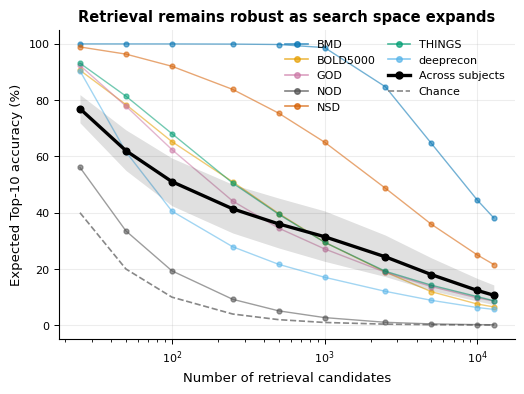

In [507]:
fig, ax = plt.subplots(
    figsize=(5.3, 4.0)
)


draw_panel_c(
    ax,
    candidate_pool_subject_df,
)


fig.tight_layout()


fig.savefig(
    figure5_fig_out
    / "panel_c_candidate_pool_stress.pdf",
    bbox_inches="tight",
)


plt.show()

### Fig. 5d — Semantic hard negatives
The candidate pool has 125 stimuli (the size of the smallest semantic cluster), so random Top-10 chance is 10/125 = 8%.

In [508]:
# ============================================================
# CELL 17
# PANEL d
#
# Count distractors that outrank the true stimulus:
#   - within the true semantic cluster
#   - outside the true semantic cluster
# ============================================================

BETTER_COUNT_CACHE = (
    figure5_out
    / "fig5_hard_negative_rank_components.csv"
)


if BETTER_COUNT_CACHE.exists():

    hard_rank_component_df = (
        pd.read_csv(
            BETTER_COUNT_CACHE
        )
    )


else:

    n_queries = len(
        metadata_fig5
    )


    same_better = np.empty(
        n_queries,
        dtype=np.int32,
    )

    different_better = np.empty(
        n_queries,
        dtype=np.int32,
    )


    candidate_clusters_tensor = (
        torch.as_tensor(
            candidate_cluster_fig5,
            dtype=torch.long,
            device=DEVICE,
        )
    )


    query_clusters = (
        metadata_fig5[
            "semantic_cluster"
        ]
        .to_numpy(dtype=int)
    )


    CHUNK = 512


    for start in range(
        0,
        n_queries,
        CHUNK,
    ):

        stop = min(
            start + CHUNK,
            n_queries,
        )


        brain_chunk = (
            torch.from_numpy(
                brain_embeddings_fig5[
                    start:stop
                ]
            )
            .to(
                DEVICE
            )
        )


        similarity = (
            brain_chunk
            @ candidate_clip_tensor_fig5.T
        )


        matched_indices = (
            torch.as_tensor(
                query_true_candidate_index_fig5[
                    start:stop
                ],
                dtype=torch.long,
                device=DEVICE,
            )
        )


        local_rows = torch.arange(
            stop - start,
            device=DEVICE,
        )


        matched_similarity = (
            similarity[
                local_rows,
                matched_indices,
            ]
        )


        better_mask = (
            similarity
            >
            matched_similarity[
                :,
                None
            ]
        )


        cluster_chunk = (
            torch.as_tensor(
                query_clusters[
                    start:stop
                ],
                dtype=torch.long,
                device=DEVICE,
            )
        )


        same_cluster_mask = (
            candidate_clusters_tensor[
                None,
                :
            ]
            ==
            cluster_chunk[
                :,
                None
            ]
        )


        same_better[
            start:stop
        ] = (
            (
                better_mask
                &
                same_cluster_mask
            )
            .sum(dim=1)
            .detach()
            .cpu()
            .numpy()
        )


        different_better[
            start:stop
        ] = (
            (
                better_mask
                &
                ~same_cluster_mask
            )
            .sum(dim=1)
            .detach()
            .cpu()
            .numpy()
        )


        if (
            stop % 4096 == 0
            or stop == n_queries
        ):

            print(
                stop,
                "/",
                n_queries,
            )


    cluster_candidate_counts = (
        candidate_metadata_fig5
        .groupby(
            "semantic_cluster"
        )
        .size()
        .to_dict()
    )


    hard_rank_component_df = (
        metadata_fig5[
            [
                "dataset_name",
                "subject_name",
                "subject_key",
                "semantic_cluster",
            ]
        ]
        .copy()
    )


    hard_rank_component_df[
        "same_better"
    ] = same_better


    hard_rank_component_df[
        "different_better"
    ] = different_better


    hard_rank_component_df[
        "same_total"
    ] = (
        hard_rank_component_df[
            "semantic_cluster"
        ]
        .map(
            cluster_candidate_counts
        )
        .astype(int)
        - 1
    )


    hard_rank_component_df[
        "different_total"
    ] = (
        N_CANDIDATES_FIG5
        - 1
        -
        hard_rank_component_df[
            "same_total"
        ]
    )


    hard_rank_component_df.to_csv(
        BETTER_COUNT_CACHE,
        index=False,
    )


display(
    hard_rank_component_df.head()
)

,dataset_name,subject_name,subject_key,semantic_cluster,same_better,different_better,same_total,different_total
0,THINGS,sub-03,THINGS::sub-03,34,49,131,344,12474
1,BMD,sub-09,BMD::sub-09,7,7,6,389,12429
2,GOD,sub-03,GOD::sub-03,8,0,2,180,12638
3,BMD,sub-08,BMD::sub-08,0,0,3,250,12568
4,THINGS,sub-03,THINGS::sub-03,6,12,218,372,12446


In [509]:
# ============================================================
# CELL 18
# PANEL d
#
# Exact Top-10 probability when a fixed fraction of
# distractors comes from the true semantic cluster.
# ============================================================

minimum_cluster_candidate_count = int(
    candidate_metadata_fig5
    .groupby(
        "semantic_cluster"
    )
    .size()
    .min()
)


HARD_NEGATIVE_POOL_SIZE = min(
    HARD_NEGATIVE_POOL_SIZE_TARGET,
    minimum_cluster_candidate_count,
)


print(
    "Hard-negative candidate pool size:",
    HARD_NEGATIVE_POOL_SIZE,
)


n_total_distractors = (
    HARD_NEGATIVE_POOL_SIZE
    - 1
)


hard_negative_rows = []


for hard_fraction in (
    HARD_NEGATIVE_FRACTIONS
):

    n_same_draw = int(
        round(
            n_total_distractors
            * hard_fraction
        )
    )


    n_different_draw = (
        n_total_distractors
        - n_same_draw
    )


    same_total = (
        hard_rank_component_df[
            "same_total"
        ]
        .to_numpy(dtype=int)
    )


    same_better = (
        hard_rank_component_df[
            "same_better"
        ]
        .to_numpy(dtype=int)
    )


    different_total = (
        hard_rank_component_df[
            "different_total"
        ]
        .to_numpy(dtype=int)
    )


    different_better = (
        hard_rank_component_df[
            "different_better"
        ]
        .to_numpy(dtype=int)
    )


    probability = np.zeros(
        len(
            hard_rank_component_df
        ),
        dtype=float,
    )


    # ========================================================
    # True target is Top-10 if <=9 sampled distractors
    # outrank it.
    # ========================================================

    for n_same_better_sampled in range(
        TOP_K
    ):

        same_probability = (
            hypergeom.pmf(
                n_same_better_sampled,
                same_total,
                same_better,
                n_same_draw,
            )
        )


        max_different_allowed = (
            TOP_K
            - 1
            - n_same_better_sampled
        )


        different_probability = (
            hypergeom.cdf(
                max_different_allowed,
                different_total,
                different_better,
                n_different_draw,
            )
        )


        probability += (
            same_probability
            *
            different_probability
        )


    block = (
        hard_rank_component_df[
            [
                "dataset_name",
                "subject_name",
                "subject_key",
                "semantic_cluster",
            ]
        ]
        .copy()
    )


    block[
        "hard_negative_fraction"
    ] = hard_fraction


    block[
        "candidate_pool_size"
    ] = HARD_NEGATIVE_POOL_SIZE


    block[
        "expected_top10"
    ] = probability


    hard_negative_rows.append(
        block
    )


hard_negative_query_df = (
    pd.concat(
        hard_negative_rows,
        ignore_index=True,
    )
)


hard_negative_subject_df = (
    hard_negative_query_df
    .groupby(
        [
            "subject_key",
            "dataset_name",
            "subject_name",
            "hard_negative_fraction",
        ],
        as_index=False,
    )
    .agg(
        expected_top10=(
            "expected_top10",
            "mean",
        )
    )
)


hard_negative_subject_df.to_csv(
    figure5_out
    / "panel_e_semantic_hard_negative_stress.csv",
    index=False,
)

Hard-negative candidate pool size: 125


In [510]:
# ============================================================
# CELL 19
# PANEL d plot
# ============================================================


def draw_panel_d(
    ax,
    hard_negative_subject_df,
    hard_negative_pool_size,
):

    # ========================================================
    # Dataset-specific trajectories
    # ========================================================

    for dataset_name, group in (
        hard_negative_subject_df
        .groupby(
            "dataset_name"
        )
    ):

        summary = (
            group
            .groupby(
                "hard_negative_fraction",
                as_index=False,
            )
            .agg(
                expected_top10=(
                    "expected_top10",
                    "mean",
                )
            )
        )

        ax.plot(
            100
            * summary[
                "hard_negative_fraction"
            ],
            100
            * summary[
                "expected_top10"
            ],
            marker="o",
            linewidth=1.0,
            markersize=3.5,
            alpha=0.50,
            color=
                DATASET_COLORS_FIG5
                .get(
                    dataset_name,
                    "#777777",
                ),
            zorder=3,
        )


    # ========================================================
    # Across-subject trajectory
    # ========================================================

    overall_rows = []

    for fraction, group in (
        hard_negative_subject_df
        .groupby(
            "hard_negative_fraction"
        )
    ):

        mean, low, high = (
            bootstrap_mean_ci(
                group[
                    "expected_top10"
                ],
                seed=
                    2000
                    + int(
                        100
                        * fraction
                    ),
            )
        )

        overall_rows.append({
            "fraction":
                fraction,
            "mean":
                mean,
            "low":
                low,
            "high":
                high,
        })


    overall_df = (
        pd.DataFrame(
            overall_rows
        )
        .sort_values(
            "fraction"
        )
    )


    ax.fill_between(
        100
        * overall_df[
            "fraction"
        ],
        100
        * overall_df[
            "low"
        ],
        100
        * overall_df[
            "high"
        ],
        color="black",
        alpha=0.12,
        linewidth=0,
        zorder=4,
    )


    ax.plot(
        100
        * overall_df[
            "fraction"
        ],
        100
        * overall_df[
            "mean"
        ],
        color="black",
        linewidth=2.4,
        marker="o",
        markersize=5,
        zorder=10,
    )


    # ========================================================
    # Chance
    # ========================================================

    chance_percent = (
        100
        * min(
            TOP_K
            / float(
                hard_negative_pool_size
            ),
            1.0,
        )
    )


    ax.axhline(
        chance_percent,
        linestyle="--",
        color="#888888",
        linewidth=1.2,
        zorder=2,
    )


    # ========================================================
    # Axes
    # ========================================================

    ax.set_xlabel(
        "Same-cluster distractors (%)"
    )

    ax.set_ylabel(
        "Expected Top-10 accuracy (%)"
    )

    ax.set_title(
        "Retrieval among semantic hard negatives",
        fontweight="bold",
    )

    ax.set_xticks(
        100
        * np.asarray(
            HARD_NEGATIVE_FRACTIONS
        )
    )

    ax.grid(
        alpha=0.22,
    )


    # ========================================================
    # Legend
    # ========================================================

    legend_handles = (
        make_fig5_retrieval_legend_handles(
            hard_negative_subject_df
        )
    )


    ax.legend(
        handles=
            legend_handles,
        frameon=False,
        ncol=2,
        fontsize=8,
        handlelength=2.0,
        columnspacing=1.1,
    )

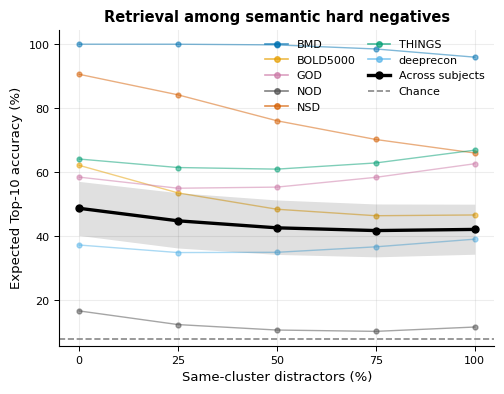

In [511]:
fig, ax = plt.subplots(
    figsize=(5.1, 4.0)
)

draw_panel_d(
    ax,
    hard_negative_subject_df,
    hard_negative_pool_size=
        HARD_NEGATIVE_POOL_SIZE,
)

fig.tight_layout()

fig.savefig(
    figure5_fig_out
    / "panel_d_semantic_hard_negative_stress.pdf",
    bbox_inches="tight",
)

plt.show()

### Fig. 5e — Preservation of local semantic neighbourhoods

In [512]:
# ============================================================
# CELL 20
# PANEL e
#
# Average brain representation for each unique stimulus,
# aligned exactly with candidate_metadata_fig5.
# ============================================================

stimulus_to_row_indices = {
    stimulus_key:
        group.index.to_numpy(
            dtype=int
        )

    for stimulus_key, group
    in metadata_fig5.groupby(
        "stimulus_key"
    )
}


unique_brain_fig5 = []


for stimulus_key in (
    candidate_metadata_fig5[
        "stimulus_key"
    ]
):

    indices = (
        stimulus_to_row_indices[
            stimulus_key
        ]
    )


    mean_brain = (
        brain_embeddings_fig5[
            indices
        ]
        .mean(axis=0)
    )


    mean_brain = (
        mean_brain
        /
        (
            np.linalg.norm(
                mean_brain
            )
            + 1e-12
        )
    )


    unique_brain_fig5.append(
        mean_brain
    )


unique_brain_fig5 = (
    np.stack(
        unique_brain_fig5
    )
    .astype(
        np.float32
    )
)


print(
    unique_brain_fig5.shape,
    candidate_clip_fig5.shape,
)

(12819, 512) (12819, 512)


In [513]:
# ============================================================
# CELL 21
# PANEL e
# k-nearest-neighbour lists
# ============================================================

MAX_KNN_K = max(
    KNN_K_VALUES
)


def compute_knn_indices(
    embeddings,
    max_k,
    device,
    chunk_size=512,
):

    embeddings = normalize_rows(
        embeddings
    )


    tensor = (
        torch.from_numpy(
            embeddings
        )
        .to(
            device
        )
    )


    n_items = len(
        embeddings
    )


    output = np.empty(
        (
            n_items,
            max_k,
        ),
        dtype=np.int32,
    )


    with torch.no_grad():

        for start in range(
            0,
            n_items,
            chunk_size,
        ):

            stop = min(
                start
                + chunk_size,
                n_items,
            )


            similarity = (
                tensor[
                    start:stop
                ]
                @ tensor.T
            )


            local_rows = torch.arange(
                stop - start,
                device=device,
            )


            global_rows = torch.arange(
                start,
                stop,
                device=device,
            )


            # Exclude self
            similarity[
                local_rows,
                global_rows,
            ] = -torch.inf


            top_indices = (
                torch.topk(
                    similarity,
                    k=max_k,
                    dim=1,
                    largest=True,
                    sorted=True,
                )
                .indices
            )


            output[
                start:stop
            ] = (
                top_indices
                .cpu()
                .numpy()
            )


            if (
                stop % 2048 == 0
                or stop
                == n_items
            ):

                print(
                    stop,
                    "/",
                    n_items,
                )


    return output


print(
    "Computing brain-space neighbours..."
)

brain_knn_fig5 = (
    compute_knn_indices(
        unique_brain_fig5,
        MAX_KNN_K,
        DEVICE,
        KNN_CHUNK_SIZE,
    )
)


print(
    "\nComputing CLIP-space neighbours..."
)

clip_knn_fig5 = (
    compute_knn_indices(
        candidate_clip_fig5,
        MAX_KNN_K,
        DEVICE,
        KNN_CHUNK_SIZE,
    )
)

Computing brain-space neighbours...
2048 / 12819
4096 / 12819
6144 / 12819
8192 / 12819
10240 / 12819
12288 / 12819
12819 / 12819

Computing CLIP-space neighbours...
2048 / 12819
4096 / 12819
6144 / 12819
8192 / 12819
10240 / 12819
12288 / 12819
12819 / 12819


In [514]:
# ============================================================
# CELL 22
# PANEL e
#
# Local neighbourhood preservation:
#
# |N_brain(k) ∩ N_CLIP(k)| / k
# ============================================================

neighbourhood_rows = []


n_items = (
    len(
        candidate_metadata_fig5
    )
)


for k in KNN_K_VALUES:

    overlap_fraction = np.empty(
        n_items,
        dtype=float,
    )


    for i in range(
        n_items
    ):

        brain_set = set(
            brain_knn_fig5[
                i,
                :k
            ]
            .tolist()
        )


        clip_neighbors = (
            clip_knn_fig5[
                i,
                :k
            ]
        )


        overlap_count = sum(
            neighbor
            in brain_set

            for neighbor
            in clip_neighbors
        )


        overlap_fraction[
            i
        ] = (
            overlap_count
            / k
        )


    mean, low, high = (
        bootstrap_mean_ci(
            overlap_fraction,
            seed=
                3000
                + k,
        )
    )


    random_expectation = (
        k
        /
        (
            n_items
            - 1
        )
    )


    neighbourhood_rows.append({

        "k":
            k,

        "mean_overlap":
            mean,

        "ci_low":
            low,

        "ci_high":
            high,

        "random_expectation":
            random_expectation,

        "enrichment_over_random":
            (
                mean
                /
                random_expectation
            ),
    })


neighbourhood_preservation_df = (
    pd.DataFrame(
        neighbourhood_rows
    )
)


neighbourhood_preservation_df.to_csv(
    figure5_out
    / "panel_f_local_neighbourhood_preservation.csv",
    index=False,
)


display(
    neighbourhood_preservation_df.round(
        5
    )
)

,k,mean_overlap,ci_low,ci_high,random_expectation,enrichment_over_random
0,5,0.01103,0.01005,0.01208,0.00039,28.27779
1,10,0.01499,0.01390,0.01606,0.00078,19.20850
2,20,0.01978,0.01854,0.02104,0.00156,12.67901
3,50,0.02803,0.02644,0.02958,0.00390,7.18464
4,100,0.03414,0.03263,0.03573,0.00780,4.37606
5,250,0.04579,0.04456,0.04701,0.01950,2.34762


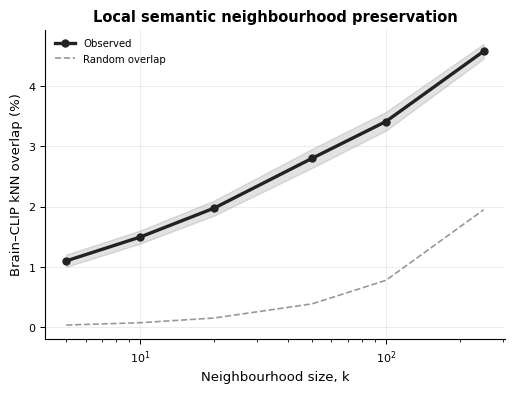

In [515]:
# ============================================================
# CELL 23
# PANEL e plot
# ============================================================

def draw_panel_e(
    ax,
    neighbourhood_preservation_df,
):

    x = (
        neighbourhood_preservation_df[
            "k"
        ]
        .to_numpy()
    )


    mean = (
        neighbourhood_preservation_df[
            "mean_overlap"
        ]
        .to_numpy()
    )


    low = (
        neighbourhood_preservation_df[
            "ci_low"
        ]
        .to_numpy()
    )


    high = (
        neighbourhood_preservation_df[
            "ci_high"
        ]
        .to_numpy()
    )


    chance = (
        neighbourhood_preservation_df[
            "random_expectation"
        ]
        .to_numpy()
    )


    ax.plot(
        x,
        100 * mean,
        color="#222222",
        linewidth=2.4,
        marker="o",
        markersize=5,
        label="Observed",
    )


    ax.fill_between(
        x,
        100 * low,
        100 * high,
        color="#222222",
        alpha=0.13,
    )


    ax.plot(
        x,
        100 * chance,
        linestyle="--",
        color="#999999",
        linewidth=1.2,
        label="Random overlap",
    )


    ax.set_xscale(
        "log"
    )


    ax.set_xlabel(
        "Neighbourhood size, k"
    )


    ax.set_ylabel(
        "Brain–CLIP kNN overlap (%)"
    )


    ax.set_title(
        "Local semantic neighbourhood preservation",
        fontweight="bold",
    )


    ax.grid(
        alpha=0.22,
    )


    ax.legend(
        frameon=False,
    )


fig, ax = plt.subplots(
    figsize=(5.2, 4.0)
)

draw_panel_e(
    ax,
    neighbourhood_preservation_df,
)

fig.tight_layout()

fig.savefig(
    figure5_fig_out
    / "panel_e_local_neighbourhood_preservation.pdf",
    bbox_inches="tight",
)

plt.show()

---
## Supplementary Figure S1 — All 40 semantic clusters

### Fig. S1b — Top-10 accuracy (top) and number of unique stimuli (bottom)

Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_2_semantic_clusters/appendix_all40_semantic_clusters/all40_retrieval_accuracy_sorted.pdf


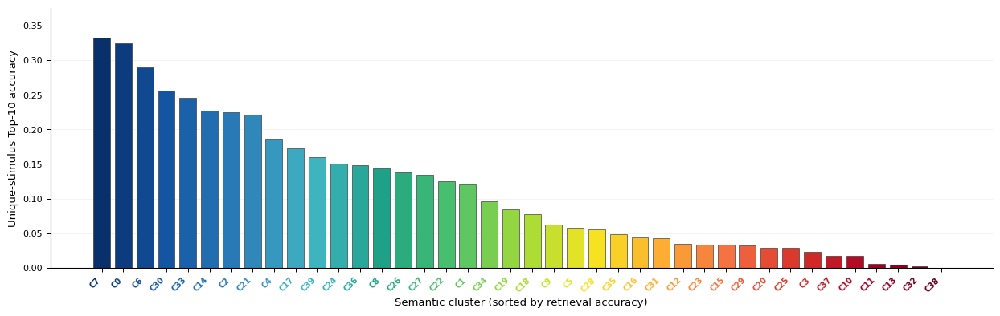

In [516]:
# ============================================================
# CELL 4
# Retrieval accuracy across ALL 40 semantic clusters
# ============================================================

def plot_all40_retrieval_bars(
    cluster_summary,
    cluster_names,
    cluster_colors,
    metric_col="unique_stimulus_top10",
    save_path=None,
    ylabel="Unique-stimulus Top-10 accuracy",
    figsize=(12.5, 4.0),
    show_values=False,
):
    df = (
        cluster_summary
        .copy()
        .sort_values(
            metric_col,
            ascending=False,
        )
        .reset_index(drop=True)
    )

    df["semantic_cluster"] = (
        df["semantic_cluster"]
        .astype(int)
    )

    df["retrieval_rank"] = (
        np.arange(1, len(df) + 1)
    )

    x = np.arange(
        len(df)
    )

    colors = [
        cluster_colors[cid]
        for cid
        in df["semantic_cluster"]
    ]

    fig, ax = plt.subplots(
        figsize=figsize
    )

    bars = ax.bar(
        x,
        df[metric_col],
        width=0.78,
        color=colors,
        edgecolor="#303030",
        linewidth=0.45,
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        [
            f"C{cid}"
            for cid
            in df["semantic_cluster"]
        ],
        rotation=45,
        ha="right",
        fontsize=7,
    )

    # Tick-label colours match their clusters
    for tick, cid in zip(
        ax.get_xticklabels(),
        df["semantic_cluster"],
    ):
        tick.set_color(
            cluster_colors[int(cid)]
        )

        tick.set_fontweight(
            "bold"
        )

    ax.set_ylabel(ylabel)

    ax.set_xlabel(
        "Semantic cluster "
        "(sorted by retrieval accuracy)"
    )

    ymax = max(
        0.01,
        df[metric_col].max() * 1.13,
    )

    ax.set_ylim(
        0,
        ymax,
    )

    if show_values:

        for bar, value in zip(
            bars,
            df[metric_col],
        ):
            ax.text(
                bar.get_x()
                + bar.get_width() / 2,
                value + ymax * 0.012,
                f"{value:.2f}",
                ha="center",
                va="bottom",
                fontsize=5.5,
                rotation=90,
            )

    ax.grid(
        axis="y",
        linewidth=0.4,
        alpha=0.25,
    )

    ax.set_axisbelow(True)

    fig.tight_layout()

    if save_path is not None:

        save_path = Path(save_path)

        fig.savefig(
            save_path,
            bbox_inches="tight",
        )

        fig.savefig(
            save_path.with_suffix(".png"),
            dpi=400,
            bbox_inches="tight",
        )

        print("Saved:", save_path)

    plt.show()

    return df


retrieval_plot_df_all40 = (
    plot_all40_retrieval_bars(
        cluster_summary=cluster_summary,
        cluster_names=ALL_CLUSTER_NAMES,
        cluster_colors=ALL_CLUSTER_COLORS,
        metric_col="unique_stimulus_top10",
        save_path=(
            appendix40_out
            / "all40_retrieval_accuracy_sorted.pdf"
        ),
        show_values=False,
    )
)

Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_2_semantic_clusters/appendix_all40_semantic_clusters/all40_cluster_n_unique_stimuli_retrieval_sorted.pdf


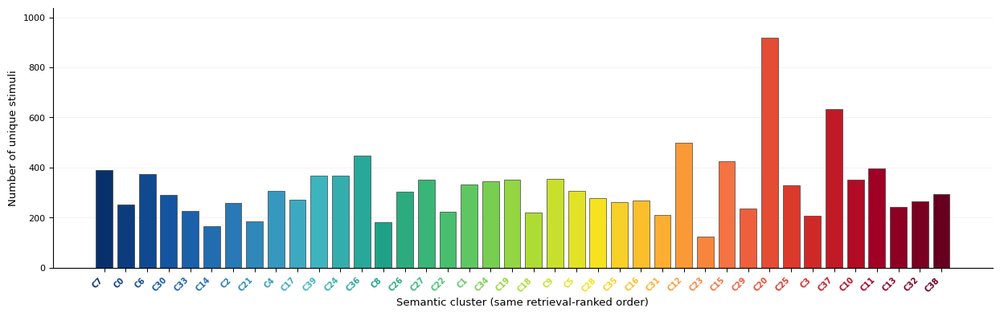

In [517]:
# ============================================================
# CELL 5
# Cluster density across ALL 40 semantic clusters
# ============================================================

def compute_cluster_density_table(
    unique_stimulus_df,
    n_clusters=40,
):
    counts = (
        unique_stimulus_df
        .groupby(
            "semantic_cluster"
        )
        .size()
        .reset_index(
            name="n_unique_stimuli"
        )
    )

    all_clusters = pd.DataFrame({
        "semantic_cluster": (
            np.arange(n_clusters)
        )
    })

    counts = all_clusters.merge(
        counts,
        on="semantic_cluster",
        how="left",
    )

    counts[
        "n_unique_stimuli"
    ] = (
        counts[
            "n_unique_stimuli"
        ]
        .fillna(0)
        .astype(int)
    )

    counts["density"] = (
        counts["n_unique_stimuli"]
        / counts["n_unique_stimuli"].sum()
    )

    return counts


cluster_density_df_all40 = (
    compute_cluster_density_table(
        unique_stimulus_df=
            unique_stimulus_df,
        n_clusters=40,
    )
)


def plot_all40_density_bars(
    cluster_density_df,
    cluster_summary,
    cluster_colors,
    value_col="density",
    save_path=None,
    ylabel="Fraction of unique stimuli",
    figsize=(12.5, 4.0),
    show_values=False,
):

    retrieval_order = (
        cluster_summary
        .copy()
        .sort_values(
            "unique_stimulus_top10",
            ascending=False,
        )[
            "semantic_cluster"
        ]
        .astype(int)
        .tolist()
    )

    df = (
        cluster_density_df
        .copy()
    )

    df["semantic_cluster"] = (
        df["semantic_cluster"]
        .astype(int)
    )

    rank_map = {
        cid: index
        for index, cid
        in enumerate(retrieval_order)
    }

    df["plot_order"] = (
        df["semantic_cluster"]
        .map(rank_map)
    )

    df = (
        df
        .sort_values("plot_order")
        .reset_index(drop=True)
    )

    x = np.arange(
        len(df)
    )

    colors = [
        cluster_colors[cid]
        for cid
        in df["semantic_cluster"]
    ]

    fig, ax = plt.subplots(
        figsize=figsize
    )

    bars = ax.bar(
        x,
        df[value_col],
        width=0.78,
        color=colors,
        edgecolor="#303030",
        linewidth=0.45,
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        [
            f"C{cid}"
            for cid
            in df["semantic_cluster"]
        ],
        rotation=45,
        ha="right",
        fontsize=7,
    )

    for tick, cid in zip(
        ax.get_xticklabels(),
        df["semantic_cluster"],
    ):
        tick.set_color(
            cluster_colors[int(cid)]
        )

        tick.set_fontweight(
            "bold"
        )

    ax.set_ylabel(
        ylabel
    )

    ax.set_xlabel(
        "Semantic cluster "
        "(same retrieval-ranked order)"
    )

    ymax = max(
        0.01,
        df[value_col].max() * 1.13,
    )

    ax.set_ylim(
        0,
        ymax,
    )

    if show_values:

        for bar, value in zip(
            bars,
            df[value_col],
        ):
            ax.text(
                bar.get_x()
                + bar.get_width() / 2,
                value + ymax * 0.012,
                f"{value:.3f}",
                fontsize=5.5,
                rotation=90,
                ha="center",
                va="bottom",
            )

    ax.grid(
        axis="y",
        linewidth=0.4,
        alpha=0.25,
    )

    ax.set_axisbelow(True)

    fig.tight_layout()

    if save_path is not None:

        save_path = Path(save_path)

        fig.savefig(
            save_path,
            bbox_inches="tight",
        )

        fig.savefig(
            save_path.with_suffix(".png"),
            dpi=400,
            bbox_inches="tight",
        )

        print("Saved:", save_path)

    plt.show()

    return df


density_plot_df_all40 = (
    plot_all40_density_bars(
        cluster_density_df=
            cluster_density_df_all40,
        cluster_summary=
            cluster_summary,
        cluster_colors=
            ALL_CLUSTER_COLORS,
        value_col= "n_unique_stimuli",
        ylabel="Number of unique stimuli",
        save_path=(
            appendix40_out
            / "all40_cluster_n_unique_stimuli_retrieval_sorted.pdf"
        ),
    )
)


cluster_density_df_all40.to_csv(
    appendix40_out
    / "all40_cluster_n_unique_stimuli.csv",
    index=False,
)

### Fig. S1a — Representative stimuli of each cluster

Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_2_semantic_clusters/appendix_all40_semantic_clusters/all40_semantic_cluster_representative_collages.pdf


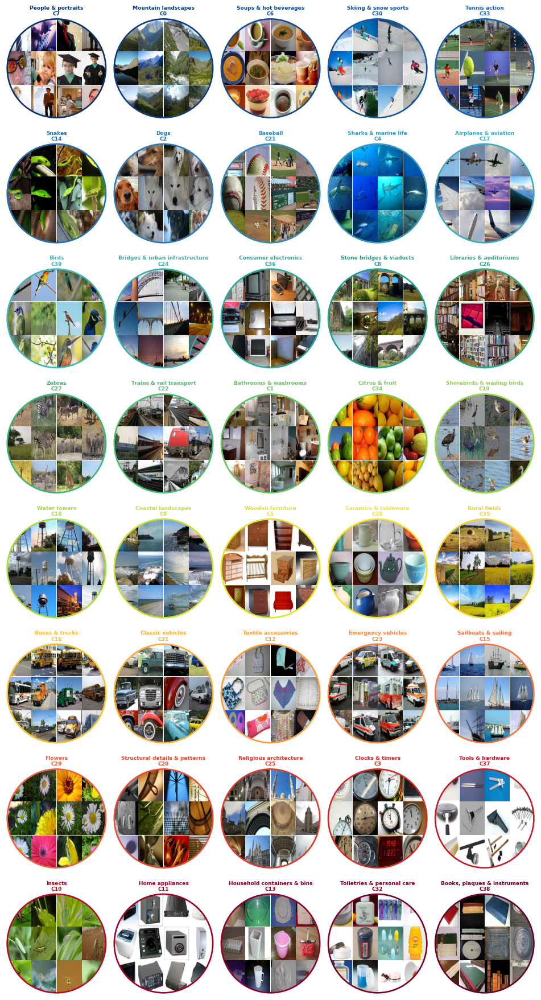

In [518]:
# ============================================================
# CELL 6
# Representative image collages for ALL 40 clusters
# ============================================================

def safe_open_image(
    image_path,
):
    try:
        img = Image.open(
            image_path
        ).convert("RGB")

        return img

    except Exception:
        return None


def draw_cluster_circle_collage(
    ax,
    cluster_df,
    cluster_color="black",
    n_examples=16,
    pad=0.004,
    border_lw=2.0,
    background_color="white",
):

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.set_aspect(
        "equal"
    )

    ax.axis(
        "off"
    )


    # --------------------------------------------------------
    # Circular clipping region
    # --------------------------------------------------------

    circle_clip = Circle(
        (0.5, 0.5),
        0.48,
        facecolor=background_color,
        edgecolor="none",
        linewidth=0,
        zorder=1,
    )

    ax.add_patch(
        circle_clip
    )


    circle_border = Circle(
        (0.5, 0.5),
        0.485,
        facecolor="none",
        edgecolor=cluster_color,
        linewidth=border_lw,
        zorder=10,
    )

    ax.add_patch(
        circle_border
    )


    # --------------------------------------------------------
    # Representative samples
    # --------------------------------------------------------

    g = (
        cluster_df
        .copy()
        .sort_values(
            "example_rank"
        )
        .head(n_examples)
        .reset_index(drop=True)
    )

    n = len(g)

    if n == 0:

        ax.text(
            0.5,
            0.5,
            "No images",
            ha="center",
            va="center",
            fontsize=7,
        )

        return


    ncols = math.ceil(
        math.sqrt(n)
    )

    nrows = math.ceil(
        n / ncols
    )

    tile_w = (
        1 - pad * (ncols + 1)
    ) / ncols

    tile_h = (
        1 - pad * (nrows + 1)
    ) / nrows


    for idx in range(n):

        row_i = (
            idx // ncols
        )

        col_i = (
            idx % ncols
        )

        x0 = (
            pad
            + col_i
            * (tile_w + pad)
        )

        y0 = (
            1
            - (
                pad
                + (row_i + 1)
                * tile_h
                + row_i * pad
            )
        )

        row = g.iloc[idx]

        img = safe_open_image(
            row["image_path"]
        )

        if img is None:
            continue

        im = ax.imshow(
            img,
            extent=(
                x0,
                x0 + tile_w,
                y0,
                y0 + tile_h,
            ),
            zorder=2,
        )

        im.set_clip_path(
            circle_clip
        )


def plot_all40_cluster_collages(
    examples_df,
    cluster_names,
    cluster_colors,
    cluster_order,
    n_examples_per_cluster=16,
    ncols=8,
    panel_size=1.90,
    save_path=None,
):

    cluster_ids = list(
        cluster_order
    )

    n_clusters = len(
        cluster_ids
    )

    nrows = math.ceil(
        n_clusters / ncols
    )

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(
            ncols * panel_size,
            nrows * (
                panel_size + 0.32
            ),
        ),
    )

    axes = np.asarray(
        axes
    ).reshape(
        nrows,
        ncols,
    )

    for ax in axes.flatten():
        ax.axis(
            "off"
        )


    for index, cid in enumerate(
        cluster_ids
    ):

        ax = axes.flatten()[
            index
        ]

        g = examples_df[
            examples_df[
                "semantic_cluster"
            ].astype(int)
            == int(cid)
        ].copy()

        cluster_color = (
            cluster_colors[cid]
        )

        draw_cluster_circle_collage(
            ax=ax,
            cluster_df=g,
            cluster_color=
                cluster_color,
            n_examples=
                n_examples_per_cluster,
            pad=0.004,
            border_lw=1.9,
        )

        ax.set_title(
            (
                f"{cluster_names[cid]}\n"
                f"C{cid}"
            ),
            fontsize=6.6,
            color=cluster_color,
            pad=3,
            fontweight="bold",
        )


    # Hide unused axes
    for index in range(
        n_clusters,
        nrows * ncols,
    ):
        axes.flatten()[
            index
        ].axis("off")


    fig.tight_layout(
        pad=0.8
    )

    if save_path is not None:

        save_path = Path(
            save_path
        )

        fig.savefig(
            save_path,
            bbox_inches="tight",
            facecolor="white",
        )

        fig.savefig(
            save_path.with_suffix(
                ".png"
            ),
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )

        print(
            "Saved:",
            save_path,
        )

    plt.show()


# ------------------------------------------------------------
# Use retrieval-ranked ordering to match the other appendix
# plots.
# ------------------------------------------------------------

plot_all40_cluster_collages(
    examples_df=
        cluster_examples_df,
    cluster_names=
        ALL_CLUSTER_NAMES,
    cluster_colors=
        ALL_CLUSTER_COLORS,
    cluster_order=
        ALL_CLUSTER_IDS_BY_RETRIEVAL,
    n_examples_per_cluster=16,
    ncols=5,
    panel_size=1.90,
    save_path=(
        appendix40_out
        / "all40_semantic_cluster_representative_collages.pdf"
    ),
)

### Fig. S1c — Dataset composition of each cluster

In [519]:
# ============================================================
# CELL 7
# Dataset composition for ALL 40 clusters
# ============================================================

# Prefer the same column used previously
if "first_dataset_name" in unique_stimulus_df.columns:

    DATASET_COL = (
        "first_dataset_name"
    )

elif "dataset_name" in unique_stimulus_df.columns:

    DATASET_COL = (
        "dataset_name"
    )

else:

    raise KeyError(
        "Could not find first_dataset_name "
        "or dataset_name in unique_stimulus_df."
    )


print(
    "Using dataset column:",
    DATASET_COL,
)


def compute_all40_cluster_dataset_distribution(
    unique_stimulus_df,
    dataset_col,
    n_clusters=40,
):

    df = (
        unique_stimulus_df
        .copy()
    )

    df["semantic_cluster"] = (
        df["semantic_cluster"]
        .astype(int)
    )


    counts = (
        df
        .groupby(
            [
                "semantic_cluster",
                dataset_col,
            ]
        )
        .size()
        .reset_index(
            name="n_unique_stimuli"
        )
    )


    all_datasets = sorted(
        df[
            dataset_col
        ]
        .dropna()
        .unique()
    )


    full_index = (
        pd.MultiIndex
        .from_product(
            [
                np.arange(
                    n_clusters
                ),
                all_datasets,
            ],
            names=[
                "semantic_cluster",
                dataset_col,
            ],
        )
    )


    counts = (
        counts
        .set_index(
            [
                "semantic_cluster",
                dataset_col,
            ]
        )
        .reindex(
            full_index,
            fill_value=0,
        )
        .reset_index()
    )


    totals = (
        counts
        .groupby(
            "semantic_cluster"
        )[
            "n_unique_stimuli"
        ]
        .transform("sum")
    )


    counts[
        "fraction_within_cluster"
    ] = (
        counts[
            "n_unique_stimuli"
        ]
        / totals.replace(
            0,
            np.nan,
        )
    ).fillna(0)


    counts["cluster_name"] = (
        counts[
            "semantic_cluster"
        ].map(
            ALL_CLUSTER_NAMES
        )
    )


    return counts


all40_cluster_dataset_dist = (
    compute_all40_cluster_dataset_distribution(
        unique_stimulus_df=
            unique_stimulus_df,
        dataset_col=
            DATASET_COL,
        n_clusters=40,
    )
)


all40_cluster_dataset_dist.to_csv(
    appendix40_out
    / "all40_cluster_dataset_distribution.csv",
    index=False,
)


display(
    all40_cluster_dataset_dist.head(
        20
    )
)

Using dataset column: first_dataset_name


,semantic_cluster,first_dataset_name,n_unique_stimuli,fraction_within_cluster,cluster_name
0,0,BMD,3,0.011952,Mountain landscapes
1,0,BOLD5000,1,0.003984,Mountain landscapes
2,0,GOD,0,0.000000,Mountain landscapes
3,0,NOD,238,0.948207,Mountain landscapes
4,0,NSD,8,0.031873,Mountain landscapes
5,0,THINGS,1,0.003984,Mountain landscapes
6,0,deeprecon,0,0.000000,Mountain landscapes
7,1,BMD,0,0.000000,Bathrooms & washrooms
8,1,BOLD5000,7,0.021084,Bathrooms & washrooms
9,1,GOD,1,0.003012,Bathrooms & washrooms


In [520]:
# ============================================================
# CELL 8
# Horizontal stacked dataset-composition bars
# for ALL 40 clusters
# ============================================================

def plot_all40_cluster_dataset_stacked_bars(
    dist_df,
    cluster_names,
    cluster_colors,
    cluster_order,
    value_col,
    dataset_col,
    dataset_colors,
    dataset_order,
    xlabel,
    save_path=None,
    figsize=(10.0, 13.5),
    bar_height=0.68,
):

    pivot = dist_df.pivot_table(
        index="semantic_cluster",
        columns=dataset_col,
        values=value_col,
        fill_value=0,
    )


    # --------------------------------------------------------
    # Use retrieval-ranked order
    # --------------------------------------------------------

    pivot = pivot.reindex(
        cluster_order
    )


    # --------------------------------------------------------
    # Dataset ordering
    # --------------------------------------------------------

    present_datasets = [
        dataset
        for dataset
        in dataset_order
        if dataset in pivot.columns
    ]

    remaining_datasets = [
        dataset
        for dataset
        in pivot.columns
        if dataset
        not in present_datasets
    ]

    datasets = (
        present_datasets
        + remaining_datasets
    )

    pivot = pivot[
        datasets
    ]


    labels = [
        (
            f"{cluster_names[int(cid)]} "
            f"(C{int(cid)})"
        )
        for cid
        in pivot.index
    ]


    y = np.arange(
        len(pivot)
    )

    left = np.zeros(
        len(pivot)
    )


    fig, ax = plt.subplots(
        figsize=figsize
    )


    for dataset in datasets:

        values = (
            pivot[
                dataset
            ].to_numpy()
        )

        ax.barh(
            y,
            values,
            left=left,
            height=bar_height,
            color=dataset_colors.get(
                dataset,
                "0.65",
            ),
            edgecolor="white",
            linewidth=0.75,
            label=dataset,
        )

        left += values


    ax.set_yticks(
        y
    )

    ax.set_yticklabels(
        labels,
        fontsize=7.2,
    )

    ax.invert_yaxis()


    # --------------------------------------------------------
    # Colour labels by semantic cluster
    # --------------------------------------------------------

    for tick_label, cid in zip(
        ax.get_yticklabels(),
        pivot.index,
    ):

        tick_label.set_color(
            cluster_colors[
                int(cid)
            ]
        )

        tick_label.set_fontweight(
            "bold"
        )


    ax.set_xlabel(
        xlabel
    )

    ax.set_ylabel(
        ""
    )


    ax.grid(
        axis="x",
        linewidth=0.4,
        alpha=0.22,
    )

    ax.set_axisbelow(
        True
    )


    handles = [
        Patch(
            facecolor=
                dataset_colors.get(
                    dataset,
                    "0.65",
                ),
            edgecolor="white",
            label=dataset,
        )
        for dataset
        in datasets
    ]


    ax.legend(
        handles=handles,
        frameon=False,
        fontsize=7.5,
        ncol=4,
        loc="lower center",
        bbox_to_anchor=(
            0.5,
            1.005,
        ),
        columnspacing=1.2,
        handlelength=1.4,
        handletextpad=0.4,
    )


    fig.tight_layout()


    if save_path is not None:

        save_path = Path(
            save_path
        )

        fig.savefig(
            save_path,
            bbox_inches="tight",
        )

        fig.savefig(
            save_path.with_suffix(
                ".png"
            ),
            dpi=400,
            bbox_inches="tight",
        )

        print(
            "Saved:",
            save_path,
        )


    plt.show()

Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_2_semantic_clusters/appendix_all40_semantic_clusters/all40_cluster_dataset_composition_counts.pdf


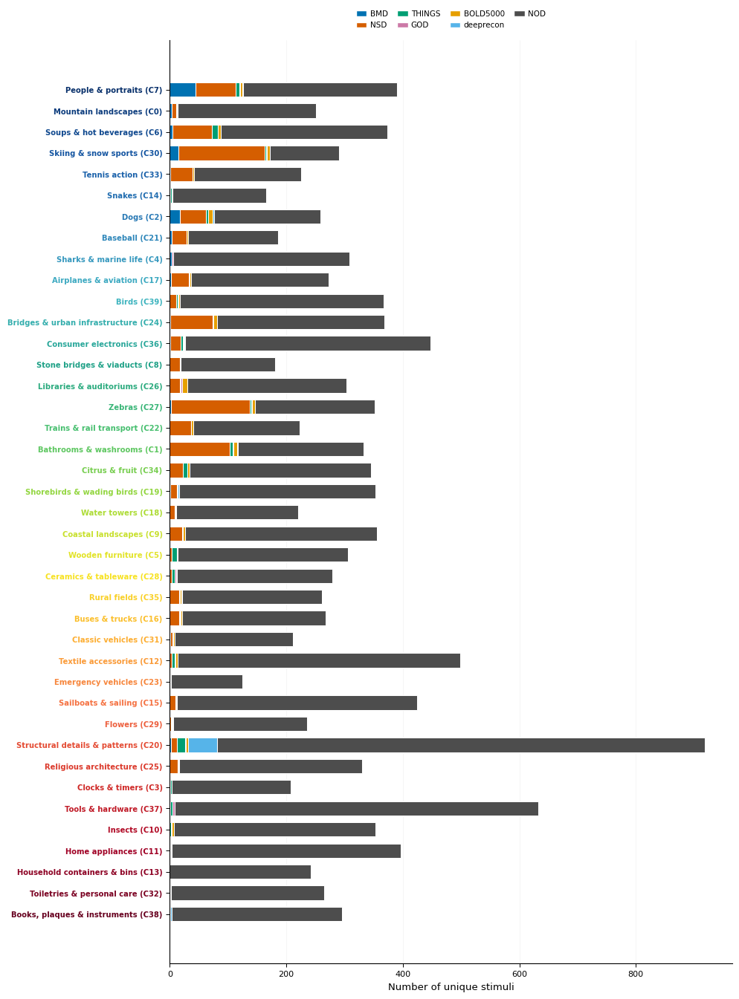

In [521]:
# ============================================================
# CELL 10
# Dataset composition: number of unique stimuli
# ============================================================

plot_all40_cluster_dataset_stacked_bars(
    dist_df=
        all40_cluster_dataset_dist,

    cluster_names=
        ALL_CLUSTER_NAMES,

    cluster_colors=
        ALL_CLUSTER_COLORS,

    cluster_order=
        ALL_CLUSTER_IDS_BY_RETRIEVAL,

    value_col=
        "n_unique_stimuli",

    dataset_col=
        DATASET_COL,

    dataset_colors=
        DATASET_COLORS_CLEAN,

    dataset_order=
        DATASET_ORDER,

    xlabel=
        "Number of unique stimuli",

    save_path=(
        appendix40_out
        / "all40_cluster_dataset_composition_counts.pdf"
    ),

    figsize=(
        10.0,
        13.5,
    ),
)

---
## Supplementary Figure S2 — All 40 semantic clusters: ablation, margins and saliency

### Fig. S2a — Cluster-specific ablation effects

In [522]:
# ============================================================
# CELL 2
# Prepare signed network-ablation effects for ALL 40 clusters
# ============================================================

drop_by_all40_cluster = (
    drop_by_cluster
    .copy()
)

drop_by_all40_cluster[
    "semantic_cluster"
] = (
    drop_by_all40_cluster[
        "semantic_cluster"
    ]
    .astype(int)
)


drop_by_all40_cluster = (
    drop_by_all40_cluster[
        drop_by_all40_cluster[
            "semantic_cluster"
        ].isin(
            all40_clusters_ablation
        )
    ]
    .copy()
)


print(
    "Clusters present:",
    drop_by_all40_cluster[
        "semantic_cluster"
    ].nunique(),
)


print(
    "Ablation groups present:",
    drop_by_all40_cluster[
        "ablation_name"
    ].nunique(),
)


# Check that every requested cluster appears
missing_clusters = sorted(
    set(all40_clusters_ablation)
    -
    set(
        drop_by_all40_cluster[
            "semantic_cluster"
        ].unique()
    )
)

print(
    "Missing clusters:",
    missing_clusters,
)

if missing_clusters:
    raise RuntimeError(
        "Some semantic clusters are missing "
        "from drop_by_cluster."
    )

Clusters present: 40
Ablation groups present: 9
Missing clusters: []


Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/appendix_network_by_all40_clusters_signed_accuracy_change_top10.pdf


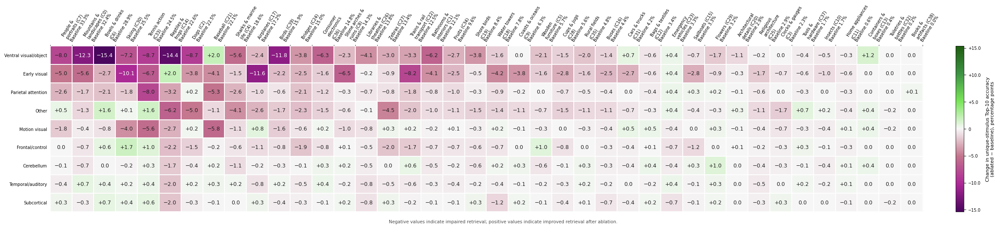

In [523]:
# ============================================================
# CELL 3
# ALL-40 network-ablation heatmap
#
# Signed quantity:
#   ablated - baseline
#
# Negative values:
#   retrieval impairment after ablation
#
# Positive values:
#   improved retrieval after ablation
# ============================================================

fig4_all40_cluster_change_pivot = (
    plot_ablation_change_heatmap_with_baseline(

        drop_df=
            drop_by_all40_cluster,

        row_col=
            "ablation_name",

        col_col=
            "semantic_cluster",

        value_col=
            DROP_METRIC,

        baseline_col=
            BASELINE_METRIC,

        row_order=
            network_order,

        col_order=
            all40_clusters_ablation,

        row_label_map=
            network_label_map,

        col_label_map=
            all40_cluster_label_map,

        title=None,

        cbar_label=(
            "Change in unique-stimulus Top-10 accuracy\n"
            "(ablated − baseline), percentage points"
        ),

        save_path=(
            analysis5_fig_out
            / "appendix_network_by_all40_clusters_signed_accuracy_change_top10.pdf"
        ),

        figsize=(
            23.5,
            5.3,
        ),

        annotate=True,

        decimals=1,

        rotate_xticks=58,

        wrap_col_labels=True,

        col_label_width=15,

        robust_percentile=None,
    )
)

### Fig. S2b — Identity and semantic margins per cluster (panel b of the saved figure)

In [524]:
# ============================================================
# CELL 1
# ALL-40 hierarchical cross-modal similarity configuration
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
from matplotlib.lines import Line2D


# ============================================================
# All 40 cluster names
# ============================================================

ALL_CLUSTER_NAMES = {
    0:  "Mountain landscapes",
    1:  "Bathrooms & washrooms",
    2:  "Dogs",
    3:  "Clocks & timers",
    4:  "Sharks & marine life",
    5:  "Wooden furniture",
    6:  "Soups & hot beverages",
    7:  "People & portraits",
    8:  "Stone bridges & viaducts",
    9:  "Coastal landscapes",
    10: "Insects",
    11: "Home appliances",
    12: "Textile accessories",
    13: "Household containers & bins",
    14: "Snakes",
    15: "Sailboats & sailing",
    16: "Buses & trucks",
    17: "Airplanes & aviation",
    18: "Water towers",
    19: "Shorebirds & wading birds",
    20: "Structural details & patterns",
    21: "Baseball",
    22: "Trains & rail transport",
    23: "Emergency vehicles",
    24: "Bridges & urban infrastructure",
    25: "Religious architecture",
    26: "Libraries & auditoriums",
    27: "Zebras",
    28: "Ceramics & tableware",
    29: "Flowers",
    30: "Skiing & snow sports",
    31: "Classic vehicles",
    32: "Toiletries & personal care",
    33: "Tennis action",
    34: "Citrus & fruit",
    35: "Rural fields",
    36: "Consumer electronics",
    37: "Tools & hardware",
    38: "Books, plaques & instruments",
    39: "Birds",
}


# ============================================================
# Retrieval-ranked order from the cluster analysis
# ============================================================

CLUSTER_RETRIEVAL_ORDER = [
    7, 0, 6, 30, 33, 14, 2, 21, 4, 17,
    39, 24, 36, 8, 26, 27, 22, 1, 34, 19,
    18, 9, 5, 28, 35, 16, 31, 12, 23, 15,
    29, 20, 25, 3, 37, 10, 11, 13, 32, 38,
]

assert len(CLUSTER_RETRIEVAL_ORDER) == 40
assert set(CLUSTER_RETRIEVAL_ORDER) == set(range(40))


# ============================================================
# Use your previously defined ALL_CLUSTER_COLORS
# ============================================================

assert "ALL_CLUSTER_COLORS" in globals(), (
    "Run your retrieval-ranked cluster-colour cell first."
)

assert set(ALL_CLUSTER_COLORS.keys()) == set(range(40))


# ============================================================
# Dataset colours
# ============================================================

DATASET_COLORS_CLEAN = {
    "BMD": "#0072B2",
    "NSD": "#D55E00",
    "THINGS": "#009E73",
    "GOD": "#CC79A7",
    "BOLD5000": "#E69F00",
    "deeprecon": "#56B4E9",
    "NOD": "#4D4D4D",
    "HAD": "#999933",
}


# ============================================================
# Output directory
# ============================================================

geometry_all40_out = (
    Path(geometry_out)
    / "appendix_all40_hierarchical_geometry"
)

geometry_all40_out.mkdir(
    parents=True,
    exist_ok=True,
)

print("Output:", geometry_all40_out)

Output: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/embedding_geometry/appendix_all40_hierarchical_geometry


In [525]:
# ============================================================
# CELL 2
# HIERARCHICAL CROSS-MODAL SIMILARITY — ALL 40 CLUSTERS
#
# Prepare:
#   - normalized brain embeddings
#   - one normalized CLIP embedding per unique stimulus
#   - matched candidate index for every brain query
#   - semantic-cluster labels
#
# Queries:
#   ALL 40 semantic clusters
#
# Candidate pool:
#   ALL unique stimuli across all 40 clusters
# ============================================================


# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------

def to_numpy_safe(x):
    if hasattr(x, "detach"):
        return x.detach().cpu().numpy()

    if hasattr(x, "cpu"):
        return x.cpu().numpy()

    return np.asarray(x)


def normalize_rows(x, eps=1e-12):
    x = np.asarray(
        x,
        dtype=np.float32,
    )

    return x / (
        np.linalg.norm(
            x,
            axis=1,
            keepdims=True,
        )
        + eps
    )


# ------------------------------------------------------------
# ALL 40 clusters
# ------------------------------------------------------------

selected_clusters_hierarchy_all40 = list(
    range(40)
)


# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------

hierarchy_metadata_all40 = (
    baseline_metadata_df
    .copy()
    .reset_index(drop=True)
)

hierarchy_metadata_all40[
    "semantic_cluster"
] = (
    hierarchy_metadata_all40[
        "stimulus_id"
    ]
    .map(stimulus_id_to_cluster)
)


if hierarchy_metadata_all40[
    "semantic_cluster"
].isna().any():

    missing = hierarchy_metadata_all40[
        hierarchy_metadata_all40[
            "semantic_cluster"
        ].isna()
    ]

    raise RuntimeError(
        f"{len(missing)} rows could not be mapped "
        "to semantic clusters."
    )


hierarchy_metadata_all40[
    "semantic_cluster"
] = (
    hierarchy_metadata_all40[
        "semantic_cluster"
    ]
    .astype(int)
)


# ------------------------------------------------------------
# Embeddings
# ------------------------------------------------------------

brain_all40 = normalize_rows(
    to_numpy_safe(
        baseline_brain
    )
)

clip_all40 = normalize_rows(
    to_numpy_safe(
        baseline_clip
    )
)


if not (
    len(hierarchy_metadata_all40)
    == len(brain_all40)
    == len(clip_all40)
):
    raise RuntimeError(
        "Metadata, brain embeddings and CLIP embeddings "
        "have different numbers of rows."
    )


# ============================================================
# One CLIP embedding per unique stimulus
# ============================================================

candidate_rows_all40 = []
candidate_clip_embeddings_all40 = []


for stimulus_id, group in hierarchy_metadata_all40.groupby(
    "stimulus_id",
    sort=False,
):

    row_indices = (
        group.index
        .to_numpy(dtype=int)
    )

    mean_clip = (
        clip_all40[
            row_indices
        ]
        .mean(axis=0)
    )

    mean_clip = mean_clip / (
        np.linalg.norm(
            mean_clip
        )
        + 1e-12
    )

    candidate_rows_all40.append({
        "stimulus_id": stimulus_id,

        "stimulus_clean":
            group[
                "stimulus_clean"
            ].iloc[0],

        "semantic_cluster":
            int(
                group[
                    "semantic_cluster"
                ].iloc[0]
            ),

        "dataset_name":
            group[
                "dataset_name"
            ].iloc[0],

        "n_repetitions":
            len(row_indices),
    })

    candidate_clip_embeddings_all40.append(
        mean_clip
    )


candidate_metadata_all40 = (
    pd.DataFrame(
        candidate_rows_all40
    )
    .reset_index(drop=True)
)


candidate_clip_embeddings_all40 = (
    np.stack(
        candidate_clip_embeddings_all40,
        axis=0,
    )
    .astype(np.float32)
)


# ============================================================
# Candidate-index lookup
# ============================================================

stimulus_id_to_candidate_index_all40 = {
    stimulus_id: candidate_index
    for candidate_index, stimulus_id
    in enumerate(
        candidate_metadata_all40[
            "stimulus_id"
        ]
    )
}


# ============================================================
# All queries
# ============================================================

selected_query_mask_all40 = (
    hierarchy_metadata_all40[
        "semantic_cluster"
    ]
    .isin(
        selected_clusters_hierarchy_all40
    )
    .to_numpy()
)


query_metadata_all40 = (
    hierarchy_metadata_all40.loc[
        selected_query_mask_all40
    ]
    .copy()
    .reset_index(drop=True)
)


query_brain_embeddings_all40 = (
    brain_all40[
        selected_query_mask_all40
    ]
)


query_matched_candidate_index_all40 = (
    query_metadata_all40[
        "stimulus_id"
    ]
    .map(
        stimulus_id_to_candidate_index_all40
    )
    .to_numpy()
)


if pd.isna(
    query_matched_candidate_index_all40
).any():

    raise RuntimeError(
        "At least one query does not have "
        "a matched CLIP candidate."
    )


query_matched_candidate_index_all40 = (
    query_matched_candidate_index_all40
    .astype(int)
)


# ============================================================
# Validate mapping
# ============================================================

matched_candidate_ids = (
    candidate_metadata_all40.iloc[
        query_matched_candidate_index_all40
    ][
        "stimulus_id"
    ]
    .to_numpy()
)


if not np.array_equal(
    matched_candidate_ids,
    query_metadata_all40[
        "stimulus_id"
    ].to_numpy(),
):

    raise RuntimeError(
        "Brain-query to candidate mapping is incorrect."
    )


print("Preparation successful")
print("----------------------")

print(
    f"All retrieval rows:      "
    f"{len(hierarchy_metadata_all40):,}"
)

print(
    f"Unique candidates:       "
    f"{len(candidate_metadata_all40):,}"
)

print(
    f"Brain queries:           "
    f"{len(query_metadata_all40):,}"
)

print(
    f"Query clusters:          "
    f"{query_metadata_all40['semantic_cluster'].nunique()}"
)

print(
    f"Candidate clusters:      "
    f"{candidate_metadata_all40['semantic_cluster'].nunique()}"
)


display(
    query_metadata_all40
    .groupby(
        "semantic_cluster"
    )
    .agg(
        n_queries=(
            "stimulus_id",
            "size",
        ),
        n_unique_stimuli=(
            "stimulus_id",
            "nunique",
        ),
        n_subjects=(
            "subject_key",
            "nunique",
        ),
    )
    .reindex(
        CLUSTER_RETRIEVAL_ORDER
    )
    .reset_index()
)

Preparation successful
----------------------
All retrieval rows:      65,395
Unique candidates:       12,819
Brain queries:           65,395
Query clusters:          40
Candidate clusters:      40


,semantic_cluster,n_queries,n_unique_stimuli,n_subjects
0,7,7172,390,63
1,0,765,251,55
2,6,2768,373,55
3,30,5511,291,61
4,33,1143,226,52
5,14,592,166,53
6,2,3815,259,62
7,21,1273,186,60
8,4,1132,308,51
9,17,1713,273,63


In [526]:
# ============================================================
# CELL 3
# Compute hierarchical similarities for ALL 40 clusters
# ============================================================

SIMILARITY_CHUNK_SIZE = 512


candidate_clusters_all40 = (
    candidate_metadata_all40[
        "semantic_cluster"
    ]
    .to_numpy(dtype=int)
)

query_clusters_all40 = (
    query_metadata_all40[
        "semantic_cluster"
    ]
    .to_numpy(dtype=int)
)


n_queries_all40 = len(
    query_metadata_all40
)

n_candidates_all40 = len(
    candidate_metadata_all40
)


matched_similarity_all40 = np.empty(
    n_queries_all40,
    dtype=np.float32,
)

same_cluster_mean_similarity_all40 = np.empty(
    n_queries_all40,
    dtype=np.float32,
)

different_cluster_mean_similarity_all40 = np.empty(
    n_queries_all40,
    dtype=np.float32,
)

same_cluster_max_similarity_all40 = np.empty(
    n_queries_all40,
    dtype=np.float32,
)

different_cluster_max_similarity_all40 = np.empty(
    n_queries_all40,
    dtype=np.float32,
)

matched_rank_all40 = np.empty(
    n_queries_all40,
    dtype=np.int32,
)


for start in range(
    0,
    n_queries_all40,
    SIMILARITY_CHUNK_SIZE,
):

    stop = min(
        start + SIMILARITY_CHUNK_SIZE,
        n_queries_all40,
    )

    query_chunk = (
        query_brain_embeddings_all40[
            start:stop
        ]
    )

    cluster_chunk = (
        query_clusters_all40[
            start:stop
        ]
    )

    matched_index_chunk = (
        query_matched_candidate_index_all40[
            start:stop
        ]
    )


    # --------------------------------------------------------
    # Cosine similarity
    # --------------------------------------------------------

    similarities = (
        query_chunk
        @ candidate_clip_embeddings_all40.T
    )


    local_rows = np.arange(
        stop - start
    )


    matched_chunk = similarities[
        local_rows,
        matched_index_chunk,
    ]


    matched_similarity_all40[
        start:stop
    ] = matched_chunk


    # ========================================================
    # Same semantic cluster, excluding exact match
    # ========================================================

    same_cluster_mask = (
        candidate_clusters_all40[
            None, :
        ]
        ==
        cluster_chunk[
            :, None
        ]
    )


    same_cluster_mask[
        local_rows,
        matched_index_chunk,
    ] = False


    same_cluster_counts = (
        same_cluster_mask
        .sum(axis=1)
    )


    if np.any(
        same_cluster_counts == 0
    ):
        raise RuntimeError(
            "At least one query has no same-cluster "
            "non-matched candidate."
        )


    same_cluster_sums = np.where(
        same_cluster_mask,
        similarities,
        0.0,
    ).sum(axis=1)


    same_cluster_mean_similarity_all40[
        start:stop
    ] = (
        same_cluster_sums
        / same_cluster_counts
    )


    same_cluster_max_similarity_all40[
        start:stop
    ] = np.where(
        same_cluster_mask,
        similarities,
        -np.inf,
    ).max(axis=1)


    # ========================================================
    # Different semantic clusters
    # ========================================================

    different_cluster_mask = (
        candidate_clusters_all40[
            None, :
        ]
        !=
        cluster_chunk[
            :, None
        ]
    )


    different_cluster_counts = (
        different_cluster_mask
        .sum(axis=1)
    )


    different_cluster_sums = np.where(
        different_cluster_mask,
        similarities,
        0.0,
    ).sum(axis=1)


    different_cluster_mean_similarity_all40[
        start:stop
    ] = (
        different_cluster_sums
        / different_cluster_counts
    )


    different_cluster_max_similarity_all40[
        start:stop
    ] = np.where(
        different_cluster_mask,
        similarities,
        -np.inf,
    ).max(axis=1)


    # ========================================================
    # Global exact-match rank
    # ========================================================

    matched_rank_all40[
        start:stop
    ] = (
        similarities
        >
        matched_chunk[:, None]
    ).sum(axis=1) + 1


    if (
        stop % 2048 == 0
        or stop == n_queries_all40
    ):
        print(
            f"Processed "
            f"{stop:,} / "
            f"{n_queries_all40:,} queries"
        )

Processed 2,048 / 65,395 queries
Processed 4,096 / 65,395 queries
Processed 6,144 / 65,395 queries


Processed 8,192 / 65,395 queries
Processed 10,240 / 65,395 queries
Processed 12,288 / 65,395 queries
Processed 14,336 / 65,395 queries
Processed 16,384 / 65,395 queries
Processed 18,432 / 65,395 queries
Processed 20,480 / 65,395 queries
Processed 22,528 / 65,395 queries
Processed 24,576 / 65,395 queries
Processed 26,624 / 65,395 queries
Processed 28,672 / 65,395 queries
Processed 30,720 / 65,395 queries
Processed 32,768 / 65,395 queries
Processed 34,816 / 65,395 queries
Processed 36,864 / 65,395 queries
Processed 38,912 / 65,395 queries
Processed 40,960 / 65,395 queries
Processed 43,008 / 65,395 queries
Processed 45,056 / 65,395 queries
Processed 47,104 / 65,395 queries
Processed 49,152 / 65,395 queries
Processed 51,200 / 65,395 queries
Processed 53,248 / 65,395 queries
Processed 55,296 / 65,395 queries
Processed 57,344 / 65,395 queries
Processed 59,392 / 65,395 queries
Processed 61,440 / 65,395 queries
Processed 63,488 / 65,395 queries
Processed 65,395 / 65,395 queries


In [527]:
# ============================================================
# CELL 4
# Assemble ALL-40 query-level hierarchy table
# ============================================================

hierarchical_similarity_all40_df = (
    query_metadata_all40[
        [
            "real_idx",
            "stimulus_id",
            "stimulus_clean",
            "dataset_name",
            "subject_name",
            "subject_key",
            "semantic_cluster",
        ]
    ]
    .copy()
)


hierarchical_similarity_all40_df[
    "matched_similarity"
] = matched_similarity_all40


hierarchical_similarity_all40_df[
    "same_cluster_mean_similarity"
] = same_cluster_mean_similarity_all40


hierarchical_similarity_all40_df[
    "different_cluster_mean_similarity"
] = different_cluster_mean_similarity_all40


hierarchical_similarity_all40_df[
    "same_cluster_max_similarity"
] = same_cluster_max_similarity_all40


hierarchical_similarity_all40_df[
    "different_cluster_max_similarity"
] = different_cluster_max_similarity_all40


hierarchical_similarity_all40_df[
    "matched_rank"
] = matched_rank_all40


hierarchical_similarity_all40_df[
    "matched_top1"
] = (
    matched_rank_all40 <= 1
)


hierarchical_similarity_all40_df[
    "matched_top10"
] = (
    matched_rank_all40 <= 10
)


hierarchical_similarity_all40_df[
    "matched_minus_same_mean"
] = (
    matched_similarity_all40
    -
    same_cluster_mean_similarity_all40
)


hierarchical_similarity_all40_df[
    "same_mean_minus_different_mean"
] = (
    same_cluster_mean_similarity_all40
    -
    different_cluster_mean_similarity_all40
)


hierarchical_similarity_all40_df.to_csv(
    geometry_all40_out
    / "hierarchical_similarity_all40_query_level.csv",
    index=False,
)


# ============================================================
# Overall descriptive checks
# ============================================================

matched_above_same_all40 = np.mean(
    matched_similarity_all40
    >
    same_cluster_mean_similarity_all40
)

same_above_different_all40 = np.mean(
    same_cluster_mean_similarity_all40
    >
    different_cluster_mean_similarity_all40
)

full_hierarchy_all40 = np.mean(
    (
        matched_similarity_all40
        >
        same_cluster_mean_similarity_all40
    )
    &
    (
        same_cluster_mean_similarity_all40
        >
        different_cluster_mean_similarity_all40
    )
)


print(
    "Matched > same-cluster mean: "
    f"{100 * matched_above_same_all40:.1f}%"
)

print(
    "Same-cluster > different-cluster mean: "
    f"{100 * same_above_different_all40:.1f}%"
)

print(
    "Full hierarchy: "
    f"{100 * full_hierarchy_all40:.1f}%"
)

print(
    "Global Top-1: "
    f"{100 * hierarchical_similarity_all40_df['matched_top1'].mean():.2f}%"
)

print(
    "Global Top-10: "
    f"{100 * hierarchical_similarity_all40_df['matched_top10'].mean():.2f}%"
)

Matched > same-cluster mean: 87.9%
Same-cluster > different-cluster mean: 82.8%
Full hierarchy: 74.2%
Global Top-1: 2.95%
Global Top-10: 15.37%


In [528]:
# ============================================================
# CELL 5
# Subject-level ALL-40 hierarchy statistics
# ============================================================

subject_hierarchy_all40_df = (
    hierarchical_similarity_all40_df
    .groupby(
        [
            "subject_key",
            "dataset_name",
            "subject_name",
        ],
        as_index=False,
    )
    .agg(
        n_queries=(
            "stimulus_id",
            "size",
        ),

        n_clusters=(
            "semantic_cluster",
            "nunique",
        ),

        matched_similarity=(
            "matched_similarity",
            "mean",
        ),

        same_cluster_similarity=(
            "same_cluster_mean_similarity",
            "mean",
        ),

        different_cluster_similarity=(
            "different_cluster_mean_similarity",
            "mean",
        ),

        matched_minus_same=(
            "matched_minus_same_mean",
            "mean",
        ),

        same_minus_different=(
            "same_mean_minus_different_mean",
            "mean",
        ),

        top1_accuracy=(
            "matched_top1",
            "mean",
        ),

        top10_accuracy=(
            "matched_top10",
            "mean",
        ),
    )
)


# ============================================================
# Bootstrap
# ============================================================

def bootstrap_mean_ci(
    values,
    n_bootstrap=10_000,
    seed=42,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:
        return np.nan, np.nan, np.nan

    rng = np.random.default_rng(
        seed
    )

    sampled_indices = rng.integers(
        0,
        len(values),
        size=(
            n_bootstrap,
            len(values),
        ),
    )

    bootstrap_means = (
        values[
            sampled_indices
        ].mean(axis=1)
    )

    return (
        float(values.mean()),
        float(
            np.percentile(
                bootstrap_means,
                2.5,
            )
        ),
        float(
            np.percentile(
                bootstrap_means,
                97.5,
            )
        ),
    )


# ============================================================
# Robust one-sided Wilcoxon helper
# ============================================================

def safe_positive_wilcoxon(values):

    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:
        return np.nan

    if np.allclose(
        values,
        0,
    ):
        return 1.0

    return wilcoxon(
        values,
        alternative="greater",
        zero_method="wilcox",
    ).pvalue


matched_same_all40_p = (
    safe_positive_wilcoxon(
        subject_hierarchy_all40_df[
            "matched_minus_same"
        ]
    )
)


same_different_all40_p = (
    safe_positive_wilcoxon(
        subject_hierarchy_all40_df[
            "same_minus_different"
        ]
    )
)


matched_same_all40_mean, \
matched_same_all40_low, \
matched_same_all40_high = bootstrap_mean_ci(
    subject_hierarchy_all40_df[
        "matched_minus_same"
    ],
    seed=42,
)


same_different_all40_mean, \
same_different_all40_low, \
same_different_all40_high = bootstrap_mean_ci(
    subject_hierarchy_all40_df[
        "same_minus_different"
    ],
    seed=142,
)


print("ALL-40 subject-level results")
print("----------------------------")

print(
    "Matched minus same cluster:\n"
    f"  mean = {matched_same_all40_mean:.4f}\n"
    f"  95% CI = "
    f"[{matched_same_all40_low:.4f}, "
    f"{matched_same_all40_high:.4f}]\n"
    f"  p = {matched_same_all40_p:.4g}"
)

print()

print(
    "Same cluster minus different cluster:\n"
    f"  mean = {same_different_all40_mean:.4f}\n"
    f"  95% CI = "
    f"[{same_different_all40_low:.4f}, "
    f"{same_different_all40_high:.4f}]\n"
    f"  p = {same_different_all40_p:.4g}"
)


subject_hierarchy_all40_df.to_csv(
    geometry_all40_out
    / "hierarchical_similarity_all40_subject_level.csv",
    index=False,
)

ALL-40 subject-level results
----------------------------
Matched minus same cluster:
  mean = 0.0887
  95% CI = [0.0643, 0.1151]
  p = 7.735e-12

Same cluster minus different cluster:
  mean = 0.0526
  95% CI = [0.0422, 0.0637]
  p = 2.584e-12


In [529]:
# ============================================================
# CELL 6
# Subject x cluster aggregation for ALL 40 clusters
# ============================================================

subject_cluster_hierarchy_all40_df = (
    hierarchical_similarity_all40_df
    .groupby(
        [
            "subject_key",
            "dataset_name",
            "subject_name",
            "semantic_cluster",
        ],
        as_index=False,
    )
    .agg(
        n_queries=(
            "stimulus_id",
            "size",
        ),

        n_unique_stimuli=(
            "stimulus_id",
            "nunique",
        ),

        matched_similarity=(
            "matched_similarity",
            "mean",
        ),

        same_cluster_similarity=(
            "same_cluster_mean_similarity",
            "mean",
        ),

        different_cluster_similarity=(
            "different_cluster_mean_similarity",
            "mean",
        ),

        matched_minus_same=(
            "matched_minus_same_mean",
            "mean",
        ),

        same_minus_different=(
            "same_mean_minus_different_mean",
            "mean",
        ),

        top10_accuracy=(
            "matched_top10",
            "mean",
        ),
    )
)


print(
    "Subject × cluster rows:",
    len(subject_cluster_hierarchy_all40_df),
)

display(
    subject_cluster_hierarchy_all40_df.head()
)

Subject × cluster rows: 2057


,subject_key,dataset_name,subject_name,semantic_cluster,n_queries,n_unique_stimuli,matched_similarity,same_cluster_similarity,different_cluster_similarity,matched_minus_same,same_minus_different,top10_accuracy
0,BMD::sub-01,BMD,sub-01,0,30,3,0.366420,0.070606,-0.026373,0.295814,0.096979,0.966667
1,BMD::sub-01,BMD,sub-01,2,170,17,0.318405,0.032010,-0.067113,0.286395,0.099123,0.335294
2,BMD::sub-01,BMD,sub-01,4,30,3,0.305694,-0.004444,-0.043508,0.310138,0.039064,0.433333
3,BMD::sub-01,BMD,sub-01,6,50,5,0.334154,0.046611,-0.019812,0.287543,0.066423,0.660000
4,BMD::sub-01,BMD,sub-01,7,440,44,0.320043,-0.000070,-0.075926,0.320113,0.075856,0.447727


In [530]:
# ============================================================
# CELL 7
# Cluster-level tests across ALL 40 clusters
#
# FDR family = 40 semantic clusters
# ============================================================

cluster_test_rows_all40 = []


for cluster_id in CLUSTER_RETRIEVAL_ORDER:

    group = (
        subject_cluster_hierarchy_all40_df[
            subject_cluster_hierarchy_all40_df[
                "semantic_cluster"
            ].eq(cluster_id)
        ]
        .copy()
    )


    matched_same_values = (
        group[
            "matched_minus_same"
        ]
        .to_numpy(dtype=float)
    )


    same_different_values = (
        group[
            "same_minus_different"
        ]
        .to_numpy(dtype=float)
    )


    cluster_test_rows_all40.append({

        "semantic_cluster":
            int(cluster_id),

        "retrieval_rank":
            (
                CLUSTER_RETRIEVAL_ORDER
                .index(cluster_id)
                + 1
            ),

        "cluster_label":
            ALL_CLUSTER_NAMES[
                cluster_id
            ],

        "n_subjects":
            group[
                "subject_key"
            ].nunique(),

        "n_queries":
            int(
                group[
                    "n_queries"
                ].sum()
            ),

        "n_unique_stimuli":
            int(
                group[
                    "n_unique_stimuli"
                ].sum()
            ),

        "matched_similarity_mean":
            group[
                "matched_similarity"
            ].mean(),

        "same_cluster_similarity_mean":
            group[
                "same_cluster_similarity"
            ].mean(),

        "different_cluster_similarity_mean":
            group[
                "different_cluster_similarity"
            ].mean(),

        "matched_minus_same_mean":
            matched_same_values.mean(),

        "matched_minus_same_median":
            np.median(
                matched_same_values
            ),

        "matched_minus_same_positive_percent":
            100 * np.mean(
                matched_same_values > 0
            ),

        "matched_minus_same_p":
            safe_positive_wilcoxon(
                matched_same_values
            ),

        "same_minus_different_mean":
            same_different_values.mean(),

        "same_minus_different_median":
            np.median(
                same_different_values
            ),

        "same_minus_different_positive_percent":
            100 * np.mean(
                same_different_values > 0
            ),

        "same_minus_different_p":
            safe_positive_wilcoxon(
                same_different_values
            ),

        "mean_top10_accuracy":
            group[
                "top10_accuracy"
            ].mean(),
    })


cluster_hierarchy_all40_summary = (
    pd.DataFrame(
        cluster_test_rows_all40
    )
)


# ============================================================
# FDR across 40 clusters
# ============================================================

cluster_hierarchy_all40_summary[
    "matched_minus_same_q"
] = multipletests(
    cluster_hierarchy_all40_summary[
        "matched_minus_same_p"
    ],
    alpha=0.05,
    method="fdr_bh",
)[1]


cluster_hierarchy_all40_summary[
    "same_minus_different_q"
] = multipletests(
    cluster_hierarchy_all40_summary[
        "same_minus_different_p"
    ],
    alpha=0.05,
    method="fdr_bh",
)[1]


cluster_hierarchy_all40_summary[
    "matched_minus_same_significant"
] = (
    cluster_hierarchy_all40_summary[
        "matched_minus_same_q"
    ] < 0.05
)


cluster_hierarchy_all40_summary[
    "same_minus_different_significant"
] = (
    cluster_hierarchy_all40_summary[
        "same_minus_different_q"
    ] < 0.05
)


# Keep retrieval-rank order
cluster_hierarchy_all40_summary = (
    cluster_hierarchy_all40_summary
    .sort_values(
        "retrieval_rank"
    )
    .reset_index(drop=True)
)


cluster_hierarchy_all40_summary.to_csv(
    geometry_all40_out
    / "hierarchical_similarity_all40_cluster_summary.csv",
    index=False,
)


display(
    cluster_hierarchy_all40_summary[
        [
            "retrieval_rank",
            "semantic_cluster",
            "cluster_label",
            "n_subjects",
            "matched_minus_same_mean",
            "matched_minus_same_positive_percent",
            "matched_minus_same_q",
            "same_minus_different_mean",
            "same_minus_different_positive_percent",
            "same_minus_different_q",
            "mean_top10_accuracy",
        ]
    ]
    .round(4)
)


print(
    "\nFDR-significant matched > same:",
    cluster_hierarchy_all40_summary[
        "matched_minus_same_significant"
    ].sum(),
    "/ 40",
)

print(
    "FDR-significant same > different:",
    cluster_hierarchy_all40_summary[
        "same_minus_different_significant"
    ].sum(),
    "/ 40",
)

,retrieval_rank,semantic_cluster,cluster_label,n_subjects,matched_minus_same_mean,matched_minus_same_positive_percent,matched_minus_same_q,same_minus_different_mean,same_minus_different_positive_percent,same_minus_different_q,mean_top10_accuracy
0,1,7,People & portraits,63,0.1206,100.0000,0.0000,0.0228,53.9683,0.0174,0.1306
1,2,0,Mountain landscapes,55,0.0874,87.2727,0.0000,0.0582,90.9091,0.0000,0.1605
2,3,6,Soups & hot beverages,55,0.1019,92.7273,0.0000,0.0416,69.0909,0.0000,0.1656
3,4,30,Skiing & snow sports,61,0.1308,100.0000,0.0000,0.0070,36.0656,0.2458,0.1276
4,5,33,Tennis action,52,0.0941,100.0000,0.0000,0.0415,67.3077,0.0005,0.0549
5,6,14,Snakes,53,0.0951,90.5660,0.0000,0.0589,100.0000,0.0000,0.0990
6,7,2,Dogs,62,0.1033,83.8710,0.0000,0.0553,95.1613,0.0000,0.1346
7,8,21,Baseball,60,0.1072,96.6667,0.0000,0.0204,40.0000,0.1148,0.1242
8,9,4,Sharks & marine life,51,0.0869,90.1961,0.0000,0.0427,94.1176,0.0000,0.1095
9,10,17,Airplanes & aviation,63,0.0755,80.9524,0.0000,0.0203,47.6190,0.0159,0.1158



FDR-significant matched > same: 39 / 40
FDR-significant same > different: 32 / 40


In [531]:
# ============================================================
# CELL 8
# Plotting table with bootstrap confidence intervals
# ============================================================

cluster_plot_rows_all40 = []


for cluster_id in CLUSTER_RETRIEVAL_ORDER:

    group = (
        subject_cluster_hierarchy_all40_df[
            subject_cluster_hierarchy_all40_df[
                "semantic_cluster"
            ].eq(cluster_id)
        ]
        .copy()
    )


    matched_mean, matched_low, matched_high = (
        bootstrap_mean_ci(
            group[
                "matched_minus_same"
            ],
            seed=42 + cluster_id,
        )
    )


    semantic_mean, semantic_low, semantic_high = (
        bootstrap_mean_ci(
            group[
                "same_minus_different"
            ],
            seed=142 + cluster_id,
        )
    )


    q_row = (
        cluster_hierarchy_all40_summary[
            cluster_hierarchy_all40_summary[
                "semantic_cluster"
            ].eq(cluster_id)
        ]
        .iloc[0]
    )


    cluster_plot_rows_all40.append({

        "semantic_cluster":
            cluster_id,

        "retrieval_rank":
            (
                CLUSTER_RETRIEVAL_ORDER
                .index(cluster_id)
                + 1
            ),

        "cluster_label":
            ALL_CLUSTER_NAMES[
                cluster_id
            ],

        "n_subjects":
            group[
                "subject_key"
            ].nunique(),

        "matched_minus_same_mean":
            matched_mean,

        "matched_minus_same_low":
            matched_low,

        "matched_minus_same_high":
            matched_high,

        "matched_minus_same_q":
            q_row[
                "matched_minus_same_q"
            ],

        "same_minus_different_mean":
            semantic_mean,

        "same_minus_different_low":
            semantic_low,

        "same_minus_different_high":
            semantic_high,

        "same_minus_different_q":
            q_row[
                "same_minus_different_q"
            ],
    })


cluster_plot_all40_df = (
    pd.DataFrame(
        cluster_plot_rows_all40
    )
    .sort_values(
        "retrieval_rank"
    )
    .reset_index(drop=True)
)


display(
    cluster_plot_all40_df.round(4)
)

,semantic_cluster,retrieval_rank,cluster_label,n_subjects,matched_minus_same_mean,matched_minus_same_low,matched_minus_same_high,matched_minus_same_q,same_minus_different_mean,same_minus_different_low,same_minus_different_high,same_minus_different_q
0,7,1,People & portraits,63,0.1206,0.0983,0.1443,0.0000,0.0228,0.0077,0.0385,0.0174
1,0,2,Mountain landscapes,55,0.0874,0.0608,0.1170,0.0000,0.0582,0.0440,0.0728,0.0000
2,6,3,Soups & hot beverages,55,0.1019,0.0774,0.1277,0.0000,0.0416,0.0257,0.0584,0.0000
3,30,4,Skiing & snow sports,61,0.1308,0.1123,0.1504,0.0000,0.0070,-0.0143,0.0296,0.2458
4,33,5,Tennis action,52,0.0941,0.0737,0.1151,0.0000,0.0415,0.0224,0.0626,0.0005
5,14,6,Snakes,53,0.0951,0.0644,0.1289,0.0000,0.0589,0.0508,0.0669,0.0000
6,2,7,Dogs,62,0.1033,0.0794,0.1286,0.0000,0.0553,0.0447,0.0659,0.0000
7,21,8,Baseball,60,0.1072,0.0821,0.1350,0.0000,0.0204,-0.0006,0.0425,0.1148
8,4,9,Sharks & marine life,51,0.0869,0.0575,0.1190,0.0000,0.0427,0.0386,0.0464,0.0000
9,17,10,Airplanes & aviation,63,0.0755,0.0498,0.1038,0.0000,0.0203,0.0063,0.0357,0.0159


In [532]:
# ============================================================
# CELL 9
# Dataset-level ALL-40 hierarchy
# ============================================================

dataset_plot_rows_all40 = []


for dataset_name, group in (
    subject_hierarchy_all40_df
    .groupby(
        "dataset_name"
    )
):

    matched_mean, matched_low, matched_high = (
        bootstrap_mean_ci(
            group[
                "matched_minus_same"
            ],
            seed=500
            + sum(
                ord(c)
                for c
                in str(dataset_name)
            ),
        )
    )


    semantic_mean, semantic_low, semantic_high = (
        bootstrap_mean_ci(
            group[
                "same_minus_different"
            ],
            seed=800
            + sum(
                ord(c)
                for c
                in str(dataset_name)
            ),
        )
    )


    dataset_plot_rows_all40.append({

        "dataset_name":
            dataset_name,

        "n_subjects":
            group[
                "subject_key"
            ].nunique(),

        "matched_minus_same_mean":
            matched_mean,

        "matched_minus_same_low":
            matched_low,

        "matched_minus_same_high":
            matched_high,

        "same_minus_different_mean":
            semantic_mean,

        "same_minus_different_low":
            semantic_low,

        "same_minus_different_high":
            semantic_high,
    })


dataset_plot_all40_df = (
    pd.DataFrame(
        dataset_plot_rows_all40
    )
    .sort_values(
        "matched_minus_same_mean",
        ascending=False,
    )
    .reset_index(drop=True)
)


display(
    dataset_plot_all40_df.round(4)
)

,dataset_name,n_subjects,matched_minus_same_mean,matched_minus_same_low,matched_minus_same_high,same_minus_different_mean,same_minus_different_low,same_minus_different_high
0,BMD,10,0.2989,0.2966,0.3009,0.0790,0.0744,0.0836
1,NSD,8,0.1252,0.1179,0.1315,0.1432,0.1277,0.1551
2,THINGS,3,0.0985,0.0964,0.1000,0.0475,0.0428,0.0545
3,GOD,5,0.0839,0.0823,0.0852,0.0423,0.0343,0.0504
4,BOLD5000,4,0.0728,0.0700,0.0765,0.0823,0.0771,0.0864
5,deeprecon,3,0.0606,0.0592,0.0620,0.0391,0.0342,0.0451
6,NOD,30,0.0136,0.0099,0.0172,0.0193,0.0166,0.0219


Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/embedding_geometry/appendix_all40_hierarchical_geometry/hierarchical_semantic_geometry_all40.pdf
Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/embedding_geometry/appendix_all40_hierarchical_geometry/hierarchical_semantic_geometry_all40.png


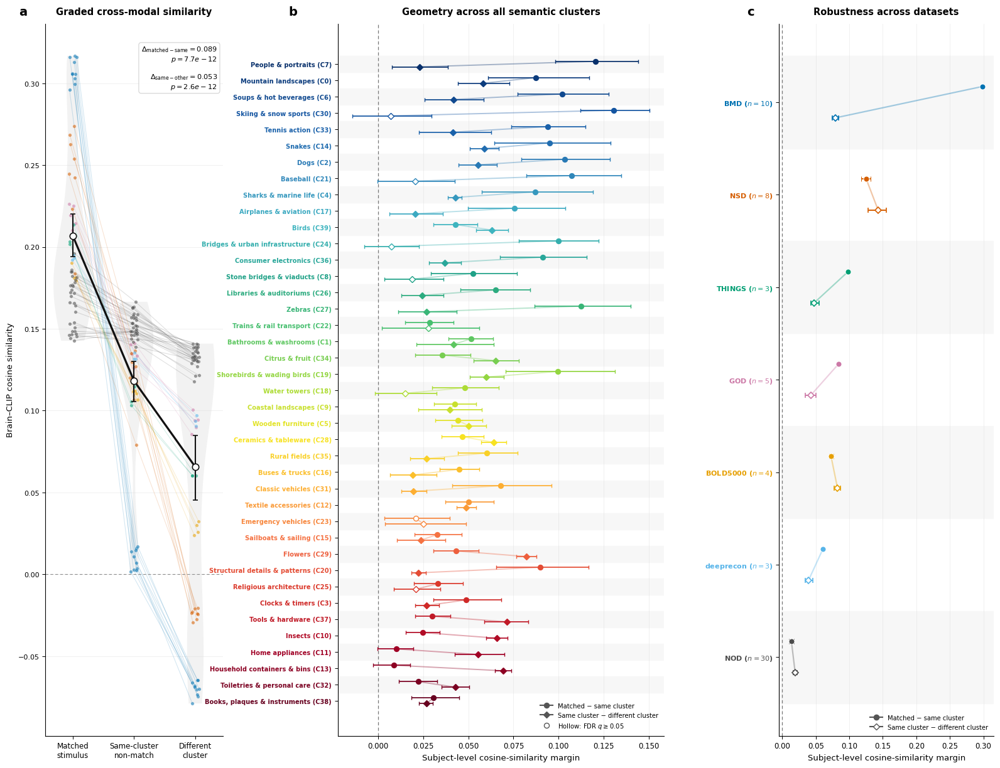

In [533]:
# ============================================================
# CELL 10
# ALL-40 HIERARCHICAL SEMANTIC GEOMETRY FIGURE
#
# Panel a:
#   overall subject-level hierarchy across all 40 clusters
#
# Panel b:
#   all 40 semantic clusters, ordered by retrieval rank
#
# Panel c:
#   dataset-level robustness
# ============================================================


# ============================================================
# Plotting configuration
# ============================================================

plt.rcParams.update({
    "font.family": [
        "Arial",
        "Helvetica",
        "DejaVu Sans",
    ],
    "font.size": 8.5,
    "axes.titlesize": 10.5,
    "axes.labelsize": 9.5,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.0,
    "legend.fontsize": 7.5,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


# ============================================================
# Helpers
# ============================================================

def asymmetric_error(
    mean,
    low,
    high,
):
    return np.asarray([
        [mean - low],
        [high - mean],
    ])


def add_alternating_rows(
    axis,
    n_rows,
    facecolor="#F7F7F7",
):
    for row_index in range(
        n_rows
    ):
        if row_index % 2 == 0:
            axis.axhspan(
                row_index - 0.5,
                row_index + 0.5,
                color=facecolor,
                zorder=0,
            )


def format_p_value(p):
    if p < 1e-3:
        return (
            f"{p:.1e}"
        )

    return (
        f"{p:.3f}"
    )


# ============================================================
# Overall panel-A statistics
# ============================================================

similarity_columns = [
    "matched_similarity",
    "same_cluster_similarity",
    "different_cluster_similarity",
]


similarity_labels = [
    "Matched\nstimulus",
    "Same-cluster\nnon-match",
    "Different\ncluster",
]


overall_means = []
overall_lows = []
overall_highs = []


for column_index, column_name in enumerate(
    similarity_columns
):

    mean_value, low_value, high_value = (
        bootstrap_mean_ci(
            subject_hierarchy_all40_df[
                column_name
            ],
            seed=1000
            + column_index,
        )
    )

    overall_means.append(
        mean_value
    )

    overall_lows.append(
        low_value
    )

    overall_highs.append(
        high_value
    )


overall_means = np.asarray(
    overall_means
)

overall_lows = np.asarray(
    overall_lows
)

overall_highs = np.asarray(
    overall_highs
)


# ============================================================
# Figure layout
#
# Taller figure because panel b contains 40 rows.
# ============================================================

fig = plt.figure(
    figsize=(
        16.5,
        13.2,
    )
)


grid = fig.add_gridspec(
    1,
    3,
    width_ratios=[
        0.95,
        1.75,
        1.15,
    ],
    wspace=0.48,
)


ax_a = fig.add_subplot(
    grid[0, 0]
)

ax_b = fig.add_subplot(
    grid[0, 1]
)

ax_c = fig.add_subplot(
    grid[0, 2]
)


# ============================================================
# PANEL A
# Overall hierarchy across subjects
# ============================================================

x_positions = np.arange(3)


# Distribution
violin_data = [
    subject_hierarchy_all40_df[
        column
    ].to_numpy(dtype=float)
    for column
    in similarity_columns
]


violin_parts = ax_a.violinplot(
    violin_data,
    positions=x_positions,
    widths=0.63,
    showmeans=False,
    showmedians=False,
    showextrema=False,
)


for body in violin_parts[
    "bodies"
]:
    body.set_facecolor(
        "#D9D9D9"
    )

    body.set_edgecolor(
        "none"
    )

    body.set_alpha(
        0.34
    )

    body.set_zorder(
        0
    )


# ------------------------------------------------------------
# Subject trajectories
# ------------------------------------------------------------

rng = np.random.default_rng(
    42
)


subject_offsets = rng.uniform(
    -0.065,
    0.065,
    size=len(
        subject_hierarchy_all40_df
    ),
)


for subject_index, (_, row) in enumerate(
    subject_hierarchy_all40_df.iterrows()
):

    dataset_name = str(
        row[
            "dataset_name"
        ]
    )

    dataset_color = (
        DATASET_COLORS_CLEAN.get(
            dataset_name,
            "#777777",
        )
    )

    values = (
        row[
            similarity_columns
        ]
        .to_numpy(dtype=float)
    )


    shifted_x = (
        x_positions
        + subject_offsets[
            subject_index
        ]
    )


    ax_a.plot(
        shifted_x,
        values,
        color=dataset_color,
        alpha=0.18,
        linewidth=0.75,
        zorder=1,
    )


    ax_a.scatter(
        shifted_x,
        values,
        s=15,
        facecolor=dataset_color,
        edgecolor="white",
        linewidth=0.25,
        alpha=0.55,
        zorder=2,
    )


# ------------------------------------------------------------
# Overall mean
# ------------------------------------------------------------

ax_a.plot(
    x_positions,
    overall_means,
    color="#111111",
    linewidth=2.3,
    zorder=5,
)


ax_a.errorbar(
    x_positions,
    overall_means,
    yerr=np.vstack([
        overall_means
        - overall_lows,

        overall_highs
        - overall_means,
    ]),
    fmt="o",
    color="#111111",
    markerfacecolor="white",
    markeredgecolor="#111111",
    markeredgewidth=1.2,
    markersize=7.5,
    linewidth=1.5,
    capsize=3.2,
    zorder=6,
)


# ------------------------------------------------------------
# Dynamic statistics
# ------------------------------------------------------------

annotation_text = (
    r"$\Delta_{\mathrm{matched-same}}="
    f"{matched_same_all40_mean:.3f}$"
    "\n"
    r"$p="
    f"{format_p_value(matched_same_all40_p)}$"
    "\n\n"
    r"$\Delta_{\mathrm{same-other}}="
    f"{same_different_all40_mean:.3f}$"
    "\n"
    r"$p="
    f"{format_p_value(same_different_all40_p)}$"
)


ax_a.text(
    0.97,
    0.97,
    annotation_text,
    transform=ax_a.transAxes,
    ha="right",
    va="top",
    fontsize=8.1,
    bbox={
        "boxstyle":
            "round,pad=0.35",
        "facecolor":
            "white",
        "edgecolor":
            "#D0D0D0",
        "linewidth":
            0.8,
        "alpha":
            0.96,
    },
    zorder=10,
)


ax_a.axhline(
    0,
    color="#8C8C8C",
    linestyle=(
        0,
        (4, 3),
    ),
    linewidth=0.8,
)


ax_a.set_xticks(
    x_positions
)

ax_a.set_xticklabels(
    similarity_labels
)


ax_a.set_ylabel(
    "Brain–CLIP cosine similarity"
)


ax_a.set_title(
    "Graded cross-modal similarity",
    fontweight="bold",
    pad=10,
)


ax_a.grid(
    axis="y",
    color="#D8D8D8",
    linewidth=0.5,
    alpha=0.55,
)

ax_a.set_axisbelow(
    True
)


# ============================================================
# PANEL B
# All 40 semantic clusters
# ============================================================

cluster_plot_final_all40 = (
    cluster_plot_all40_df
    .sort_values(
        "retrieval_rank"
    )
    .reset_index(drop=True)
)


n_clusters_plot = len(
    cluster_plot_final_all40
)

cluster_y = np.arange(
    n_clusters_plot
)

vertical_offset = 0.17


add_alternating_rows(
    ax_b,
    n_clusters_plot,
)


for row_index, row in (
    cluster_plot_final_all40
    .iterrows()
):

    cluster_id = int(
        row[
            "semantic_cluster"
        ]
    )

    cluster_color = (
        ALL_CLUSTER_COLORS[
            cluster_id
        ]
    )


    exact_mean = float(
        row[
            "matched_minus_same_mean"
        ]
    )

    exact_low = float(
        row[
            "matched_minus_same_low"
        ]
    )

    exact_high = float(
        row[
            "matched_minus_same_high"
        ]
    )

    exact_q = float(
        row[
            "matched_minus_same_q"
        ]
    )


    semantic_mean = float(
        row[
            "same_minus_different_mean"
        ]
    )

    semantic_low = float(
        row[
            "same_minus_different_low"
        ]
    )

    semantic_high = float(
        row[
            "same_minus_different_high"
        ]
    )

    semantic_q = float(
        row[
            "same_minus_different_q"
        ]
    )


    # Connector
    ax_b.plot(
        [
            exact_mean,
            semantic_mean,
        ],
        [
            cluster_y[
                row_index
            ]
            - vertical_offset,

            cluster_y[
                row_index
            ]
            + vertical_offset,
        ],
        color=cluster_color,
        linewidth=1.4,
        alpha=0.35,
        zorder=1,
    )


    # Matched - same
    ax_b.errorbar(
        exact_mean,
        cluster_y[
            row_index
        ]
        - vertical_offset,

        xerr=asymmetric_error(
            exact_mean,
            exact_low,
            exact_high,
        ),

        fmt="o",

        color=cluster_color,

        markerfacecolor=(
            cluster_color
            if exact_q < 0.05
            else "white"
        ),

        markeredgecolor=
            cluster_color,

        markeredgewidth=1.0,

        markersize=5.7,

        linewidth=1.25,

        capsize=2.2,

        zorder=3,
    )


    # Same - different
    ax_b.errorbar(
        semantic_mean,
        cluster_y[
            row_index
        ]
        + vertical_offset,

        xerr=asymmetric_error(
            semantic_mean,
            semantic_low,
            semantic_high,
        ),

        fmt="D",

        color=cluster_color,

        markerfacecolor=(
            cluster_color
            if semantic_q < 0.05
            else "white"
        ),

        markeredgecolor=
            cluster_color,

        markeredgewidth=1.0,

        markersize=4.7,

        linewidth=1.25,

        capsize=2.2,

        zorder=3,
    )


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

cluster_tick_labels = [
    (
        f"{row['cluster_label']} "
        f"(C{int(row['semantic_cluster'])})"
    )
    for _, row
    in cluster_plot_final_all40.iterrows()
]


ax_b.set_yticks(
    cluster_y
)


ax_b.set_yticklabels(
    cluster_tick_labels,
    fontsize=7.1,
)


ax_b.invert_yaxis()


# Colour cluster names by their spectrum colour
for tick_label, (_, row) in zip(
    ax_b.get_yticklabels(),
    cluster_plot_final_all40.iterrows(),
):

    cluster_id = int(
        row[
            "semantic_cluster"
        ]
    )

    tick_label.set_color(
        ALL_CLUSTER_COLORS[
            cluster_id
        ]
    )

    tick_label.set_fontweight(
        "bold"
    )


ax_b.axvline(
    0,
    color="#777777",
    linestyle=(
        0,
        (4, 3),
    ),
    linewidth=0.9,
)


ax_b.set_xlabel(
    "Subject-level cosine-similarity margin"
)


ax_b.set_title(
    "Geometry across all semantic clusters",
    fontweight="bold",
    pad=10,
)


ax_b.grid(
    axis="x",
    color="#D8D8D8",
    linewidth=0.5,
    alpha=0.55,
)

ax_b.set_axisbelow(
    True
)


# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

cluster_legend_handles = [

    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="-",
        color="#555555",
        markerfacecolor="#555555",
        markersize=5.8,
        label="Matched − same cluster",
    ),

    Line2D(
        [0],
        [0],
        marker="D",
        linestyle="-",
        color="#555555",
        markerfacecolor="#555555",
        markersize=4.8,
        label="Same cluster − different cluster",
    ),

    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        color="#555555",
        markerfacecolor="white",
        markersize=5.8,
        label=r"Hollow: FDR $q\geq0.05$",
    ),
]


ax_b.legend(
    handles=
        cluster_legend_handles,
    frameon=False,
    loc="lower right",
    fontsize=7.2,
)


# ============================================================
# PANEL C
# Dataset robustness
# ============================================================

dataset_plot_final_all40 = (
    dataset_plot_all40_df
    .copy()
)


n_datasets_plot = len(
    dataset_plot_final_all40
)

dataset_y = np.arange(
    n_datasets_plot
)


add_alternating_rows(
    ax_c,
    n_datasets_plot,
)


for row_index, row in (
    dataset_plot_final_all40
    .iterrows()
):

    dataset_name = str(
        row[
            "dataset_name"
        ]
    )

    dataset_color = (
        DATASET_COLORS_CLEAN.get(
            dataset_name,
            "#666666",
        )
    )


    exact_mean = float(
        row[
            "matched_minus_same_mean"
        ]
    )

    exact_low = float(
        row[
            "matched_minus_same_low"
        ]
    )

    exact_high = float(
        row[
            "matched_minus_same_high"
        ]
    )


    semantic_mean = float(
        row[
            "same_minus_different_mean"
        ]
    )

    semantic_low = float(
        row[
            "same_minus_different_low"
        ]
    )

    semantic_high = float(
        row[
            "same_minus_different_high"
        ]
    )


    ax_c.plot(
        [
            exact_mean,
            semantic_mean,
        ],
        [
            dataset_y[
                row_index
            ]
            - vertical_offset,

            dataset_y[
                row_index
            ]
            + vertical_offset,
        ],
        color=dataset_color,
        linewidth=1.6,
        alpha=0.35,
        zorder=1,
    )


    ax_c.errorbar(
        exact_mean,
        dataset_y[
            row_index
        ]
        - vertical_offset,

        xerr=asymmetric_error(
            exact_mean,
            exact_low,
            exact_high,
        ),

        fmt="o",
        color=dataset_color,
        markerfacecolor=
            dataset_color,
        markeredgecolor="white",
        markeredgewidth=0.7,
        markersize=6.5,
        linewidth=1.4,
        capsize=2.6,
        zorder=3,
    )


    ax_c.errorbar(
        semantic_mean,
        dataset_y[
            row_index
        ]
        + vertical_offset,

        xerr=asymmetric_error(
            semantic_mean,
            semantic_low,
            semantic_high,
        ),

        fmt="D",
        color=dataset_color,
        markerfacecolor="white",
        markeredgecolor=
            dataset_color,
        markeredgewidth=1.2,
        markersize=5.4,
        linewidth=1.4,
        capsize=2.6,
        zorder=3,
    )


dataset_tick_labels = [
    (
        f"{row['dataset_name']} "
        f"($n={int(row['n_subjects'])}$)"
    )
    for _, row
    in dataset_plot_final_all40.iterrows()
]


ax_c.set_yticks(
    dataset_y
)

ax_c.set_yticklabels(
    dataset_tick_labels
)

ax_c.invert_yaxis()


for tick_label, (_, row) in zip(
    ax_c.get_yticklabels(),
    dataset_plot_final_all40.iterrows(),
):

    dataset_name = str(
        row[
            "dataset_name"
        ]
    )

    tick_label.set_color(
        DATASET_COLORS_CLEAN.get(
            dataset_name,
            "#333333",
        )
    )

    tick_label.set_fontweight(
        "bold"
    )


ax_c.axvline(
    0,
    color="#777777",
    linestyle=(
        0,
        (4, 3),
    ),
    linewidth=0.9,
)


ax_c.set_xlabel(
    "Subject-level cosine-similarity margin"
)


ax_c.set_title(
    "Robustness across datasets",
    fontweight="bold",
    pad=10,
)


ax_c.grid(
    axis="x",
    color="#D8D8D8",
    linewidth=0.5,
    alpha=0.55,
)


ax_c.set_axisbelow(
    True
)


dataset_legend_handles = [

    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="-",
        color="#555555",
        markerfacecolor="#555555",
        markersize=6,
        label="Matched − same cluster",
    ),

    Line2D(
        [0],
        [0],
        marker="D",
        linestyle="-",
        color="#555555",
        markerfacecolor="white",
        markersize=5.2,
        label="Same cluster − different cluster",
    ),
]


ax_c.legend(
    handles=
        dataset_legend_handles,
    frameon=False,
    loc="lower right",
    fontsize=7.2,
)


# ============================================================
# Panel labels
# ============================================================

for panel_label, axis in zip(
    ["a", "b", "c"],
    [
        ax_a,
        ax_b,
        ax_c,
    ],
):

    axis.text(
        -0.15,
        1.025,
        panel_label,
        transform=
            axis.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="left",
        va="top",
    )


# ============================================================
# Layout
# ============================================================

fig.subplots_adjust(
    left=0.07,
    right=0.985,
    bottom=0.09,
    top=0.95,
    wspace=0.48,
)


# ============================================================
# Save
# ============================================================

figure_pdf = (
    geometry_all40_out
    / "hierarchical_semantic_geometry_all40.pdf"
)

figure_png = (
    geometry_all40_out
    / "hierarchical_semantic_geometry_all40.png"
)


fig.savefig(
    figure_pdf,
    bbox_inches="tight",
)

fig.savefig(
    figure_png,
    dpi=500,
    bbox_inches="tight",
)


print(
    "Saved:",
    figure_pdf,
)

print(
    "Saved:",
    figure_png,
)

plt.show()

### Fig. S2c — Network composition of the most cluster-selective ROIs

In [534]:
# ============================================================
# Standalone setup for the ALL-40 radar figure (cell below)
# Loads everything from disk — no earlier cells needed.
#
# Rebuilds the radar input from the saved CSV written by
# "CELL 5 — Network composition of top cluster-selective ROIs",
# so the saliency matrix and model are not required.
#
# Provides: observed_count_radar_all40_pivot,
#   CLUSTER_RETRIEVAL_ORDER, all40_radar_cluster_color_map,
#   all40_radar_cluster_label_map, saliency_fig_out,
#   TOP_K_SELECTIVE_ROIS, get_radar_network_label,
#   plot_all40_cluster_network_radar_compact
# ============================================================

import math
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.transforms import Bbox


# ============================================================
# 1. Paths
# ============================================================

analysis5_out = Path(
    str(RESULTS_ROOT) + "/"
    "analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS"
)

saliency_out = analysis5_out / "roi_saliency_maps"

saliency_fig_out = (
    analysis5_out
    / "publication_figures"
    / "roi_saliency_maps"
)

saliency_fig_out.mkdir(
    parents=True,
    exist_ok=True,
)

TOP_K_SELECTIVE_ROIS = 20

radar_counts_path = (
    saliency_out
    / (
        f"top{TOP_K_SELECTIVE_ROIS}_"
        "cluster_selective_roi_"
        "network_decomposition_ALL40.csv"
    )
)


# ============================================================
# 2. Retrieval-ranked cluster order, names and colours
# ============================================================

CLUSTER_RETRIEVAL_ORDER = [
    7, 0, 6, 30, 33, 14, 2, 21, 4, 17,
    39, 24, 36, 8, 26, 27, 22, 1, 34, 19,
    18, 9, 5, 28, 35, 16, 31, 12, 23, 15,
    29, 20, 25, 3, 37, 10, 11, 13, 32, 38,
]

assert len(CLUSTER_RETRIEVAL_ORDER) == 40
assert set(CLUSTER_RETRIEVAL_ORDER) == set(range(40))


CLUSTER_NAME_MAP = {
    0:  "Mountains & landscapes",
    1:  "Bathrooms & interiors",
    2:  "Dogs",
    3:  "Clocks & gauges",
    4:  "Sharks & marine life",
    5:  "Wooden furniture",
    6:  "Bowls & drinks",
    7:  "People & portraits",
    8:  "Stone arches & ruins",
    9:  "Coasts & oceans",
    10: "Insects",
    11: "Home appliances",
    12: "Bags & textiles",
    13: "Containers & boxes",
    14: "Reptiles & frogs",
    15: "Sailboats",
    16: "Buses",
    17: "Airplanes",
    18: "Water towers",
    19: "Shore birds",
    20: "Architectural details",
    21: "Baseball",
    22: "Trains & rail transport",
    23: "Emergency vehicles",
    24: "Bridges",
    25: "Religious architecture",
    26: "Libraries & theatres",
    27: "Zebras",
    28: "Cups & jugs",
    29: "Flowers",
    30: "Skiing",
    31: "Cars & trucks",
    32: "Toiletries & bottles",
    33: "Tennis action",
    34: "Fruits",
    35: "Rural fields",
    36: "Consumer electronics",
    37: "Tools & hardware",
    38: "Books & artifacts",
    39: "Birds",
}


# Blue -> red spectrum following retrieval rank
# (same anchors as the "Ordered semantic-cluster spectrum" cell)
SPECTRUM_ANCHORS = [
    "#08306B",
    "#1558A6",
    "#2C7FB8",
    "#41B6C4",
    "#1FA187",
    "#4AC16D",
    "#A0DA39",
    "#F6E620",
    "#FDAE32",
    "#F46D43",
    "#D73027",
    "#A50026",
    "#67001F",
]

cluster_spectrum_cmap = LinearSegmentedColormap.from_list(
    "cluster_retrieval_blue_to_red",
    SPECTRUM_ANCHORS,
    N=4096,
)

ALL_CLUSTER_COLORS = {
    cluster_id: mcolors.to_hex(color)
    for cluster_id, color in zip(
        CLUSTER_RETRIEVAL_ORDER,
        cluster_spectrum_cmap(
            np.linspace(0.0, 1.0, len(CLUSTER_RETRIEVAL_ORDER))
        ),
    )
}

all40_radar_cluster_label_map = {
    cluster_id: (
        f"{CLUSTER_NAME_MAP[cluster_id]} "
        f"(C{cluster_id})"
    )
    for cluster_id in CLUSTER_RETRIEVAL_ORDER
}

all40_radar_cluster_color_map = {
    cluster_id: ALL_CLUSTER_COLORS[cluster_id]
    for cluster_id in CLUSTER_RETRIEVAL_ORDER
}


# ============================================================
# 3. Network order and radar labels
# ============================================================

NETWORK_DISPLAY_ORDER = [
    "early_visual",
    "motion_visual",
    "ventral_visual_object_scene",
    "parietal_attention",
    "frontal_control",
    "temporal_auditory_language",
    "cerebellum",
    "subcortical",
    "other",
]

RADAR_NETWORK_LABELS = {
    "early_visual": "Early\nvisual",
    "motion_visual": "Motion\nvisual",
    "ventral_visual_object_scene": "Ventral\nvisual/\nobject",
    "parietal_attention": "Parietal\nattention",
    "frontal_control": "Frontal/\ncontrol",
    "temporal_auditory_language": "Temporal/\nauditory",
    "cerebellum": "Cerebellum",
    "subcortical": "Subcortical",
    "other": "Other",
}


def get_radar_network_label(network_name):
    return RADAR_NETWORK_LABELS.get(
        network_name,
        str(network_name).replace("_", " ").title(),
    )


# ============================================================
# 4. Radar matrix: clusters × networks, observed ROI counts
# ============================================================

top_selective_network_counts_all40 = pd.read_csv(
    radar_counts_path
)

network_order_actual = [
    network
    for network in NETWORK_DISPLAY_ORDER
    if network
    in set(top_selective_network_counts_all40["ablation_group"])
]

observed_count_radar_all40_pivot = (
    top_selective_network_counts_all40
    .pivot_table(
        index="semantic_cluster",
        columns="ablation_group",
        values="n_top_selective_rois",
        aggfunc="sum",
        fill_value=0,
    )
    .reindex(
        index=CLUSTER_RETRIEVAL_ORDER,
        columns=network_order_actual,
        fill_value=0,
    )
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .astype(int)
)

assert observed_count_radar_all40_pivot.shape == (
    40,
    len(network_order_actual),
)

print("Loaded:", radar_counts_path)
print("Radar pivot shape:", observed_count_radar_all40_pivot.shape)
print("Networks:", network_order_actual)


# ============================================================
# 5. Compact ALL-40 radar plotting function
#
# Panels are packed as tightly as possible without any text
# overlapping. The layout is measured, not guessed:
#   1. draw every panel at a provisional size
#   2. measure how far each panel's network labels and title
#      extend beyond its circle (fixed in points, so it does
#      not depend on circle size)
#   3. give each column the width and each row the height its
#      own panels need, plus `panel_gap` inches between the
#      text extents of neighbouring panels
#   4. make the circles as large as the figure width allows
#   5. re-measure and confirm that no two panels overlap
# ============================================================

FONT_FAMILY = ["Arial", "Helvetica", "DejaVu Sans"]


def _union_bbox(bboxes):
    return Bbox.union([b for b in bboxes if b.width > 0 or b.height > 0])


def _panel_text_bboxes(ax, title_artist, renderer):
    """
    Display-space boxes of every text element belonging to
    one radar panel, plus the circle itself.
    """
    bboxes = [ax.bbox]

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        if label.get_visible() and label.get_text():
            bboxes.append(label.get_window_extent(renderer))

    if title_artist is not None:
        bboxes.append(title_artist.get_window_extent(renderer))

    return bboxes


def plot_all40_cluster_network_radar_compact(
    radar_pivot,
    cluster_order,
    cluster_color_map,
    cluster_label_map,
    network_label_func=get_radar_network_label,

    # Layout
    ncols=5,
    fig_width=34.0,
    panel_gap=0.12,
    outer_margin=0.15,
    header_gap=0.15,

    # Shared radial scale
    radial_max=None,
    radial_tick_step=None,

    # Typography
    network_fontsize=18.0,
    network_fontweight="bold",
    radial_fontsize=14.0,
    cluster_title_fontsize=24.0,
    cluster_title_wrap_width=24,
    figure_title_fontsize=34.0,
    footer_fontsize=20.0,

    # Spacing between circle, labels and title (points)
    network_label_pad=8.0,
    title_gap_pts=4.0,

    # Polygon appearance
    line_width=4.0,
    marker_size=11.0,
    fill_alpha=0.22,
    marker_facecolor="#FFF3B0",
    marker_edgecolor="#222222",
    marker_edgewidth=2.2,

    # Grid appearance
    radial_grid_color="#8F98A6",
    angular_grid_color="#C5CBD4",
    radial_grid_width=1.4,
    angular_grid_width=1.1,
    outer_ring_color="#4D5560",
    outer_ring_width=2.0,
    show_background_bands=True,

    # Output
    title=None,
    footer=(
        "Radius indicates the observed number of top "
        "cluster-selective ROIs assigned to each network."
    ),
    save_path=None,
):

    plt.rcParams.update({
        "font.family": FONT_FAMILY,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.facecolor": "white",
    })

    # ========================================================
    # Data and shared radial scale
    # ========================================================

    pivot = radar_pivot.copy()
    pivot.index = pivot.index.astype(int)

    cluster_order = [
        int(c) for c in cluster_order
        if int(c) in pivot.index
    ]

    network_order = list(pivot.columns)
    n_networks = len(network_order)

    if n_networks < 3:
        raise ValueError(
            "Radar plots require at least three network groups."
        )

    observed_max = float(
        np.nanmax(
            pivot.loc[cluster_order, network_order]
            .to_numpy(dtype=float)
        )
    )

    if radial_max is None:
        # Round upward to the next even number
        radial_max = max(4, int(np.ceil(observed_max / 2) * 2))

    if radial_tick_step is None:
        if radial_max <= 8:
            radial_tick_step = 2
        elif radial_max <= 16:
            radial_tick_step = 4
        else:
            radial_tick_step = 5

    radial_ticks = np.arange(
        radial_tick_step,
        radial_max + radial_tick_step,
        radial_tick_step,
    )
    radial_ticks = radial_ticks[radial_ticks <= radial_max]

    radial_boundaries = np.concatenate([[0], radial_ticks])

    if radial_boundaries[-1] < radial_max:
        radial_boundaries = np.append(radial_boundaries, radial_max)

    print("Shared radar radial maximum:", radial_max)
    print("Radial ticks:", radial_ticks.tolist())

    angles = np.linspace(0, 2 * np.pi, n_networks, endpoint=False)
    angles_closed = np.concatenate([angles, [angles[0]]])
    background_angles = np.linspace(0, 2 * np.pi, 720)

    network_labels = [
        network_label_func(network)
        for network in network_order
    ]

    n_clusters = len(cluster_order)
    nrows = math.ceil(n_clusters / ncols)

    # ========================================================
    # Pass 1: draw every panel at a provisional size
    # ========================================================

    provisional_height = fig_width * nrows / ncols

    fig = plt.figure(
        figsize=(fig_width, provisional_height),
        facecolor="white",
    )

    axes = []

    for panel_index, cluster_id in enumerate(cluster_order):
        row, col = divmod(panel_index, ncols)

        ax = fig.add_axes(
            [
                col / ncols + 0.02,
                1 - (row + 1) / nrows + 0.02,
                0.6 / ncols,
                0.6 / nrows,
            ],
            projection="polar",
        )

        axes.append(ax)

        values = (
            pivot.loc[cluster_id, network_order]
            .to_numpy(dtype=float)
        )
        values_closed = np.concatenate([values, [values[0]]])

        cluster_color = cluster_color_map[cluster_id]

        ax.set_theta_offset(np.pi / 2)
        ax.set_theta_direction(-1)
        ax.set_ylim(0, radial_max)
        ax.set_axisbelow(True)
        ax.set_facecolor("white")

        # Alternating radial bands
        if show_background_bands:
            for band_index in range(len(radial_boundaries) - 1):
                if band_index % 2 == 0:
                    ax.fill_between(
                        background_angles,
                        radial_boundaries[band_index],
                        radial_boundaries[band_index + 1],
                        color="#F1F2F4",
                        alpha=0.76,
                        zorder=0,
                    )

        # Radial tick labels
        ax.set_yticks(radial_ticks)
        ax.set_yticklabels(
            [str(int(tick)) for tick in radial_ticks],
            fontsize=radial_fontsize,
            color="#42474F",
            fontweight="semibold",
        )
        ax.set_rlabel_position(76)

        for radial_label in ax.get_yticklabels():
            radial_label.set_bbox({
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.82,
                "pad": 0.8,
            })

        # Grid and outer ring
        ax.yaxis.grid(
            True,
            color=radial_grid_color,
            linewidth=radial_grid_width,
            alpha=0.95,
            zorder=1,
        )
        ax.xaxis.grid(
            True,
            color=angular_grid_color,
            linewidth=angular_grid_width,
            alpha=0.92,
            zorder=1,
        )
        ax.spines["polar"].set_color(outer_ring_color)
        ax.spines["polar"].set_linewidth(outer_ring_width)

        # Polygon
        ax.fill(
            angles_closed,
            values_closed,
            color=cluster_color,
            alpha=fill_alpha,
            zorder=2,
        )
        ax.plot(
            angles_closed,
            values_closed,
            color=cluster_color,
            linewidth=line_width,
            solid_capstyle="round",
            solid_joinstyle="round",
            zorder=4,
        )
        ax.scatter(
            angles,
            values,
            s=marker_size ** 2,
            facecolor=marker_facecolor,
            edgecolor=marker_edgecolor,
            linewidth=marker_edgewidth,
            zorder=5,
        )

        # Network labels
        ax.set_xticks(angles)
        ax.set_xticklabels(
            network_labels,
            fontsize=network_fontsize,
            color="#111111",
            fontweight=network_fontweight,
            fontfamily=FONT_FAMILY,
        )
        ax.tick_params(axis="x", pad=network_label_pad)

        for angle, label in zip(angles, ax.get_xticklabels()):
            angle_deg = np.degrees(angle) % 360

            if 15 < angle_deg < 165:
                label.set_horizontalalignment("left")
            elif 195 < angle_deg < 345:
                label.set_horizontalalignment("right")
            else:
                label.set_horizontalalignment("center")

            label.set_verticalalignment("center")
            label.set_bbox({
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.92,
                "pad": 0.8,
            })

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    px_to_pt = 72.0 / fig.dpi

    # ========================================================
    # Place cluster titles just above the highest network label
    # ========================================================

    label_top_overhang_pts = max(
        (
            max(
                label.get_window_extent(renderer).y1
                for label in ax.get_xticklabels()
            )
            - ax.bbox.y1
        )
        * px_to_pt
        for ax in axes
    )

    title_offset_pts = max(label_top_overhang_pts, 0) + title_gap_pts

    title_artists = []

    for ax, cluster_id in zip(axes, cluster_order):
        wrapped_label = textwrap.fill(
            str(cluster_label_map[cluster_id]),
            width=cluster_title_wrap_width,
            break_long_words=False,
            break_on_hyphens=False,
        )

        title_artists.append(
            ax.annotate(
                wrapped_label,
                xy=(0.5, 1.0),
                xycoords="axes fraction",
                xytext=(0, title_offset_pts),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=cluster_title_fontsize,
                color=cluster_color_map[cluster_id],
                fontweight="bold",
                linespacing=1.05,
                annotation_clip=False,
                zorder=20,
            )
        )

    # Figure title and footer
    if title is None:
        title = (
            f"Network composition of the top "
            f"{TOP_K_SELECTIVE_ROIS} cluster-selective ROIs"
        )

    title_artist = (
        fig.text(
            0.5,
            0.99,
            title,
            ha="center",
            va="top",
            fontsize=figure_title_fontsize,
            fontweight="bold",
        )
        if title
        else None
    )

    footer_artist = (
        fig.text(
            0.5,
            0.01,
            footer,
            ha="center",
            va="bottom",
            fontsize=footer_fontsize,
            color="#42464D",
        )
        if footer
        else None
    )

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    # ========================================================
    # Measure how far text extends beyond each circle (inches)
    # ========================================================

    dpi = fig.dpi

    overhang = []

    for ax, panel_title in zip(axes, title_artists):
        ext = _union_bbox(
            _panel_text_bboxes(ax, panel_title, renderer)
        )
        circle = ax.bbox

        overhang.append({
            "left": (circle.x0 - ext.x0) / dpi,
            "right": (ext.x1 - circle.x1) / dpi,
            "top": (ext.y1 - circle.y1) / dpi,
            "bottom": (circle.y0 - ext.y0) / dpi,
        })

    col_left = [0.0] * ncols
    col_right = [0.0] * ncols
    row_top = [0.0] * nrows
    row_bottom = [0.0] * nrows

    for panel_index, o in enumerate(overhang):
        row, col = divmod(panel_index, ncols)

        col_left[col] = max(col_left[col], o["left"])
        col_right[col] = max(col_right[col], o["right"])
        row_top[row] = max(row_top[row], o["top"])
        row_bottom[row] = max(row_bottom[row], o["bottom"])

    title_height = (
        title_artist.get_window_extent(renderer).height / dpi
        + header_gap
        if title_artist is not None
        else 0.0
    )

    footer_height = (
        footer_artist.get_window_extent(renderer).height / dpi
        + header_gap
        if footer_artist is not None
        else 0.0
    )

    # ========================================================
    # Largest circle the width allows
    # ========================================================

    diameter = (
        fig_width
        - 2 * outer_margin
        - sum(col_left)
        - sum(col_right)
        - (ncols - 1) * panel_gap
    ) / ncols

    if diameter < 1.0:
        raise ValueError(
            f"Radar circles would be only {diameter:.2f} in wide. "
            "Increase fig_width or reduce the font sizes."
        )

    fig_height = (
        2 * outer_margin
        + title_height
        + footer_height
        + sum(row_top)
        + sum(row_bottom)
        + nrows * diameter
        + (nrows - 1) * panel_gap
    )

    fig.set_size_inches(fig_width, fig_height)

    # ========================================================
    # Place panels
    # ========================================================

    col_x = []
    x = outer_margin

    for col in range(ncols):
        col_x.append(x + col_left[col])
        x += col_left[col] + diameter + col_right[col] + panel_gap

    row_y = []
    y = fig_height - outer_margin - title_height

    for row in range(nrows):
        top_of_circle = y - row_top[row]
        bottom_of_circle = top_of_circle - diameter
        row_y.append(bottom_of_circle)
        y = bottom_of_circle - row_bottom[row] - panel_gap

    for panel_index, ax in enumerate(axes):
        row, col = divmod(panel_index, ncols)

        ax.set_position([
            col_x[col] / fig_width,
            row_y[row] / fig_height,
            diameter / fig_width,
            diameter / fig_height,
        ])

    if title_artist is not None:
        title_artist.set_position(
            (0.5, 1 - outer_margin / fig_height)
        )

    if footer_artist is not None:
        footer_artist.set_position(
            (0.5, outer_margin / fig_height)
        )

    # ========================================================
    # Verify: no panel's text overlaps another panel's text
    # ========================================================

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    panel_boxes = [
        _union_bbox(_panel_text_bboxes(ax, panel_title, renderer))
        for ax, panel_title in zip(axes, title_artists)
    ]

    extra_boxes = [
        artist.get_window_extent(renderer)
        for artist in [title_artist, footer_artist]
        if artist is not None
    ]

    # Within each panel: network labels, radial labels and title
    n_within = 0

    for ax, panel_title in zip(axes, title_artists):
        boxes = [
            label.get_window_extent(renderer)
            for label in ax.get_xticklabels() + ax.get_yticklabels()
            if label.get_visible() and label.get_text()
        ]
        boxes.append(panel_title.get_window_extent(renderer))

        for i in range(len(boxes)):
            for j in range(i + 1, len(boxes)):
                if boxes[i].overlaps(boxes[j]):
                    n_within += 1

    n_overlaps = 0

    for i in range(len(panel_boxes)):
        for j in range(i + 1, len(panel_boxes)):
            if panel_boxes[i].overlaps(panel_boxes[j]):
                n_overlaps += 1

        for extra in extra_boxes:
            if panel_boxes[i].overlaps(extra):
                n_overlaps += 1

    print(f"Radar layout: {ncols} columns × {nrows} rows")
    print(
        f"Figure size: {fig_width:.1f} × {fig_height:.1f} in, "
        f"circle diameter {diameter:.2f} in, "
        f"gap between panels {panel_gap:.2f} in"
    )
    print("Overlapping panel pairs:", n_overlaps)
    print("Overlapping labels within panels:", n_within)

    if n_overlaps or n_within:
        print(
            "WARNING: some text overlaps. Increase panel_gap "
            "or reduce font sizes."
        )

    # ========================================================
    # Save
    # ========================================================

    if save_path is not None:
        save_path = Path(save_path).with_suffix(".pdf")

        fig.savefig(save_path, facecolor="white")
        print("Saved:", save_path)

        png_path = save_path.with_suffix(".png")
        fig.savefig(png_path, dpi=300, facecolor="white")
        print("Saved:", png_path)

    plt.show()

    return fig


print("\nSetup complete. Run the radar cell below.")

Loaded: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/roi_saliency_maps/top20_cluster_selective_roi_network_decomposition_ALL40.csv
Radar pivot shape: (40, 9)
Networks: ['early_visual', 'motion_visual', 'ventral_visual_object_scene', 'parietal_attention', 'frontal_control', 'temporal_auditory_language', 'cerebellum', 'subcortical', 'other']

Setup complete. Run the radar cell below.


Shared radar radial maximum: 14
Radial ticks: [4, 8, 12]


Radar layout: 5 columns × 8 rows
Figure size: 34.0 × 43.0 in, circle diameter 3.56 in, gap between panels 0.12 in
Overlapping panel pairs: 0
Overlapping labels within panels: 0
Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/roi_saliency_maps/top20_cluster_selective_network_observed_count_radar_ALL40_5COL_COMPACT.pdf
Saved: /data/data/moein/Mosaic_foundation/many_brains_one_geometry_release/results/analysis_5_roi_network_ablation_CLEAN_ALL_DATASETS/publication_figures/roi_saliency_maps/top20_cluster_selective_network_observed_count_radar_ALL40_5COL_COMPACT.png


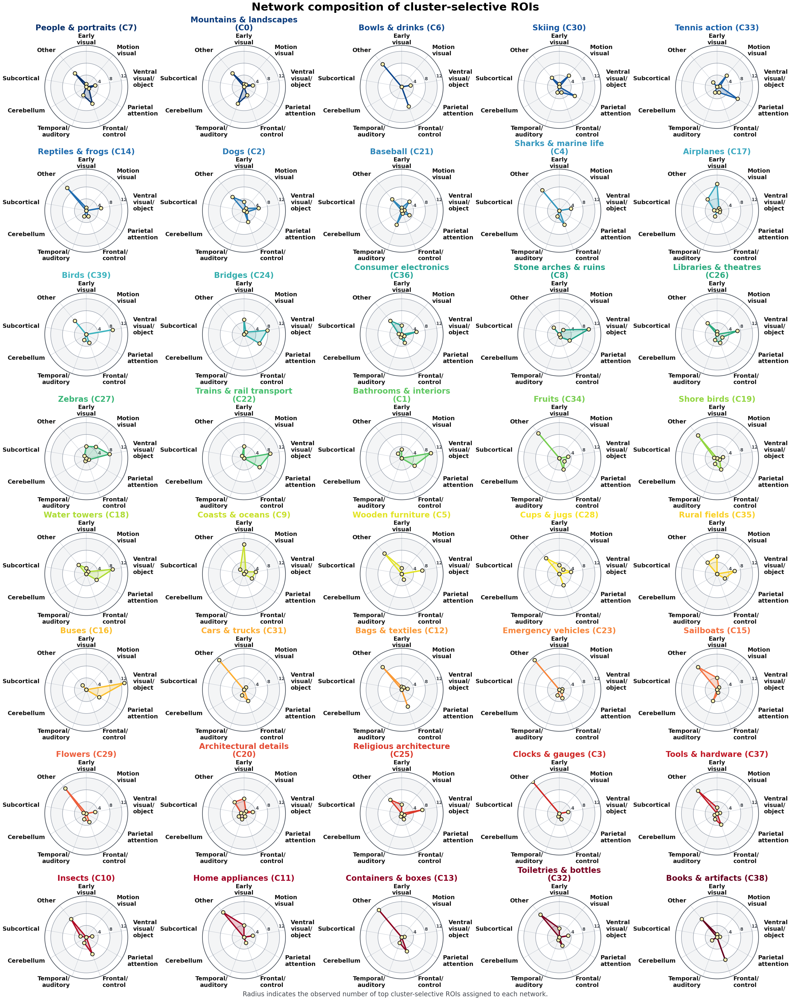

In [535]:
# ============================================================
# CELL 9
# Generate final ALL-40 radar figure
#
# 5 columns × 8 rows
# Compact layout: panels are packed as tightly as possible
# without any text overlapping, and circles are made as large
# as the figure width allows.
#
# To trade circle size for text size, change fig_width or the
# font sizes; the layout recomputes itself.
# ============================================================

radar_all40_fig = (
    plot_all40_cluster_network_radar_compact(

        radar_pivot=
            observed_count_radar_all40_pivot,

        cluster_order=
            CLUSTER_RETRIEVAL_ORDER,

        cluster_color_map=
            all40_radar_cluster_color_map,

        cluster_label_map=
            all40_radar_cluster_label_map,


        # ----------------------------------------------------
        # Layout
        # ----------------------------------------------------

        ncols=
            5,

        # Height is computed from the content
        fig_width=
            34.0,

        # Minimum white space (inches) between the text
        # extents of neighbouring panels
        panel_gap=
            0.12,


        # ----------------------------------------------------
        # Shared radial scale
        # ----------------------------------------------------

        radial_max=
            None,

        radial_tick_step=
            None,


        # ----------------------------------------------------
        # Typography
        # ----------------------------------------------------

        network_fontsize=
            18.0,

        radial_fontsize=
            14.0,

        cluster_title_fontsize=
            24.0,

        cluster_title_wrap_width=
            24,

        figure_title_fontsize=
            34.0,

        footer_fontsize=
            20.0,


        # ----------------------------------------------------
        # Spacing between circle, labels and title (points)
        # ----------------------------------------------------

        network_label_pad=
            8.0,

        title_gap_pts=
            4.0,


        # ----------------------------------------------------
        # Polygon / circles
        # ----------------------------------------------------

        line_width=
            4.0,

        fill_alpha=
            0.22,

        marker_size=
            11.0,

        marker_facecolor=
            "#FFF3B0",

        marker_edgecolor=
            "#222222",

        marker_edgewidth=
            2.2,


        # ----------------------------------------------------
        # Radar grid
        # ----------------------------------------------------

        radial_grid_color=
            "#8F98A6",

        angular_grid_color=
            "#C5CBD4",

        radial_grid_width=
            1.4,

        angular_grid_width=
            1.1,

        outer_ring_color=
            "#4D5560",

        outer_ring_width=
            2.0,


        # ----------------------------------------------------
        # Figure title
        # ----------------------------------------------------

        title=(
            "Network composition of "
            "cluster-selective ROIs"
        ),


        # ----------------------------------------------------
        # Save (new filename; the earlier figure is kept)
        # ----------------------------------------------------

        save_path=(
            saliency_fig_out
            / (
                f"top{TOP_K_SELECTIVE_ROIS}_"
                "cluster_selective_network_"
                "observed_count_radar_ALL40_"
                "5COL_COMPACT.pdf"
            )
        ),
    )
)

---
## Supplementary Figure S3 — Selected versus last checkpoint

Compares the selected checkpoint (`checkpoints/checkpoint.ckpt`, used throughout the paper) with the last checkpoint of the same training run (`checkpoints/last_checkpoint.ckpt`). Both checkpoints are run on all held-out trials; this section needs a GPU and the MOSAIC data.

In [1]:
# ============================================================
# Fig. S3 setup: checkpoints, data paths and plotting style
# ============================================================

import sys, json, pickle, importlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import hypergeom, spearmanr
import mosaic

RELEASE_DIR = Path(globals().get("RELEASE_DIR", Path.cwd()))
MOSAIC_ROOT = Path(globals().get("MOSAIC_ROOT", "/mount/share/moein/MOSAIC"))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

CHECKPOINTS = {
    "Selected": RELEASE_DIR / "checkpoints" / "checkpoint.ckpt",
    "Last": RELEASE_DIR / "checkpoints" / "last_checkpoint.ckpt",
}
PAIR = list(CHECKPOINTS)
SEL, LAST = PAIR
COLOR = {"Selected": "#eb6834", "Last": "#1baf7a"}
MARKER = {"Selected": "s", "Last": "^"}

CLUSTER_CSV = RELEASE_DIR / "results" / "analysis_2_semantic_clusters" / "analysis2_unique_stimulus_clusters.csv"
out_dir = RELEASE_DIR / "results" / "epoch_comparison"
out_dir.mkdir(parents=True, exist_ok=True)

SEED, N_BOOT, TOPK = 42, 2000, (1, 5, 10)

NATURE_RC = {
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 7.5, "axes.labelsize": 7, "xtick.labelsize": 6.5, "ytick.labelsize": 6.5,
    "legend.fontsize": 6.5, "axes.linewidth": 0.6, "axes.edgecolor": "#3d3d3d", "axes.labelcolor": "#1a1a1a",
    "xtick.color": "#3d3d3d", "ytick.color": "#3d3d3d", "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5, "xtick.minor.size": 1.5, "xtick.minor.width": 0.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left", "axes.titlepad": 9,
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 600, "legend.frameon": False,
}
INK, MUTED, GRID = "#1a1a1a", "#8a8a85", "#ebeae5"


def panel(ax, letter, title):
    ax.set_title(title, color=INK)
    ax.annotate(letter, xy=(0, 1), xycoords="axes fraction", xytext=(-26, 9), textcoords="offset points",
                fontsize=9.5, fontweight="bold", va="bottom", ha="left", color=INK)


def dataset_ticks(ax, names, counts, unit="n"):
    k = lambda n: f"{n / 1000:.1f}k" if n >= 1000 else f"{n}"
    ax.set_xticks(range(len(names)), [f"{g}\n{unit} = {k(int(n))}" if unit else f"{g}\n({int(n)})"
                                      for g, n in zip(names, counts)], fontsize=5.9)


def checkpoint_points(ax, df, x, width=0.13):
    # Dodged point + 95% CI per checkpoint; returns the top of each group's CIs.
    tops = np.zeros(len(df))
    for j, c in enumerate(PAIR):
        xs = x + (j - (len(PAIR) - 1) / 2) * 2 * width
        y, lo, hi = (100 * df[f"{m}_{c}"].to_numpy() for m in ["acc", "lo", "hi"])
        ax.errorbar(xs, y, yerr=[y - lo, hi - y], fmt="none", ecolor=COLOR[c], elinewidth=0.9, capsize=0, zorder=2)
        ax.scatter(xs, y, marker=MARKER[c], s=22, color=COLOR[c], edgecolor="white", linewidth=0.6, zorder=3, label=c)
        tops = np.maximum(tops, hi)
    return tops

pixdim[1,2,3] should be non-zero; setting 0 dims to 1


In [2]:
# ============================================================
# Brain embeddings of all held-out trials under both checkpoints
# (needs a GPU and the MOSAIC data)
# ============================================================

sys.path.insert(0, str(RELEASE_DIR / "training"))
Lit = importlib.import_module("train_mosaic_brain_clip").LitMultitaskMAEContrastive

schema = json.load(open(MOSAIC_ROOT / "mosaic_roi_mae_runs" / "roi_schema.json"))
roi_names = schema["roi_names"]
canonical_meta = pickle.load(open(MOSAIC_ROOT / "meta_data_compiled" / "canonical_meta_remapped.pkl", "rb"))
index_df = pd.read_pickle(MOSAIC_ROOT / "mosaic_roi_mae_runs" / "mosaic_index_cache.pkl")
val_idx = index_df.loc[index_df["is_val"], "real_idx"].to_numpy(np.int64)

models = {
    c: Lit.load_from_checkpoint(path, roi_names=roi_names, roi_dims=[schema["roi_dims"][r] for r in roi_names],
                                map_location=DEVICE, strict=False, weights_only=False).eval().to(DEVICE)
    for c, path in CHECKPOINTS.items()
}
hp = models[SEL].hparams


class HeldOut(Dataset):
    # Same preprocessing as training: per-ROI z-scoring, clipped at +/-5.
    def __init__(self, data, indices):
        self.data, self.indices = data, indices
        self.clip = {r.clean: r.canonical_embedding for r in canonical_meta.itertuples(index=False)}
        self.stim_id = {c: i for i, c in enumerate(canonical_meta["clean"].tolist())}

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        s = self.data[int(self.indices[i])]
        clean = s["name"].split("stimulus-")[1].split("_phase")[0].replace(" ", "_").split(".")[0]
        subj, dset = s["name"].split("_")[:2]
        rois = []
        for r in roi_names:
            a = np.nan_to_num(np.asarray(s["betas"][r], np.float32).flatten(), nan=0.0, posinf=0.0, neginf=0.0)
            rois.append(torch.from_numpy(np.clip((a - a.mean()) / (a.std() + 1e-6), -5, 5).astype(np.float32)))
        return rois, torch.from_numpy(np.asarray(self.clip[clean], np.float32)), {
            "stimulus_id": self.stim_id[clean], "dataset_name": dset, "subject_key": f"{dset}::{subj}",
            "dataset_id": hp["dataset_name_to_id"][dset], "subject_id": hp["subject_name_to_id"].get(f"{dset}::{subj}", -1)}


def collate(batch):
    rois, clips, info = zip(*batch)
    return ([torch.stack([x[r] for x in rois]) for r in range(len(roi_names))], torch.stack(clips),
            pd.DataFrame(info))


data = mosaic.load(names_and_subjects={n: "all" for n in [
    "NaturalScenesDataset", "THINGS", "deeprecon", "BOLD5000", "BOLDMomentsDataset",
    "GenericObjectDecoding", "HumanActionsDataset", "NaturalObjectDataset"]},
    folder=str(MOSAIC_ROOT) + "/", parse_betas=True)
loader = DataLoader(HeldOut(data, val_idx), batch_size=256, num_workers=8, collate_fn=collate)

brain, clip, meta = {c: [] for c in PAIR}, [], []
with torch.no_grad():
    for rois, clips, info in tqdm(loader, desc="Held-out trials"):
        rois = [x.to(DEVICE) for x in rois]
        did = torch.as_tensor(info["dataset_id"].values, device=DEVICE)
        sid = torch.as_tensor(info["subject_id"].values, device=DEVICE)
        for c, m in models.items():
            out = m.model(rois, dataset_id=did, subject_id=sid, do_mae=False)
            brain[c].append(F.normalize(m.brain_projector(m._select_brain_latent(out)), dim=-1).cpu())
        clip.append(F.normalize(clips, dim=-1))
        meta.append(info)

brain = {c: torch.cat(v) for c, v in brain.items()}
clip = torch.cat(clip)
meta = pd.concat(meta, ignore_index=True)
stim = meta["stimulus_id"].to_numpy()
del models
print(f"{len(meta):,} held-out trials | {len(np.unique(stim)):,} unique stimuli | "
      f"{meta['dataset_name'].nunique()} datasets | {meta['subject_key'].nunique()} participants")

/home/moein/miniconda/envs/b2txt25/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/moein/miniconda/envs/b2txt25/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened bec

Lightning automatically upgraded your loaded checkpoint from v1.9.5 to v2.5.5. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint checkpoints/checkpoint.ckpt`


/home/moein/miniconda/envs/b2txt25/lib/python3.10/site-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


Lightning automatically upgraded your loaded checkpoint from v1.9.5 to v2.5.5. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint checkpoints/last_checkpoint.ckpt`


Dataset /mount/share/moein/MOSAIC/sub-01_NSD.hdf5 already downloaded.


...

Dataset /mount/share/moein/MOSAIC/sub-27_NOD.hdf5 already downloaded.


Dataset /mount/share/moein/MOSAIC/sub-28_NOD.hdf5 already downloaded.
Dataset /mount/share/moein/MOSAIC/sub-29_NOD.hdf5 already downloaded.


Dataset /mount/share/moein/MOSAIC/sub-30_NOD.hdf5 already downloaded.


Held-out trials:   0%|          | 0/256 [00:00<?, ?it/s]

65,395 held-out trials | 12,819 unique stimuli | 7 datasets | 63 participants


In [3]:
# ============================================================
# Retrieval ranks and bootstrap statistics
# ============================================================

@torch.no_grad()
def unique_stimulus_ranks(brain_q, clip_q, stim_q, chunk=4096):
    # Rank of the true stimulus among the unique stimuli of this query set.
    uniq, first = np.unique(stim_q, return_index=True)
    gallery = clip_q[first].float().to(DEVICE)
    pos = torch.as_tensor(np.searchsorted(uniq, stim_q), device=DEVICE)
    ranks = []
    for s in range(0, len(stim_q), chunk):
        sims = brain_q[s:s + chunk].float().to(DEVICE) @ gallery.T
        true = sims[torch.arange(sims.shape[0], device=DEVICE), pos[s:s + chunk]]
        ranks.append(((sims > true[:, None]).sum(1) + 1).cpu())
    return torch.cat(ranks).numpy()


# Global gallery (all unique held-out stimuli) and within-participant gallery
rank_global = {c: unique_stimulus_ranks(brain[c], clip, stim) for c in PAIR}
rank_within = {c: np.empty(len(meta), np.int64) for c in PAIR}
for _, g in meta.groupby("subject_key"):
    idx = g.index.to_numpy()
    for c in PAIR:
        rank_within[c][idx] = unique_stimulus_ranks(brain[c][idx], clip[idx], stim[idx])

rng = np.random.default_rng(SEED)


def boot_acc(hits, stimuli):
    # Accuracy per checkpoint and bootstrap draws, resampling stimuli (all trials of a stimulus together).
    _, inv = np.unique(stimuli, return_inverse=True); C = inv.max() + 1
    S = np.stack([np.bincount(inv, weights=h, minlength=C) for h in hits]).T
    n = np.bincount(inv, minlength=C).astype(np.float64)
    draws = np.empty((N_BOOT, len(hits)))
    for b0 in range(0, N_BOOT, 250):
        W = np.stack([np.bincount(rng.integers(0, C, C), minlength=C) for _ in range(min(250, N_BOOT - b0))]).astype(np.float64)
        draws[b0:b0 + len(W)] = (W @ S) / (W @ n)[:, None]
    return hits.mean(1), draws


def summarize(name, point, draws, extra=None):
    # 95% CIs per checkpoint and for Selected - Last.
    lo, hi = np.percentile(draws, [2.5, 97.5], axis=0)
    row = {"group": name, **(extra or {})}
    for i, c in enumerate(PAIR):
        row.update({f"acc_{c}": point[i], f"lo_{c}": lo[i], f"hi_{c}": hi[i]})
    d = draws[:, 0] - draws[:, 1]
    row.update({"diff": point[0] - point[1], "diff_lo": np.percentile(d, 2.5), "diff_hi": np.percentile(d, 97.5),
                "p": min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))})
    return row


hits_at = lambda ranks, k, idx=slice(None): np.stack([(ranks[c][idx] <= k).astype(np.float64) for c in PAIR])

# a: overall; b: per dataset (global gallery)
overall_df = pd.DataFrame([summarize("All", *boot_acc(hits_at(rank_global, k), stim), {"k": k}) for k in TOPK])
dataset_df = pd.DataFrame([
    summarize(d, *boot_acc(hits_at(rank_global, 10, g.index.to_numpy()), stim[g.index.to_numpy()]), {"n_queries": len(g)})
    for d, g in meta.groupby("dataset_name")
]).sort_values(f"acc_{SEL}", ascending=False).reset_index(drop=True)

# d: within-participant gallery, per participant and averaged over participants
subject_rows, subj_points, subj_draws = [], [], []
for key, g in meta.groupby("subject_key"):
    idx = g.index.to_numpy()
    p, d = boot_acc(hits_at(rank_within, 10, idx), stim[idx])
    subject_rows.append(summarize(key, p, d, {"dataset_name": g["dataset_name"].iloc[0]}))
    subj_points.append(p); subj_draws.append(d)
subject_df = pd.DataFrame(subject_rows)
within_mean = summarize("Within-participant", np.mean(subj_points, 0), np.mean(subj_draws, 0))

# e: 40 semantic clusters
CLUSTER_NAMES = {
    0: "Mountain landscapes", 1: "Bathrooms & washrooms", 2: "Dogs", 3: "Clocks & timers",
    4: "Sharks & marine life", 5: "Wooden furniture", 6: "Soups & hot beverages", 7: "People & portraits",
    8: "Stone bridges & viaducts", 9: "Coastal landscapes", 10: "Insects", 11: "Home appliances",
    12: "Textile accessories", 13: "Household containers & bins", 14: "Snakes", 15: "Sailboats & sailing",
    16: "Buses & trucks", 17: "Airplanes & aviation", 18: "Water towers", 19: "Shorebirds & wading birds",
    20: "Structural details & patterns", 21: "Baseball", 22: "Trains & rail transport", 23: "Emergency vehicles",
    24: "Bridges & urban infrastructure", 25: "Religious architecture", 26: "Libraries & auditoriums",
    27: "Zebras", 28: "Ceramics & tableware", 29: "Flowers", 30: "Skiing & snow sports", 31: "Classic vehicles",
    32: "Toiletries & personal care", 33: "Tennis action", 34: "Citrus & fruit", 35: "Rural fields",
    36: "Consumer electronics", 37: "Tools & hardware", 38: "Books, plaques & instruments", 39: "Birds",
}
meta["semantic_cluster"] = meta["stimulus_id"].map(pd.read_csv(CLUSTER_CSV).set_index("stimulus_id")["semantic_cluster"])
cluster_df = pd.DataFrame([
    summarize(CLUSTER_NAMES[int(cid)], *boot_acc(hits_at(rank_global, 10, g.index.to_numpy()), stim[g.index.to_numpy()]))
    for cid, g in meta.groupby("semantic_cluster")
])
rho, p_rho = spearmanr(cluster_df[f"acc_{SEL}"], cluster_df[f"acc_{LAST}"])

# f: candidate-pool stress test (exact expected Top-10, hypergeometric), mean of participants
N_GAL = len(np.unique(stim))
POOL_SIZES = [m for m in [25, 50, 100, 250, 500, 1000, 2500, 5000, 10000] if m < N_GAL] + [N_GAL]
subj_codes = meta["subject_key"].astype("category").cat.codes.to_numpy()
subj_n = np.bincount(subj_codes)
subj_boot = rng.integers(0, len(subj_n), (N_BOOT, len(subj_n)))
pool_rows = []
for M in POOL_SIZES:
    per_c = {c: np.bincount(subj_codes, weights=hypergeom.cdf(9, N_GAL - 1, rank_global[c] - 1, M - 1)) / subj_n
             for c in PAIR}
    for c in PAIR:
        draws = per_c[c][subj_boot].mean(1)
        pool_rows.append({"checkpoint": c, "pool": M, "acc": per_c[c].mean(),
                          "lo": np.percentile(draws, 2.5), "hi": np.percentile(draws, 97.5)})
pool_df = pd.DataFrame(pool_rows)

# c: paired differences (Top-10)
diff_rows = [overall_df[overall_df.k == 10].iloc[0].to_dict()] + dataset_df.to_dict("records") + [within_mean]
display(pd.DataFrame(diff_rows)[["group", f"acc_{SEL}", f"acc_{LAST}", "diff", "diff_lo", "diff_hi", "p"]].round(4))

,group,acc_Selected,acc_Last,diff,diff_lo,diff_hi,p
0,All,0.1537,0.1373,0.0164,0.0106,0.0223,0.000
1,BMD,0.3815,0.3853,-0.0038,-0.0234,0.0171,0.755
2,NSD,0.2172,0.1906,0.0266,0.0194,0.0337,0.000
3,THINGS,0.0872,0.0622,0.0250,0.0083,0.0444,0.000
4,GOD,0.0864,0.0535,0.0329,0.0138,0.0553,0.000
5,BOLD5000,0.0663,0.0421,0.0241,0.0087,0.0408,0.002
6,deeprecon,0.0564,0.0362,0.0203,0.0056,0.0365,0.004
7,NOD,0.0027,0.0025,0.0002,-0.0007,0.0011,0.691
8,Within-participant,0.2223,0.2215,0.0008,-0.0028,0.0046,0.684


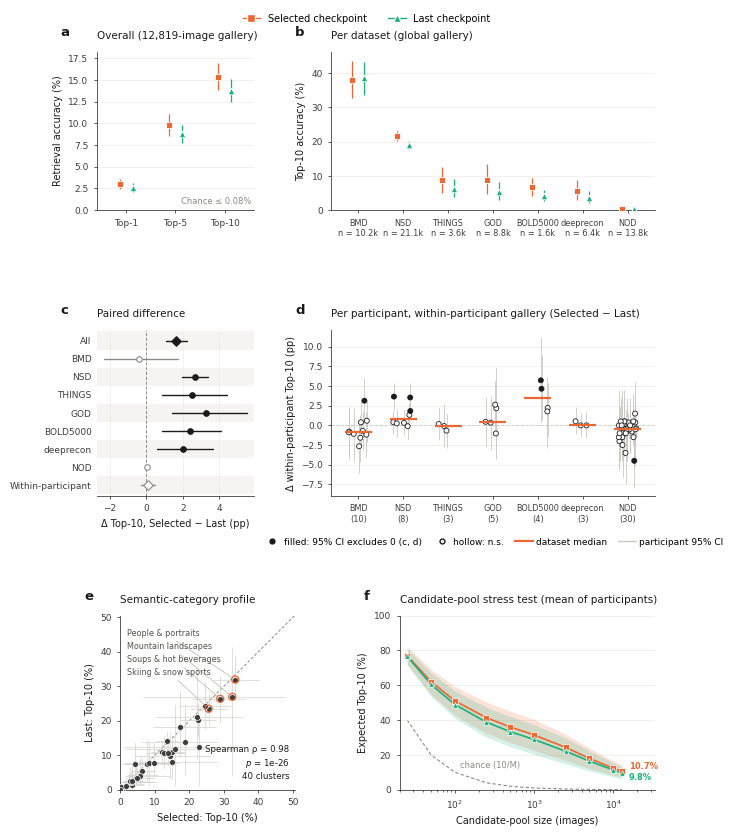

In [4]:
# ============================================================
# Fig. S3
# ============================================================

with mpl.rc_context(NATURE_RC):
    fig = plt.figure(figsize=(7.2, 9.0))
    outer = fig.add_gridspec(3, 1, hspace=0.72, height_ratios=[1, 1.05, 1.1], top=0.93)
    r1 = outer[0].subgridspec(1, 2, width_ratios=[1, 2.05], wspace=0.32)
    r2 = outer[1].subgridspec(1, 2, width_ratios=[1, 2.05], wspace=0.32)
    r3 = outer[2].subgridspec(1, 2, width_ratios=[1, 1.15], wspace=0.34)
    axA, axB = fig.add_subplot(r1[0]), fig.add_subplot(r1[1])
    axC, axD = fig.add_subplot(r2[0]), fig.add_subplot(r2[1])
    axE, axF = fig.add_subplot(r3[0]), fig.add_subplot(r3[1])

    # ---- a: overall global retrieval at Top-1/5/10 ----
    x = np.arange(len(overall_df))
    tops = checkpoint_points(axA, overall_df, x)
    axA.set_xticks(x, [f"Top-{k}" for k in overall_df.k]); axA.set_xlim(-0.6, len(x) - 0.4)
    axA.set_ylabel("Retrieval accuracy (%)"); axA.set_ylim(0, max(tops) * 1.08)
    axA.text(0.98, 0.04, f"Chance ≤ {100 * 10 / N_GAL:.2f}%", transform=axA.transAxes, ha="right", fontsize=6, color=MUTED)
    panel(axA, "a", f"Overall ({N_GAL:,}-image gallery)")

    # ---- b: per-dataset Top-10 (global gallery) ----
    x = np.arange(len(dataset_df))
    tops = checkpoint_points(axB, dataset_df, x)
    dataset_ticks(axB, dataset_df["group"], dataset_df["n_queries"])
    axB.set_xlim(-0.6, len(x) - 0.4); axB.set_ylim(0, max(tops) * 1.06)
    axB.set_ylabel("Top-10 accuracy (%)")
    panel(axB, "b", "Per dataset (global gallery)")

    # ---- c: paired differences Selected − Last ----
    y = np.arange(len(diff_rows))[::-1]
    for yi in y[::2]:
        axC.axhspan(yi - 0.5, yi + 0.5, color="#f5f4f0", zorder=0, lw=0)
    for yi, r in zip(y, diff_rows):
        d, lo, hi = (100 * r[c] for c in ["diff", "diff_lo", "diff_hi"])
        sig = r["p"] < 0.05
        is_summary = r["group"] in ("All", "Within-participant")
        axC.plot([lo, hi], [yi, yi], color=INK if sig else MUTED, lw=1.0, solid_capstyle="round", zorder=2)
        axC.scatter(d, yi, marker="D" if is_summary else "o", s=24 if is_summary else 16, zorder=3,
                    facecolor=(INK if sig else "white"), edgecolor=INK if sig else MUTED, linewidth=0.8)
    axC.axvline(0, color=MUTED, lw=0.7, ls=(0, (3, 2)), zorder=1)
    axC.set_yticks(y, [r["group"] for r in diff_rows])
    axC.set_ylim(-0.6, len(diff_rows) - 0.4)
    axC.tick_params(axis="y", length=0)
    axC.spines["left"].set_visible(False)
    axC.set_xlabel("Δ Top-10, Selected − Last (pp)")
    panel(axC, "c", "Paired difference")

    # ---- d: per-participant within-participant Δ ----
    dorder = list(dataset_df["group"])
    rng_j = np.random.default_rng(0)
    for xi, dset in enumerate(dorder):
        s = subject_df[subject_df.dataset_name == dset]
        d, lo, hi = (100 * s[c].to_numpy() for c in ["diff", "diff_lo", "diff_hi"])
        xs = xi + rng_j.uniform(-0.22, 0.22, len(s))
        sig = (lo > 0) | (hi < 0)
        axD.vlines(xs, lo, hi, color="#c9c8c2", lw=0.6, zorder=1)
        axD.scatter(xs, d, s=13, zorder=3, facecolor=np.where(sig, INK, "white"), edgecolor=INK, linewidth=0.6)
        axD.hlines(np.median(d), xi - 0.3, xi + 0.3, color=COLOR[SEL], lw=1.6, zorder=4)
    axD.axhline(0, color=MUTED, lw=0.7, ls=(0, (3, 2)), zorder=0)
    dataset_ticks(axD, dorder, [(subject_df.dataset_name == g).sum() for g in dorder], unit=None)
    axD.set_xlim(-0.6, len(dorder) - 0.4)
    axD.set_ylabel("Δ within-participant Top-10 (pp)")
    axD.legend(handles=[
        Line2D([], [], marker="o", ls="none", mfc=INK, mec=INK, ms=3.5, label="filled: 95% CI excludes 0 (c, d)"),
        Line2D([], [], marker="o", ls="none", mfc="white", mec=INK, ms=3.5, label="hollow: n.s."),
        Line2D([], [], color=COLOR[SEL], lw=1.6, label="dataset median"),
        Line2D([], [], color="#c9c8c2", lw=1.0, label="participant 95% CI")], loc="upper center", ncol=4,
        handletextpad=0.3, columnspacing=1.2, bbox_to_anchor=(0.5, -0.2))
    panel(axD, "d", "Per participant, within-participant gallery (Selected − Last)")

    # ---- e: semantic-cluster profile ----
    xs, ys = 100 * cluster_df[f"acc_{SEL}"], 100 * cluster_df[f"acc_{LAST}"]
    lim = (0, 1.06 * max(100 * cluster_df[f"hi_{SEL}"].max(), 100 * cluster_df[f"hi_{LAST}"].max()))
    axE.plot(lim, lim, color=MUTED, lw=0.7, ls=(0, (3, 2)), zorder=0)
    axE.errorbar(xs, ys, xerr=[xs - 100 * cluster_df[f"lo_{SEL}"], 100 * cluster_df[f"hi_{SEL}"] - xs],
                 yerr=[ys - 100 * cluster_df[f"lo_{LAST}"], 100 * cluster_df[f"hi_{LAST}"] - ys],
                 fmt="none", ecolor="#d3d2cc", elinewidth=0.5, zorder=1)
    axE.scatter(xs, ys, s=18, color="#3d3d3d", edgecolor="white", linewidth=0.5, zorder=3)
    top = cluster_df.sort_values(f"acc_{SEL}").tail(4).iloc[::-1]
    for j, (_, r) in enumerate(top.iterrows()):
        px, py = 100 * r[f"acc_{SEL}"], 100 * r[f"acc_{LAST}"]
        axE.scatter(px, py, s=26, facecolor="none", edgecolor=COLOR[SEL], linewidth=0.9, zorder=4)
        axE.annotate(r["group"], (px, py), xytext=(0.04 * lim[1], (0.90 - 0.075 * j) * lim[1]),
                     textcoords="data", fontsize=5.8, color="#52514e", ha="left", va="center",
                     arrowprops=dict(arrowstyle="-", color="#b5b4ae", lw=0.5, shrinkA=1, shrinkB=2.5))
    axE.set_xlim(lim); axE.set_ylim(lim); axE.set_aspect("equal")
    axE.set_xlabel("Selected: Top-10 (%)"); axE.set_ylabel("Last: Top-10 (%)")
    axE.text(0.97, 0.05, f"Spearman ρ = {rho:.2f}\n" + r"$\it{p}$" + f" = {p_rho:.0e}\n40 clusters",
             transform=axE.transAxes, va="bottom", ha="right", fontsize=6.2, color=INK, linespacing=1.3)
    panel(axE, "e", "Semantic-category profile")

    # ---- f: candidate-pool stress test ----
    for c in PAIR:
        g = pool_df[pool_df.checkpoint == c]
        axF.fill_between(g.pool, 100 * g.lo, 100 * g.hi, color=COLOR[c], alpha=0.18, lw=0, zorder=1)
        axF.plot(g.pool, 100 * g.acc, color=COLOR[c], lw=1.2, zorder=2)
        axF.scatter(g.pool, 100 * g.acc, marker=MARKER[c], s=16, color=COLOR[c], edgecolor="white", lw=0.5, zorder=3)
    pools = np.array(POOL_SIZES, float)
    axF.plot(pools, 100 * np.minimum(10 / pools, 1), color=MUTED, lw=0.8, ls=(0, (3, 2)), zorder=0)
    axF.text(pools[2] * 1.15, 100 * 10 / pools[2] + 1.5, "chance (10/M)", fontsize=6, color=MUTED, ha="left", va="bottom")
    axF.set_xscale("log"); axF.set_xlim(pools[0] * 0.8, pools[-1] * 2.6); axF.set_ylim(0, 100)
    axF.set_xlabel("Candidate-pool size (images)"); axF.set_ylabel("Expected Top-10 (%)")
    end = pool_df[pool_df.pool == N_GAL].set_index("checkpoint")["acc"]
    for c, dy in zip(PAIR, (3.5, -3.5)):
        axF.annotate(f"{100 * end[c]:.1f}%", (N_GAL, 100 * end[c]), xytext=(5, dy), textcoords="offset points",
                     fontsize=6, color=COLOR[c], ha="left", va="center", fontweight="bold")
    panel(axF, "f", "Candidate-pool stress test (mean of participants)")

    for ax in (axA, axB, axD, axF):
        ax.grid(axis="y", color=GRID, lw=0.5); ax.set_axisbelow(True)
    axC.grid(axis="x", color=GRID, lw=0.5); axC.set_axisbelow(True)

    fig.legend(handles=[Line2D([], [], marker=MARKER[c], color=COLOR[c], mec="white", ms=6, lw=1.0,
                               label=f"{c} checkpoint") for c in PAIR],
               loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.982), handlelength=1.8, columnspacing=2.2, fontsize=7)
    fig.savefig(out_dir / "supp_selected_vs_last.pdf", bbox_inches="tight")
    fig.savefig(out_dir / "supp_selected_vs_last.png", dpi=600, bbox_inches="tight")
    plt.show()